**Apply BI-LSTM on Med Dataset**

INTEL ARC GPU CONFIGURATION
PyTorch version: 2.14.1+xpu
XPU available: True
XPU device count: 1
GPU: Intel(R) Arc(TM) A750 Graphics
Selected device: xpu:0

LOADING DATASET
Raw dataset shape: (156741, 102)
Features: (156741, 96)
Number of classes: 4
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of participants: 60
Loading time: 3.62
RAM: 4897.8 MB

PERSON WISE SPLIT
Training persons: 42
Testing persons: 12
Validation persons: 6
Training rows: 109891
Testing rows: 30832
Validation rows: 16018

STANDARDIZING FEATURES

BUILDING SEQUENCES

SEQUENCE SHAPES
Train: (109513, 10, 96)
Test: (30724, 10, 96)
Validation: (15964, 10, 96)
Timesteps: 10
Input features: 96

GroupKFold folds: 5
Capped LOGO folds: 3

RUNNING OPTUNA: 10 TRIALS


Best trial: 3. Best value: 0.696894: 100%|██████████| 10/10 [18:19<00:00, 109.98s/it]



OPTUNA COMPLETED
Best GroupKFold accuracy: 0.6968935911791817
Best parameters: {'n_lstm_layers': 1, 'lstm_units': 32, 'dense_units': 128, 'dropout': 0.09242722776276352, 'recurrent_dropout': 0.38783385110582347, 'input_dropout': 0.23253984700833435, 'l2': 0.0006584106160121611, 'learning_rate': 0.00331348361550895, 'activation': 'tanh'}
Optuna execution time: 18.330575132369994 minutes

BiLSTM: FIVE RUNS

BiLSTM RUN 1/5
Fold 1: 0.7303
Fold 2: 0.6598
Fold 3: 0.6735
Fold 4: 0.7549
Fold 5: 0.6660
Epoch 1/50 | Train loss: 0.7535 | Train acc: 0.6675 | Val loss: 0.7328 | Val acc: 0.7239
Epoch 2/50 | Train loss: 0.3729 | Train acc: 0.8548 | Val loss: 0.7513 | Val acc: 0.6690
Epoch 3/50 | Train loss: 0.2798 | Train acc: 0.8928 | Val loss: 0.9143 | Val acc: 0.6672
Epoch 4/50 | Train loss: 0.2403 | Train acc: 0.9080 | Val loss: 0.8103 | Val acc: 0.7372
Epoch 5/50 | Train loss: 0.2092 | Train acc: 0.9197 | Val loss: 0.8555 | Val acc: 0.7811
Epoch 6/50 | Train loss: 0.1961 | Train acc: 0.9246 | V

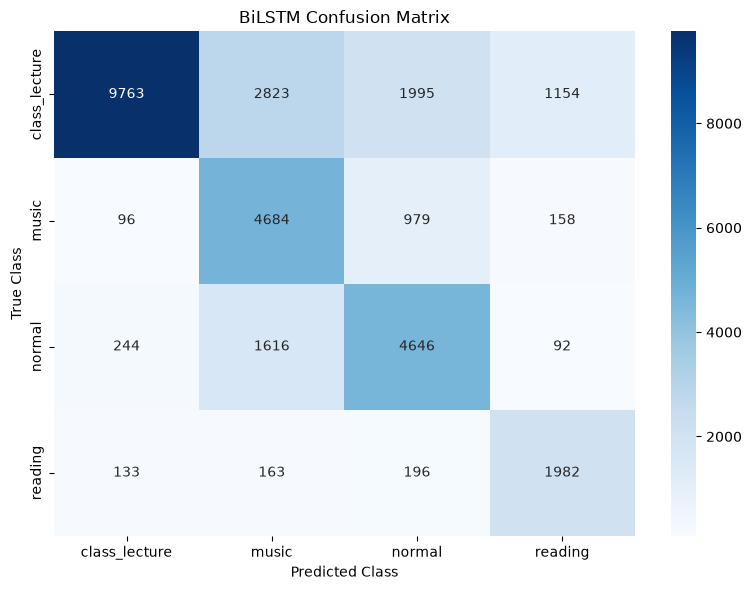

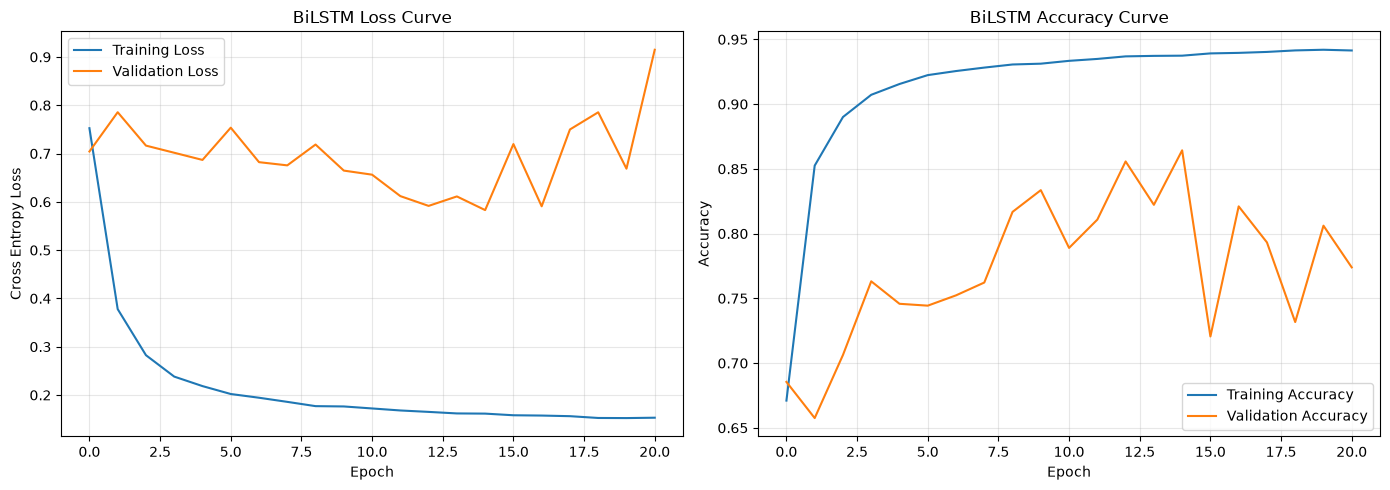


#################################################################
FINAL MODEL: BiLSTM WITH INTEL ARC A750
#################################################################
Training Accuracy    : 0.9601
Validation Accuracy  : 0.8643
Testing Accuracy     : 0.6859
GroupKFold CV        : 0.6601
Capped LOGO CV       : 0.6216
Precision            : 0.7604
Recall               : 0.6859
F1 Weighted          : 0.6966
F1 Macro             : 0.6723
Cohen Kappa          : 0.5562
MCC                  : 0.5759
ROC AUC              : 0.9062
GPU                  : Intel(R) Arc(TM) A750 Graphics
Training Time        : 13.15 minutes
Current RAM          : 5232.08 MB

BiLSTM GPU EXPERIMENT COMPLETED
#################################################################


In [2]:

# ================================================================
# BiLSTM WITH INTEL ARC A750 GPU
# PYTORCH XPU
# FULL DATASET, PERSON WISE 70/20/10
# OPTUNA, 5 RUNS, GROUPKFOLD, CAPPED LOGO, ALL ORIGINAL METRICS
# ================================================================

import os
import gc
import time
import json
import copy
import random
import warnings
from pathlib import Path

import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

import torch
import torch.nn as nn

from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ================================================================
# 0. CONFIGURATION
# ================================================================

FILE_PATH = (
    "/home/rakib/Desktop/ml_apply/"
    "Cleaned_oN_Selected_Med.csv"
)

OUTPUT_DIR = Path(
    "/home/rakib/Desktop/ml_apply"
)

N_TRIALS = 10
N_RUNS = 5
LOGO_MAX_FOLDS = 3

BILSTM_EPOCHS = 50
BILSTM_BATCH = 1024
BILSTM_PATIENCE = 6

SEQ_STRATEGY = "window_seq"
SEQ_LEN = 10
SEQ_STRIDE = 1

SEED = 42

PROC = psutil.Process(os.getpid())


def mem_mb():
    return PROC.memory_info().rss / 1024 / 1024


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)

# ================================================================
# 1. INTEL ARC GPU DETECTION
# ================================================================

print("=" * 65)
print("INTEL ARC GPU CONFIGURATION")
print("=" * 65)

print("PyTorch version:", torch.__version__)

if not hasattr(torch, "xpu") or not torch.xpu.is_available():
    raise RuntimeError(
        "Intel XPU GPU is not available. "
        "Check the PyTorch XPU installation."
    )

DEVICE = torch.device("xpu:0")

print("XPU available:", torch.xpu.is_available())
print("XPU device count:", torch.xpu.device_count())
print("GPU:", torch.xpu.get_device_name(0))
print("Selected device:", DEVICE)

print("=" * 65)


def synchronize():
    torch.xpu.synchronize()


# ================================================================
# 2. LOAD COMPLETE DATASET
# ================================================================

print("\nLOADING DATASET")

load_start = time.time()

df = pd.read_csv(FILE_PATH, low_memory=False)

print("Raw dataset shape:", df.shape)

metadata_cols = [
    "PersonSrial",
    "Window",
    "Window_Start",
    "Window_End",
    "Window_Samples"
]

target_col = "Class"

feature_cols = [
    column
    for column in df.columns
    if column not in metadata_cols
    and column != target_col
]

required_cols = ["PersonSrial", "Window", "Class"]

for column in required_cols:
    if column not in df.columns:
        raise ValueError(f"Missing column: {column}")

meta_df = df[
    ["PersonSrial", "Window", target_col]
].copy()

if meta_df.isna().any().any():
    raise ValueError(
        "Participant, window, or class metadata contains missing values."
    )

meta_df["Window"] = pd.to_numeric(
    meta_df["Window"],
    errors="raise"
)

le = LabelEncoder()

y_all = le.fit_transform(
    df[target_col].values
).astype(np.int64)

num_classes = len(le.classes_)

groups_all = df["PersonSrial"].to_numpy()

X_all = df[feature_cols].to_numpy(
    dtype=np.float32,
    copy=True
)

if not np.isfinite(X_all).all():
    raise ValueError(
        "Feature matrix contains NaN or infinite values. "
        "Clean the feature matrix before running the BiLSTM."
    )

del df
gc.collect()

print("Features:", X_all.shape)
print("Number of classes:", num_classes)
print("Classes:", list(le.classes_))
print("Number of participants:", len(np.unique(groups_all)))
print("Loading time:", round(time.time() - load_start, 2))
print("RAM:", round(mem_mb(), 2), "MB")

# ================================================================
# 3. PERSON WISE SPLIT 70/20/10
# ================================================================

persons = np.unique(groups_all)

rng = np.random.RandomState(SEED)
rng.shuffle(persons)

n_persons = len(persons)

n_test = max(1, int(round(0.20 * n_persons)))
n_cv = max(1, int(round(0.10 * n_persons)))

test_persons = persons[:n_test]

cv_persons = persons[
    n_test:n_test + n_cv
]

train_persons = persons[
    n_test + n_cv:
]

if len(train_persons) < 5:
    raise ValueError(
        "At least five training participants are required."
    )

tr_mask = np.isin(groups_all, train_persons)
te_mask = np.isin(groups_all, test_persons)
cv_mask = np.isin(groups_all, cv_persons)

assert not np.intersect1d(
    train_persons, test_persons
).size

assert not np.intersect1d(
    train_persons, cv_persons
).size

assert not np.intersect1d(
    cv_persons, test_persons
).size

print("\nPERSON WISE SPLIT")
print("Training persons:", len(train_persons))
print("Testing persons:", len(test_persons))
print("Validation persons:", len(cv_persons))

print("Training rows:", tr_mask.sum())
print("Testing rows:", te_mask.sum())
print("Validation rows:", cv_mask.sum())

# ================================================================
# 4. STANDARDIZATION
# FIT SCALER ON TRAINING PARTICIPANTS ONLY
# ================================================================

print("\nSTANDARDIZING FEATURES")

scaler = StandardScaler()

scaler.fit(X_all[tr_mask])

X_all = scaler.transform(
    X_all
).astype(np.float32)

# ================================================================
# 5. BUILD SEQUENCES
# ================================================================

def build_sequences(
    X,
    y,
    meta,
    strategy="window_seq",
    seq_len=SEQ_LEN,
    stride=SEQ_STRIDE
):
    """
    Returns:
        Xseq: (samples, timesteps, features)
        yseq: integer labels
        gseq: participant identifiers
    """

    if strategy == "feature_steps":
        Xseq = X.reshape(
            X.shape[0],
            X.shape[1],
            1
        )

        return (
            Xseq,
            y,
            meta["PersonSrial"].to_numpy()
        )

    meta = meta.reset_index(drop=True)

    Xseq_list = []
    yseq_list = []
    gseq_list = []

    participant_values = meta[
        "PersonSrial"
    ].to_numpy()

    window_values = meta[
        "Window"
    ].to_numpy()

    for pid in np.unique(participant_values):

        participant_indices = np.where(
            participant_values == pid
        )[0]

        order = np.argsort(
            window_values[participant_indices],
            kind="stable"
        )

        indices = participant_indices[order]

        if len(indices) < seq_len:
            continue

        for start in range(
            0,
            len(indices) - seq_len + 1,
            stride
        ):

            selected = indices[
                start:start + seq_len
            ]

            Xseq_list.append(X[selected])

            sequence_label = np.bincount(
                y[selected],
                minlength=num_classes
            ).argmax()

            yseq_list.append(sequence_label)
            gseq_list.append(pid)

    if not Xseq_list:
        raise RuntimeError(
            "No sequences generated. "
            "Check the Window column or SEQ_LEN."
        )

    return (
        np.stack(Xseq_list).astype(np.float32),
        np.asarray(yseq_list, dtype=np.int64),
        np.asarray(gseq_list)
    )


print("\nBUILDING SEQUENCES")

meta_tr = meta_df.loc[tr_mask].reset_index(drop=True)
meta_te = meta_df.loc[te_mask].reset_index(drop=True)
meta_cv = meta_df.loc[cv_mask].reset_index(drop=True)

X_train_seq, y_train_seq, g_train_seq = build_sequences(
    X_all[tr_mask],
    y_all[tr_mask],
    meta_tr,
    SEQ_STRATEGY
)

X_test_seq, y_test_seq, g_test_seq = build_sequences(
    X_all[te_mask],
    y_all[te_mask],
    meta_te,
    SEQ_STRATEGY
)

X_cv_seq, y_cv_seq, g_cv_seq = build_sequences(
    X_all[cv_mask],
    y_all[cv_mask],
    meta_cv,
    SEQ_STRATEGY
)

del X_all, meta_tr, meta_te, meta_cv
gc.collect()

print("\nSEQUENCE SHAPES")

print("Train:", X_train_seq.shape)
print("Test:", X_test_seq.shape)
print("Validation:", X_cv_seq.shape)

T = X_train_seq.shape[1]
D = X_train_seq.shape[2]

print("Timesteps:", T)
print("Input features:", D)

# ================================================================
# 6. GROUPKFOLD AND LOGO SPLITS
# ================================================================

gkf_splits = list(
    GroupKFold(n_splits=5).split(
        X_train_seq,
        y_train_seq,
        g_train_seq
    )
)

logo_splits = list(
    LeaveOneGroupOut().split(
        X_train_seq,
        y_train_seq,
        g_train_seq
    )
)

logo_splits = logo_splits[:LOGO_MAX_FOLDS]

print("\nGroupKFold folds:", len(gkf_splits))
print("Capped LOGO folds:", len(logo_splits))

# ================================================================
# 7. GPU DATA MANAGEMENT
# ================================================================

def gpu_tensor(X, dtype=torch.float32):
    return torch.as_tensor(
        X,
        dtype=dtype
    ).to(DEVICE)


def batch_indices(n_samples, shuffle=True):
    if shuffle:
        indices = torch.randperm(n_samples, device=DEVICE)
    else:
        indices = torch.arange(n_samples, device=DEVICE)

    for start in range(
        0,
        n_samples,
        BILSTM_BATCH
    ):
        yield indices[start:start + BILSTM_BATCH]


class GPUData:

    def __init__(self, X, y):
        self.X = gpu_tensor(X)
        self.y = gpu_tensor(y, torch.long)

    def __len__(self):
        return self.y.shape[0]


# ================================================================
# 8. PYTORCH BIDIRECTIONAL LSTM
# ================================================================

class BiLSTM(nn.Module):

    def __init__(self, params, input_size, num_classes):
        super().__init__()

        self.input_dropout = nn.Dropout(
            params["input_dropout"]
        )

        self.lstm_layers = nn.ModuleList()
        self.layer_dropouts = nn.ModuleList()

        current_size = input_size

        for _ in range(params["n_lstm_layers"]):

            self.lstm_layers.append(
                nn.LSTM(
                    input_size=current_size,
                    hidden_size=params["lstm_units"],
                    num_layers=1,
                    batch_first=True,
                    bidirectional=True
                )
            )

            self.layer_dropouts.append(
                nn.Dropout(
                    params["recurrent_dropout"]
                )
            )

            current_size = params["lstm_units"] * 2

        self.dropout = nn.Dropout(
            params["dropout"]
        )

        if params["dense_units"] > 0:

            self.dense = nn.Linear(
                current_size,
                params["dense_units"]
            )

            if params["activation"] == "relu":
                self.activation = nn.ReLU()
            else:
                self.activation = nn.Tanh()

            output_size = params["dense_units"]

        else:
            self.dense = None
            self.activation = None
            output_size = current_size

        self.classifier = nn.Linear(
            output_size,
            num_classes
        )

    def forward(self, x):

        x = self.input_dropout(x)

        for lstm, layer_dropout in zip(
            self.lstm_layers,
            self.layer_dropouts
        ):
            x = layer_dropout(x)
            x, (hidden, cell) = lstm(x)
            x = self.dropout(x)

        # Final forward and backward hidden states.
        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        x = torch.cat(
            [forward_hidden, backward_hidden],
            dim=1
        )

        if self.dense is not None:
            x = self.dense(x)
            x = self.activation(x)
            x = self.dropout(x)

        logits = self.classifier(x)

        return logits


def build_bilstm(params, seed=42):

    set_seed(seed)

    model = BiLSTM(
        params,
        input_size=D,
        num_classes=num_classes
    )

    return model.to(DEVICE)


# ================================================================
# 9. CLASS WEIGHTS
# ================================================================

def class_weight_tensor(y):

    classes = np.unique(y)

    values = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y
    )

    weights = np.zeros(
        num_classes,
        dtype=np.float32
    )

    weights[classes] = values

    return gpu_tensor(
        weights,
        torch.float32
    )


# ================================================================
# 10. TRAIN AND EVALUATE
# ================================================================

def train_one_epoch(
    model,
    data,
    optimizer,
    criterion
):
    model.train()

    total_loss = torch.zeros((), device=DEVICE)
    total_correct = torch.zeros((), device=DEVICE)

    for indices in batch_indices(
        len(data),
        shuffle=True
    ):
        X_batch = data.X[indices]
        y_batch = data.y[indices]

        optimizer.zero_grad(set_to_none=True)

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.detach() * len(indices)

        total_correct += (
            outputs.argmax(dim=1) == y_batch
        ).sum()

    synchronize()

    n = len(data)

    return (
        total_loss.item() / n,
        total_correct.item() / n
    )


@torch.no_grad()
def evaluate_model(
    model,
    data,
    criterion=None,
    return_probabilities=False
):
    model.eval()

    total_loss = torch.zeros((), device=DEVICE)
    total_correct = torch.zeros((), device=DEVICE)

    probability_list = []

    for indices in batch_indices(
        len(data),
        shuffle=False
    ):

        X_batch = data.X[indices]
        y_batch = data.y[indices]

        outputs = model(X_batch)

        if criterion is not None:
            loss = criterion(outputs, y_batch)
            total_loss += loss * len(indices)

        total_correct += (
            outputs.argmax(dim=1) == y_batch
        ).sum()

        if return_probabilities:
            probability_list.append(
                torch.softmax(outputs, dim=1)
            )

    synchronize()

    accuracy = total_correct.item() / len(data)

    if criterion is not None:
        loss_value = total_loss.item() / len(data)
    else:
        loss_value = float("nan")

    if return_probabilities:
        probabilities = (
            torch.cat(probability_list, dim=0)
            .cpu()
            .numpy()
        )

        return loss_value, accuracy, probabilities

    return loss_value, accuracy


# ================================================================
# 11. BiLSTM FITTING WITH EARLY STOPPING
# ================================================================

def fit_bilstm(
    params,
    X_tr,
    y_tr,
    X_va=None,
    y_va=None,
    seed=42,
    epochs=BILSTM_EPOCHS,
    verbose=0
):
    model = build_bilstm(
        params,
        seed=seed
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=params["learning_rate"],
        weight_decay=params["l2"]
    )

    weights = class_weight_tensor(y_tr)

    criterion = nn.CrossEntropyLoss(
        weight=weights
    )

    train_data = GPUData(
        X_tr,
        y_tr
    )

    if X_va is not None:
        validation_data = GPUData(
            X_va,
            y_va
        )
    else:
        validation_data = None

    history = {
        "loss": [],
        "accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_data,
            optimizer,
            criterion
        )

        if validation_data is not None:

            val_loss, val_accuracy = evaluate_model(
                model,
                validation_data,
                criterion
            )

            monitored_loss = val_loss

        else:

            val_loss = float("nan")
            val_accuracy = float("nan")

            monitored_loss = train_loss

        history["loss"].append(train_loss)
        history["accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        if monitored_loss < best_loss - 1e-5:

            best_loss = monitored_loss

            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }

            patience_counter = 0

        else:
            patience_counter += 1

        if verbose:

            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"Train loss: {train_loss:.4f} | "
                f"Train acc: {train_accuracy:.4f} | "
                f"Val loss: {val_loss:.4f} | "
                f"Val acc: {val_accuracy:.4f}"
            )

        if patience_counter >= BILSTM_PATIENCE:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    del train_data

    if validation_data is not None:
        del validation_data

    del optimizer, criterion

    gc.collect()
    torch.xpu.empty_cache()

    return model, history


def predict_probabilities(model, X, y):

    data = GPUData(X, y)

    _, _, probabilities = evaluate_model(
        model,
        data,
        return_probabilities=True
    )

    del data

    return probabilities


def release_model(model):
    del model
    gc.collect()
    torch.xpu.empty_cache()


# ================================================================
# 12. OPTUNA OBJECTIVE
# ================================================================

def bilstm_objective(trial):

    params = {
        "n_lstm_layers": trial.suggest_int(
            "n_lstm_layers", 1, 2
        ),

        "lstm_units": trial.suggest_categorical(
            "lstm_units", [32, 64, 128]
        ),

        "dense_units": trial.suggest_categorical(
            "dense_units", [0, 64, 128]
        ),

        "dropout": trial.suggest_float(
            "dropout", 0.0, 0.5
        ),

        "recurrent_dropout": trial.suggest_float(
            "recurrent_dropout", 0.0, 0.4
        ),

        "input_dropout": trial.suggest_float(
            "input_dropout", 0.0, 0.3
        ),

        "l2": trial.suggest_float(
            "l2", 1e-6, 1e-3, log=True
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 5e-3, log=True
        ),

        "activation": trial.suggest_categorical(
            "activation", ["relu", "tanh"]
        )
    }

    scores = []

    for fold_number, (tr_i, va_i) in enumerate(
        gkf_splits,
        start=1
    ):

        model, history = fit_bilstm(
            params,
            X_train_seq[tr_i],
            y_train_seq[tr_i],
            X_train_seq[va_i],
            y_train_seq[va_i],
            seed=SEED,
            epochs=BILSTM_EPOCHS
        )

        probabilities = predict_probabilities(
            model,
            X_train_seq[va_i],
            y_train_seq[va_i]
        )

        predictions = probabilities.argmax(axis=1)

        score = accuracy_score(
            y_train_seq[va_i],
            predictions
        )

        scores.append(score)

        release_model(model)

        trial.report(
            float(np.mean(scores)),
            fold_number
        )

        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(scores))


# ================================================================
# 13. RUN OPTUNA
# ================================================================

print(
    f"\nRUNNING OPTUNA: {N_TRIALS} TRIALS"
)

optuna_start = time.time()

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=SEED
    )
)

study.optimize(
    bilstm_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

optuna_time = time.time() - optuna_start

best_params = study.best_params

print("\nOPTUNA COMPLETED")
print("Best GroupKFold accuracy:", study.best_value)
print("Best parameters:", best_params)
print("Optuna execution time:", optuna_time / 60, "minutes")

with open(
    OUTPUT_DIR / "bilstm_best_params.json",
    "w"
) as file:
    json.dump(
        best_params,
        file,
        indent=4
    )


# ================================================================
# 14. FIVE RUNS
# BEST RUN SELECTED BY VALIDATION ACCURACY
# ================================================================

def run_bilstm(params, n_runs=5):

    records = []

    best_bundle = None
    best_validation_accuracy = -1.0

    for run in range(n_runs):

        run_start = time.time()

        seed = SEED + run

        print(f"\nBiLSTM RUN {run + 1}/{n_runs}")

        cv_accuracies = []

        for fold_number, (tr_i, va_i) in enumerate(
            gkf_splits,
            start=1
        ):

            model, history = fit_bilstm(
                params,
                X_train_seq[tr_i],
                y_train_seq[tr_i],
                X_train_seq[va_i],
                y_train_seq[va_i],
                seed=seed
            )

            probabilities = predict_probabilities(
                model,
                X_train_seq[va_i],
                y_train_seq[va_i]
            )

            prediction = probabilities.argmax(axis=1)

            fold_accuracy = accuracy_score(
                y_train_seq[va_i],
                prediction
            )

            cv_accuracies.append(fold_accuracy)

            print(
                f"Fold {fold_number}: "
                f"{fold_accuracy:.4f}"
            )

            release_model(model)

        # Final training for this run uses the training group.
        # The separate 10 percent validation group controls
        # early stopping and best run selection.

        model, history = fit_bilstm(
            params,
            X_train_seq,
            y_train_seq,
            X_cv_seq,
            y_cv_seq,
            seed=seed,
            verbose=1
        )

        train_probability = predict_probabilities(
            model,
            X_train_seq,
            y_train_seq
        )

        validation_probability = predict_probabilities(
            model,
            X_cv_seq,
            y_cv_seq
        )

        train_prediction = train_probability.argmax(axis=1)
        validation_prediction = validation_probability.argmax(axis=1)

        train_accuracy = accuracy_score(
            y_train_seq,
            train_prediction
        )

        validation_accuracy = accuracy_score(
            y_cv_seq,
            validation_prediction
        )

        run_time = time.time() - run_start

        record = {
            "run": run + 1,
            "train_acc": train_accuracy,
            "validation_acc": validation_accuracy,
            "cv_acc": float(np.mean(cv_accuracies)),
            "cv_std": float(np.std(cv_accuracies)),
            "epochs_run": len(history["loss"]),
            "exec_time_sec": run_time
        }

        records.append(record)

        print(
            f"\nRUN {run + 1} | "
            f"Train: {train_accuracy:.4f} | "
            f"Validation: {validation_accuracy:.4f} | "
            f"CV: {record['cv_acc']:.4f} | "
            f"Time: {run_time / 60:.2f} minutes"
        )

        if validation_accuracy > best_validation_accuracy:

            best_validation_accuracy = validation_accuracy

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            best_bundle = {
                "record": record.copy(),
                "model_state": best_state,
                "history": copy.deepcopy(history)
            }

        release_model(model)

    return records, best_bundle


print("\n" + "=" * 65)
print("BiLSTM: FIVE RUNS")
print("=" * 65)

training_start = time.time()
memory_before = mem_mb()

bilstm_records, best_bundle = run_bilstm(
    best_params,
    N_RUNS
)

training_time = time.time() - training_start
memory_difference = mem_mb() - memory_before

print("\nFIVE RUN RESULTS")

print(
    pd.DataFrame(bilstm_records)
    .round(4)
    .to_string(index=False)
)

best_record = best_bundle["record"]
best_history = best_bundle["history"]

best_model = build_bilstm(
    best_params,
    seed=SEED
)

best_model.load_state_dict(
    best_bundle["model_state"]
)

best_model.eval()

print("\nSELECTED RUN:", best_record["run"])
print(
    "Selection validation accuracy:",
    best_record["validation_acc"]
)

# ================================================================
# 15. CAPPED LEAVE ONE GROUP OUT CV
# ================================================================

def logo_cv(params, splits, seed=42):

    accuracies = []

    for fold_number, (tr_i, va_i) in enumerate(
        splits,
        start=1
    ):

        model, history = fit_bilstm(
            params,
            X_train_seq[tr_i],
            y_train_seq[tr_i],
            X_train_seq[va_i],
            y_train_seq[va_i],
            seed=seed
        )

        probabilities = predict_probabilities(
            model,
            X_train_seq[va_i],
            y_train_seq[va_i]
        )

        predictions = probabilities.argmax(axis=1)

        accuracy = accuracy_score(
            y_train_seq[va_i],
            predictions
        )

        accuracies.append(accuracy)

        print(
            f"LOGO Fold {fold_number}/{len(splits)}: "
            f"{accuracy:.4f}"
        )

        release_model(model)

    return (
        float(np.mean(accuracies)),
        float(np.std(accuracies))
    )


print("\nRUNNING CAPPED LOGO CV")

logo_start = time.time()

logo_mean, logo_std = logo_cv(
    best_params,
    logo_splits,
    seed=SEED
)

logo_time = time.time() - logo_start

print(
    f"LOGO CV: {logo_mean:.4f} ± {logo_std:.4f}"
)

print(
    f"LOGO execution time: {logo_time / 60:.2f} minutes"
)

# ================================================================
# 16. FINAL UNTOUCHED TEST EVALUATION
# ================================================================

print("\nFINAL TEST EVALUATION")

test_start = time.time()

test_probabilities = predict_probabilities(
    best_model,
    X_test_seq,
    y_test_seq
)

test_predictions = test_probabilities.argmax(axis=1)

synchronize()

test_prediction_time = time.time() - test_start

test_accuracy = accuracy_score(
    y_test_seq,
    test_predictions
)

test_precision = precision_score(
    y_test_seq,
    test_predictions,
    average="weighted",
    zero_division=0
)

test_recall = recall_score(
    y_test_seq,
    test_predictions,
    average="weighted",
    zero_division=0
)

test_f1_weighted = f1_score(
    y_test_seq,
    test_predictions,
    average="weighted",
    zero_division=0
)

test_f1_macro = f1_score(
    y_test_seq,
    test_predictions,
    average="macro",
    zero_division=0
)

test_kappa = cohen_kappa_score(
    y_test_seq,
    test_predictions
)

test_mcc = matthews_corrcoef(
    y_test_seq,
    test_predictions
)

try:
    test_roc_auc = roc_auc_score(
        y_test_seq,
        test_probabilities,
        multi_class="ovr",
        average="weighted"
    )
except ValueError:
    test_roc_auc = np.nan

# ================================================================
# 17. FULL REPORT
# ================================================================

print("\n" + "=" * 65)
print("FINAL BiLSTM RESULTS")
print("=" * 65)

print(f"GPU                    : {torch.xpu.get_device_name(0)}")
print(f"Best run               : {best_record['run']}")
print(f"Training accuracy      : {best_record['train_acc']:.4f}")
print(f"Validation accuracy    : {best_record['validation_acc']:.4f}")
print(f"Testing accuracy       : {test_accuracy:.4f}")

print(
    f"GroupKFold 5 CV        : "
    f"{best_record['cv_acc']:.4f} ± "
    f"{best_record['cv_std']:.4f}"
)

print(
    f"Capped LOGO CV         : "
    f"{logo_mean:.4f} ± {logo_std:.4f}"
)

print(f"Precision weighted     : {test_precision:.4f}")
print(f"Recall weighted        : {test_recall:.4f}")
print(f"F1 weighted            : {test_f1_weighted:.4f}")
print(f"F1 macro               : {test_f1_macro:.4f}")
print(f"Cohen Kappa            : {test_kappa:.4f}")
print(f"MCC                    : {test_mcc:.4f}")
print(f"ROC AUC weighted       : {test_roc_auc:.4f}")

print(f"Epochs                 : {best_record['epochs_run']}")
print(f"Sequence strategy      : {SEQ_STRATEGY}")
print(f"Timesteps              : {T}")
print(f"Features               : {D}")

print(f"Optuna time            : {optuna_time / 60:.2f} minutes")
print(f"Five run training time : {training_time / 60:.2f} minutes")
print(f"LOGO time              : {logo_time / 60:.2f} minutes")
print(f"Prediction time        : {test_prediction_time:.2f} seconds")

print(f"Additional RAM         : {memory_difference:.2f} MB")
print(f"Current RAM            : {mem_mb():.2f} MB")

print("\nBEST HYPERPARAMETERS")

for key, value in best_params.items():
    print(f"{key}: {value}")

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test_seq,
        test_predictions,
        labels=np.arange(num_classes),
        target_names=le.classes_,
        digits=4,
        zero_division=0
    )
)

# ================================================================
# 18. CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(
    y_test_seq,
    test_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("BiLSTM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "bilstm_confusion_matrix.png",
    dpi=300
)

plt.show()

# ================================================================
# 19. TRAINING CURVES
# ================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    best_history["loss"],
    label="Training Loss"
)

axes[0].plot(
    best_history["val_loss"],
    label="Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross Entropy Loss")
axes[0].set_title("BiLSTM Loss Curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    best_history["accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    best_history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("BiLSTM Accuracy Curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "bilstm_training_curves.png",
    dpi=300
)

plt.show()

# ================================================================
# 20. SAVE BEST MODEL
# ================================================================

torch.save(
    {
        "model_state_dict": best_bundle["model_state"],
        "best_params": best_params,
        "class_names": list(le.classes_),
        "feature_names": feature_cols,
        "sequence_length": T,
        "input_features": D,
        "sequence_strategy": SEQ_STRATEGY,
        "scaler_mean": scaler.mean_,
        "scaler_scale": scaler.scale_
    },
    OUTPUT_DIR / "bilstm_best_model.pt"
)

# ================================================================
# 21. FINAL SUMMARY
# ================================================================

print("\n" + "#" * 65)
print("FINAL MODEL: BiLSTM WITH INTEL ARC A750")
print("#" * 65)

print(f"Training Accuracy    : {best_record['train_acc']:.4f}")
print(f"Validation Accuracy  : {best_record['validation_acc']:.4f}")
print(f"Testing Accuracy     : {test_accuracy:.4f}")
print(f"GroupKFold CV        : {best_record['cv_acc']:.4f}")
print(f"Capped LOGO CV       : {logo_mean:.4f}")
print(f"Precision            : {test_precision:.4f}")
print(f"Recall               : {test_recall:.4f}")
print(f"F1 Weighted          : {test_f1_weighted:.4f}")
print(f"F1 Macro             : {test_f1_macro:.4f}")
print(f"Cohen Kappa          : {test_kappa:.4f}")
print(f"MCC                  : {test_mcc:.4f}")
print(f"ROC AUC              : {test_roc_auc:.4f}")

print(f"GPU                  : {torch.xpu.get_device_name(0)}")
print(f"Training Time        : {training_time / 60:.2f} minutes")
print(f"Current RAM          : {mem_mb():.2f} MB")

print("\nBiLSTM GPU EXPERIMENT COMPLETED")
print("#" * 65)


**Apply SVM (RBF Kernel) on Med Dataset**

/home/rakib/Desktop/ml_apply/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SVM RBF CLASSIFICATION
SVM backend: Intel Extension for Scikit Learn
Kernel: RBF
Optuna trials: 10
GroupKFold folds: 5
Final runs: 5
LOGO fold cap: NONE
Data subsampling: NONE

LOADING COMPLETE DATASET
Raw dataset shape: (156741, 102)
Feature columns: 96
Invalid feature cells: 0

Feature matrix: (156741, 96)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60
Loading time: 3.63 seconds
Current RAM: 435.38 MB

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Testing participants: 12
Validation participants: 6

Training rows: 109891
Testing rows: 30832
Validation rows: 16018

Raw training matrix: (109891, 96)
Raw validation matrix: (16018, 96)
Raw testing matrix: (30832, 96)

GroupKFold folds: 5
FULL LOGO folds: 42
Expected one fold per training participant.

RUNNING OPTUNA: 10 TRIALS
EVERY TRIAL USES ALL 5 GROUPKFOLD FOLDS

Trial 1/10
C = 0.74593433
Gamma = 0.56698495
Trial 1, Fold 1/5, Accuracy = 0.4868, Time = 0.26 min
Trial 1, Fold 2

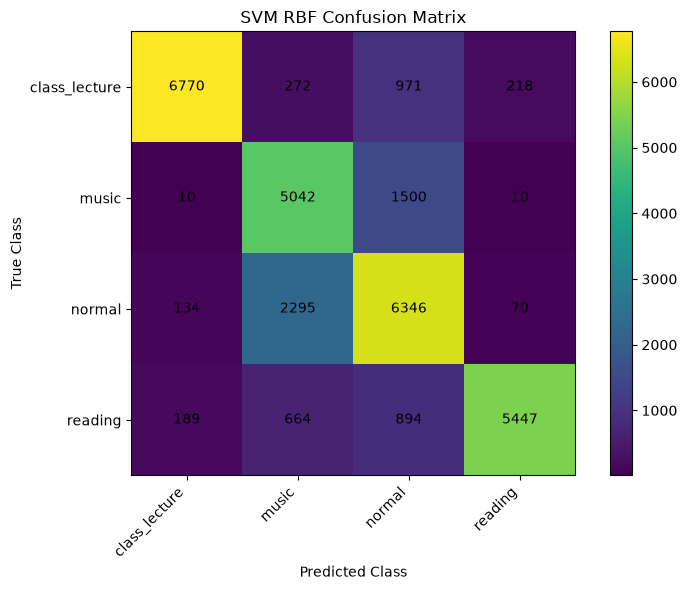


######################################################################
FINAL SVM RBF RESULTS
######################################################################
Backend                 : Intel Extension for Scikit Learn
Kernel                  : RBF
Best C                  : 1.4445251022763053
Best Gamma              : 0.0002858549394196192

Optuna GroupKFold       : 0.7702
Training Accuracy       : 0.8637
Validation Accuracy     : 0.7927
Testing Accuracy        : 0.7656
Full LOGO Accuracy      : 0.7556 ± 0.1930
Full LOGO Folds         : 42

Precision Weighted      : 0.7929
Recall Weighted         : 0.7656
F1 Weighted             : 0.7731
F1 Macro                : 0.7722
Cohen Kappa             : 0.6864
MCC                     : 0.6899

Optuna Time             : 8.92 minutes
Five Run Time           : 1.84 minutes
Full LOGO Time          : 7.32 minutes
Total Execution Time    : 18.20 minutes
Current RAM             : 1168.30 MB

No LOGO folds were capped.
No dataset rows were subsam

In [1]:
# ================================================================
# SVM RBF KERNEL
# FULL DATASET
# PERSON WISE 70 / 20 / 10
# OPTUNA HYPERPARAMETER OPTIMIZATION
# GROUPKFOLD 5
# FIVE FINAL RUNS
# FULL LEAVE ONE GROUP OUT
# NO FOLD CAP
# NO DATA SUBSAMPLING
# ================================================================

import os
import gc
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# ================================================================
# SVM BACKEND
# ================================================================

try:
    from sklearnex.svm import SVC

    SVM_BACKEND = (
        "Intel Extension for Scikit Learn"
    )

except ImportError:

    from sklearn.svm import SVC

    SVM_BACKEND = (
        "Standard Scikit Learn"
    )


# ================================================================
# GLOBAL SETTINGS
# ================================================================

warnings.filterwarnings("ignore")

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# FILE PATH
# ================================================================

FILE_PATH = (
    "/home/rakib/Desktop/ml_apply/"
    "Cleaned_oN_Selected_Med.csv"
)

OUTPUT_DIR = Path(
    "/home/rakib/Desktop/ml_apply/"
    "SVM_RBF_Results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ================================================================
# EXPERIMENT SETTINGS
# ================================================================

N_TRIALS = 10

N_RUNS = 5

GROUP_K_FOLDS = 5

SVM_CACHE_MB = 1024


# ================================================================
# INITIAL INFORMATION
# ================================================================

print("=" * 70)
print("SVM RBF CLASSIFICATION")
print("=" * 70)

print(
    "SVM backend:",
    SVM_BACKEND
)

print(
    "Kernel: RBF"
)

print(
    "Optuna trials:",
    N_TRIALS
)

print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)

print(
    "Final runs:",
    N_RUNS
)

print(
    "LOGO fold cap: NONE"
)

print(
    "Data subsampling: NONE"
)

print("=" * 70)


TOTAL_START = time.time()


# ================================================================
# LOAD COMPLETE DATASET
# ================================================================

print()
print("=" * 70)
print("LOADING COMPLETE DATASET")
print("=" * 70)

load_start = time.time()

df = pd.read_csv(
    FILE_PATH,
    low_memory=False
)

print(
    "Raw dataset shape:",
    df.shape
)


# ================================================================
# COLUMN DEFINITIONS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]

target_col = "Class"


# ================================================================
# CHECK REQUIRED COLUMNS
# ================================================================

required_columns = [

    "PersonSrial",

    target_col

]

for column in required_columns:

    if column not in df.columns:

        raise ValueError(
            f"Required column missing: "
            f"{column}"
        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]

print(
    "Feature columns:",
    len(feature_cols)
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(
        pd.to_numeric,
        errors="coerce"
    )

    .to_numpy(
        dtype=np.float32
    )

)


# ================================================================
# CHECK INVALID VALUES
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)

print(
    "Invalid feature cells:",
    invalid_count
)

if invalid_count > 0:

    raise ValueError(

        "Dataset contains NaN or "
        "infinite feature values."

    )


# ================================================================
# LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()

y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(
    np.int32
)


class_names = list(
    label_encoder.classes_
)

NUMBER_CLASSES = len(
    class_names
)


# ================================================================
# PARTICIPANT GROUPS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]
    .to_numpy()

)


print()
print(
    "Feature matrix:",
    X_all.shape
)

print(
    "Classes:",
    class_names
)

print(
    "Number of classes:",
    NUMBER_CLASSES
)

print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)

print(
    "Loading time:",
    f"{time.time() - load_start:.2f}",
    "seconds"
)

print(
    "Current RAM:",
    f"{mem_mb():.2f}",
    "MB"
)


del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10 SPLIT
# ================================================================

print()
print("=" * 70)
print("PERSON WISE 70 / 20 / 10 SPLIT")
print("=" * 70)


persons = np.unique(
    groups_all
)


rng = np.random.RandomState(
    SEED
)

rng.shuffle(
    persons
)


n_persons = len(
    persons
)


n_test = max(

    1,

    int(
        round(
            0.20
            * n_persons
        )
    )

)


n_validation = max(

    1,

    int(
        round(
            0.10
            * n_persons
        )
    )

)


test_persons = persons[
    :n_test
]


validation_persons = persons[

    n_test:
    n_test + n_validation

]


train_persons = persons[
    n_test + n_validation:
]


# ================================================================
# SPLIT MASKS
# ================================================================

train_mask = np.isin(
    groups_all,
    train_persons
)


validation_mask = np.isin(
    groups_all,
    validation_persons
)


test_mask = np.isin(
    groups_all,
    test_persons
)


# ================================================================
# VERIFY NO PARTICIPANT OVERLAP
# ================================================================

assert (
    np.intersect1d(
        train_persons,
        validation_persons
    ).size
    == 0
)


assert (
    np.intersect1d(
        train_persons,
        test_persons
    ).size
    == 0
)


assert (
    np.intersect1d(
        validation_persons,
        test_persons
    ).size
    == 0
)


print(
    "Training participants:",
    len(train_persons)
)

print(
    "Testing participants:",
    len(test_persons)
)

print(
    "Validation participants:",
    len(validation_persons)
)


print()
print(
    "Training rows:",
    int(
        train_mask.sum()
    )
)

print(
    "Testing rows:",
    int(
        test_mask.sum()
    )
)

print(
    "Validation rows:",
    int(
        validation_mask.sum()
    )
)


# ================================================================
# CREATE DATA SPLITS
# ================================================================

X_train_raw = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation_raw = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


X_test_raw = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


del X_all
del y_all
del groups_all

gc.collect()


# ================================================================
# DISPLAY SPLIT SHAPES
# ================================================================

print()
print(
    "Raw training matrix:",
    X_train_raw.shape
)

print(
    "Raw validation matrix:",
    X_validation_raw.shape
)

print(
    "Raw testing matrix:",
    X_test_raw.shape
)


# ================================================================
# GROUPKFOLD
# ================================================================

group_kfold = GroupKFold(
    n_splits=GROUP_K_FOLDS
)


gkf_splits = list(

    group_kfold.split(

        X_train_raw,

        y_train,

        g_train

    )

)


print()
print(
    "GroupKFold folds:",
    len(
        gkf_splits
    )
)


# ================================================================
# FULL LEAVE ONE GROUP OUT
# ================================================================

logo = LeaveOneGroupOut()


logo_splits = list(

    logo.split(

        X_train_raw,

        y_train,

        g_train

    )

)


print(
    "FULL LOGO folds:",
    len(
        logo_splits
    )
)


print(
    "Expected one fold per "
    "training participant."
)


# ================================================================
# FOLD SPECIFIC STANDARDIZATION
#
# Each CV fold receives its own scaler.
#
# Validation participants are therefore not included
# when calculating scaling statistics.
# ================================================================

def prepare_fold(
    train_index,
    validation_index
):

    scaler = StandardScaler()


    X_fold_train = scaler.fit_transform(

        X_train_raw[
            train_index
        ]

    ).astype(
        np.float32
    )


    X_fold_validation = scaler.transform(

        X_train_raw[
            validation_index
        ]

    ).astype(
        np.float32
    )


    X_fold_train = np.ascontiguousarray(
        X_fold_train
    )


    X_fold_validation = np.ascontiguousarray(
        X_fold_validation
    )


    return (
        X_fold_train,
        X_fold_validation
    )


# ================================================================
# BUILD SVM
# ================================================================

def build_svm(
    C_value,
    gamma_value,
    seed=SEED
):

    model = SVC(

        kernel="rbf",

        C=float(
            C_value
        ),

        gamma=float(
            gamma_value
        ),

        class_weight="balanced",

        shrinking=True,

        probability=False,

        tol=1e-3,

        cache_size=SVM_CACHE_MB,

        decision_function_shape="ovr",

        random_state=seed

    )

    return model


# ================================================================
# FIT SVM
# ================================================================

def fit_svm(
    X,
    y,
    C_value,
    gamma_value,
    seed=SEED
):

    model = build_svm(

        C_value,

        gamma_value,

        seed

    )


    X = np.ascontiguousarray(
        X,
        dtype=np.float32
    )


    y = np.ascontiguousarray(
        y,
        dtype=np.int32
    )


    model.fit(
        X,
        y
    )


    return model


# ================================================================
# PREDICT
# ================================================================

def predict_svm(
    model,
    X
):

    X = np.ascontiguousarray(

        X,

        dtype=np.float32

    )


    return model.predict(
        X
    )


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def objective(
    trial
):

    C_value = trial.suggest_float(

        "C",

        1e-2,

        1e3,

        log=True

    )


    gamma_value = trial.suggest_float(

        "gamma",

        1e-5,

        1.0,

        log=True

    )


    fold_scores = []


    print()

    print(
        f"Trial "
        f"{trial.number + 1}/"
        f"{N_TRIALS}"
    )

    print(
        f"C = "
        f"{C_value:.8g}"
    )

    print(
        f"Gamma = "
        f"{gamma_value:.8g}"
    )


    for fold_number, (
        train_index,
        validation_index
    ) in enumerate(
        gkf_splits,
        start=1
    ):

        fold_start = time.time()


        # ========================================================
        # SCALE THIS FOLD ONLY
        # ========================================================

        (
            X_fold_train,
            X_fold_validation

        ) = prepare_fold(

            train_index,

            validation_index

        )


        # ========================================================
        # TRAIN
        # ========================================================

        model = fit_svm(

            X_fold_train,

            y_train[
                train_index
            ],

            C_value,

            gamma_value,

            SEED

        )


        # ========================================================
        # VALIDATE
        # ========================================================

        prediction = predict_svm(

            model,

            X_fold_validation

        )


        score = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        fold_scores.append(
            score
        )


        fold_time = (
            time.time()
            - fold_start
        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{score:.4f}, "

            f"Time = "
            f"{fold_time / 60:.2f} min"

        )


        del model
        del prediction
        del X_fold_train
        del X_fold_validation

        gc.collect()


    mean_score = float(

        np.mean(
            fold_scores
        )

    )


    std_score = float(

        np.std(
            fold_scores
        )

    )


    print(
        f"Trial "
        f"{trial.number + 1} "
        f"mean accuracy = "
        f"{mean_score:.4f} "
        f"± "
        f"{std_score:.4f}"
    )


    return mean_score


# ================================================================
# RUN OPTUNA
# ================================================================

print()
print("=" * 70)

print(
    f"RUNNING OPTUNA: "
    f"{N_TRIALS} TRIALS"
)

print(
    f"EVERY TRIAL USES ALL "
    f"{GROUP_K_FOLDS} "
    f"GROUPKFOLD FOLDS"
)

print("=" * 70)


optuna_start = time.time()


study = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(
        seed=SEED
    )

)


study.optimize(

    objective,

    n_trials=N_TRIALS,

    show_progress_bar=False

)


optuna_time = (
    time.time()
    - optuna_start
)


best_C = float(
    study.best_params[
        "C"
    ]
)


best_gamma = float(
    study.best_params[
        "gamma"
    ]
)


print()
print("=" * 70)
print("OPTUNA COMPLETED")
print("=" * 70)


print(
    "Best GroupKFold accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Best C:",
    best_C
)


print(
    "Best gamma:",
    best_gamma
)


print(
    "Optuna execution time:",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


# ================================================================
# SAVE OPTUNA TRIALS
# ================================================================

optuna_table = study.trials_dataframe()


optuna_table.to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "C":
                best_C,

            "gamma":
                best_gamma,

            "best_groupkfold_accuracy":
                float(
                    study.best_value
                )

        },

        file,

        indent=4

    )


# ================================================================
# FINAL STANDARDIZATION
#
# Scaler fitted only on 70 percent training participants.
# ================================================================

print()
print("=" * 70)
print("FINAL STANDARDIZATION")
print("=" * 70)


final_scaler = StandardScaler()


X_train = final_scaler.fit_transform(

    X_train_raw

).astype(
    np.float32
)


X_validation = final_scaler.transform(

    X_validation_raw

).astype(
    np.float32
)


X_test = final_scaler.transform(

    X_test_raw

).astype(
    np.float32
)


X_train = np.ascontiguousarray(
    X_train
)


X_validation = np.ascontiguousarray(
    X_validation
)


X_test = np.ascontiguousarray(
    X_test
)


print(
    "Training matrix:",
    X_train.shape
)


print(
    "Validation matrix:",
    X_validation.shape
)


print(
    "Testing matrix:",
    X_test.shape
)


# ================================================================
# FIVE FINAL RUNS
#
# SVC with this configuration is deterministic.
# Five runs are retained to match the requested experiment.
# ================================================================

print()
print("=" * 70)

print(
    f"FINAL SVM TRAINING: "
    f"{N_RUNS} RUNS"
)

print("=" * 70)


run_records = []


best_model = None


best_record = None


best_validation_accuracy = (
    float("-inf")
)


five_run_start = time.time()


for run_number in range(
    1,
    N_RUNS + 1
):

    print()

    print(
        f"RUN "
        f"{run_number}/"
        f"{N_RUNS}"
    )


    run_start = time.time()


    model = fit_svm(

        X_train,

        y_train,

        best_C,

        best_gamma,

        seed=(
            SEED
            + run_number
            - 1
        )

    )


    # ============================================================
    # TRAIN PREDICTION
    # ============================================================

    train_prediction = predict_svm(

        model,

        X_train

    )


    train_accuracy = accuracy_score(

        y_train,

        train_prediction

    )


    # ============================================================
    # VALIDATION PREDICTION
    # ============================================================

    validation_prediction = predict_svm(

        model,

        X_validation

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    run_time = (
        time.time()
        - run_start
    )


    record = {

        "run":
            run_number,

        "train_accuracy":
            float(
                train_accuracy
            ),

        "validation_accuracy":
            float(
                validation_accuracy
            ),

        "execution_time_seconds":
            float(
                run_time
            )

    }


    run_records.append(
        record
    )


    print(
        f"Training accuracy   : "
        f"{train_accuracy:.4f}"
    )


    print(
        f"Validation accuracy : "
        f"{validation_accuracy:.4f}"
    )


    print(
        f"Execution time      : "
        f"{run_time / 60:.2f} min"
    )


    # ============================================================
    # SELECT USING VALIDATION SET ONLY
    # ============================================================

    if (
        validation_accuracy
        > best_validation_accuracy
    ):

        if best_model is not None:

            del best_model


        best_model = model


        best_validation_accuracy = (
            validation_accuracy
        )


        best_record = (
            record.copy()
        )


    else:

        del model


    del train_prediction
    del validation_prediction

    gc.collect()


five_run_time = (
    time.time()
    - five_run_start
)


run_table = pd.DataFrame(
    run_records
)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()
print("=" * 70)
print("FIVE RUN RESULTS")
print("=" * 70)


print(

    run_table
    .round(4)
    .to_string(
        index=False
    )

)


print()
print(
    "Selected run:",
    best_record[
        "run"
    ]
)


print(
    "Selected validation accuracy:",
    f"{best_validation_accuracy:.4f}"
)


# ================================================================
# FULL LEAVE ONE GROUP OUT CROSS VALIDATION
#
# NO CAP
# ALL TRAINING PARTICIPANTS ARE INCLUDED
# ================================================================

print()
print("=" * 70)

print(
    "FULL LEAVE ONE GROUP OUT "
    "CROSS VALIDATION"
)

print(
    "Total LOGO folds:",
    len(
        logo_splits
    )
)

print(
    "Fold cap: NONE"
)

print("=" * 70)


logo_start = time.time()


logo_accuracies = []


logo_records = []


for fold_number, (
    train_index,
    validation_index
) in enumerate(
    logo_splits,
    start=1
):

    fold_start = time.time()


    # ============================================================
    # FOLD SPECIFIC SCALING
    # ============================================================

    (
        X_fold_train,
        X_fold_validation

    ) = prepare_fold(

        train_index,

        validation_index

    )


    # ============================================================
    # TRAIN
    # ============================================================

    model = fit_svm(

        X_fold_train,

        y_train[
            train_index
        ],

        best_C,

        best_gamma,

        SEED

    )


    # ============================================================
    # PREDICT HELD OUT PARTICIPANT
    # ============================================================

    prediction = predict_svm(

        model,

        X_fold_validation

    )


    fold_accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    held_out_persons = np.unique(

        g_train[
            validation_index
        ]

    )


    if len(
        held_out_persons
    ) != 1:

        raise RuntimeError(

            "LOGO fold contains "
            "more than one held out participant."

        )


    held_out_person = (
        held_out_persons[
            0
        ]
    )


    fold_time = (
        time.time()
        - fold_start
    )


    logo_accuracies.append(
        fold_accuracy
    )


    logo_records.append(

        {

            "fold":
                fold_number,

            "held_out_person":
                str(
                    held_out_person
                ),

            "test_rows":
                int(
                    len(
                        validation_index
                    )
                ),

            "accuracy":
                float(
                    fold_accuracy
                ),

            "execution_time_seconds":
                float(
                    fold_time
                )

        }

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "

        f"Participant = "
        f"{held_out_person}, "

        f"Accuracy = "
        f"{fold_accuracy:.4f}, "

        f"Time = "
        f"{fold_time / 60:.2f} min"

    )


    del model
    del prediction
    del X_fold_train
    del X_fold_validation

    gc.collect()


logo_time = (
    time.time()
    - logo_start
)


logo_mean = float(

    np.mean(
        logo_accuracies
    )

)


logo_std = float(

    np.std(
        logo_accuracies
    )

)


logo_table = pd.DataFrame(
    logo_records
)


logo_table.to_csv(

    OUTPUT_DIR
    / "full_logo_results.csv",

    index=False

)


print()
print("=" * 70)
print("FULL LOGO COMPLETED")
print("=" * 70)


print(
    "LOGO folds completed:",
    len(
        logo_accuracies
    )
)


print(
    "Mean LOGO accuracy:",
    f"{logo_mean:.4f}"
)


print(
    "LOGO standard deviation:",
    f"{logo_std:.4f}"
)


print(
    "LOGO accuracy:",
    f"{logo_mean:.4f}",
    "±",
    f"{logo_std:.4f}"
)


print(
    "LOGO execution time:",
    f"{logo_time / 60:.2f}",
    "minutes"
)


# ================================================================
# FINAL TEST SET
#
# Test participants have not been used for Optuna,
# model selection, scaling fit, GroupKFold or LOGO.
# ================================================================

print()
print("=" * 70)
print("FINAL UNTOUCHED TEST EVALUATION")
print("=" * 70)


test_start = time.time()


test_prediction = predict_svm(

    best_model,

    X_test

)


test_prediction_time = (
    time.time()
    - test_start
)


# ================================================================
# FINAL TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average="macro",

    zero_division=0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=np.arange(
        NUMBER_CLASSES
    ),

    target_names=class_names,

    digits=4,

    zero_division=0

)


print()
print("CLASSIFICATION REPORT")
print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(
        report
    )


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=np.arange(
        NUMBER_CLASSES
    )

)


fig, ax = plt.subplots(
    figsize=(8, 6)
)


image = ax.imshow(
    cm
)


ax.set_xticks(
    np.arange(
        NUMBER_CLASSES
    )
)


ax.set_yticks(
    np.arange(
        NUMBER_CLASSES
    )
)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(
    class_names
)


ax.set_xlabel(
    "Predicted Class"
)


ax.set_ylabel(
    "True Class"
)


ax.set_title(
    "SVM RBF Confusion Matrix"
)


# ================================================================
# WRITE VALUES INSIDE MATRIX
# ================================================================

for i in range(
    NUMBER_CLASSES
):

    for j in range(
        NUMBER_CLASSES
    ):

        ax.text(

            j,

            i,

            str(
                cm[
                    i,
                    j
                ]
            ),

            ha="center",

            va="center"

        )


fig.colorbar(
    image,
    ax=ax
)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {

        "True_Class":

            label_encoder.inverse_transform(
                y_test
            ),

        "Predicted_Class":

            label_encoder.inverse_transform(

                test_prediction.astype(
                    np.int32
                )

            )

    }

)


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# TOTAL EXECUTION TIME
# ================================================================

total_execution_time = (
    time.time()
    - TOTAL_START
)


# ================================================================
# FINAL METRICS DICTIONARY
# ================================================================

final_metrics = {

    "SVM_Backend":
        SVM_BACKEND,

    "Kernel":
        "RBF",

    "Feature_Count":
        int(
            X_train.shape[
                1
            ]
        ),

    "Training_Participants":
        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":
        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":
        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":
        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":
        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":
        int(
            len(
                X_test
            )
        ),

    "Best_C":
        float(
            best_C
        ),

    "Best_Gamma":
        float(
            best_gamma
        ),

    "Best_Optuna_GroupKFold_Accuracy":
        float(
            study.best_value
        ),

    "Best_Run":
        int(
            best_record[
                "run"
            ]
        ),

    "Training_Accuracy":
        float(
            best_record[
                "train_accuracy"
            ]
        ),

    "Validation_Accuracy":
        float(
            best_record[
                "validation_accuracy"
            ]
        ),

    "Testing_Accuracy":
        float(
            test_accuracy
        ),

    "Full_LOGO_Accuracy":
        float(
            logo_mean
        ),

    "Full_LOGO_STD":
        float(
            logo_std
        ),

    "Full_LOGO_Folds":
        int(
            len(
                logo_splits
            )
        ),

    "Precision_Weighted":
        float(
            test_precision
        ),

    "Recall_Weighted":
        float(
            test_recall
        ),

    "F1_Weighted":
        float(
            test_f1_weighted
        ),

    "F1_Macro":
        float(
            test_f1_macro
        ),

    "Cohen_Kappa":
        float(
            test_kappa
        ),

    "MCC":
        float(
            test_mcc
        ),

    "Optuna_Time_Seconds":
        float(
            optuna_time
        ),

    "Five_Run_Time_Seconds":
        float(
            five_run_time
        ),

    "Full_LOGO_Time_Seconds":
        float(
            logo_time
        ),

    "Test_Prediction_Time_Seconds":
        float(
            test_prediction_time
        ),

    "Total_Execution_Time_Seconds":
        float(
            total_execution_time
        )

}


# ================================================================
# SAVE FINAL METRICS
# ================================================================

with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=4

    )


# ================================================================
# SAVE SUMMARY AS TXT
# ================================================================

summary_lines = [

    "SVM RBF FINAL RESULTS",

    "",

    f"Backend: "
    f"{SVM_BACKEND}",

    f"Kernel: RBF",

    f"Best C: "
    f"{best_C}",

    f"Best gamma: "
    f"{best_gamma}",

    "",

    f"Optuna GroupKFold accuracy: "
    f"{study.best_value:.4f}",

    f"Training accuracy: "
    f"{best_record['train_accuracy']:.4f}",

    f"Validation accuracy: "
    f"{best_record['validation_accuracy']:.4f}",

    f"Testing accuracy: "
    f"{test_accuracy:.4f}",

    f"Full LOGO accuracy: "
    f"{logo_mean:.4f} "
    f"± "
    f"{logo_std:.4f}",

    f"Full LOGO folds: "
    f"{len(logo_splits)}",

    "",

    f"Precision weighted: "
    f"{test_precision:.4f}",

    f"Recall weighted: "
    f"{test_recall:.4f}",

    f"F1 weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    "",

    f"Optuna time: "
    f"{optuna_time / 60:.2f} minutes",

    f"Five run time: "
    f"{five_run_time / 60:.2f} minutes",

    f"Full LOGO time: "
    f"{logo_time / 60:.2f} minutes",

    f"Total execution time: "
    f"{total_execution_time / 60:.2f} minutes"

]


with open(

    OUTPUT_DIR
    / "final_summary.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(
        "\n".join(
            summary_lines
        )
    )


# ================================================================
# FINAL SCREEN OUTPUT
# ================================================================

print()
print("#" * 70)
print("FINAL SVM RBF RESULTS")
print("#" * 70)


print(
    "Backend                 :",
    SVM_BACKEND
)


print(
    "Kernel                  : RBF"
)


print(
    "Best C                  :",
    best_C
)


print(
    "Best Gamma              :",
    best_gamma
)


print()
print(
    "Optuna GroupKFold       :",
    f"{study.best_value:.4f}"
)


print(
    "Training Accuracy       :",
    f"{best_record['train_accuracy']:.4f}"
)


print(
    "Validation Accuracy     :",
    f"{best_record['validation_accuracy']:.4f}"
)


print(
    "Testing Accuracy        :",
    f"{test_accuracy:.4f}"
)


print(
    "Full LOGO Accuracy      :",
    f"{logo_mean:.4f}",
    "±",
    f"{logo_std:.4f}"
)


print(
    "Full LOGO Folds         :",
    len(
        logo_splits
    )
)


print()
print(
    "Precision Weighted      :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted         :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted             :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa             :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                     :",
    f"{test_mcc:.4f}"
)


print()
print(
    "Optuna Time             :",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


print(
    "Five Run Time           :",
    f"{five_run_time / 60:.2f}",
    "minutes"
)


print(
    "Full LOGO Time          :",
    f"{logo_time / 60:.2f}",
    "minutes"
)


print(
    "Total Execution Time    :",
    f"{total_execution_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM             :",
    f"{mem_mb():.2f}",
    "MB"
)


print()
print(
    "No LOGO folds were capped."
)


print(
    "No dataset rows were subsampled."
)


print(
    "Test participants were not used "
    "for model selection."
)


print()
print(
    "Results saved in:"
)


print(
    OUTPUT_DIR
)


print("#" * 70)

**Apply Logistic Regression on Med Dataset**

LOGISTIC REGRESSION CLASSIFICATION
Dataset: /home/rakib/Desktop/ml_apply/Cleaned_oN_Selected_Med.csv
Optuna trials: 10
GroupKFold folds: 5
Final runs: 5
LOGO fold cap: NONE
Data subsampling: NONE
Solver: LBFGS
Penalty: L2

LOADING COMPLETE DATASET
Raw dataset shape: (156741, 102)
Feature columns: 96
Invalid feature cells: 0

Feature matrix: (156741, 96)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60

CLASS DISTRIBUTION
class_lecture: 41000 (26.16%)
music: 33781 (21.55%)
normal: 42471 (27.10%)
reading: 39489 (25.19%)

Loading time: 3.64 seconds
Current RAM: 1322.70 MB

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Testing participants: 12
Validation participants: 6

Training rows: 109891
Testing rows: 30832
Validation rows: 16018

Training matrix: (109891, 96)
Validation matrix: (16018, 96)
Testing matrix: (30832, 96)
Current RAM: 1172.14 MB

GroupKFold folds: 5
FULL LOGO folds: 42

OPTUNA SEARCH: 10 TRIALS
ALL 5 GROUPKFOLD FOLD

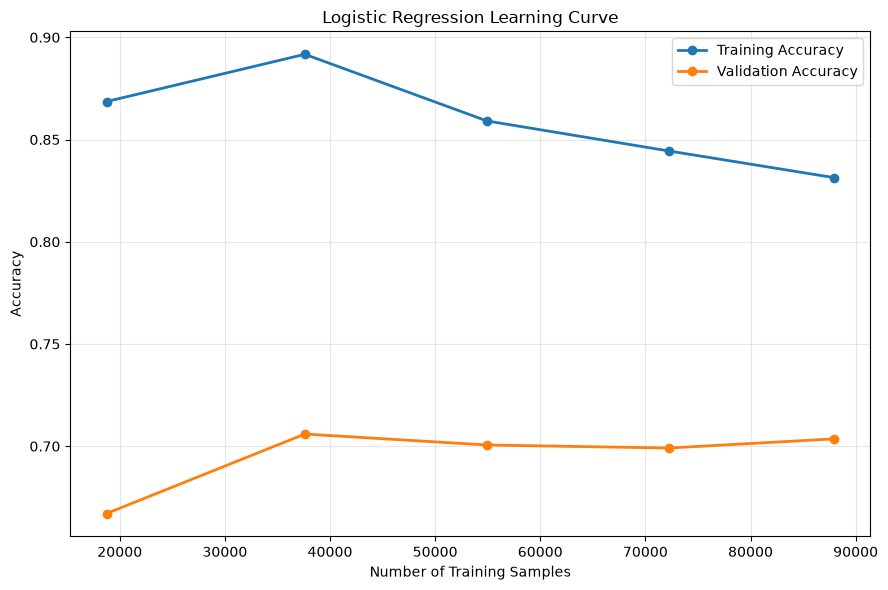


FINAL STANDARDIZATION
Training: (109891, 96)
Validation: (16018, 96)
Testing: (30832, 96)

FINAL LOGISTIC REGRESSION: 5 RUNS

RUN 1/5
Training accuracy: 0.8188
Validation accuracy: 0.7758
Execution time: 8.63 seconds

RUN 2/5
Training accuracy: 0.8188
Validation accuracy: 0.7758
Execution time: 6.83 seconds

RUN 3/5
Training accuracy: 0.8188
Validation accuracy: 0.7758
Execution time: 7.68 seconds

RUN 4/5
Training accuracy: 0.8188
Validation accuracy: 0.7758
Execution time: 6.97 seconds

RUN 5/5
Training accuracy: 0.8188
Validation accuracy: 0.7758
Execution time: 6.86 seconds

 Run  Training_Accuracy  Validation_Accuracy  Execution_Time_Seconds
   1             0.8188               0.7758                  8.6278
   2             0.8188               0.7758                  6.8298
   3             0.8188               0.7758                  7.6793
   4             0.8188               0.7758                  6.9687
   5             0.8188               0.7758                  6.8624

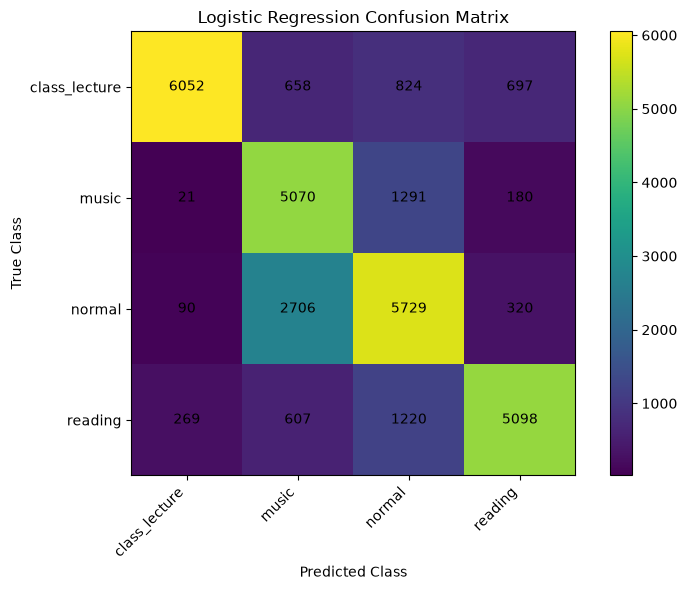

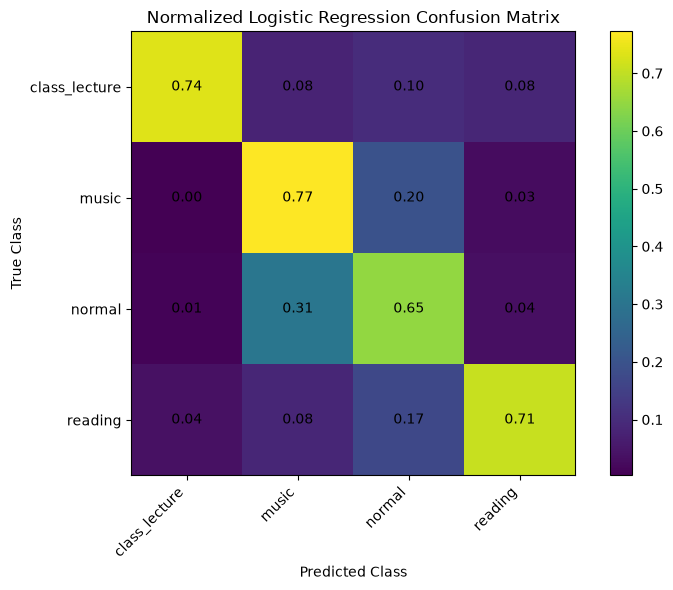


########################################################################
FINAL LOGISTIC REGRESSION RESULTS
########################################################################
Best C                    : 0.0012363188277052211
Penalty                   : L2
Solver                    : LBFGS

Optuna GroupKFold         : 0.7036
Training Accuracy         : 0.8188
Validation Accuracy       : 0.7758
Testing Accuracy          : 0.7119

Five Run Train            : 0.8188 ± 0.0000
Five Run Validation       : 0.7758 ± 0.0000

FULL LOGO Accuracy        : 0.6965 ± 0.1697
FULL LOGO Folds           : 42

Precision Weighted        : 0.7408
Recall Weighted           : 0.7119
F1 Weighted               : 0.7186
F1 Macro                  : 0.7178
Cohen Kappa               : 0.6158
MCC                       : 0.6203
ROC AUC Weighted OVR      : 0.8509

Optuna Time               : 19.46 minutes
Learning Curve Time       : 2.24 minutes
Five Run Time             : 0.62 minutes
Full LOGO Time            :

In [2]:
# ================================================================
# LOGISTIC REGRESSION
# FULL DATASET
# PERSON WISE 70 / 20 / 10
# OPTUNA HYPERPARAMETER OPTIMIZATION
# GROUPKFOLD 5
# FIVE FINAL RUNS
# FULL LEAVE ONE GROUP OUT
# NO LOGO CAP
# NO DATA SUBSAMPLING
# CONFUSION MATRIX
# NORMALIZED CONFUSION MATRIX
# PARTICIPANT AWARE LEARNING CURVE
# ================================================================

import os
import gc
import json
import time
import random
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ================================================================
# GLOBAL SETTINGS
# ================================================================

warnings.filterwarnings("ignore")

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

SEED = 42

N_TRIALS = 10

N_RUNS = 5

GROUP_K_FOLDS = 5

MAX_ITER = 2000

TOLERANCE = 1e-4


random.seed(SEED)

np.random.seed(SEED)


PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# INPUT AND OUTPUT
# ================================================================

FILE_PATH = (
    "/home/rakib/Desktop/ml_apply/"
    "Cleaned_oN_Selected_Med.csv"
)


OUTPUT_DIR = Path(

    "/home/rakib/Desktop/ml_apply/"
    "Logistic_Regression_Results"

)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


TOTAL_START = time.time()


# ================================================================
# EXPERIMENT INFORMATION
# ================================================================

print("=" * 72)

print(
    "LOGISTIC REGRESSION CLASSIFICATION"
)

print("=" * 72)

print(
    "Dataset:",
    FILE_PATH
)

print(
    "Optuna trials:",
    N_TRIALS
)

print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)

print(
    "Final runs:",
    N_RUNS
)

print(
    "LOGO fold cap: NONE"
)

print(
    "Data subsampling: NONE"
)

print(
    "Solver: LBFGS"
)

print(
    "Penalty: L2"
)

print("=" * 72)


# ================================================================
# LOAD COMPLETE DATASET
# ================================================================

print()

print("=" * 72)

print(
    "LOADING COMPLETE DATASET"
)

print("=" * 72)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


# ================================================================
# COLUMN DEFINITIONS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


print(
    "Feature columns:",
    len(feature_cols)
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(
        pd.to_numeric,
        errors="coerce"
    )

    .to_numpy(
        dtype=np.float32
    )

)


# ================================================================
# CHECK INVALID VALUES
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "Dataset contains NaN or "
        "infinite feature values."

    )


# ================================================================
# LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(
    np.int32
)


class_names = list(
    label_encoder.classes_
)


NUMBER_CLASSES = len(
    class_names
)


# ================================================================
# PARTICIPANT GROUPS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)

print(
    "Classes:",
    class_names
)

print(
    "Number of classes:",
    NUMBER_CLASSES
)

print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

print()

print(
    "CLASS DISTRIBUTION"
)


for class_index, class_name in enumerate(
    class_names
):

    count = int(

        np.sum(
            y_all
            == class_index
        )

    )

    percentage = (

        count
        / len(y_all)
        * 100

    )

    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


print()

print(
    "Loading time:",
    f"{time.time() - load_start:.2f}",
    "seconds"
)

print(
    "Current RAM:",
    f"{mem_mb():.2f}",
    "MB"
)


del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10 SPLIT
# ================================================================

print()

print("=" * 72)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 72)


persons = np.unique(
    groups_all
)


rng = np.random.RandomState(
    SEED
)


rng.shuffle(
    persons
)


n_persons = len(
    persons
)


n_test = max(

    1,

    int(
        round(
            0.20
            * n_persons
        )
    )

)


n_validation = max(

    1,

    int(
        round(
            0.10
            * n_persons
        )
    )

)


test_persons = persons[
    :n_test
]


validation_persons = persons[

    n_test:
    n_test + n_validation

]


train_persons = persons[
    n_test + n_validation:
]


# ================================================================
# CREATE MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY PARTICIPANT INDEPENDENCE
# ================================================================

assert (

    np.intersect1d(

        train_persons,

        validation_persons

    ).size

    == 0

)


assert (

    np.intersect1d(

        train_persons,

        test_persons

    ).size

    == 0

)


assert (

    np.intersect1d(

        validation_persons,

        test_persons

    ).size

    == 0

)


print(
    "Training participants:",
    len(
        train_persons
    )
)


print(
    "Testing participants:",
    len(
        test_persons
    )
)


print(
    "Validation participants:",
    len(
        validation_persons
    )
)


print()

print(
    "Training rows:",
    int(
        train_mask.sum()
    )
)


print(
    "Testing rows:",
    int(
        test_mask.sum()
    )
)


print(
    "Validation rows:",
    int(
        validation_mask.sum()
    )
)


# ================================================================
# CREATE SPLITS
# ================================================================

X_train_raw = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation_raw = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


X_test_raw = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


# ================================================================
# RELEASE COMPLETE ARRAYS
# ================================================================

del X_all
del y_all
del groups_all

gc.collect()


print()

print(
    "Training matrix:",
    X_train_raw.shape
)


print(
    "Validation matrix:",
    X_validation_raw.shape
)


print(
    "Testing matrix:",
    X_test_raw.shape
)


print(
    "Current RAM:",
    f"{mem_mb():.2f}",
    "MB"
)


# ================================================================
# GROUPKFOLD
# ================================================================

group_kfold = GroupKFold(

    n_splits=GROUP_K_FOLDS

)


gkf_splits = list(

    group_kfold.split(

        X_train_raw,

        y_train,

        g_train

    )

)


print()

print(
    "GroupKFold folds:",
    len(
        gkf_splits
    )
)


# ================================================================
# FULL LEAVE ONE GROUP OUT
# ================================================================

logo = LeaveOneGroupOut()


logo_splits = list(

    logo.split(

        X_train_raw,

        y_train,

        g_train

    )

)


print(
    "FULL LOGO folds:",
    len(
        logo_splits
    )
)


# ================================================================
# FOLD SPECIFIC STANDARDIZATION
# ================================================================

def prepare_fold(
    train_index,
    validation_index
):

    scaler = StandardScaler()


    X_fold_train = scaler.fit_transform(

        X_train_raw[
            train_index
        ]

    ).astype(
        np.float32
    )


    X_fold_validation = scaler.transform(

        X_train_raw[
            validation_index
        ]

    ).astype(
        np.float32
    )


    X_fold_train = np.ascontiguousarray(
        X_fold_train
    )


    X_fold_validation = np.ascontiguousarray(
        X_fold_validation
    )


    return (

        X_fold_train,

        X_fold_validation

    )


# ================================================================
# LOGISTIC REGRESSION MODEL
# ================================================================

def build_logistic_regression(
    C_value,
    seed=SEED
):

    model = LogisticRegression(

        penalty="l2",

        C=float(
            C_value
        ),

        solver="lbfgs",

        max_iter=MAX_ITER,

        tol=TOLERANCE,

        class_weight="balanced",

        random_state=seed

    )


    return model


# ================================================================
# FIT MODEL
# ================================================================

def fit_model(
    X,
    y,
    C_value,
    seed=SEED
):

    model = build_logistic_regression(

        C_value,

        seed

    )


    model.fit(

        np.ascontiguousarray(
            X,
            dtype=np.float32
        ),

        np.ascontiguousarray(
            y,
            dtype=np.int32
        )

    )


    return model


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def objective(
    trial
):

    C_value = trial.suggest_float(

        "C",

        1e-4,

        1e3,

        log=True

    )


    fold_accuracies = []


    print()

    print(
        f"Trial "
        f"{trial.number + 1}/"
        f"{N_TRIALS}"
    )


    print(
        f"C = "
        f"{C_value:.8g}"
    )


    for fold_number, (
        train_index,
        validation_index
    ) in enumerate(
        gkf_splits,
        start=1
    ):

        fold_start = time.time()


        (
            X_fold_train,
            X_fold_validation

        ) = prepare_fold(

            train_index,

            validation_index

        )


        model = fit_model(

            X_fold_train,

            y_train[
                train_index
            ],

            C_value,

            SEED

        )


        prediction = model.predict(

            X_fold_validation

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        fold_accuracies.append(
            fold_accuracy
        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Time = "
            f"{(time.time() - fold_start):.2f} sec"

        )


        del model
        del prediction
        del X_fold_train
        del X_fold_validation

        gc.collect()


    mean_accuracy = float(

        np.mean(
            fold_accuracies
        )

    )


    std_accuracy = float(

        np.std(
            fold_accuracies
        )

    )


    print(

        f"Trial "
        f"{trial.number + 1} "
        f"mean accuracy = "
        f"{mean_accuracy:.4f} "
        f"± "
        f"{std_accuracy:.4f}"

    )


    return mean_accuracy


# ================================================================
# OPTUNA SEARCH
# ================================================================

print()

print("=" * 72)

print(
    f"OPTUNA SEARCH: "
    f"{N_TRIALS} TRIALS"
)

print(
    "ALL 5 GROUPKFOLD FOLDS"
)

print("=" * 72)


optuna_start = time.time()


study = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(

        seed=SEED

    )

)


study.optimize(

    objective,

    n_trials=N_TRIALS,

    show_progress_bar=False

)


optuna_time = (
    time.time()
    - optuna_start
)


best_C = float(

    study.best_params[
        "C"
    ]

)


print()

print("=" * 72)

print(
    "OPTUNA COMPLETED"
)

print("=" * 72)


print(
    "Best C:",
    best_C
)


print(
    "Best GroupKFold accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Optuna time:",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


# ================================================================
# SAVE OPTUNA RESULTS
# ================================================================

optuna_results = study.trials_dataframe()


optuna_results.to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "C":
                best_C,

            "Penalty":
                "L2",

            "Solver":
                "LBFGS",

            "Best_GroupKFold_Accuracy":
                float(
                    study.best_value
                )

        },

        file,

        indent=4

    )


# ================================================================
# PARTICIPANT AWARE LEARNING CURVE
#
# Training size is increased by participant groups.
#
# Validation participants remain completely held out.
# ================================================================

print()

print("=" * 72)

print(
    "PARTICIPANT AWARE LEARNING CURVE"
)

print("=" * 72)


learning_fractions = np.array(

    [
        0.20,
        0.40,
        0.60,
        0.80,
        1.00
    ],

    dtype=np.float32

)


learning_train_scores = []

learning_validation_scores = []

learning_sample_counts = []

learning_participant_counts = []


learning_start = time.time()


for fraction in learning_fractions:

    fraction_train_scores = []

    fraction_validation_scores = []

    fraction_sample_counts = []

    fraction_person_counts = []


    print()

    print(
        f"Learning curve training fraction: "
        f"{fraction * 100:.0f}%"
    )


    for fold_number, (
        train_index,
        validation_index
    ) in enumerate(
        gkf_splits,
        start=1
    ):

        fold_groups = np.unique(

            g_train[
                train_index
            ]

        )


        fold_rng = np.random.RandomState(

            SEED
            + fold_number

        )


        fold_groups = fold_groups.copy()


        fold_rng.shuffle(
            fold_groups
        )


        number_selected_groups = max(

            1,

            int(
                np.ceil(

                    len(
                        fold_groups
                    )

                    * float(
                        fraction
                    )

                )
            )

        )


        selected_groups = fold_groups[

            :number_selected_groups

        ]


        selected_mask = np.isin(

            g_train[
                train_index
            ],

            selected_groups

        )


        selected_train_index = train_index[

            selected_mask

        ]


        # ========================================================
        # ENSURE ALL CLASSES ARE PRESENT
        # ========================================================

        while (

            len(
                np.unique(
                    y_train[
                        selected_train_index
                    ]
                )
            )

            < NUMBER_CLASSES

            and

            number_selected_groups
            < len(
                fold_groups
            )

        ):

            number_selected_groups += 1


            selected_groups = fold_groups[

                :number_selected_groups

            ]


            selected_mask = np.isin(

                g_train[
                    train_index
                ],

                selected_groups

            )


            selected_train_index = train_index[

                selected_mask

            ]


        # ========================================================
        # FIT SCALER ONLY ON SELECTED TRAINING PARTICIPANTS
        # ========================================================

        curve_scaler = StandardScaler()


        X_curve_train = curve_scaler.fit_transform(

            X_train_raw[
                selected_train_index
            ]

        ).astype(
            np.float32
        )


        X_curve_validation = curve_scaler.transform(

            X_train_raw[
                validation_index
            ]

        ).astype(
            np.float32
        )


        # ========================================================
        # FIT MODEL
        # ========================================================

        curve_model = fit_model(

            X_curve_train,

            y_train[
                selected_train_index
            ],

            best_C,

            SEED

        )


        train_prediction = curve_model.predict(

            X_curve_train

        )


        validation_prediction = curve_model.predict(

            X_curve_validation

        )


        train_score = accuracy_score(

            y_train[
                selected_train_index
            ],

            train_prediction

        )


        validation_score = accuracy_score(

            y_train[
                validation_index
            ],

            validation_prediction

        )


        fraction_train_scores.append(
            train_score
        )


        fraction_validation_scores.append(
            validation_score
        )


        fraction_sample_counts.append(

            len(
                selected_train_index
            )

        )


        fraction_person_counts.append(

            len(
                selected_groups
            )

        )


        print(

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"participants = "
            f"{len(selected_groups)}, "

            f"samples = "
            f"{len(selected_train_index)}, "

            f"train = "
            f"{train_score:.4f}, "

            f"validation = "
            f"{validation_score:.4f}"

        )


        del curve_model
        del curve_scaler
        del X_curve_train
        del X_curve_validation
        del train_prediction
        del validation_prediction

        gc.collect()


    learning_train_scores.append(

        float(
            np.mean(
                fraction_train_scores
            )
        )

    )


    learning_validation_scores.append(

        float(
            np.mean(
                fraction_validation_scores
            )
        )

    )


    learning_sample_counts.append(

        int(
            np.mean(
                fraction_sample_counts
            )
        )

    )


    learning_participant_counts.append(

        int(
            round(
                np.mean(
                    fraction_person_counts
                )
            )
        )

    )


learning_time = (
    time.time()
    - learning_start
)


# ================================================================
# SAVE LEARNING CURVE DATA
# ================================================================

learning_curve_table = pd.DataFrame(

    {

        "Training_Fraction":
            learning_fractions,

        "Mean_Training_Participants":
            learning_participant_counts,

        "Mean_Training_Samples":
            learning_sample_counts,

        "Mean_Training_Accuracy":
            learning_train_scores,

        "Mean_Validation_Accuracy":
            learning_validation_scores

    }

)


learning_curve_table.to_csv(

    OUTPUT_DIR
    / "learning_curve_data.csv",

    index=False

)


print()

print(
    learning_curve_table
    .round(4)
    .to_string(
        index=False
    )
)


# ================================================================
# LEARNING CURVE VISUALIZATION
# ================================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(

    learning_sample_counts,

    learning_train_scores,

    marker="o",

    linewidth=2,

    label="Training Accuracy"

)


plt.plot(

    learning_sample_counts,

    learning_validation_scores,

    marker="o",

    linewidth=2,

    label="Validation Accuracy"

)


plt.xlabel(
    "Number of Training Samples"
)


plt.ylabel(
    "Accuracy"
)


plt.title(
    "Logistic Regression Learning Curve"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    OUTPUT_DIR
    / "learning_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ================================================================
# FINAL STANDARDIZATION
#
# Fit only on the 70 percent training participants.
# ================================================================

print()

print("=" * 72)

print(
    "FINAL STANDARDIZATION"
)

print("=" * 72)


final_scaler = StandardScaler()


X_train = final_scaler.fit_transform(

    X_train_raw

).astype(
    np.float32
)


X_validation = final_scaler.transform(

    X_validation_raw

).astype(
    np.float32
)


X_test = final_scaler.transform(

    X_test_raw

).astype(
    np.float32
)


X_train = np.ascontiguousarray(
    X_train
)


X_validation = np.ascontiguousarray(
    X_validation
)


X_test = np.ascontiguousarray(
    X_test
)


print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


# ================================================================
# FIVE FINAL RUNS
# ================================================================

print()

print("=" * 72)

print(
    f"FINAL LOGISTIC REGRESSION: "
    f"{N_RUNS} RUNS"
)

print("=" * 72)


run_records = []


best_model = None


best_record = None


best_validation_accuracy = (
    float("-inf")
)


five_run_start = time.time()


for run_number in range(
    1,
    N_RUNS + 1
):

    print()

    print(
        f"RUN "
        f"{run_number}/"
        f"{N_RUNS}"
    )


    run_start = time.time()


    model = fit_model(

        X_train,

        y_train,

        best_C,

        seed=(
            SEED
            + run_number
            - 1
        )

    )


    train_prediction = model.predict(
        X_train
    )


    validation_prediction = model.predict(
        X_validation
    )


    train_accuracy = accuracy_score(

        y_train,

        train_prediction

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    run_time = (
        time.time()
        - run_start
    )


    record = {

        "Run":
            run_number,

        "Training_Accuracy":
            float(
                train_accuracy
            ),

        "Validation_Accuracy":
            float(
                validation_accuracy
            ),

        "Execution_Time_Seconds":
            float(
                run_time
            )

    }


    run_records.append(
        record
    )


    print(
        "Training accuracy:",
        f"{train_accuracy:.4f}"
    )


    print(
        "Validation accuracy:",
        f"{validation_accuracy:.4f}"
    )


    print(
        "Execution time:",
        f"{run_time:.2f}",
        "seconds"
    )


    if (

        validation_accuracy
        > best_validation_accuracy

    ):

        if best_model is not None:

            del best_model


        best_model = model


        best_record = (
            record.copy()
        )


        best_validation_accuracy = (
            validation_accuracy
        )


    else:

        del model


    del train_prediction
    del validation_prediction

    gc.collect()


five_run_time = (
    time.time()
    - five_run_start
)


run_table = pd.DataFrame(
    run_records
)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()

print(
    run_table
    .round(4)
    .to_string(
        index=False
    )
)


# ================================================================
# FIVE RUN SUMMARY
# ================================================================

run_train_mean = float(

    run_table[
        "Training_Accuracy"
    ].mean()

)


run_train_std = float(

    run_table[
        "Training_Accuracy"
    ].std(
        ddof=0
    )

)


run_validation_mean = float(

    run_table[
        "Validation_Accuracy"
    ].mean()

)


run_validation_std = float(

    run_table[
        "Validation_Accuracy"
    ].std(
        ddof=0
    )

)


# ================================================================
# FULL LEAVE ONE GROUP OUT
# ================================================================

print()

print("=" * 72)

print(
    "FULL LEAVE ONE GROUP OUT"
)

print(
    "Total folds:",
    len(
        logo_splits
    )
)

print(
    "Fold cap: NONE"
)

print("=" * 72)


logo_start = time.time()


logo_accuracies = []

logo_records = []


for fold_number, (
    train_index,
    validation_index
) in enumerate(
    logo_splits,
    start=1
):

    fold_start = time.time()


    (
        X_fold_train,
        X_fold_validation

    ) = prepare_fold(

        train_index,

        validation_index

    )


    model = fit_model(

        X_fold_train,

        y_train[
            train_index
        ],

        best_C,

        SEED

    )


    prediction = model.predict(

        X_fold_validation

    )


    fold_accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    held_out_persons = np.unique(

        g_train[
            validation_index
        ]

    )


    if len(
        held_out_persons
    ) != 1:

        raise RuntimeError(

            "LOGO fold contains "
            "an unexpected number "
            "of held out participants."

        )


    held_out_person = (
        held_out_persons[
            0
        ]
    )


    fold_time = (
        time.time()
        - fold_start
    )


    logo_accuracies.append(
        fold_accuracy
    )


    logo_records.append(

        {

            "Fold":
                fold_number,

            "Held_Out_Person":
                str(
                    held_out_person
                ),

            "Test_Rows":
                int(
                    len(
                        validation_index
                    )
                ),

            "Accuracy":
                float(
                    fold_accuracy
                ),

            "Execution_Time_Seconds":
                float(
                    fold_time
                )

        }

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "

        f"Participant = "
        f"{held_out_person}, "

        f"Accuracy = "
        f"{fold_accuracy:.4f}, "

        f"Time = "
        f"{fold_time:.2f} sec"

    )


    del model
    del prediction
    del X_fold_train
    del X_fold_validation

    gc.collect()


logo_time = (
    time.time()
    - logo_start
)


logo_mean = float(

    np.mean(
        logo_accuracies
    )

)


logo_std = float(

    np.std(
        logo_accuracies
    )

)


logo_table = pd.DataFrame(
    logo_records
)


logo_table.to_csv(

    OUTPUT_DIR
    / "full_logo_results.csv",

    index=False

)


print()

print(
    "FULL LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "±",
    f"{logo_std:.4f}"
)


print(
    "FULL LOGO folds:",
    len(
        logo_accuracies
    )
)


print(
    "FULL LOGO time:",
    f"{logo_time / 60:.2f}",
    "minutes"
)


# ================================================================
# FINAL TEST SET
# ================================================================

print()

print("=" * 72)

print(
    "FINAL UNTOUCHED TEST EVALUATION"
)

print("=" * 72)


test_start = time.time()


test_prediction = best_model.predict(
    X_test
)


test_probability = best_model.predict_proba(
    X_test
)


test_prediction_time = (
    time.time()
    - test_start
)


# ================================================================
# TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average="macro",

    zero_division=0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


# ================================================================
# ROC AUC
# ================================================================

try:

    test_roc_auc = roc_auc_score(

        y_test,

        test_probability,

        multi_class="ovr",

        average="weighted"

    )


except Exception:

    test_roc_auc = np.nan


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=np.arange(
        NUMBER_CLASSES
    ),

    target_names=class_names,

    digits=4,

    zero_division=0

)


print()

print(
    "CLASSIFICATION REPORT"
)

print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(
        report
    )


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=np.arange(
        NUMBER_CLASSES
    )

)


# ================================================================
# RAW CONFUSION MATRIX VISUALIZATION
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(
    cm
)


ax.set_xticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(
    class_names
)


ax.set_xlabel(
    "Predicted Class"
)


ax.set_ylabel(
    "True Class"
)


ax.set_title(

    "Logistic Regression Confusion Matrix"

)


for i in range(
    NUMBER_CLASSES
):

    for j in range(
        NUMBER_CLASSES
    ):

        ax.text(

            j,

            i,

            str(
                cm[
                    i,
                    j
                ]
            ),

            ha="center",

            va="center"

        )


fig.colorbar(
    image,
    ax=ax
)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(

    axis=1,

    keepdims=True

)


normalized_cm = np.divide(

    cm,

    row_sums,

    out=np.zeros_like(
        cm,
        dtype=np.float64
    ),

    where=(
        row_sums
        != 0
    )

)


fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(
    normalized_cm
)


ax.set_xticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(
    class_names
)


ax.set_xlabel(
    "Predicted Class"
)


ax.set_ylabel(
    "True Class"
)


ax.set_title(

    "Normalized Logistic Regression Confusion Matrix"

)


for i in range(
    NUMBER_CLASSES
):

    for j in range(
        NUMBER_CLASSES
    ):

        ax.text(

            j,

            i,

            f"{normalized_cm[i, j]:.2f}",

            ha="center",

            va="center"

        )


fig.colorbar(
    image,
    ax=ax
)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "normalized_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ================================================================
# SAVE CONFUSION MATRIX VALUES
# ================================================================

cm_table = pd.DataFrame(

    cm,

    index=class_names,

    columns=class_names

)


cm_table.to_csv(

    OUTPUT_DIR
    / "confusion_matrix.csv"

)


normalized_cm_table = pd.DataFrame(

    normalized_cm,

    index=class_names,

    columns=class_names

)


normalized_cm_table.to_csv(

    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"

)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {

        "True_Class":

            label_encoder.inverse_transform(
                y_test
            ),

        "Predicted_Class":

            label_encoder.inverse_transform(
                test_prediction
            )

    }

)


for class_index, class_name in enumerate(
    class_names
):

    prediction_table[

        f"Probability_{class_name}"

    ] = test_probability[

        :,
        class_index

    ]


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# SAVE FINAL MODEL
# ================================================================

with open(

    OUTPUT_DIR
    / "logistic_regression_model.pkl",

    "wb"

) as file:

    pickle.dump(

        {

            "model":
                best_model,

            "scaler":
                final_scaler,

            "label_encoder":
                label_encoder,

            "feature_columns":
                feature_cols,

            "best_C":
                best_C

        },

        file

    )


# ================================================================
# TOTAL EXECUTION TIME
# ================================================================

total_execution_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {

    "Algorithm":
        "Logistic Regression",

    "Penalty":
        "L2",

    "Solver":
        "LBFGS",

    "Best_C":
        float(
            best_C
        ),

    "Number_of_Features":
        int(
            len(
                feature_cols
            )
        ),

    "Number_of_Classes":
        int(
            NUMBER_CLASSES
        ),

    "Training_Participants":
        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":
        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":
        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":
        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":
        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":
        int(
            len(
                X_test
            )
        ),

    "Optuna_GroupKFold_Accuracy":
        float(
            study.best_value
        ),

    "Five_Run_Training_Mean":
        run_train_mean,

    "Five_Run_Training_STD":
        run_train_std,

    "Five_Run_Validation_Mean":
        run_validation_mean,

    "Five_Run_Validation_STD":
        run_validation_std,

    "Selected_Run":
        int(
            best_record[
                "Run"
            ]
        ),

    "Training_Accuracy":
        float(
            best_record[
                "Training_Accuracy"
            ]
        ),

    "Validation_Accuracy":
        float(
            best_record[
                "Validation_Accuracy"
            ]
        ),

    "Testing_Accuracy":
        float(
            test_accuracy
        ),

    "Full_LOGO_Accuracy":
        logo_mean,

    "Full_LOGO_STD":
        logo_std,

    "Full_LOGO_Folds":
        int(
            len(
                logo_splits
            )
        ),

    "Precision_Weighted":
        float(
            test_precision
        ),

    "Recall_Weighted":
        float(
            test_recall
        ),

    "F1_Weighted":
        float(
            test_f1_weighted
        ),

    "F1_Macro":
        float(
            test_f1_macro
        ),

    "Cohen_Kappa":
        float(
            test_kappa
        ),

    "MCC":
        float(
            test_mcc
        ),

    "ROC_AUC_Weighted_OVR":

        None

        if np.isnan(
            test_roc_auc
        )

        else float(
            test_roc_auc
        ),

    "Optuna_Time_Seconds":
        float(
            optuna_time
        ),

    "Learning_Curve_Time_Seconds":
        float(
            learning_time
        ),

    "Five_Run_Time_Seconds":
        float(
            five_run_time
        ),

    "Full_LOGO_Time_Seconds":
        float(
            logo_time
        ),

    "Test_Prediction_Time_Seconds":
        float(
            test_prediction_time
        ),

    "Total_Execution_Time_Seconds":
        float(
            total_execution_time
        )

}


with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=4

    )


# ================================================================
# FINAL SUMMARY
# ================================================================

print()

print("#" * 72)

print(
    "FINAL LOGISTIC REGRESSION RESULTS"
)

print("#" * 72)


print(
    "Best C                    :",
    best_C
)


print(
    "Penalty                   : L2"
)


print(
    "Solver                    : LBFGS"
)


print()

print(
    "Optuna GroupKFold         :",
    f"{study.best_value:.4f}"
)


print(
    "Training Accuracy         :",
    f"{best_record['Training_Accuracy']:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{best_record['Validation_Accuracy']:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "Five Run Train            :",
    f"{run_train_mean:.4f}",
    "±",
    f"{run_train_std:.4f}"
)


print(
    "Five Run Validation       :",
    f"{run_validation_mean:.4f}",
    "±",
    f"{run_validation_std:.4f}"
)


print()

print(
    "FULL LOGO Accuracy        :",
    f"{logo_mean:.4f}",
    "±",
    f"{logo_std:.4f}"
)


print(
    "FULL LOGO Folds           :",
    len(
        logo_splits
    )
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


if np.isnan(
    test_roc_auc
):

    print(
        "ROC AUC Weighted OVR      : N/A"
    )

else:

    print(
        "ROC AUC Weighted OVR      :",
        f"{test_roc_auc:.4f}"
    )


print()

print(
    "Optuna Time               :",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


print(
    "Learning Curve Time       :",
    f"{learning_time / 60:.2f}",
    "minutes"
)


print(
    "Five Run Time             :",
    f"{five_run_time / 60:.2f}",
    "minutes"
)


print(
    "Full LOGO Time            :",
    f"{logo_time / 60:.2f}",
    "minutes"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "No LOGO folds were capped."
)


print(
    "No rows were removed for "
    "computational reduction."
)


print(
    "All 5 GroupKFold folds were used."
)


print(
    "Test participants remained untouched "
    "until final evaluation."
)


print(
    "Learning curve used participant based "
    "training subsets."
)


print()

print(
    "Results saved to:"
)


print(
    OUTPUT_DIR
)


print("#" * 72)

***Apply ML on Max Dataset in ratio (70% Training, 20% Testing, 10% CV)***

**Apply [LightGBM, XGBoost, Random Forest] on Max Datset**

MAX DATASET CLASSIFICATION
Input file:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Cleaned_oN_Selected_Max.csv

LightGBM device: CPU
XGBoost device: CPU hist
CPU workers: 8
LightGBM Optuna trials: 15
XGBoost Optuna trials: 12
LightGBM runs: 5
GroupKFold folds: 5
LOGO cap: NONE
Data reduction: NONE

LOADING MAX DATASET
Raw dataset shape: (149350, 238)
RAM after loading: 1330.41 MB
Feature count: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

Loading time: 7.95 sec

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training: (107752, 232)
Validation: (14405, 232)
Testing: (27193, 232)

STANDARDIZATION
Training: (107752, 232)
Validation: (14405, 232)
Testing: (27193, 232)
RAM: 1338.38 MB

GroupKFold folds:

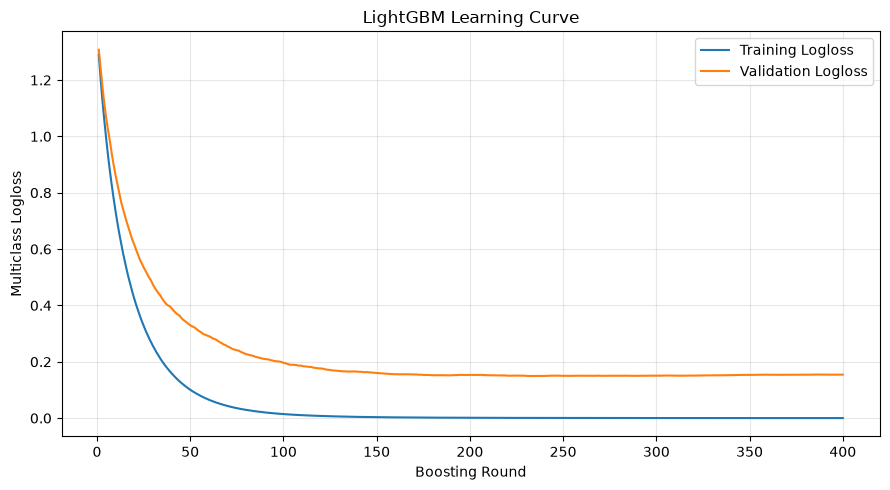


XGBOOST OPTUNA
XGB trial 1/12, fold 1/5, accuracy=0.9005
XGB trial 1/12, fold 2/5, accuracy=0.9062
XGB trial 1/12, fold 3/5, accuracy=0.8800
XGB trial 1/12, fold 4/5, accuracy=0.9346
XGB trial 1/12, fold 5/5, accuracy=0.8745
XGB trial 2/12, fold 1/5, accuracy=0.8861
XGB trial 2/12, fold 2/5, accuracy=0.9072
XGB trial 2/12, fold 3/5, accuracy=0.8749
XGB trial 2/12, fold 4/5, accuracy=0.9231
XGB trial 2/12, fold 5/5, accuracy=0.8753
XGB trial 3/12, fold 1/5, accuracy=0.8969
XGB trial 3/12, fold 2/5, accuracy=0.9153
XGB trial 3/12, fold 3/5, accuracy=0.8919
XGB trial 3/12, fold 4/5, accuracy=0.8913
XGB trial 3/12, fold 5/5, accuracy=0.8752
XGB trial 4/12, fold 1/5, accuracy=0.8881
XGB trial 4/12, fold 2/5, accuracy=0.9121
XGB trial 4/12, fold 3/5, accuracy=0.8767
XGB trial 4/12, fold 4/5, accuracy=0.8854
XGB trial 4/12, fold 5/5, accuracy=0.8581
XGB trial 5/12, fold 1/5, accuracy=0.8670
XGB trial 5/12, fold 2/5, accuracy=0.8952
XGB trial 5/12, fold 3/5, accuracy=0.8509
XGB trial 5/12, fo

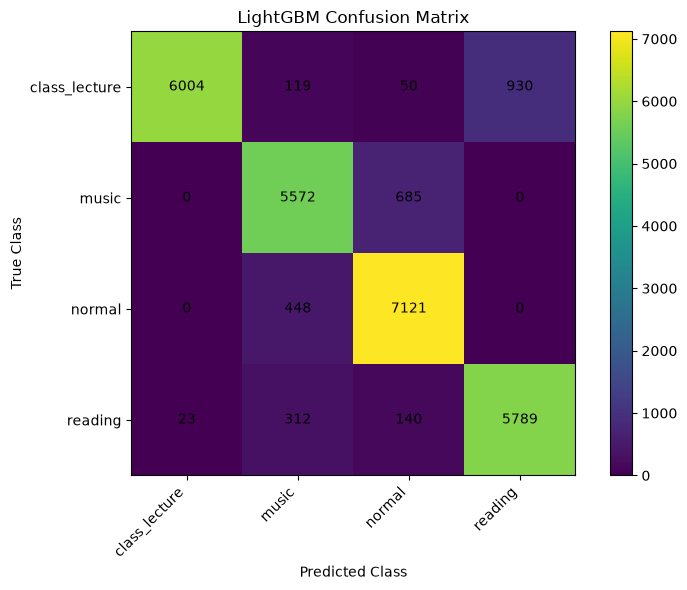


XGBoost
               precision    recall  f1-score   support

class_lecture     0.9872    0.8266    0.8998      7103
        music     0.9043    0.8974    0.9009      6257
       normal     0.8480    0.9343    0.8891      7569
      reading     0.8777    0.9384    0.9070      6264

     accuracy                         0.8986     27193
    macro avg     0.9043    0.8992    0.8992     27193
 weighted avg     0.9042    0.8986    0.8987     27193



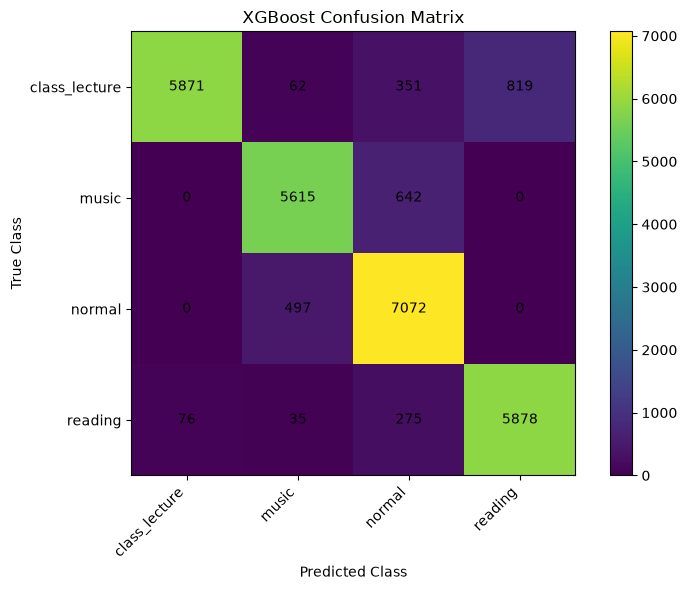


ExtraTrees
               precision    recall  f1-score   support

class_lecture     0.9454    0.7556    0.8399      7103
        music     0.9657    0.8105    0.8813      6257
       normal     0.8610    0.9762    0.9150      7569
      reading     0.7740    0.9494    0.8528      6264

     accuracy                         0.8743     27193
    macro avg     0.8865    0.8729    0.8722     27193
 weighted avg     0.8871    0.8743    0.8733     27193



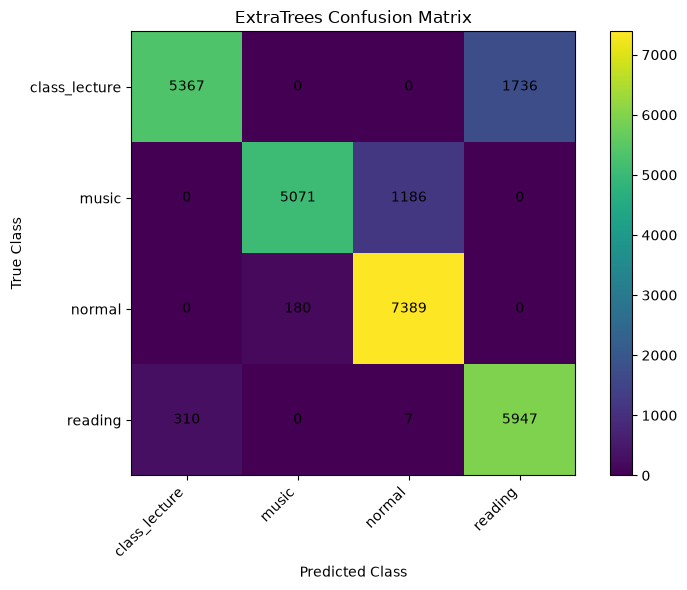


RandomForest
               precision    recall  f1-score   support

class_lecture     0.9520    0.8458    0.8958      7103
        music     0.8388    0.8443    0.8416      6257
       normal     0.8698    0.8659    0.8678      7569
      reading     0.8447    0.9505    0.8945      6264

     accuracy                         0.8752     27193
    macro avg     0.8763    0.8766    0.8749     27193
 weighted avg     0.8784    0.8752    0.8752     27193



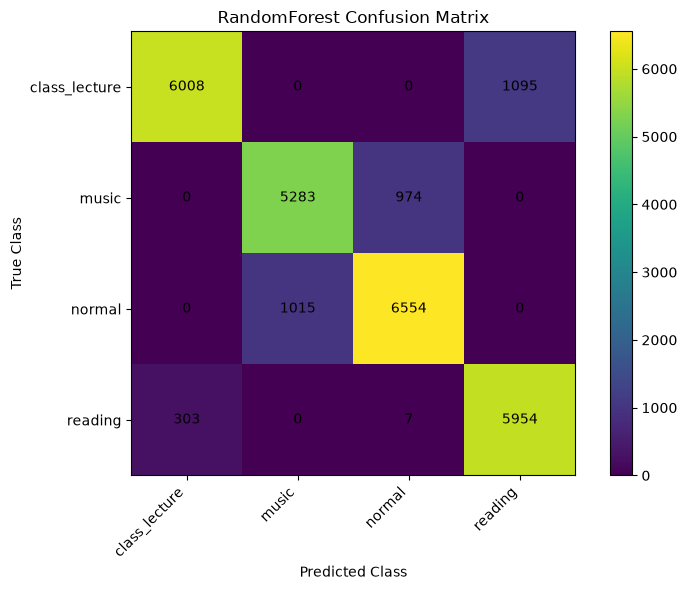


SoftVote
               precision    recall  f1-score   support

class_lecture     0.9919    0.8592    0.9208      7103
        music     0.9228    0.8793    0.9006      6257
       normal     0.8737    0.9527    0.9115      7569
      reading     0.8671    0.9448    0.9043      6264

     accuracy                         0.9096     27193
    macro avg     0.9139    0.9090    0.9093     27193
 weighted avg     0.9144    0.9096    0.9097     27193



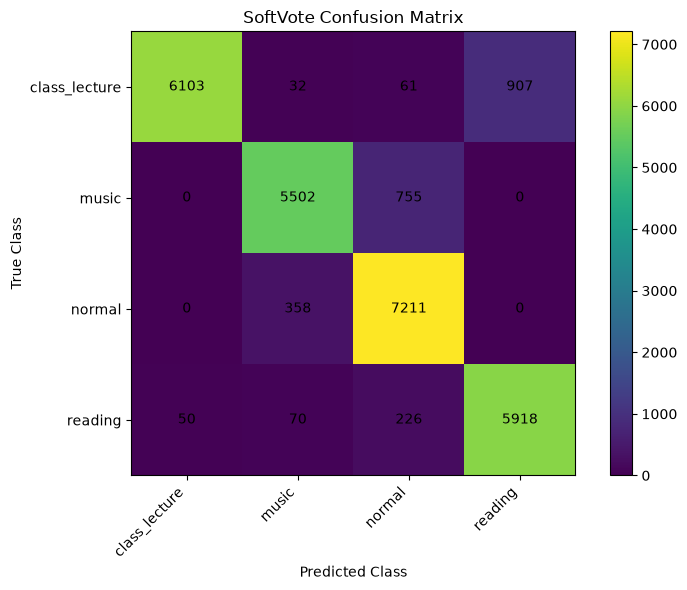


################################################################################
FINAL MAX DATASET RESULTS
################################################################################

   Algorithm  Training_Accuracy  Validation_Accuracy  Testing_Accuracy  GroupKFold_Accuracy  GroupKFold_STD  Full_LOGO_Accuracy  Full_LOGO_STD  Precision_Weighted  Recall_Weighted  F1_Weighted  F1_Macro  Cohen_Kappa    MCC  ROC_AUC_Weighted
    LightGBM                1.0               0.9415            0.9005               0.8938          0.0132              0.9226         0.1224              0.9053           0.9005       0.9008    0.8996       0.8670 0.8683            0.9890
     XGBoost                1.0               0.9368            0.8986               0.9079             NaN                 NaN            NaN              0.9042           0.8986       0.8987    0.8992       0.8645 0.8662            0.9881
  ExtraTrees                1.0               0.8975            0.8743               0.

In [7]:
# ================================================================
# MAX DATASET
#
# ALGORITHMS
#
# LightGBM
# XGBoost
# ExtraTrees
# RandomForest
# SoftVote
#
# Participant wise 70 / 20 / 10
# GroupKFold 5
# Optuna
# LightGBM 5 runs
# Full LOGO for LightGBM
# LightGBM learning curve
# Confusion matrices
# Complete metrics
#
# LightGBM CPU
# XGBoost CPU hist
#
# No row reduction
# No LOGO cap
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import json
import time
import random
import warnings

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

import lightgbm as lgb

from xgboost import XGBClassifier

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.utils.class_weight import (
    compute_sample_weight
)


# ================================================================
# CONFIGURATION
# ================================================================

SEED = 42

LGB_OPTUNA_TRIALS = 15

XGB_OPTUNA_TRIALS = 12

LGB_RUNS = 5

GROUP_K_FOLDS = 5


LGB_OPTUNA_MAX_ROUNDS = 800

LGB_OPTUNA_EARLY_STOPPING = 30


LGB_FINAL_MAX_ROUNDS = 1500

LGB_FINAL_EARLY_STOPPING = 40


LGB_LEARNING_CURVE_ROUNDS = 400


RF_TREES = 600

ET_TREES = 600


# Limit CPU parallelism to reduce RAM pressure

N_JOBS = max(
    1,
    min(
        8,
        os.cpu_count() or 1
    )
)


random.seed(SEED)

np.random.seed(SEED)


warnings.filterwarnings(
    "ignore"
)


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ================================================================
# MEMORY
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# INPUT
# ================================================================

FILE_PATH = Path(

    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"

)


if not FILE_PATH.exists():

    raise FileNotFoundError(

        f"Input file not found: "
        f"{FILE_PATH}"

    )


# ================================================================
# OUTPUT DIRECTORIES
# ================================================================

BASE_DIR = FILE_PATH.parent


LGB_DIR = (

    BASE_DIR
    / "Max_Dataset_LightGBM_Results"

)


XGB_DIR = (

    BASE_DIR
    / "Max_Dataset_XGBoost_Results"

)


ET_DIR = (

    BASE_DIR
    / "Max_Dataset_ExtraTrees_Results"

)


RF_DIR = (

    BASE_DIR
    / "Max_Dataset_RandomForest_Results"

)


SOFT_DIR = (

    BASE_DIR
    / "Max_Dataset_SoftVote_Results"

)


SUMMARY_DIR = (

    BASE_DIR
    / "Max_Dataset_All_Algorithms_Summary"

)


for directory in [

    LGB_DIR,

    XGB_DIR,

    ET_DIR,

    RF_DIR,

    SOFT_DIR,

    SUMMARY_DIR

]:

    directory.mkdir(

        parents=True,

        exist_ok=True

    )


# ================================================================
# TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# CONFIGURATION INFORMATION
# ================================================================

print("=" * 80)

print(
    "MAX DATASET CLASSIFICATION"
)

print("=" * 80)


print(
    "Input file:"
)

print(
    FILE_PATH
)


print()

print(
    "LightGBM device: CPU"
)


print(
    "XGBoost device: CPU hist"
)


print(
    "CPU workers:",
    N_JOBS
)


print(
    "LightGBM Optuna trials:",
    LGB_OPTUNA_TRIALS
)


print(
    "XGBoost Optuna trials:",
    XGB_OPTUNA_TRIALS
)


print(
    "LightGBM runs:",
    LGB_RUNS
)


print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)


print(
    "LOGO cap: NONE"
)


print(
    "Data reduction: NONE"
)


print("=" * 80)


# ================================================================
# LOAD DATA
# ================================================================

print()

print("=" * 80)

print(
    "LOADING MAX DATASET"
)

print("=" * 80)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMNS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


if len(feature_cols) == 0:

    raise ValueError(

        "No feature columns detected."

    )


print(
    "Feature count:",
    len(feature_cols)
)


# ================================================================
# FEATURES
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(

        pd.to_numeric,

        errors="coerce"

    )

    .to_numpy(

        dtype=np.float32

    )

)


invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "Feature matrix contains "
        "NaN or infinite values."

    )


# ================================================================
# LABELS
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(

    np.int32

)


class_names = list(

    label_encoder.classes_

)


NUM_CLASSES = len(

    class_names

)


groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Classes:",
    class_names
)


print(
    "Number of classes:",
    NUM_CLASSES
)


print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

class_distribution = []


print()

print(
    "CLASS DISTRIBUTION"
)


for class_index, class_name in enumerate(

    class_names

):

    count = int(

        np.sum(

            y_all
            == class_index

        )

    )


    percentage = (

        count
        / len(
            y_all
        )
        * 100

    )


    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


    class_distribution.append(

        {

            "Class":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage

        }

    )


pd.DataFrame(

    class_distribution

).to_csv(

    SUMMARY_DIR
    / "class_distribution.csv",

    index=False

)


print()

print(
    "Loading time:",
    f"{time.time() - load_start:.2f} sec"
)


del df

gc.collect()


# ================================================================
# PERSON WISE SPLIT
# ================================================================

print()

print("=" * 80)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 80)


persons = np.unique(

    groups_all

)


rng = np.random.RandomState(

    SEED

)


rng.shuffle(

    persons

)


number_persons = len(

    persons

)


number_test = max(

    1,

    int(

        round(

            0.20
            * number_persons

        )

    )

)


number_validation = max(

    1,

    int(

        round(

            0.10
            * number_persons

        )

    )

)


test_persons = persons[

    :number_test

]


validation_persons = persons[

    number_test:
    number_test
    + number_validation

]


train_persons = persons[

    number_test
    + number_validation:

]


# ================================================================
# MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY PARTICIPANT INDEPENDENCE
# ================================================================

assert (

    np.intersect1d(

        train_persons,

        validation_persons

    ).size == 0

)


assert (

    np.intersect1d(

        train_persons,

        test_persons

    ).size == 0

)


assert (

    np.intersect1d(

        validation_persons,

        test_persons

    ).size == 0

)


# ================================================================
# DATA SPLITS
# ================================================================

X_train = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


g_validation = np.ascontiguousarray(

    groups_all[
        validation_mask
    ]

)


X_test = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


g_test = np.ascontiguousarray(

    groups_all[
        test_mask
    ]

)


print(
    "Training participants:",
    len(
        train_persons
    )
)


print(
    "Validation participants:",
    len(
        validation_persons
    )
)


print(
    "Testing participants:",
    len(
        test_persons
    )
)


print()

print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


# ================================================================
# SAVE SPLIT INFORMATION
# ================================================================

split_table = pd.DataFrame(

    [

        {

            "Split":
                "Training",

            "Participants":
                len(
                    train_persons
                ),

            "Rows":
                len(
                    X_train
                )

        },

        {

            "Split":
                "Validation",

            "Participants":
                len(
                    validation_persons
                ),

            "Rows":
                len(
                    X_validation
                )

        },

        {

            "Split":
                "Testing",

            "Participants":
                len(
                    test_persons
                ),

            "Rows":
                len(
                    X_test
                )

        }

    ]

)


split_table.to_csv(

    SUMMARY_DIR
    / "split_summary.csv",

    index=False

)


with open(

    SUMMARY_DIR
    / "participant_split.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "training":

                [
                    str(x)
                    for x
                    in train_persons
                ],

            "validation":

                [
                    str(x)
                    for x
                    in validation_persons
                ],

            "testing":

                [
                    str(x)
                    for x
                    in test_persons
                ]

        },

        file,

        indent=4

    )


# ================================================================
# RELEASE COMPLETE ARRAYS
# ================================================================

del X_all

del y_all

del groups_all

del train_mask

del validation_mask

del test_mask

gc.collect()


# ================================================================
# STANDARDIZATION
#
# Kept to follow the supplied pipeline.
# Trees do not normally require feature standardization.
# ================================================================

print()

print("=" * 80)

print(
    "STANDARDIZATION"
)

print("=" * 80)


scaler = StandardScaler()


X_train = scaler.fit_transform(

    X_train

).astype(

    np.float32

)


X_validation = scaler.transform(

    X_validation

).astype(

    np.float32

)


X_test = scaler.transform(

    X_test

).astype(

    np.float32

)


X_train = np.ascontiguousarray(

    X_train

)


X_validation = np.ascontiguousarray(

    X_validation

)


X_test = np.ascontiguousarray(

    X_test

)


print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


print(
    "RAM:",
    f"{mem_mb():.2f} MB"
)


joblib.dump(

    scaler,

    SUMMARY_DIR
    / "standard_scaler.joblib"

)


joblib.dump(

    label_encoder,

    SUMMARY_DIR
    / "label_encoder.joblib"

)


with open(

    SUMMARY_DIR
    / "feature_columns.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        feature_cols,

        file,

        indent=4

    )


# ================================================================
# CROSS VALIDATION
# ================================================================

gkf_splits = list(

    GroupKFold(

        n_splits=GROUP_K_FOLDS

    ).split(

        X_train,

        y_train,

        g_train

    )

)


logo_splits = list(

    LeaveOneGroupOut().split(

        X_train,

        y_train,

        g_train

    )

)


print()

print(
    "GroupKFold folds:",
    len(
        gkf_splits
    )
)


print(
    "Full LOGO folds:",
    len(
        logo_splits
    )
)


# ================================================================
# METRIC FUNCTION
# ================================================================

def calculate_metrics(

    y_true,

    prediction,

    probability

):

    result = {

        "accuracy":

            float(

                accuracy_score(

                    y_true,

                    prediction

                )

            ),

        "precision_weighted":

            float(

                precision_score(

                    y_true,

                    prediction,

                    average="weighted",

                    zero_division=0

                )

            ),

        "recall_weighted":

            float(

                recall_score(

                    y_true,

                    prediction,

                    average="weighted",

                    zero_division=0

                )

            ),

        "f1_weighted":

            float(

                f1_score(

                    y_true,

                    prediction,

                    average="weighted",

                    zero_division=0

                )

            ),

        "f1_macro":

            float(

                f1_score(

                    y_true,

                    prediction,

                    average="macro",

                    zero_division=0

                )

            ),

        "cohen_kappa":

            float(

                cohen_kappa_score(

                    y_true,

                    prediction

                )

            ),

        "mcc":

            float(

                matthews_corrcoef(

                    y_true,

                    prediction

                )

            )

    }


    try:

        result[
            "roc_auc_weighted"
        ] = float(

            roc_auc_score(

                y_true,

                probability,

                multi_class="ovr",

                average="weighted"

            )

        )


    except Exception:

        result[
            "roc_auc_weighted"
        ] = None


    return result


# ================================================================
# CONFUSION MATRIX FUNCTION
# ================================================================

def save_confusion_matrix(

    model_name,

    output_directory,

    y_true,

    prediction

):

    matrix = confusion_matrix(

        y_true,

        prediction,

        labels=np.arange(
            NUM_CLASSES
        )

    )


    pd.DataFrame(

        matrix,

        index=class_names,

        columns=class_names

    ).to_csv(

        output_directory
        / "confusion_matrix.csv"

    )


    fig, ax = plt.subplots(

        figsize=(8, 6)

    )


    image = ax.imshow(

        matrix

    )


    ax.set_xticks(

        np.arange(
            NUM_CLASSES
        )

    )


    ax.set_yticks(

        np.arange(
            NUM_CLASSES
        )

    )


    ax.set_xticklabels(

        class_names,

        rotation=45,

        ha="right"

    )


    ax.set_yticklabels(

        class_names

    )


    ax.set_xlabel(

        "Predicted Class"

    )


    ax.set_ylabel(

        "True Class"

    )


    ax.set_title(

        f"{model_name} Confusion Matrix"

    )


    for row in range(

        NUM_CLASSES

    ):

        for column in range(

            NUM_CLASSES

        ):

            ax.text(

                column,

                row,

                str(
                    matrix[
                        row,
                        column
                    ]
                ),

                ha="center",

                va="center"

            )


    fig.colorbar(

        image,

        ax=ax

    )


    fig.tight_layout()


    fig.savefig(

        output_directory
        / "confusion_matrix.png",

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()


    plt.close(
        fig
    )


# ================================================================
# REPORT SAVING FUNCTION
# ================================================================

def save_test_report(

    model_name,

    output_directory,

    prediction,

    probability,

    additional_metrics=None

):

    metrics = calculate_metrics(

        y_test,

        prediction,

        probability

    )


    if additional_metrics is not None:

        metrics.update(

            additional_metrics

        )


    report_text = classification_report(

        y_test,

        prediction,

        target_names=class_names,

        digits=4,

        zero_division=0

    )


    print()

    print("=" * 80)

    print(
        model_name
    )

    print("=" * 80)

    print(
        report_text
    )


    with open(

        output_directory
        / "classification_report.txt",

        "w",

        encoding="utf8"

    ) as file:

        file.write(

            report_text

        )


    report_table = pd.DataFrame(

        classification_report(

            y_test,

            prediction,

            target_names=class_names,

            output_dict=True,

            zero_division=0

        )

    ).transpose()


    report_table.to_csv(

        output_directory
        / "classification_report.csv"

    )


    save_confusion_matrix(

        model_name,

        output_directory,

        y_test,

        prediction

    )


    prediction_table = pd.DataFrame(

        {

            "PersonSrial":

                g_test,

            "True_Class":

                label_encoder.inverse_transform(

                    y_test

                ),

            "Predicted_Class":

                label_encoder.inverse_transform(

                    prediction.astype(
                        np.int32
                    )

                )

        }

    )


    for class_index, class_name in enumerate(

        class_names

    ):

        prediction_table[

            f"Probability_{class_name}"

        ] = probability[

            :,

            class_index

        ]


    prediction_table.to_csv(

        output_directory
        / "test_predictions.csv",

        index=False

    )


    with open(

        output_directory
        / "final_metrics.json",

        "w",

        encoding="utf8"

    ) as file:

        json.dump(

            metrics,

            file,

            indent=4

        )


    return metrics


# ================================================================
# LIGHTGBM PARAMETERS
#
# CPU is forced.
# ================================================================

def make_lgb_params(

    tuned=None,

    seed=SEED

):

    params = {

        "objective":
            "multiclass",

        "num_class":
            NUM_CLASSES,

        "metric":
            "multi_logloss",

        "boosting_type":
            "gbdt",

        "device_type":
            "cpu",

        "force_col_wise":
            True,

        "num_threads":
            N_JOBS,

        "verbosity":
            -1,

        "bagging_freq":
            1,

        "seed":
            seed,

        "bagging_seed":
            seed,

        "feature_fraction_seed":
            seed,

        "data_random_seed":
            seed

    }


    if tuned is not None:

        params.update(

            tuned

        )


    return params


# ================================================================
# LIGHTGBM OPTUNA OBJECTIVE
# ================================================================

def lightgbm_objective(

    trial

):

    tuned = {

        "learning_rate":

            trial.suggest_float(

                "learning_rate",

                0.02,

                0.08,

                log=True

            ),

        "num_leaves":

            trial.suggest_int(

                "num_leaves",

                15,

                63

            ),

        "max_depth":

            trial.suggest_int(

                "max_depth",

                3,

                8

            ),

        "min_data_in_leaf":

            trial.suggest_int(

                "min_data_in_leaf",

                40,

                200

            ),

        "feature_fraction":

            trial.suggest_float(

                "feature_fraction",

                0.4,

                0.8

            ),

        "bagging_fraction":

            trial.suggest_float(

                "bagging_fraction",

                0.6,

                1.0

            ),

        "lambda_l1":

            trial.suggest_float(

                "lambda_l1",

                1e-2,

                20.0,

                log=True

            ),

        "lambda_l2":

            trial.suggest_float(

                "lambda_l2",

                1e-2,

                20.0,

                log=True

            )

    }


    params = make_lgb_params(

        tuned,

        SEED

    )


    scores = []


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        sample_weight = compute_sample_weight(

            "balanced",

            y_train[
                train_index
            ]

        )


        training_data = lgb.Dataset(

            X_train[
                train_index
            ],

            label=y_train[
                train_index
            ],

            weight=sample_weight,

            free_raw_data=True

        )


        fold_validation_data = lgb.Dataset(

            X_train[
                validation_index
            ],

            label=y_train[
                validation_index
            ],

            reference=training_data,

            free_raw_data=True

        )


        model = lgb.train(

            params,

            training_data,

            num_boost_round=
                LGB_OPTUNA_MAX_ROUNDS,

            valid_sets=[

                fold_validation_data

            ],

            callbacks=[

                lgb.early_stopping(

                    LGB_OPTUNA_EARLY_STOPPING,

                    verbose=False

                ),

                lgb.log_evaluation(
                    0
                )

            ]

        )


        probability = model.predict(

            X_train[
                validation_index
            ],

            num_iteration=
                model.best_iteration

        )


        prediction = np.argmax(

            probability,

            axis=1

        )


        score = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        scores.append(

            score

        )


        print(

            f"LGB trial "
            f"{trial.number + 1}/"
            f"{LGB_OPTUNA_TRIALS}, "

            f"fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"accuracy="
            f"{score:.4f}, "

            f"time="
            f"{time.time() - fold_start:.2f} sec"

        )


        del model

        del training_data

        del fold_validation_data

        del probability

        del prediction

        del sample_weight


        gc.collect()


    return float(

        np.mean(
            scores
        )

    )


# ================================================================
# LIGHTGBM OPTUNA
# ================================================================

print()

print("=" * 80)

print(
    "LIGHTGBM OPTUNA"
)

print("=" * 80)


lgb_optuna_start = time.time()


lgb_study = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(

        seed=SEED

    )

)


lgb_study.optimize(

    lightgbm_objective,

    n_trials=
        LGB_OPTUNA_TRIALS,

    show_progress_bar=False

)


lgb_optuna_time = (

    time.time()
    - lgb_optuna_start

)


lgb_best_params = (

    lgb_study.best_params.copy()

)


print()

print(
    "Best LightGBM GroupKFold Accuracy:",
    f"{lgb_study.best_value:.4f}"
)


print(
    "Best LightGBM Parameters:"
)


print(
    lgb_best_params
)


lgb_study.trials_dataframe().to_csv(

    LGB_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    LGB_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        lgb_best_params,

        file,

        indent=4

    )


# ================================================================
# LIGHTGBM FIVE RUNS
# ================================================================

print()

print("=" * 80)

print(
    "LIGHTGBM FIVE RUNS"
)

print("=" * 80)


lgb_records = []


lgb_best_model = None


lgb_best_record = None


lgb_best_validation_accuracy = (

    float("-inf")

)


lgb_runs_start = time.time()


for run in range(

    LGB_RUNS

):

    run_number = (

        run + 1

    )


    run_start = time.time()


    run_seed = (

        SEED
        + run

    )


    params = make_lgb_params(

        lgb_best_params,

        run_seed

    )


    cv_scores = []


    # ============================================================
    # GROUPKFOLD FOR THIS RUN
    # ============================================================

    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        sample_weight = compute_sample_weight(

            "balanced",

            y_train[
                train_index
            ]

        )


        training_data = lgb.Dataset(

            X_train[
                train_index
            ],

            label=y_train[
                train_index
            ],

            weight=sample_weight

        )


        fold_validation_data = lgb.Dataset(

            X_train[
                validation_index
            ],

            label=y_train[
                validation_index
            ],

            reference=training_data

        )


        fold_model = lgb.train(

            params,

            training_data,

            num_boost_round=
                LGB_OPTUNA_MAX_ROUNDS,

            valid_sets=[

                fold_validation_data

            ],

            callbacks=[

                lgb.early_stopping(

                    LGB_OPTUNA_EARLY_STOPPING,

                    verbose=False

                ),

                lgb.log_evaluation(
                    0
                )

            ]

        )


        probability = fold_model.predict(

            X_train[
                validation_index
            ],

            num_iteration=
                fold_model.best_iteration

        )


        prediction = np.argmax(

            probability,

            axis=1

        )


        accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        cv_scores.append(

            accuracy

        )


        print(

            f"LGB run "
            f"{run_number}/"
            f"{LGB_RUNS}, "

            f"fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"accuracy="
            f"{accuracy:.4f}"

        )


        del fold_model

        del training_data

        del fold_validation_data

        del sample_weight

        del probability

        del prediction


        gc.collect()


    # ============================================================
    # FULL TRAINING
    #
    # Validation participants are used for early stopping.
    # ============================================================

    full_weight = compute_sample_weight(

        "balanced",

        y_train

    )


    full_training_data = lgb.Dataset(

        X_train,

        label=y_train,

        weight=full_weight

    )


    holdout_validation_data = lgb.Dataset(

        X_validation,

        label=y_validation,

        reference=full_training_data

    )


    model = lgb.train(

        params,

        full_training_data,

        num_boost_round=
            LGB_FINAL_MAX_ROUNDS,

        valid_sets=[

            holdout_validation_data

        ],

        callbacks=[

            lgb.early_stopping(

                LGB_FINAL_EARLY_STOPPING,

                verbose=False

            ),

            lgb.log_evaluation(
                0
            )

        ]

    )


    train_probability = model.predict(

        X_train,

        num_iteration=
            model.best_iteration

    )


    train_prediction = np.argmax(

        train_probability,

        axis=1

    )


    validation_probability = model.predict(

        X_validation,

        num_iteration=
            model.best_iteration

    )


    validation_prediction = np.argmax(

        validation_probability,

        axis=1

    )


    train_accuracy = accuracy_score(

        y_train,

        train_prediction

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    run_time = (

        time.time()
        - run_start

    )


    record = {

        "run":
            run_number,

        "train_accuracy":
            float(
                train_accuracy
            ),

        "validation_accuracy":
            float(
                validation_accuracy
            ),

        "groupkfold_accuracy":
            float(
                np.mean(
                    cv_scores
                )
            ),

        "groupkfold_std":
            float(
                np.std(
                    cv_scores
                )
            ),

        "best_iteration":
            int(
                model.best_iteration
            ),

        "execution_time_seconds":
            float(
                run_time
            )

    }


    lgb_records.append(

        record

    )


    print(

        f"[LGB {run_number}] "

        f"train="
        f"{train_accuracy:.4f}, "

        f"validation="
        f"{validation_accuracy:.4f}, "

        f"GKF="
        f"{record['groupkfold_accuracy']:.4f} "

        f"plus or minus "
        f"{record['groupkfold_std']:.4f}, "

        f"iteration="
        f"{record['best_iteration']}"

    )


    if (

        validation_accuracy
        > lgb_best_validation_accuracy

    ):

        if lgb_best_model is not None:

            del lgb_best_model


        lgb_best_model = model


        lgb_best_record = (

            record.copy()

        )


        lgb_best_validation_accuracy = (

            validation_accuracy

        )


    else:

        del model


    del train_probability

    del train_prediction

    del validation_probability

    del validation_prediction

    del full_training_data

    del holdout_validation_data

    del full_weight


    gc.collect()


lgb_runs_time = (

    time.time()
    - lgb_runs_start

)


pd.DataFrame(

    lgb_records

).to_csv(

    LGB_DIR
    / "five_runs.csv",

    index=False

)


lgb_best_model.save_model(

    str(

        LGB_DIR
        / "lightgbm_model.txt"

    )

)


LGB_FINAL_ROUNDS = max(

    1,

    int(

        lgb_best_record[
            "best_iteration"
        ]

    )

)


print()

print(
    "Selected LightGBM run:",
    lgb_best_record[
        "run"
    ]
)


print(
    "Selected validation accuracy:",
    f"{lgb_best_record['validation_accuracy']:.4f}"
)


print(
    "Final fixed rounds:",
    LGB_FINAL_ROUNDS
)


# ================================================================
# FULL LOGO LIGHTGBM
#
# Uses fixed number of rounds.
#
# The held out participant is used only for evaluation.
# ================================================================

print()

print("=" * 80)

print(
    f"LIGHTGBM FULL LOGO "
    f"{len(logo_splits)} FOLDS"
)

print("=" * 80)


logo_start = time.time()


logo_records = []


logo_scores = []


logo_params = make_lgb_params(

    lgb_best_params,

    SEED

)


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    logo_splits,

    start=1

):

    fold_start = time.time()


    sample_weight = compute_sample_weight(

        "balanced",

        y_train[
            train_index
        ]

    )


    training_data = lgb.Dataset(

        X_train[
            train_index
        ],

        label=y_train[
            train_index
        ],

        weight=sample_weight

    )


    model = lgb.train(

        logo_params,

        training_data,

        num_boost_round=
            LGB_FINAL_ROUNDS,

        callbacks=[

            lgb.log_evaluation(
                0
            )

        ]

    )


    probability = model.predict(

        X_train[
            validation_index
        ]

    )


    prediction = np.argmax(

        probability,

        axis=1

    )


    accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    held_out_person = np.unique(

        g_train[
            validation_index
        ]

    )[0]


    logo_scores.append(

        accuracy

    )


    logo_records.append(

        {

            "fold":
                fold_number,

            "held_out_person":
                str(
                    held_out_person
                ),

            "rows":
                int(
                    len(
                        validation_index
                    )
                ),

            "accuracy":
                float(
                    accuracy
                ),

            "execution_time_seconds":
                float(

                    time.time()
                    - fold_start

                )

        }

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "

        f"participant="
        f"{held_out_person}, "

        f"accuracy="
        f"{accuracy:.4f}"

    )


    del model

    del training_data

    del sample_weight

    del probability

    del prediction


    gc.collect()


logo_time = (

    time.time()
    - logo_start

)


logo_mean = float(

    np.mean(
        logo_scores
    )

)


logo_std = float(

    np.std(
        logo_scores
    )

)


pd.DataFrame(

    logo_records

).to_csv(

    LGB_DIR
    / "full_logo_results.csv",

    index=False

)


print()

print(
    "Full LOGO accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


# ================================================================
# LIGHTGBM LEARNING CURVE
#
# Uses training and validation participants.
#
# Test data remain untouched.
# ================================================================

print()

print("=" * 80)

print(
    "LIGHTGBM LEARNING CURVE"
)

print("=" * 80)


learning_params = make_lgb_params(

    lgb_best_params,

    SEED

)


learning_weight = compute_sample_weight(

    "balanced",

    y_train

)


learning_train_data = lgb.Dataset(

    X_train,

    label=y_train,

    weight=learning_weight

)


learning_validation_data = lgb.Dataset(

    X_validation,

    label=y_validation,

    reference=learning_train_data

)


learning_evaluations = {}


learning_start = time.time()


learning_model = lgb.train(

    learning_params,

    learning_train_data,

    num_boost_round=
        LGB_LEARNING_CURVE_ROUNDS,

    valid_sets=[

        learning_train_data,

        learning_validation_data

    ],

    valid_names=[

        "train",

        "validation"

    ],

    callbacks=[

        lgb.record_evaluation(

            learning_evaluations

        ),

        lgb.log_evaluation(
            0
        )

    ]

)


learning_time = (

    time.time()
    - learning_start

)


train_logloss = (

    learning_evaluations[
        "train"
    ][
        "multi_logloss"
    ]

)


validation_logloss = (

    learning_evaluations[
        "validation"
    ][
        "multi_logloss"
    ]

)


learning_table = pd.DataFrame(

    {

        "Boosting_Round":

            np.arange(

                1,

                len(
                    train_logloss
                )
                + 1

            ),

        "Training_Logloss":

            train_logloss,

        "Validation_Logloss":

            validation_logloss

    }

)


learning_table.to_csv(

    LGB_DIR
    / "learning_curve.csv",

    index=False

)


fig, ax = plt.subplots(

    figsize=(9, 5)

)


ax.plot(

    learning_table[
        "Boosting_Round"
    ],

    learning_table[
        "Training_Logloss"
    ],

    label=
        "Training Logloss"

)


ax.plot(

    learning_table[
        "Boosting_Round"
    ],

    learning_table[
        "Validation_Logloss"
    ],

    label=
        "Validation Logloss"

)


ax.set_xlabel(

    "Boosting Round"

)


ax.set_ylabel(

    "Multiclass Logloss"

)


ax.set_title(

    "LightGBM Learning Curve"

)


ax.legend()


ax.grid(

    alpha=0.3

)


fig.tight_layout()


fig.savefig(

    LGB_DIR
    / "learning_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


del learning_model

del learning_train_data

del learning_validation_data

del learning_weight


gc.collect()


# ================================================================
# LIGHTGBM VALIDATION PREDICTIONS
# ================================================================

lgb_validation_probability = (

    lgb_best_model.predict(

        X_validation,

        num_iteration=
            lgb_best_model.best_iteration

    )

)


lgb_validation_prediction = np.argmax(

    lgb_validation_probability,

    axis=1

)


lgb_validation_metrics = calculate_metrics(

    y_validation,

    lgb_validation_prediction,

    lgb_validation_probability

)


# ================================================================
# LIGHTGBM MODEL ALREADY SAVED
#
# Release it before training large tree ensembles.
# ================================================================

del lgb_best_model

gc.collect()


# ================================================================
# XGBOOST OPTUNA
# ================================================================

print()

print("=" * 80)

print(
    "XGBOOST OPTUNA"
)

print("=" * 80)


def xgb_objective(

    trial

):

    params = {

        "n_estimators":

            trial.suggest_int(

                "n_estimators",

                200,

                700,

                step=100

            ),

        "max_depth":

            trial.suggest_int(

                "max_depth",

                3,

                8

            ),

        "learning_rate":

            trial.suggest_float(

                "learning_rate",

                0.03,

                0.15,

                log=True

            ),

        "subsample":

            trial.suggest_float(

                "subsample",

                0.6,

                1.0

            ),

        "colsample_bytree":

            trial.suggest_float(

                "colsample_bytree",

                0.4,

                0.9

            ),

        "reg_alpha":

            trial.suggest_float(

                "reg_alpha",

                1e-2,

                10.0,

                log=True

            ),

        "reg_lambda":

            trial.suggest_float(

                "reg_lambda",

                1e-2,

                10.0,

                log=True

            ),

        "objective":
            "multi:softprob",

        "num_class":
            NUM_CLASSES,

        "eval_metric":
            "mlogloss",

        "tree_method":
            "hist",

        "n_jobs":
            N_JOBS,

        "verbosity":
            0,

        "random_state":
            SEED

    }


    scores = []


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        model = XGBClassifier(

            **params

        )


        sample_weight = compute_sample_weight(

            "balanced",

            y_train[
                train_index
            ]

        )


        model.fit(

            X_train[
                train_index
            ],

            y_train[
                train_index
            ],

            sample_weight=
                sample_weight,

            verbose=False

        )


        prediction = model.predict(

            X_train[
                validation_index
            ]

        )


        accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        scores.append(

            accuracy

        )


        print(

            f"XGB trial "
            f"{trial.number + 1}/"
            f"{XGB_OPTUNA_TRIALS}, "

            f"fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"accuracy="
            f"{accuracy:.4f}"

        )


        del model

        del prediction

        del sample_weight


        gc.collect()


    return float(

        np.mean(
            scores
        )

    )


xgb_optuna_start = time.time()


xgb_study = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(

        seed=SEED

    )

)


xgb_study.optimize(

    xgb_objective,

    n_trials=
        XGB_OPTUNA_TRIALS,

    show_progress_bar=False

)


xgb_optuna_time = (

    time.time()
    - xgb_optuna_start

)


xgb_best_params = (

    xgb_study.best_params.copy()

)


print()

print(
    "Best XGBoost GroupKFold Accuracy:",
    f"{xgb_study.best_value:.4f}"
)


print(
    "Best XGBoost Parameters:"
)


print(
    xgb_best_params
)


xgb_study.trials_dataframe().to_csv(

    XGB_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    XGB_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        xgb_best_params,

        file,

        indent=4

    )


# ================================================================
# FINAL XGBOOST MODEL
# ================================================================

xgb_final_params = {

    **xgb_best_params,

    "objective":
        "multi:softprob",

    "num_class":
        NUM_CLASSES,

    "eval_metric":
        "mlogloss",

    "tree_method":
        "hist",

    "n_jobs":
        N_JOBS,

    "verbosity":
        0,

    "random_state":
        SEED

}


xgb_weight = compute_sample_weight(

    "balanced",

    y_train

)


xgb_train_start = time.time()


xgb_model = XGBClassifier(

    **xgb_final_params

)


xgb_model.fit(

    X_train,

    y_train,

    sample_weight=
        xgb_weight,

    verbose=False

)


xgb_train_time = (

    time.time()
    - xgb_train_start

)


xgb_train_prediction = xgb_model.predict(

    X_train

)


xgb_train_accuracy = accuracy_score(

    y_train,

    xgb_train_prediction

)


xgb_validation_probability = (

    xgb_model.predict_proba(

        X_validation

    )

)


xgb_validation_prediction = np.argmax(

    xgb_validation_probability,

    axis=1

)


xgb_validation_metrics = calculate_metrics(

    y_validation,

    xgb_validation_prediction,

    xgb_validation_probability

)


joblib.dump(

    xgb_model,

    XGB_DIR
    / "xgboost_model.joblib"

)


del xgb_model

del xgb_weight

del xgb_train_prediction


gc.collect()


# ================================================================
# EXTRATREES
# ================================================================

print()

print("=" * 80)

print(
    "EXTRATREES"
)

print("=" * 80)


et_cv_scores = []


et_cv_start = time.time()


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    gkf_splits,

    start=1

):

    fold_model = ExtraTreesClassifier(

        n_estimators=
            ET_TREES,

        n_jobs=
            N_JOBS,

        random_state=
            SEED,

        class_weight=
            "balanced_subsample"

    )


    fold_model.fit(

        X_train[
            train_index
        ],

        y_train[
            train_index
        ]

    )


    prediction = fold_model.predict(

        X_train[
            validation_index
        ]

    )


    accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    et_cv_scores.append(

        accuracy

    )


    print(

        f"ExtraTrees fold "
        f"{fold_number}/"
        f"{GROUP_K_FOLDS}, "

        f"accuracy="
        f"{accuracy:.4f}"

    )


    del fold_model

    del prediction


    gc.collect()


et_cv_time = (

    time.time()
    - et_cv_start

)


et_train_start = time.time()


et_model = ExtraTreesClassifier(

    n_estimators=
        ET_TREES,

    n_jobs=
        N_JOBS,

    random_state=
        SEED,

    class_weight=
        "balanced_subsample"

)


et_model.fit(

    X_train,

    y_train

)


et_train_time = (

    time.time()
    - et_train_start

)


et_train_prediction = et_model.predict(

    X_train

)


et_train_accuracy = accuracy_score(

    y_train,

    et_train_prediction

)


et_validation_probability = (

    et_model.predict_proba(

        X_validation

    )

)


et_validation_prediction = np.argmax(

    et_validation_probability,

    axis=1

)


et_validation_metrics = calculate_metrics(

    y_validation,

    et_validation_prediction,

    et_validation_probability

)


joblib.dump(

    et_model,

    ET_DIR
    / "extratrees_model.joblib"

)


del et_model

del et_train_prediction


gc.collect()


# ================================================================
# RANDOM FOREST
# ================================================================

print()

print("=" * 80)

print(
    "RANDOM FOREST"
)

print("=" * 80)


rf_cv_scores = []


rf_cv_start = time.time()


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    gkf_splits,

    start=1

):

    fold_model = RandomForestClassifier(

        n_estimators=
            RF_TREES,

        n_jobs=
            N_JOBS,

        random_state=
            SEED,

        class_weight=
            "balanced_subsample"

    )


    fold_model.fit(

        X_train[
            train_index
        ],

        y_train[
            train_index
        ]

    )


    prediction = fold_model.predict(

        X_train[
            validation_index
        ]

    )


    accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    rf_cv_scores.append(

        accuracy

    )


    print(

        f"RandomForest fold "
        f"{fold_number}/"
        f"{GROUP_K_FOLDS}, "

        f"accuracy="
        f"{accuracy:.4f}"

    )


    del fold_model

    del prediction


    gc.collect()


rf_cv_time = (

    time.time()
    - rf_cv_start

)


rf_train_start = time.time()


rf_model = RandomForestClassifier(

    n_estimators=
        RF_TREES,

    n_jobs=
        N_JOBS,

    random_state=
        SEED,

    class_weight=
        "balanced_subsample"

)


rf_model.fit(

    X_train,

    y_train

)


rf_train_time = (

    time.time()
    - rf_train_start

)


rf_train_prediction = rf_model.predict(

    X_train

)


rf_train_accuracy = accuracy_score(

    y_train,

    rf_train_prediction

)


rf_validation_probability = (

    rf_model.predict_proba(

        X_validation

    )

)


rf_validation_prediction = np.argmax(

    rf_validation_probability,

    axis=1

)


rf_validation_metrics = calculate_metrics(

    y_validation,

    rf_validation_prediction,

    rf_validation_probability

)


joblib.dump(

    rf_model,

    RF_DIR
    / "random_forest_model.joblib"

)


del rf_model

del rf_train_prediction


gc.collect()


# ================================================================
# SOFT VOTE VALIDATION
# ================================================================

print()

print("=" * 80)

print(
    "SOFT VOTING"
)

print("=" * 80)


soft_validation_probability = (

    lgb_validation_probability

    + xgb_validation_probability

    + et_validation_probability

    + rf_validation_probability

) / 4.0


soft_validation_prediction = np.argmax(

    soft_validation_probability,

    axis=1

)


soft_validation_metrics = calculate_metrics(

    y_validation,

    soft_validation_prediction,

    soft_validation_probability

)


# ================================================================
# VALIDATION MODEL RANKING
#
# Test set has not been used yet.
# ================================================================

validation_ranking = pd.DataFrame(

    [

        {

            "Algorithm":
                "LightGBM",

            "Validation_Accuracy":

                lgb_validation_metrics[
                    "accuracy"
                ],

            "GroupKFold_Accuracy":

                lgb_best_record[
                    "groupkfold_accuracy"
                ],

            "GroupKFold_STD":

                lgb_best_record[
                    "groupkfold_std"
                ]

        },

        {

            "Algorithm":
                "XGBoost",

            "Validation_Accuracy":

                xgb_validation_metrics[
                    "accuracy"
                ],

            "GroupKFold_Accuracy":

                float(
                    xgb_study.best_value
                ),

            "GroupKFold_STD":

                np.nan

        },

        {

            "Algorithm":
                "ExtraTrees",

            "Validation_Accuracy":

                et_validation_metrics[
                    "accuracy"
                ],

            "GroupKFold_Accuracy":

                float(
                    np.mean(
                        et_cv_scores
                    )
                ),

            "GroupKFold_STD":

                float(
                    np.std(
                        et_cv_scores
                    )
                )

        },

        {

            "Algorithm":
                "RandomForest",

            "Validation_Accuracy":

                rf_validation_metrics[
                    "accuracy"
                ],

            "GroupKFold_Accuracy":

                float(
                    np.mean(
                        rf_cv_scores
                    )
                ),

            "GroupKFold_STD":

                float(
                    np.std(
                        rf_cv_scores
                    )
                )

        },

        {

            "Algorithm":
                "SoftVote",

            "Validation_Accuracy":

                soft_validation_metrics[
                    "accuracy"
                ],

            "GroupKFold_Accuracy":

                np.nan,

            "GroupKFold_STD":

                np.nan

        }

    ]

)


validation_ranking = (

    validation_ranking

    .sort_values(

        by=
            "Validation_Accuracy",

        ascending=False

    )

    .reset_index(

        drop=True

    )

)


validation_ranking.to_csv(

    SUMMARY_DIR
    / "validation_model_ranking.csv",

    index=False

)


best_overall_model = (

    validation_ranking.iloc[
        0
    ][
        "Algorithm"
    ]

)


print()

print(
    "VALIDATION MODEL RANKING"
)


print()

print(

    validation_ranking
    .round(4)
    .to_string(
        index=False
    )

)


print()

print(
    "Selected overall model:",
    best_overall_model
)


print(
    "Selection based only on validation accuracy."
)


# ================================================================
# RELEASE VALIDATION PROBABILITIES NOT NEEDED
# FOR MODEL LOADING
#
# Keep them small if desired, but release to minimize RAM.
# ================================================================

del soft_validation_probability

del soft_validation_prediction

gc.collect()


# ================================================================
# FINAL TEST
#
# Models are loaded one by one to reduce peak RAM.
# ================================================================

print()

print("=" * 80)

print(
    "FINAL TEST EVALUATION"
)

print("=" * 80)


# ================================================================
# LIGHTGBM TEST
# ================================================================

lgb_test_model = lgb.Booster(

    model_file=str(

        LGB_DIR
        / "lightgbm_model.txt"

    )

)


lgb_test_probability = (

    lgb_test_model.predict(

        X_test

    )

)


lgb_test_prediction = np.argmax(

    lgb_test_probability,

    axis=1

)


lgb_test_metrics = save_test_report(

    "LightGBM",

    LGB_DIR,

    lgb_test_prediction,

    lgb_test_probability,

    additional_metrics={

        "training_accuracy":

            lgb_best_record[
                "train_accuracy"
            ],

        "validation_accuracy":

            lgb_validation_metrics[
                "accuracy"
            ],

        "groupkfold_accuracy":

            lgb_best_record[
                "groupkfold_accuracy"
            ],

        "groupkfold_std":

            lgb_best_record[
                "groupkfold_std"
            ],

        "full_logo_accuracy":

            logo_mean,

        "full_logo_std":

            logo_std,

        "full_logo_folds":

            len(
                logo_splits
            ),

        "best_iteration":

            LGB_FINAL_ROUNDS,

        "optuna_time_seconds":

            lgb_optuna_time,

        "five_run_time_seconds":

            lgb_runs_time,

        "logo_time_seconds":

            logo_time,

        "learning_curve_time_seconds":

            learning_time

    }

)


del lgb_test_model

gc.collect()


# ================================================================
# XGBOOST TEST
# ================================================================

xgb_test_model = joblib.load(

    XGB_DIR
    / "xgboost_model.joblib"

)


xgb_test_probability = (

    xgb_test_model.predict_proba(

        X_test

    )

)


xgb_test_prediction = np.argmax(

    xgb_test_probability,

    axis=1

)


xgb_test_metrics = save_test_report(

    "XGBoost",

    XGB_DIR,

    xgb_test_prediction,

    xgb_test_probability,

    additional_metrics={

        "training_accuracy":

            xgb_train_accuracy,

        "validation_accuracy":

            xgb_validation_metrics[
                "accuracy"
            ],

        "groupkfold_accuracy":

            float(
                xgb_study.best_value
            ),

        "optuna_time_seconds":

            xgb_optuna_time,

        "training_time_seconds":

            xgb_train_time

    }

)


del xgb_test_model

gc.collect()


# ================================================================
# EXTRATREES TEST
# ================================================================

et_test_model = joblib.load(

    ET_DIR
    / "extratrees_model.joblib"

)


et_test_probability = (

    et_test_model.predict_proba(

        X_test

    )

)


et_test_prediction = np.argmax(

    et_test_probability,

    axis=1

)


et_test_metrics = save_test_report(

    "ExtraTrees",

    ET_DIR,

    et_test_prediction,

    et_test_probability,

    additional_metrics={

        "training_accuracy":

            et_train_accuracy,

        "validation_accuracy":

            et_validation_metrics[
                "accuracy"
            ],

        "groupkfold_accuracy":

            float(
                np.mean(
                    et_cv_scores
                )
            ),

        "groupkfold_std":

            float(
                np.std(
                    et_cv_scores
                )
            ),

        "cross_validation_time_seconds":

            et_cv_time,

        "training_time_seconds":

            et_train_time

    }

)


del et_test_model

gc.collect()


# ================================================================
# RANDOM FOREST TEST
# ================================================================

rf_test_model = joblib.load(

    RF_DIR
    / "random_forest_model.joblib"

)


rf_test_probability = (

    rf_test_model.predict_proba(

        X_test

    )

)


rf_test_prediction = np.argmax(

    rf_test_probability,

    axis=1

)


rf_test_metrics = save_test_report(

    "RandomForest",

    RF_DIR,

    rf_test_prediction,

    rf_test_probability,

    additional_metrics={

        "training_accuracy":

            rf_train_accuracy,

        "validation_accuracy":

            rf_validation_metrics[
                "accuracy"
            ],

        "groupkfold_accuracy":

            float(
                np.mean(
                    rf_cv_scores
                )
            ),

        "groupkfold_std":

            float(
                np.std(
                    rf_cv_scores
                )
            ),

        "cross_validation_time_seconds":

            rf_cv_time,

        "training_time_seconds":

            rf_train_time

    }

)


del rf_test_model

gc.collect()


# ================================================================
# SOFT VOTE TEST
# ================================================================

soft_test_probability = (

    lgb_test_probability

    + xgb_test_probability

    + et_test_probability

    + rf_test_probability

) / 4.0


soft_test_prediction = np.argmax(

    soft_test_probability,

    axis=1

)


soft_test_metrics = save_test_report(

    "SoftVote",

    SOFT_DIR,

    soft_test_prediction,

    soft_test_probability,

    additional_metrics={

        "validation_accuracy":

            soft_validation_metrics[
                "accuracy"
            ],

        "ensemble_members":

            [

                "LightGBM",

                "XGBoost",

                "ExtraTrees",

                "RandomForest"

            ]

    }

)


# ================================================================
# COMBINED SUMMARY
# ================================================================

summary_rows = [

    {

        "Algorithm":
            "LightGBM",

        "Training_Accuracy":

            lgb_best_record[
                "train_accuracy"
            ],

        "Validation_Accuracy":

            lgb_validation_metrics[
                "accuracy"
            ],

        "Testing_Accuracy":

            lgb_test_metrics[
                "accuracy"
            ],

        "GroupKFold_Accuracy":

            lgb_best_record[
                "groupkfold_accuracy"
            ],

        "GroupKFold_STD":

            lgb_best_record[
                "groupkfold_std"
            ],

        "Full_LOGO_Accuracy":

            logo_mean,

        "Full_LOGO_STD":

            logo_std,

        "Precision_Weighted":

            lgb_test_metrics[
                "precision_weighted"
            ],

        "Recall_Weighted":

            lgb_test_metrics[
                "recall_weighted"
            ],

        "F1_Weighted":

            lgb_test_metrics[
                "f1_weighted"
            ],

        "F1_Macro":

            lgb_test_metrics[
                "f1_macro"
            ],

        "Cohen_Kappa":

            lgb_test_metrics[
                "cohen_kappa"
            ],

        "MCC":

            lgb_test_metrics[
                "mcc"
            ],

        "ROC_AUC_Weighted":

            lgb_test_metrics[
                "roc_auc_weighted"
            ]

    },


    {

        "Algorithm":
            "XGBoost",

        "Training_Accuracy":

            xgb_train_accuracy,

        "Validation_Accuracy":

            xgb_validation_metrics[
                "accuracy"
            ],

        "Testing_Accuracy":

            xgb_test_metrics[
                "accuracy"
            ],

        "GroupKFold_Accuracy":

            float(
                xgb_study.best_value
            ),

        "GroupKFold_STD":

            np.nan,

        "Full_LOGO_Accuracy":

            np.nan,

        "Full_LOGO_STD":

            np.nan,

        "Precision_Weighted":

            xgb_test_metrics[
                "precision_weighted"
            ],

        "Recall_Weighted":

            xgb_test_metrics[
                "recall_weighted"
            ],

        "F1_Weighted":

            xgb_test_metrics[
                "f1_weighted"
            ],

        "F1_Macro":

            xgb_test_metrics[
                "f1_macro"
            ],

        "Cohen_Kappa":

            xgb_test_metrics[
                "cohen_kappa"
            ],

        "MCC":

            xgb_test_metrics[
                "mcc"
            ],

        "ROC_AUC_Weighted":

            xgb_test_metrics[
                "roc_auc_weighted"
            ]

    },


    {

        "Algorithm":
            "ExtraTrees",

        "Training_Accuracy":

            et_train_accuracy,

        "Validation_Accuracy":

            et_validation_metrics[
                "accuracy"
            ],

        "Testing_Accuracy":

            et_test_metrics[
                "accuracy"
            ],

        "GroupKFold_Accuracy":

            float(
                np.mean(
                    et_cv_scores
                )
            ),

        "GroupKFold_STD":

            float(
                np.std(
                    et_cv_scores
                )
            ),

        "Full_LOGO_Accuracy":

            np.nan,

        "Full_LOGO_STD":

            np.nan,

        "Precision_Weighted":

            et_test_metrics[
                "precision_weighted"
            ],

        "Recall_Weighted":

            et_test_metrics[
                "recall_weighted"
            ],

        "F1_Weighted":

            et_test_metrics[
                "f1_weighted"
            ],

        "F1_Macro":

            et_test_metrics[
                "f1_macro"
            ],

        "Cohen_Kappa":

            et_test_metrics[
                "cohen_kappa"
            ],

        "MCC":

            et_test_metrics[
                "mcc"
            ],

        "ROC_AUC_Weighted":

            et_test_metrics[
                "roc_auc_weighted"
            ]

    },


    {

        "Algorithm":
            "RandomForest",

        "Training_Accuracy":

            rf_train_accuracy,

        "Validation_Accuracy":

            rf_validation_metrics[
                "accuracy"
            ],

        "Testing_Accuracy":

            rf_test_metrics[
                "accuracy"
            ],

        "GroupKFold_Accuracy":

            float(
                np.mean(
                    rf_cv_scores
                )
            ),

        "GroupKFold_STD":

            float(
                np.std(
                    rf_cv_scores
                )
            ),

        "Full_LOGO_Accuracy":

            np.nan,

        "Full_LOGO_STD":

            np.nan,

        "Precision_Weighted":

            rf_test_metrics[
                "precision_weighted"
            ],

        "Recall_Weighted":

            rf_test_metrics[
                "recall_weighted"
            ],

        "F1_Weighted":

            rf_test_metrics[
                "f1_weighted"
            ],

        "F1_Macro":

            rf_test_metrics[
                "f1_macro"
            ],

        "Cohen_Kappa":

            rf_test_metrics[
                "cohen_kappa"
            ],

        "MCC":

            rf_test_metrics[
                "mcc"
            ],

        "ROC_AUC_Weighted":

            rf_test_metrics[
                "roc_auc_weighted"
            ]

    },


    {

        "Algorithm":
            "SoftVote",

        "Training_Accuracy":

            np.nan,

        "Validation_Accuracy":

            soft_validation_metrics[
                "accuracy"
            ],

        "Testing_Accuracy":

            soft_test_metrics[
                "accuracy"
            ],

        "GroupKFold_Accuracy":

            np.nan,

        "GroupKFold_STD":

            np.nan,

        "Full_LOGO_Accuracy":

            np.nan,

        "Full_LOGO_STD":

            np.nan,

        "Precision_Weighted":

            soft_test_metrics[
                "precision_weighted"
            ],

        "Recall_Weighted":

            soft_test_metrics[
                "recall_weighted"
            ],

        "F1_Weighted":

            soft_test_metrics[
                "f1_weighted"
            ],

        "F1_Macro":

            soft_test_metrics[
                "f1_macro"
            ],

        "Cohen_Kappa":

            soft_test_metrics[
                "cohen_kappa"
            ],

        "MCC":

            soft_test_metrics[
                "mcc"
            ],

        "ROC_AUC_Weighted":

            soft_test_metrics[
                "roc_auc_weighted"
            ]

    }

]


summary_table = pd.DataFrame(

    summary_rows

)


summary_table.to_csv(

    SUMMARY_DIR
    / "all_algorithm_results.csv",

    index=False

)


# ================================================================
# TOTAL TIME
# ================================================================

total_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# SAVE PIPELINE INFORMATION
# ================================================================

pipeline_summary = {

    "Input_File":

        str(
            FILE_PATH
        ),

    "Feature_Count":

        int(
            len(
                feature_cols
            )
        ),

    "Classes":

        class_names,

    "Training_Participants":

        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":

        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":

        int(
            len(
                test_persons
            )
        ),

    "Training_Rows":

        int(
            len(
                X_train
            )
        ),

    "Validation_Rows":

        int(
            len(
                X_validation
            )
        ),

    "Testing_Rows":

        int(
            len(
                X_test
            )
        ),

    "GroupKFold_Folds":

        int(
            len(
                gkf_splits
            )
        ),

    "Full_LOGO_Folds":

        int(
            len(
                logo_splits
            )
        ),

    "Selected_Overall_Model":

        str(
            best_overall_model
        ),

    "Selection_Basis":

        "Validation Accuracy",

    "LightGBM_Device":

        "CPU",

    "XGBoost_Device":

        "CPU hist",

    "CPU_Workers":

        int(
            N_JOBS
        ),

    "Total_Execution_Time_Seconds":

        float(
            total_time
        ),

    "Current_RAM_MB":

        float(
            mem_mb()
        )

}


with open(

    SUMMARY_DIR
    / "pipeline_summary.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        pipeline_summary,

        file,

        indent=4

    )


# ================================================================
# FINAL OUTPUT
# ================================================================

print()

print("#" * 80)

print(
    "FINAL MAX DATASET RESULTS"
)

print("#" * 80)


print()

print(

    summary_table
    .round(4)
    .to_string(
        index=False
    )

)


print()

print(
    "Selected overall model:"
)


print(
    best_overall_model
)


print()

print(
    "Selection basis:"
)


print(
    "Validation accuracy"
)


print()

print(
    "LightGBM Full LOGO:"
)


print(

    f"{logo_mean:.4f}",

    "plus or minus",

    f"{logo_std:.4f}"

)


print(
    "LOGO folds:",
    len(
        logo_splits
    )
)


print()

print(
    "Total execution time:",
    f"{total_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM:",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "RESULT DIRECTORIES"
)


print(
    LGB_DIR
)


print(
    XGB_DIR
)


print(
    ET_DIR
)


print(
    RF_DIR
)


print(
    SOFT_DIR
)


print(
    SUMMARY_DIR
)


print()

print(
    "LightGBM GPU execution is disabled."
)


print(
    "No rows were computationally removed."
)


print(
    "No LOGO folds were capped."
)


print(
    "All five provided algorithms were executed."
)


print(
    "The test set was used only after "
    "validation based model selection."
)


print("#" * 80)

**Apply CatBoost on Max Dataset**

CATBOOST CLASSIFICATION
MAX DATASET
Input file:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Cleaned_oN_Selected_Max.csv

Output directory:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Max_Dataset_CatBoost_Results

CatBoost device: CPU
CPU workers: 8
Optuna trials: 12
GroupKFold folds: 5
Final runs: 5
LOGO cap: NONE
Data subsampling: NONE

LOADING COMPLETE MAX DATASET
Raw dataset shape: (149350, 238)
RAM after loading: 1993.19 MB
Feature count: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

Loading time: 7.86 seconds
Current RAM: 1993.19 MB

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training rows: 107752
Validation rows: 14405
Testing rows: 27193

RAM after split: 2014.81 MB

GroupKFold folds: 5
F

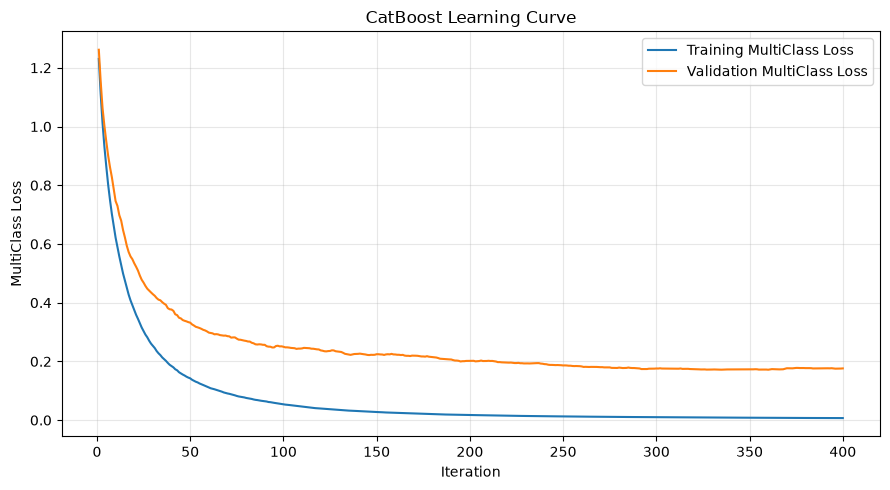


FINAL UNTOUCHED TEST EVALUATION

CLASSIFICATION REPORT

               precision    recall  f1-score   support

class_lecture     0.9995    0.8460    0.9164      7103
        music     0.8771    0.8916    0.8843      6257
       normal     0.8357    0.9029    0.8680      7569
      reading     0.8964    0.9505    0.9227      6264

     accuracy                         0.8964     27193
    macro avg     0.9022    0.8978    0.8978     27193
 weighted avg     0.9020    0.8964    0.8970     27193



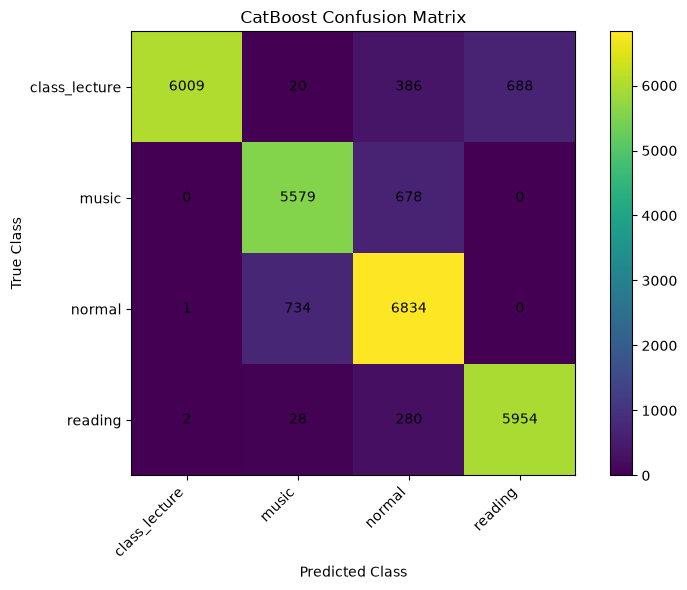

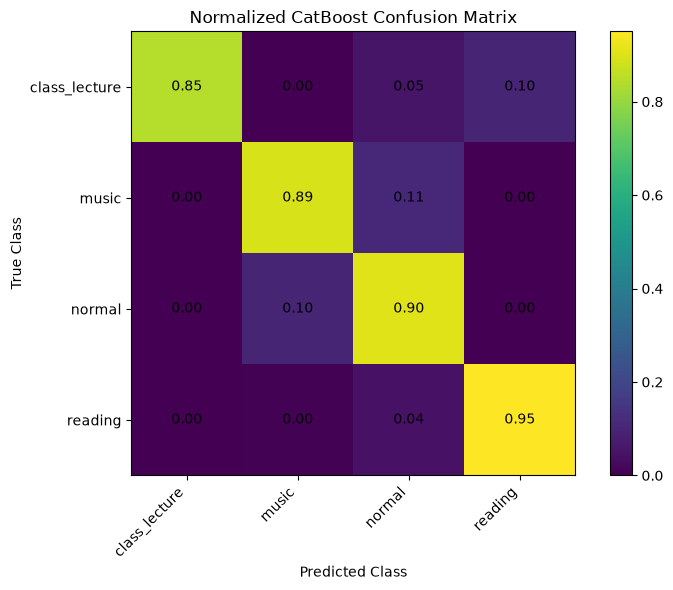


################################################################################
FINAL CATBOOST RESULTS
MAX DATASET
################################################################################
Features                  : 232
Best Optuna GKF           : 0.8799
Selected Run              : 4
Selected Iterations       : 353

Training Accuracy         : 0.9991
Validation Accuracy       : 0.9299
Testing Accuracy          : 0.8964

GroupKFold                : 0.8746 plus or minus 0.0220
Full LOGO                 : 0.8949 plus or minus 0.1457
Full LOGO Folds           : 42

Precision Weighted        : 0.9020
Recall Weighted           : 0.8964
F1 Weighted               : 0.8970
F1 Macro                  : 0.8978
Cohen Kappa               : 0.8616
MCC                       : 0.8629
ROC AUC Weighted OVR      : 0.9856

Optuna Time               : 32.34 minutes
Five Run Time             : 5.64 minutes
Full LOGO Time            : 13.79 minutes
Learning Curve Time       : 0.37 minutes
Total Exec

In [11]:
# ================================================================
# CATBOOST
# MAX DATASET
#
# FULL DATASET
# PERSON WISE 70 / 20 / 10
# GROUPKFOLD 5
# OPTUNA 12 TRIALS
# FIVE CATBOOST RUNS
# FULL LEAVE ONE GROUP OUT
# NO LOGO CAP
# NO DATA SUBSAMPLING
#
# COMPLETE METRICS
# CONFUSION MATRIX
# NORMALIZED CONFUSION MATRIX
# LEARNING CURVE
# AUTOMATIC RESULT SAVING
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import json
import time
import random
import warnings

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

from catboost import (
    CatBoostClassifier
)

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.utils.class_weight import (
    compute_sample_weight
)


# ================================================================
# GLOBAL CONFIGURATION
# ================================================================

SEED = 42

N_TRIALS = 12

N_RUNS = 5

GROUP_K_FOLDS = 5

OPTUNA_ITERATIONS = 800

FINAL_MAX_ITERATIONS = 1500

OPTUNA_EARLY_STOPPING = 30

FINAL_EARLY_STOPPING = 40

LEARNING_CURVE_ITERATIONS = 400


# Limit CPU usage to protect RAM and VS Code

N_JOBS = max(
    1,
    min(
        8,
        os.cpu_count() or 1
    )
)


random.seed(
    SEED
)

np.random.seed(
    SEED
)


warnings.filterwarnings(
    "ignore"
)


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ================================================================
# MEMORY MONITOR
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# INPUT
# ================================================================

FILE_PATH = Path(

    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"

)


if not FILE_PATH.exists():

    raise FileNotFoundError(

        f"Input file not found: "
        f"{FILE_PATH}"

    )


# ================================================================
# OUTPUT
# ================================================================

OUTPUT_DIR = (

    FILE_PATH.parent
    / "Max_Dataset_CatBoost_Results"

)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


# ================================================================
# TOTAL TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# EXPERIMENT INFORMATION
# ================================================================

print("=" * 80)

print(
    "CATBOOST CLASSIFICATION"
)

print(
    "MAX DATASET"
)

print("=" * 80)


print(
    "Input file:"
)

print(
    FILE_PATH
)


print()

print(
    "Output directory:"
)

print(
    OUTPUT_DIR
)


print()

print(
    "CatBoost device: CPU"
)


print(
    "CPU workers:",
    N_JOBS
)


print(
    "Optuna trials:",
    N_TRIALS
)


print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)


print(
    "Final runs:",
    N_RUNS
)


print(
    "LOGO cap: NONE"
)


print(
    "Data subsampling: NONE"
)


print("=" * 80)


# ================================================================
# LOAD COMPLETE DATASET
# ================================================================

print()

print("=" * 80)

print(
    "LOADING COMPLETE MAX DATASET"
)

print("=" * 80)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMN DEFINITIONS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


if len(feature_cols) == 0:

    raise ValueError(

        "No feature columns were found."

    )


print(
    "Feature count:",
    len(
        feature_cols
    )
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(

        pd.to_numeric,

        errors="coerce"

    )

    .to_numpy(

        dtype=np.float32

    )

)


# ================================================================
# INVALID VALUE CHECK
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "The feature matrix contains "
        "NaN or infinite values."

    )


# ================================================================
# LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(

    np.int32

)


class_names = list(

    label_encoder.classes_

)


NUM_CLASSES = len(

    class_names

)


# ================================================================
# PARTICIPANT GROUPS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Classes:",
    class_names
)


print(
    "Number of classes:",
    NUM_CLASSES
)


print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

print()

print(
    "CLASS DISTRIBUTION"
)


class_distribution_records = []


for class_index, class_name in enumerate(

    class_names

):

    count = int(

        np.sum(

            y_all
            == class_index

        )

    )


    percentage = (

        count
        / len(
            y_all
        )
        * 100.0

    )


    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


    class_distribution_records.append(

        {

            "Class":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage

        }

    )


pd.DataFrame(

    class_distribution_records

).to_csv(

    OUTPUT_DIR
    / "class_distribution.csv",

    index=False

)


print()

print(
    "Loading time:",
    f"{time.time() - load_start:.2f} seconds"
)


print(
    "Current RAM:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# RELEASE DATAFRAME
# ================================================================

del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10 SPLIT
# ================================================================

print()

print("=" * 80)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 80)


persons = np.unique(

    groups_all

)


rng = np.random.RandomState(

    SEED

)


rng.shuffle(

    persons

)


number_persons = len(

    persons

)


number_test = max(

    1,

    int(

        round(

            0.20
            * number_persons

        )

    )

)


number_validation = max(

    1,

    int(

        round(

            0.10
            * number_persons

        )

    )

)


# ================================================================
# PARTICIPANT SPLIT
# ================================================================

test_persons = persons[

    :number_test

]


validation_persons = persons[

    number_test:
    number_test
    + number_validation

]


train_persons = persons[

    number_test
    + number_validation:

]


# ================================================================
# MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY PARTICIPANT INDEPENDENCE
# ================================================================

assert (

    np.intersect1d(

        train_persons,

        validation_persons

    ).size == 0

)


assert (

    np.intersect1d(

        train_persons,

        test_persons

    ).size == 0

)


assert (

    np.intersect1d(

        validation_persons,

        test_persons

    ).size == 0

)


# ================================================================
# CREATE DATA SPLITS
# ================================================================

X_train_raw = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation_raw = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


g_validation = np.ascontiguousarray(

    groups_all[
        validation_mask
    ]

)


X_test_raw = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


g_test = np.ascontiguousarray(

    groups_all[
        test_mask
    ]

)


print(
    "Training participants:",
    len(
        train_persons
    )
)


print(
    "Validation participants:",
    len(
        validation_persons
    )
)


print(
    "Testing participants:",
    len(
        test_persons
    )
)


print()

print(
    "Training rows:",
    len(
        X_train_raw
    )
)


print(
    "Validation rows:",
    len(
        X_validation_raw
    )
)


print(
    "Testing rows:",
    len(
        X_test_raw
    )
)


# ================================================================
# SAVE SPLIT INFORMATION
# ================================================================

split_table = pd.DataFrame(

    [

        {

            "Split":
                "Training",

            "Participants":
                len(
                    train_persons
                ),

            "Rows":
                len(
                    X_train_raw
                )

        },

        {

            "Split":
                "Validation",

            "Participants":
                len(
                    validation_persons
                ),

            "Rows":
                len(
                    X_validation_raw
                )

        },

        {

            "Split":
                "Testing",

            "Participants":
                len(
                    test_persons
                ),

            "Rows":
                len(
                    X_test_raw
                )

        }

    ]

)


split_table.to_csv(

    OUTPUT_DIR
    / "split_summary.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "participant_split.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "training":

                [
                    str(x)
                    for x in train_persons
                ],

            "validation":

                [
                    str(x)
                    for x in validation_persons
                ],

            "testing":

                [
                    str(x)
                    for x in test_persons
                ]

        },

        file,

        indent=4

    )


# ================================================================
# RELEASE COMPLETE ARRAYS
# ================================================================

del X_all

del y_all

del groups_all

del train_mask

del validation_mask

del test_mask

gc.collect()


print()

print(
    "RAM after split:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# CROSS VALIDATION SCHEMES
# ================================================================

group_kfold = GroupKFold(

    n_splits=GROUP_K_FOLDS

)


gkf_splits = list(

    group_kfold.split(

        X_train_raw,

        y_train,

        g_train

    )

)


logo = LeaveOneGroupOut()


logo_splits = list(

    logo.split(

        X_train_raw,

        y_train,

        g_train

    )

)


print()

print(
    "GroupKFold folds:",
    len(
        gkf_splits
    )
)


print(
    "FULL LOGO folds:",
    len(
        logo_splits
    )
)


# ================================================================
# FOLD SPECIFIC STANDARDIZATION
#
# The Med code standardized before cross validation.
#
# Here each fold receives its own scaler to prevent
# validation information from entering the training scaler.
# ================================================================

def prepare_fold(

    train_index,

    validation_index

):

    scaler = StandardScaler()


    X_fold_train = scaler.fit_transform(

        X_train_raw[
            train_index
        ]

    ).astype(

        np.float32

    )


    X_fold_validation = scaler.transform(

        X_train_raw[
            validation_index
        ]

    ).astype(

        np.float32

    )


    return (

        np.ascontiguousarray(
            X_fold_train
        ),

        np.ascontiguousarray(
            X_fold_validation
        )

    )


# ================================================================
# CATBOOST DEVICE PARAMETERS
#
# CPU is intentionally used.
# ================================================================

def cat_device_params():

    return {

        "task_type":
            "CPU",

        "thread_count":
            N_JOBS,

        "allow_writing_files":
            False,

        "verbose":
            False

    }


# ================================================================
# CATBOOST PARAMETER BUILDER
# ================================================================

def make_cat_params(

    tuned_params,

    iterations,

    seed

):

    params = {

        "iterations":
            int(
                iterations
            ),

        "learning_rate":

            float(
                tuned_params[
                    "learning_rate"
                ]
            ),

        "depth":

            int(
                tuned_params[
                    "depth"
                ]
            ),

        "l2_leaf_reg":

            float(
                tuned_params[
                    "l2_leaf_reg"
                ]
            ),

        "bagging_temperature":

            float(
                tuned_params[
                    "bagging_temperature"
                ]
            ),

        "random_strength":

            float(
                tuned_params[
                    "random_strength"
                ]
            ),

        "border_count":

            int(
                tuned_params[
                    "border_count"
                ]
            ),

        "loss_function":
            "MultiClass",

        "eval_metric":
            "MultiClass",

        "random_seed":
            int(
                seed
            ),

        **cat_device_params()

    }


    return params


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def cat_objective(

    trial

):

    tuned_params = {

        "learning_rate":

            trial.suggest_float(

                "learning_rate",

                0.02,

                0.10,

                log=True

            ),

        "depth":

            trial.suggest_int(

                "depth",

                4,

                8

            ),

        "l2_leaf_reg":

            trial.suggest_float(

                "l2_leaf_reg",

                1.0,

                20.0,

                log=True

            ),

        "bagging_temperature":

            trial.suggest_float(

                "bagging_temperature",

                0.0,

                1.5

            ),

        "random_strength":

            trial.suggest_float(

                "random_strength",

                0.5,

                3.0

            ),

        "border_count":

            trial.suggest_int(

                "border_count",

                64,

                200

            )

    }


    params = make_cat_params(

        tuned_params,

        OPTUNA_ITERATIONS,

        SEED

    )


    fold_scores = []


    print()

    print(

        f"Trial "
        f"{trial.number + 1}/"
        f"{N_TRIALS}"

    )


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        # ========================================================
        # FOLD SPECIFIC SCALING
        # ========================================================

        (

            X_fold_train,

            X_fold_validation

        ) = prepare_fold(

            train_index,

            validation_index

        )


        # ========================================================
        # CLASS WEIGHTS
        # ========================================================

        sample_weight = compute_sample_weight(

            "balanced",

            y_train[
                train_index
            ]

        )


        # ========================================================
        # MODEL
        # ========================================================

        model = CatBoostClassifier(

            **params

        )


        model.fit(

            X_fold_train,

            y_train[
                train_index
            ],

            sample_weight=
                sample_weight,

            eval_set=(

                X_fold_validation,

                y_train[
                    validation_index
                ]

            ),

            early_stopping_rounds=
                OPTUNA_EARLY_STOPPING,

            use_best_model=True,

            verbose=False

        )


        prediction = (

            model.predict(

                X_fold_validation

            )

            .astype(
                np.int32
            )

            .ravel()

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        fold_scores.append(

            fold_accuracy

        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Best iteration = "
            f"{model.get_best_iteration()}, "

            f"Time = "
            f"{time.time() - fold_start:.2f} sec"

        )


        del model

        del prediction

        del sample_weight

        del X_fold_train

        del X_fold_validation


        gc.collect()


    mean_accuracy = float(

        np.mean(
            fold_scores
        )

    )


    std_accuracy = float(

        np.std(
            fold_scores
        )

    )


    print(

        f"Trial "
        f"{trial.number + 1} "

        f"Mean Accuracy = "
        f"{mean_accuracy:.4f} "

        f"plus or minus "
        f"{std_accuracy:.4f}"

    )


    return mean_accuracy


# ================================================================
# RUN OPTUNA
# ================================================================

print()

print("=" * 80)

print(
    f"CATBOOST OPTUNA: "
    f"{N_TRIALS} TRIALS"
)

print(
    f"ALL "
    f"{GROUP_K_FOLDS} "
    f"GROUPKFOLD FOLDS"
)

print("=" * 80)


optuna_start = time.time()


study = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(

        seed=SEED

    )

)


study.optimize(

    cat_objective,

    n_trials=N_TRIALS,

    show_progress_bar=False

)


optuna_time = (

    time.time()
    - optuna_start

)


best_tuned_params = (

    study.best_params.copy()

)


print()

print("=" * 80)

print(
    "OPTUNA COMPLETED"
)

print("=" * 80)


print(
    "Best GroupKFold Accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Best Parameters:"
)


print(
    best_tuned_params
)


print(
    "Optuna Time:",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


# ================================================================
# SAVE OPTUNA RESULTS
# ================================================================

study.trials_dataframe().to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        best_tuned_params,

        file,

        indent=4

    )


# ================================================================
# FINAL STANDARDIZATION
#
# Fit only on 70 percent training participants.
# ================================================================

print()

print("=" * 80)

print(
    "FINAL STANDARDIZATION"
)

print("=" * 80)


final_scaler = StandardScaler()


X_train = final_scaler.fit_transform(

    X_train_raw

).astype(

    np.float32

)


X_validation = final_scaler.transform(

    X_validation_raw

).astype(

    np.float32

)


X_test = final_scaler.transform(

    X_test_raw

).astype(

    np.float32

)


X_train = np.ascontiguousarray(

    X_train

)


X_validation = np.ascontiguousarray(

    X_validation

)


X_test = np.ascontiguousarray(

    X_test

)


print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


print(
    "RAM:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# SAVE PREPROCESSING
# ================================================================

joblib.dump(

    final_scaler,

    OUTPUT_DIR
    / "standard_scaler.joblib"

)


joblib.dump(

    label_encoder,

    OUTPUT_DIR
    / "label_encoder.joblib"

)


with open(

    OUTPUT_DIR
    / "feature_columns.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        feature_cols,

        file,

        indent=4

    )


# ================================================================
# FIVE CATBOOST RUNS
#
# Test set is not used here.
#
# Validation set is used for early stopping
# and selecting the best run.
# ================================================================

print()

print("=" * 80)

print(
    f"CATBOOST: "
    f"{N_RUNS} FINAL RUNS"
)

print("=" * 80)


run_records = []


best_model = None


best_record = None


best_validation_accuracy = (

    float("-inf")

)


five_run_start = time.time()


for run_number in range(

    1,

    N_RUNS + 1

):

    run_start = time.time()


    run_seed = (

        SEED
        + run_number
        - 1

    )


    params = make_cat_params(

        best_tuned_params,

        FINAL_MAX_ITERATIONS,

        run_seed

    )


    # ============================================================
    # GROUPKFOLD FOR THIS RUN
    # ============================================================

    cv_scores = []


    cv_best_iterations = []


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        (

            X_fold_train,

            X_fold_validation

        ) = prepare_fold(

            train_index,

            validation_index

        )


        sample_weight = compute_sample_weight(

            "balanced",

            y_train[
                train_index
            ]

        )


        fold_model = CatBoostClassifier(

            **params

        )


        fold_model.fit(

            X_fold_train,

            y_train[
                train_index
            ],

            sample_weight=
                sample_weight,

            eval_set=(

                X_fold_validation,

                y_train[
                    validation_index
                ]

            ),

            early_stopping_rounds=
                OPTUNA_EARLY_STOPPING,

            use_best_model=True,

            verbose=False

        )


        fold_prediction = (

            fold_model.predict(

                X_fold_validation

            )

            .astype(
                np.int32
            )

            .ravel()

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            fold_prediction

        )


        cv_scores.append(

            fold_accuracy

        )


        fold_best_iteration = (

            fold_model.get_best_iteration()

        )


        if fold_best_iteration >= 0:

            cv_best_iterations.append(

                fold_best_iteration
                + 1

            )


        print(

            f"Run "
            f"{run_number}/"
            f"{N_RUNS}, "

            f"GKF "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}"

        )


        del fold_model

        del fold_prediction

        del sample_weight

        del X_fold_train

        del X_fold_validation


        gc.collect()


    # ============================================================
    # FULL TRAINING
    #
    # Validation set is used for early stopping.
    # ============================================================

    sample_weight = compute_sample_weight(

        "balanced",

        y_train

    )


    model = CatBoostClassifier(

        **params

    )


    model.fit(

        X_train,

        y_train,

        sample_weight=
            sample_weight,

        eval_set=(

            X_validation,

            y_validation

        ),

        early_stopping_rounds=
            FINAL_EARLY_STOPPING,

        use_best_model=True,

        verbose=False

    )


    # ============================================================
    # TRAIN PREDICTIONS
    # ============================================================

    train_prediction = (

        model.predict(

            X_train

        )

        .astype(
            np.int32
        )

        .ravel()

    )


    train_accuracy = accuracy_score(

        y_train,

        train_prediction

    )


    # ============================================================
    # VALIDATION PREDICTIONS
    # ============================================================

    validation_probability = (

        model.predict_proba(

            X_validation

        )

    )


    validation_prediction = np.argmax(

        validation_probability,

        axis=1

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    best_iteration = (

        model.get_best_iteration()

    )


    if best_iteration < 0:

        best_iteration = (

            FINAL_MAX_ITERATIONS
            - 1

        )


    fixed_iterations = (

        best_iteration
        + 1

    )


    run_time = (

        time.time()
        - run_start

    )


    record = {

        "Run":
            run_number,

        "Training_Accuracy":
            float(
                train_accuracy
            ),

        "Validation_Accuracy":
            float(
                validation_accuracy
            ),

        "GroupKFold_Accuracy":
            float(
                np.mean(
                    cv_scores
                )
            ),

        "GroupKFold_STD":
            float(
                np.std(
                    cv_scores
                )
            ),

        "Best_Iteration":
            int(
                fixed_iterations
            ),

        "Execution_Time_Seconds":
            float(
                run_time
            )

    }


    run_records.append(

        record

    )


    print()

    print(

        f"[CAT {run_number}] "

        f"Train = "
        f"{train_accuracy:.4f}, "

        f"Validation = "
        f"{validation_accuracy:.4f}, "

        f"GKF = "
        f"{record['GroupKFold_Accuracy']:.4f} "

        f"plus or minus "
        f"{record['GroupKFold_STD']:.4f}, "

        f"Best Iteration = "
        f"{fixed_iterations}, "

        f"Time = "
        f"{run_time:.2f} sec"

    )


    # ============================================================
    # SELECT BEST MODEL USING VALIDATION ONLY
    # ============================================================

    if (

        validation_accuracy
        > best_validation_accuracy

    ):

        if best_model is not None:

            del best_model


        best_model = model


        best_record = (

            record.copy()

        )


        best_validation_accuracy = (

            validation_accuracy

        )


    else:

        del model


    del train_prediction

    del validation_probability

    del validation_prediction

    del sample_weight


    gc.collect()


five_run_time = (

    time.time()
    - five_run_start

)


run_table = pd.DataFrame(

    run_records

)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()

print(
    run_table
    .round(4)
    .to_string(
        index=False
    )
)


print()

print(
    "Selected Run:",
    best_record[
        "Run"
    ]
)


print(
    "Selected Validation Accuracy:",
    f"{best_validation_accuracy:.4f}"
)


print(
    "Selected Iterations:",
    best_record[
        "Best_Iteration"
    ]
)


# ================================================================
# SAVE BEST CATBOOST MODEL
# ================================================================

MODEL_PATH = (

    OUTPUT_DIR
    / "catboost_best_model.cbm"

)


best_model.save_model(

    str(
        MODEL_PATH
    )

)


# ================================================================
# FULL LEAVE ONE GROUP OUT
#
# Fixed iterations are used.
#
# The held out participant is not used
# for early stopping.
# ================================================================

print()

print("=" * 80)

print(
    "FULL LEAVE ONE GROUP OUT"
)

print(
    "Total LOGO folds:",
    len(
        logo_splits
    )
)

print(
    "LOGO cap: NONE"
)

print("=" * 80)


logo_start = time.time()


logo_records = []


logo_scores = []


logo_iterations = int(

    best_record[
        "Best_Iteration"
    ]

)


logo_params = make_cat_params(

    best_tuned_params,

    logo_iterations,

    SEED

)


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    logo_splits,

    start=1

):

    fold_start = time.time()


    # ============================================================
    # FOLD SPECIFIC SCALER
    # ============================================================

    (

        X_fold_train,

        X_fold_validation

    ) = prepare_fold(

        train_index,

        validation_index

    )


    sample_weight = compute_sample_weight(

        "balanced",

        y_train[
            train_index
        ]

    )


    model = CatBoostClassifier(

        **logo_params

    )


    # ============================================================
    # IMPORTANT
    #
    # No LOGO validation set is used for early stopping.
    # Fixed iterations are used.
    # ============================================================

    model.fit(

        X_fold_train,

        y_train[
            train_index
        ],

        sample_weight=
            sample_weight,

        verbose=False

    )


    prediction = (

        model.predict(

            X_fold_validation

        )

        .astype(
            np.int32
        )

        .ravel()

    )


    fold_accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    held_out_persons = np.unique(

        g_train[
            validation_index
        ]

    )


    if len(
        held_out_persons
    ) != 1:

        raise RuntimeError(

            "Unexpected number of "
            "held out participants "
            "inside a LOGO fold."

        )


    held_out_person = (

        held_out_persons[
            0
        ]

    )


    fold_time = (

        time.time()
        - fold_start

    )


    logo_scores.append(

        fold_accuracy

    )


    logo_records.append(

        {

            "Fold":
                fold_number,

            "Held_Out_Person":
                str(
                    held_out_person
                ),

            "Rows":
                int(
                    len(
                        validation_index
                    )
                ),

            "Accuracy":
                float(
                    fold_accuracy
                ),

            "Execution_Time_Seconds":
                float(
                    fold_time
                )

        }

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "

        f"Participant = "
        f"{held_out_person}, "

        f"Accuracy = "
        f"{fold_accuracy:.4f}, "

        f"Time = "
        f"{fold_time:.2f} sec"

    )


    del model

    del prediction

    del sample_weight

    del X_fold_train

    del X_fold_validation


    gc.collect()


logo_time = (

    time.time()
    - logo_start

)


logo_mean = float(

    np.mean(
        logo_scores
    )

)


logo_std = float(

    np.std(
        logo_scores
    )

)


logo_table = pd.DataFrame(

    logo_records

)


logo_table.to_csv(

    OUTPUT_DIR
    / "full_logo_results.csv",

    index=False

)


print()

print(
    "FULL LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "FULL LOGO folds:",
    len(
        logo_scores
    )
)


print(
    "FULL LOGO time:",
    f"{logo_time / 60:.2f}",
    "minutes"
)


# ================================================================
# CATBOOST LEARNING CURVE
#
# Uses training and validation participants.
#
# Test set remains untouched.
# ================================================================

print()

print("=" * 80)

print(
    "CATBOOST LEARNING CURVE"
)

print("=" * 80)


learning_params = make_cat_params(

    best_tuned_params,

    LEARNING_CURVE_ITERATIONS,

    SEED

)


learning_weight = compute_sample_weight(

    "balanced",

    y_train

)


learning_model = CatBoostClassifier(

    **learning_params

)


learning_start = time.time()


learning_model.fit(

    X_train,

    y_train,

    sample_weight=
        learning_weight,

    eval_set=(

        X_validation,

        y_validation

    ),

    use_best_model=False,

    verbose=False

)


learning_time = (

    time.time()
    - learning_start

)


evals = (

    learning_model
    .get_evals_result()

)


train_curve = (

    evals[
        "learn"
    ][
        "MultiClass"
    ]

)


validation_keys = [

    key

    for key in evals.keys()

    if key != "learn"

]


if len(
    validation_keys
) == 0:

    raise RuntimeError(

        "CatBoost validation "
        "learning curve was not generated."

    )


validation_key = (

    validation_keys[
        0
    ]

)


validation_curve = (

    evals[
        validation_key
    ][
        "MultiClass"
    ]

)


learning_curve_table = pd.DataFrame(

    {

        "Iteration":

            np.arange(

                1,

                len(
                    train_curve
                )
                + 1

            ),

        "Training_MultiClass_Loss":

            train_curve,

        "Validation_MultiClass_Loss":

            validation_curve

    }

)


learning_curve_table.to_csv(

    OUTPUT_DIR
    / "learning_curve.csv",

    index=False

)


fig, ax = plt.subplots(

    figsize=(9, 5)

)


ax.plot(

    learning_curve_table[
        "Iteration"
    ],

    learning_curve_table[
        "Training_MultiClass_Loss"
    ],

    label=
        "Training MultiClass Loss"

)


ax.plot(

    learning_curve_table[
        "Iteration"
    ],

    learning_curve_table[
        "Validation_MultiClass_Loss"
    ],

    label=
        "Validation MultiClass Loss"

)


ax.set_xlabel(

    "Iteration"

)


ax.set_ylabel(

    "MultiClass Loss"

)


ax.set_title(

    "CatBoost Learning Curve"

)


ax.legend()


ax.grid(

    alpha=0.3

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "learning_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


del learning_model

del learning_weight

gc.collect()


# ================================================================
# FINAL UNTOUCHED TEST EVALUATION
# ================================================================

print()

print("=" * 80)

print(
    "FINAL UNTOUCHED TEST EVALUATION"
)

print("=" * 80)


test_start = time.time()


test_probability = (

    best_model.predict_proba(

        X_test

    )

)


test_prediction = np.argmax(

    test_probability,

    axis=1

)


test_prediction_time = (

    time.time()
    - test_start

)


# ================================================================
# TRAIN ACCURACY FROM SELECTED RUN
# ================================================================

train_accuracy = float(

    best_record[
        "Training_Accuracy"
    ]

)


validation_accuracy = float(

    best_record[
        "Validation_Accuracy"
    ]

)


# ================================================================
# TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average="macro",

    zero_division=0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


# ================================================================
# ROC AUC
# ================================================================

try:

    test_roc_auc = roc_auc_score(

        y_test,

        test_probability,

        multi_class="ovr",

        average="weighted"

    )


except Exception:

    test_roc_auc = np.nan


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    ),

    target_names=class_names,

    digits=4,

    zero_division=0

)


print()

print(
    "CLASSIFICATION REPORT"
)


print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(

        report

    )


report_table = pd.DataFrame(

    classification_report(

        y_test,

        test_prediction,

        labels=np.arange(
            NUM_CLASSES
        ),

        target_names=class_names,

        output_dict=True,

        zero_division=0

    )

).transpose()


report_table.to_csv(

    OUTPUT_DIR
    / "classification_report.csv"

)


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    )

)


cm_table = pd.DataFrame(

    cm,

    index=class_names,

    columns=class_names

)


cm_table.to_csv(

    OUTPUT_DIR
    / "confusion_matrix.csv"

)


# ================================================================
# CONFUSION MATRIX VISUALIZATION
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(

    cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "CatBoost Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            str(

                cm[
                    row,
                    column
                ]

            ),

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(

    axis=1,

    keepdims=True

)


normalized_cm = np.divide(

    cm,

    row_sums,

    out=np.zeros_like(

        cm,

        dtype=np.float64

    ),

    where=(

        row_sums != 0

    )

)


pd.DataFrame(

    normalized_cm,

    index=class_names,

    columns=class_names

).to_csv(

    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"

)


# ================================================================
# NORMALIZED MATRIX VISUALIZATION
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(

    normalized_cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "Normalized CatBoost Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            f"{normalized_cm[row, column]:.2f}",

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "normalized_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {

        "PersonSrial":

            g_test,

        "True_Class":

            label_encoder.inverse_transform(

                y_test

            ),

        "Predicted_Class":

            label_encoder.inverse_transform(

                test_prediction.astype(
                    np.int32
                )

            )

    }

)


for class_index, class_name in enumerate(

    class_names

):

    prediction_table[

        f"Probability_{class_name}"

    ] = test_probability[

        :,

        class_index

    ]


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# FIVE RUN STATISTICS
# ================================================================

run_train_mean = float(

    run_table[
        "Training_Accuracy"
    ].mean()

)


run_train_std = float(

    run_table[
        "Training_Accuracy"
    ].std(
        ddof=0
    )

)


run_validation_mean = float(

    run_table[
        "Validation_Accuracy"
    ].mean()

)


run_validation_std = float(

    run_table[
        "Validation_Accuracy"
    ].std(
        ddof=0
    )

)


run_cv_mean = float(

    run_table[
        "GroupKFold_Accuracy"
    ].mean()

)


run_cv_std = float(

    run_table[
        "GroupKFold_Accuracy"
    ].std(
        ddof=0
    )

)


# ================================================================
# TOTAL TIME
# ================================================================

total_execution_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {

    "Algorithm":

        "CatBoost",

    "Dataset":

        "Max Dataset",

    "Input_File":

        str(
            FILE_PATH
        ),

    "Output_Directory":

        str(
            OUTPUT_DIR
        ),

    "Device":

        "CPU",

    "CPU_Workers":

        int(
            N_JOBS
        ),

    "Feature_Count":

        int(
            len(
                feature_cols
            )
        ),

    "Number_of_Classes":

        int(
            NUM_CLASSES
        ),

    "Classes":

        class_names,

    "Training_Participants":

        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":

        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":

        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":

        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":

        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":

        int(
            len(
                X_test
            )
        ),

    "Optuna_Trials":

        int(
            N_TRIALS
        ),

    "Best_Optuna_GroupKFold_Accuracy":

        float(
            study.best_value
        ),

    "Best_Parameters":

        best_tuned_params,

    "Selected_Run":

        int(
            best_record[
                "Run"
            ]
        ),

    "Selected_Iterations":

        int(
            best_record[
                "Best_Iteration"
            ]
        ),

    "Training_Accuracy":

        float(
            train_accuracy
        ),

    "Validation_Accuracy":

        float(
            validation_accuracy
        ),

    "Testing_Accuracy":

        float(
            test_accuracy
        ),

    "Five_Run_Training_Mean":

        run_train_mean,

    "Five_Run_Training_STD":

        run_train_std,

    "Five_Run_Validation_Mean":

        run_validation_mean,

    "Five_Run_Validation_STD":

        run_validation_std,

    "Five_Run_GroupKFold_Mean":

        run_cv_mean,

    "Five_Run_GroupKFold_STD":

        run_cv_std,

    "Full_LOGO_Accuracy":

        float(
            logo_mean
        ),

    "Full_LOGO_STD":

        float(
            logo_std
        ),

    "Full_LOGO_Folds":

        int(
            len(
                logo_splits
            )
        ),

    "Precision_Weighted":

        float(
            test_precision
        ),

    "Recall_Weighted":

        float(
            test_recall
        ),

    "F1_Weighted":

        float(
            test_f1_weighted
        ),

    "F1_Macro":

        float(
            test_f1_macro
        ),

    "Cohen_Kappa":

        float(
            test_kappa
        ),

    "MCC":

        float(
            test_mcc
        ),

    "ROC_AUC_Weighted_OVR":

        None

        if np.isnan(
            test_roc_auc
        )

        else float(
            test_roc_auc
        ),

    "Optuna_Time_Seconds":

        float(
            optuna_time
        ),

    "Five_Run_Time_Seconds":

        float(
            five_run_time
        ),

    "Full_LOGO_Time_Seconds":

        float(
            logo_time
        ),

    "Learning_Curve_Time_Seconds":

        float(
            learning_time
        ),

    "Test_Prediction_Time_Seconds":

        float(
            test_prediction_time
        ),

    "Total_Execution_Time_Seconds":

        float(
            total_execution_time
        ),

    "Current_RAM_MB":

        float(
            mem_mb()
        )

}


with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=4

    )


# ================================================================
# FINAL SUMMARY TEXT
# ================================================================

summary_lines = [

    "CATBOOST",
    "MAX DATASET",

    "",

    f"Input File: {FILE_PATH}",

    f"Output Directory: {OUTPUT_DIR}",

    "",

    f"Features: {len(feature_cols)}",

    f"Classes: {class_names}",

    "",

    f"Training Participants: {len(train_persons)}",

    f"Validation Participants: {len(validation_persons)}",

    f"Testing Participants: {len(test_persons)}",

    "",

    f"Best Optuna GroupKFold Accuracy: "
    f"{study.best_value:.4f}",

    f"Selected Run: "
    f"{best_record['Run']}",

    f"Selected Iterations: "
    f"{best_record['Best_Iteration']}",

    "",

    f"Training Accuracy: "
    f"{train_accuracy:.4f}",

    f"Validation Accuracy: "
    f"{validation_accuracy:.4f}",

    f"Testing Accuracy: "
    f"{test_accuracy:.4f}",

    "",

    f"Full LOGO Accuracy: "
    f"{logo_mean:.4f} "
    f"plus or minus "
    f"{logo_std:.4f}",

    f"Full LOGO Folds: "
    f"{len(logo_splits)}",

    "",

    f"Precision Weighted: "
    f"{test_precision:.4f}",

    f"Recall Weighted: "
    f"{test_recall:.4f}",

    f"F1 Weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 Macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    (
        "ROC AUC Weighted OVR: N/A"

        if np.isnan(
            test_roc_auc
        )

        else

        f"ROC AUC Weighted OVR: "
        f"{test_roc_auc:.4f}"
    ),

    "",

    f"Optuna Time: "
    f"{optuna_time / 60:.2f} minutes",

    f"Five Run Time: "
    f"{five_run_time / 60:.2f} minutes",

    f"Full LOGO Time: "
    f"{logo_time / 60:.2f} minutes",

    f"Learning Curve Time: "
    f"{learning_time / 60:.2f} minutes",

    f"Total Execution Time: "
    f"{total_execution_time / 60:.2f} minutes"

]


with open(

    OUTPUT_DIR
    / "final_summary.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(

        "\n".join(
            summary_lines
        )

    )


# ================================================================
# FINAL SCREEN OUTPUT
# ================================================================

print()

print("#" * 80)

print(
    "FINAL CATBOOST RESULTS"
)

print(
    "MAX DATASET"
)

print("#" * 80)


print(
    "Features                  :",
    len(
        feature_cols
    )
)


print(
    "Best Optuna GKF           :",
    f"{study.best_value:.4f}"
)


print(
    "Selected Run              :",
    best_record[
        "Run"
    ]
)


print(
    "Selected Iterations       :",
    best_record[
        "Best_Iteration"
    ]
)


print()

print(
    "Training Accuracy         :",
    f"{train_accuracy:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{validation_accuracy:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "GroupKFold                :",
    f"{best_record['GroupKFold_Accuracy']:.4f}",
    "plus or minus",
    f"{best_record['GroupKFold_STD']:.4f}"
)


print(
    "Full LOGO                 :",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "Full LOGO Folds           :",
    len(
        logo_splits
    )
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


if np.isnan(
    test_roc_auc
):

    print(
        "ROC AUC Weighted OVR      : N/A"
    )

else:

    print(
        "ROC AUC Weighted OVR      :",
        f"{test_roc_auc:.4f}"
    )


print()

print(
    "Optuna Time               :",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


print(
    "Five Run Time             :",
    f"{five_run_time / 60:.2f}",
    "minutes"
)


print(
    "Full LOGO Time            :",
    f"{logo_time / 60:.2f}",
    "minutes"
)


print(
    "Learning Curve Time       :",
    f"{learning_time / 60:.2f}",
    "minutes"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "No rows were subsampled."
)


print(
    "No LOGO folds were capped."
)


print(
    "All GroupKFold folds are "
    "participant independent."
)


print(
    "Test participants remained untouched "
    "until final evaluation."
)


print()

print(
    "ALL RESULTS SAVED IN:"
)


print(
    OUTPUT_DIR
)


print("#" * 80)

**Apply KNN on Max Dataset**

/home/rakib/Desktop/ml_apply/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


K NEAREST NEIGHBORS
MAX DATASET
Input file:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Cleaned_oN_Selected_Max.csv

Output directory:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Max_Dataset_KNN_Results

CPU workers: 8
KNN algorithm: auto
Optuna trials: 12
GroupKFold folds: 5
Final runs: 5
LOGO fold cap: 5
Data subsampling: NONE
Working memory: 512 MB

LOADING COMPLETE MAX DATASET
Raw dataset shape: (149350, 238)
RAM after loading: 488.82 MB
Feature count: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

Loading time: 8.07 seconds

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training: (107752, 232)
Validation: (14405, 232)
Testing: (27193, 232)
RAM after split: 355.70 MB

GroupKFold folds: 5
Availab

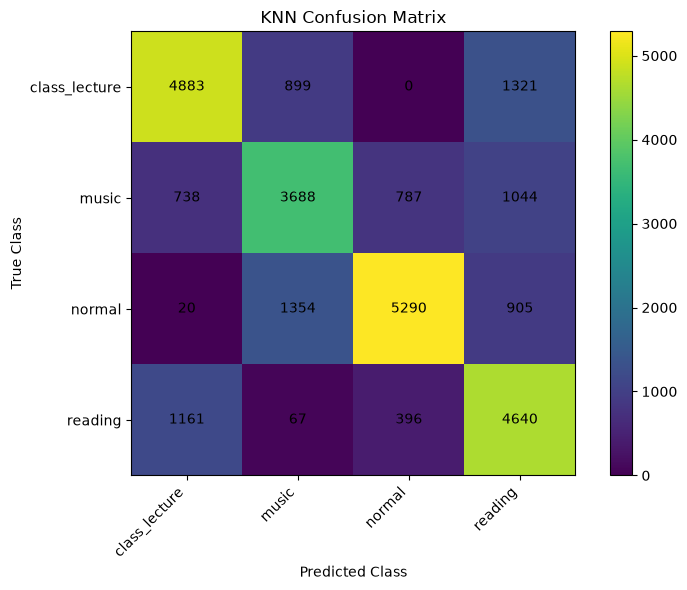

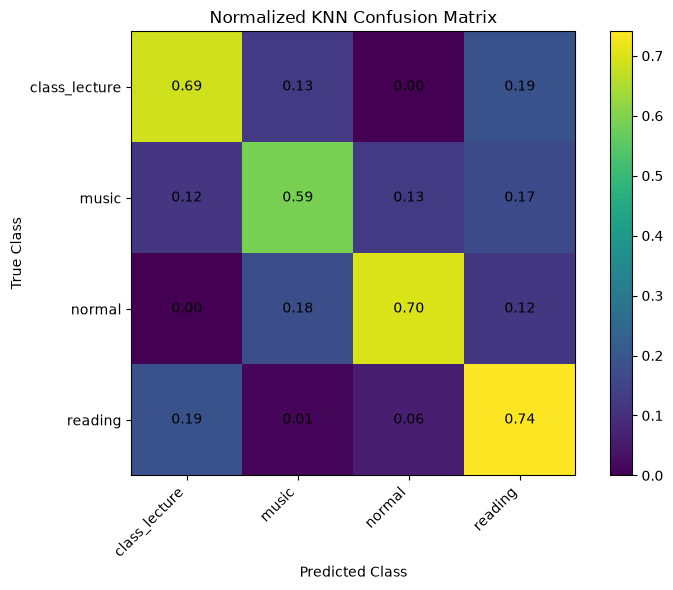


KNN LEARNING CURVE


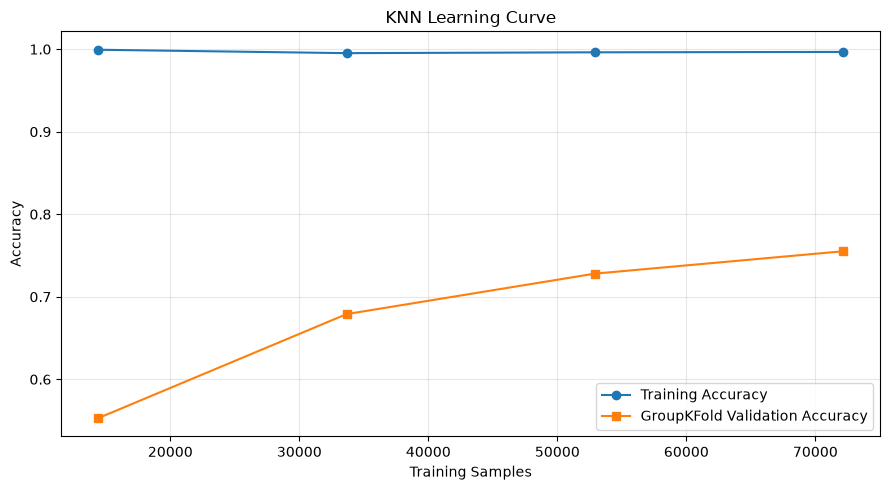

Learning Curve Time: 30.70 minutes

################################################################################
FINAL KNN RESULTS
MAX DATASET
################################################################################
Features                  : 232
Best k                    : 31
Best weights              : uniform
Best p                    : 1

Training Accuracy         : 0.9959
Validation Accuracy       : 0.8735
Testing Accuracy          : 0.6804

GroupKFold                : 0.7097 plus or minus 0.0590
LOGO Accuracy             : 0.7235 plus or minus 0.2182
LOGO Folds Used           : 5 of 42

Precision Weighted        : 0.6914
Recall Weighted           : 0.6804
F1 Weighted               : 0.6824
F1 Macro                  : 0.6780
Cohen Kappa               : 0.5741
MCC                       : 0.5762
ROC AUC Weighted OVR      : 0.8056

Optuna Time               : 56.93 minutes
Five Run Time             : 36.27 minutes
LOGO Time                 : 1.07 minutes
Learning Curve T

In [1]:
# ================================================================
# K NEAREST NEIGHBORS
# MAX DATASET
#
# PERSON WISE 70 / 20 / 10
# STANDARDIZATION
# OPTUNA 12 TRIALS
# GROUPKFOLD 5
# FIVE RUNS
# LOGO
# COMPLETE METRICS
# CONFUSION MATRIX
# NORMALIZED CONFUSION MATRIX
# GROUP AWARE LEARNING CURVE
#
# INPUT
# Cleaned_oN_Selected_Max.csv
#
# OUTPUT
# Max_Dataset_KNN_Results
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import json
import time
import random
import warnings

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

from sklearn import set_config

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut,
    learning_curve
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.pipeline import Pipeline

from sklearn.neighbors import (
    KNeighborsClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ================================================================
# GLOBAL CONFIGURATION
# ================================================================

SEED = 42

N_TRIALS = 12

N_RUNS = 5

GROUP_K_FOLDS = 5


# ================================================================
# LOGO CONFIGURATION
#
# The original Med code used only 5 LOGO folds because KNN
# prediction is computationally expensive.
#
# Keep 5 for the same process.
#
# For all 42 training participants change:
#
# LOGO_MAX_FOLDS = None
# ================================================================

LOGO_MAX_FOLDS = 5


# ================================================================
# KNN CONFIGURATION
# ================================================================

KNN_N_JOBS = max(
    1,
    min(
        8,
        os.cpu_count() or 1
    )
)


KNN_ALGORITHM = "auto"

KNN_LEAF_SIZE = 30


# ================================================================
# LIMIT TEMPORARY DISTANCE MEMORY
# ================================================================

set_config(
    working_memory=512
)


# ================================================================
# RANDOM SEEDS
# ================================================================

random.seed(
    SEED
)

np.random.seed(
    SEED
)


# ================================================================
# WARNINGS
# ================================================================

warnings.filterwarnings(
    "ignore"
)


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ================================================================
# MEMORY MONITOR
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# INPUT
# ================================================================

FILE_PATH = Path(

    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"

)


if not FILE_PATH.exists():

    raise FileNotFoundError(

        f"Input file not found: "
        f"{FILE_PATH}"

    )


# ================================================================
# OUTPUT
# ================================================================

OUTPUT_DIR = (

    FILE_PATH.parent
    / "Max_Dataset_KNN_Results"

)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


# ================================================================
# TOTAL TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# START INFORMATION
# ================================================================

print("=" * 80)

print(
    "K NEAREST NEIGHBORS"
)

print(
    "MAX DATASET"
)

print("=" * 80)


print(
    "Input file:"
)

print(
    FILE_PATH
)


print()

print(
    "Output directory:"
)

print(
    OUTPUT_DIR
)


print()

print(
    "CPU workers:",
    KNN_N_JOBS
)


print(
    "KNN algorithm:",
    KNN_ALGORITHM
)


print(
    "Optuna trials:",
    N_TRIALS
)


print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)


print(
    "Final runs:",
    N_RUNS
)


if LOGO_MAX_FOLDS is None:

    print(
        "LOGO fold cap: NONE"
    )

else:

    print(
        "LOGO fold cap:",
        LOGO_MAX_FOLDS
    )


print(
    "Data subsampling: NONE"
)


print(
    "Working memory:",
    "512 MB"
)


print("=" * 80)


# ================================================================
# LOAD COMPLETE DATASET
# ================================================================

print()

print("=" * 80)

print(
    "LOADING COMPLETE MAX DATASET"
)

print("=" * 80)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMN DEFINITIONS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


if len(feature_cols) == 0:

    raise ValueError(

        "No feature columns found."

    )


print(
    "Feature count:",
    len(
        feature_cols
    )
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(

        pd.to_numeric,

        errors="coerce"

    )

    .to_numpy(

        dtype=np.float32

    )

)


# ================================================================
# INVALID FEATURE CHECK
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "Feature matrix contains "
        "NaN or infinite values."

    )


# ================================================================
# LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(

    np.int32

)


class_names = list(

    label_encoder.classes_

)


NUM_CLASSES = len(

    class_names

)


# ================================================================
# PARTICIPANT GROUPS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Classes:",
    class_names
)


print(
    "Number of classes:",
    NUM_CLASSES
)


print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

class_distribution = []


print()

print(
    "CLASS DISTRIBUTION"
)


for class_index, class_name in enumerate(

    class_names

):

    count = int(

        np.sum(

            y_all == class_index

        )

    )


    percentage = (

        count
        / len(
            y_all
        )
        * 100.0

    )


    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


    class_distribution.append(

        {

            "Class":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage

        }

    )


pd.DataFrame(

    class_distribution

).to_csv(

    OUTPUT_DIR
    / "class_distribution.csv",

    index=False

)


print()

print(
    "Loading time:",
    f"{time.time() - load_start:.2f}",
    "seconds"
)


# ================================================================
# RELEASE DATAFRAME
# ================================================================

del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10
# ================================================================

print()

print("=" * 80)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 80)


persons = np.unique(

    groups_all

)


rng = np.random.RandomState(

    SEED

)


rng.shuffle(

    persons

)


number_persons = len(

    persons

)


number_test = max(

    1,

    int(

        round(

            0.20
            * number_persons

        )

    )

)


number_validation = max(

    1,

    int(

        round(

            0.10
            * number_persons

        )

    )

)


# ================================================================
# PARTICIPANT GROUPS
# ================================================================

test_persons = persons[

    :number_test

]


validation_persons = persons[

    number_test:
    number_test
    + number_validation

]


train_persons = persons[

    number_test
    + number_validation:

]


# ================================================================
# MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY ZERO PARTICIPANT OVERLAP
# ================================================================

assert (

    np.intersect1d(

        train_persons,

        validation_persons

    ).size == 0

)


assert (

    np.intersect1d(

        train_persons,

        test_persons

    ).size == 0

)


assert (

    np.intersect1d(

        validation_persons,

        test_persons

    ).size == 0

)


# ================================================================
# SPLIT ARRAYS
# ================================================================

X_train = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


g_validation = np.ascontiguousarray(

    groups_all[
        validation_mask
    ]

)


X_test = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


g_test = np.ascontiguousarray(

    groups_all[
        test_mask
    ]

)


print(
    "Training participants:",
    len(
        train_persons
    )
)


print(
    "Validation participants:",
    len(
        validation_persons
    )
)


print(
    "Testing participants:",
    len(
        test_persons
    )
)


print()

print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


# ================================================================
# SAVE SPLIT INFORMATION
# ================================================================

split_table = pd.DataFrame(

    [

        {

            "Split":
                "Training",

            "Participants":
                len(
                    train_persons
                ),

            "Rows":
                len(
                    X_train
                )

        },

        {

            "Split":
                "Validation",

            "Participants":
                len(
                    validation_persons
                ),

            "Rows":
                len(
                    X_validation
                )

        },

        {

            "Split":
                "Testing",

            "Participants":
                len(
                    test_persons
                ),

            "Rows":
                len(
                    X_test
                )

        }

    ]

)


split_table.to_csv(

    OUTPUT_DIR
    / "split_summary.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "participant_split.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "training":

                [
                    str(x)
                    for x
                    in train_persons
                ],

            "validation":

                [
                    str(x)
                    for x
                    in validation_persons
                ],

            "testing":

                [
                    str(x)
                    for x
                    in test_persons
                ]

        },

        file,

        indent=4

    )


# ================================================================
# RELEASE COMPLETE DATA
# ================================================================

del X_all
del y_all
del groups_all

del train_mask
del validation_mask
del test_mask

gc.collect()


print(
    "RAM after split:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# CROSS VALIDATION
# ================================================================

gkf_splits = list(

    GroupKFold(

        n_splits=GROUP_K_FOLDS

    ).split(

        X_train,

        y_train,

        g_train

    )

)


logo_splits_full = list(

    LeaveOneGroupOut().split(

        X_train,

        y_train,

        g_train

    )

)


if LOGO_MAX_FOLDS is None:

    logo_splits = (

        logo_splits_full

    )

else:

    logo_splits = (

        logo_splits_full[
            :LOGO_MAX_FOLDS
        ]

    )


print()

print(
    "GroupKFold folds:",
    len(
        gkf_splits
    )
)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


# ================================================================
# KNN PIPELINE
#
# StandardScaler is inside the pipeline.
#
# This is important because scaling is learnt only
# from each training fold.
# ================================================================

def make_knn(

    params

):

    model = KNeighborsClassifier(

        algorithm=
            KNN_ALGORITHM,

        leaf_size=
            KNN_LEAF_SIZE,

        n_jobs=
            KNN_N_JOBS,

        n_neighbors=
            int(
                params[
                    "n_neighbors"
                ]
            ),

        weights=
            params[
                "weights"
            ],

        p=
            int(
                params[
                    "p"
                ]
            ),

        metric=
            "minkowski"

    )


    pipeline = Pipeline(

        [

            (

                "scaler",

                StandardScaler()

            ),

            (

                "knn",

                model

            )

        ]

    )


    return pipeline


# ================================================================
# FIT KNN
# ================================================================

def fit_knn(

    params,

    X,

    y

):

    model = make_knn(

        params

    )


    model.fit(

        X,

        y

    )


    return model


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def knn_objective(

    trial

):

    params = {

        "n_neighbors":

            trial.suggest_int(

                "n_neighbors",

                3,

                31

            ),

        "weights":

            trial.suggest_categorical(

                "weights",

                [

                    "uniform",

                    "distance"

                ]

            ),

        "p":

            trial.suggest_categorical(

                "p",

                [

                    1,

                    2

                ]

            )

    }


    scores = []


    print()

    print(

        f"Trial "
        f"{trial.number + 1}/"
        f"{N_TRIALS}"

    )


    print(
        params
    )


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        model = fit_knn(

            params,

            X_train[
                train_index
            ],

            y_train[
                train_index
            ]

        )


        prediction = model.predict(

            X_train[
                validation_index
            ]

        )


        accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        scores.append(

            accuracy

        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{accuracy:.4f}, "

            f"Time = "
            f"{(time.time() - fold_start) / 60:.2f} min"

        )


        del model
        del prediction

        gc.collect()


    mean_accuracy = float(

        np.mean(
            scores
        )

    )


    std_accuracy = float(

        np.std(
            scores
        )

    )


    print(

        f"Trial "
        f"{trial.number + 1}, "

        f"Mean = "
        f"{mean_accuracy:.4f}, "

        f"STD = "
        f"{std_accuracy:.4f}"

    )


    return mean_accuracy


# ================================================================
# OPTUNA
# ================================================================

print()

print("=" * 80)

print(
    f"KNN OPTUNA: "
    f"{N_TRIALS} TRIALS"
)

print("=" * 80)


optuna_start = time.time()


study = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(

        seed=SEED

    )

)


study.optimize(

    knn_objective,

    n_trials=
        N_TRIALS,

    show_progress_bar=False

)


optuna_time = (

    time.time()
    - optuna_start

)


best_params = {

    "n_neighbors":

        int(

            study.best_params[
                "n_neighbors"
            ]

        ),

    "weights":

        study.best_params[
            "weights"
        ],

    "p":

        int(

            study.best_params[
                "p"
            ]

        )

}


print()

print("=" * 80)

print(
    "OPTUNA COMPLETED"
)

print("=" * 80)


print(
    "Best GroupKFold Accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Best parameters:"
)


print(
    best_params
)


print(
    "Optuna Time:",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


# ================================================================
# SAVE OPTUNA RESULTS
# ================================================================

study.trials_dataframe().to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        best_params,

        file,

        indent=4

    )


# ================================================================
# FIVE RUNS
#
# Original code jittered k by:
#
# run 1 = best k minus 2
# run 2 = best k minus 1
# run 3 = best k
# run 4 = best k plus 1
# run 5 = best k plus 2
#
# This behavior is retained.
#
# Winner is selected using VALIDATION accuracy,
# not test accuracy.
# ================================================================

print()

print("=" * 80)

print(
    "KNN FIVE RUNS"
)

print("=" * 80)


run_records = []


best_model = None


best_record = None


best_run_params = None


best_validation_accuracy = (

    float("-inf")

)


five_run_start = time.time()


for run_number in range(

    1,

    N_RUNS + 1

):

    run_start = time.time()


    run_params = (

        best_params.copy()

    )


    offset = (

        run_number
        - 3

    )


    run_params[
        "n_neighbors"
    ] = max(

        3,

        best_params[
            "n_neighbors"
        ]
        + offset

    )


    print()

    print(

        f"RUN "
        f"{run_number}/"
        f"{N_RUNS}"

    )


    print(

        "Parameters:",

        run_params

    )


    # ============================================================
    # GROUPKFOLD FOR THIS RUN
    # ============================================================

    cv_scores = []


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        model = fit_knn(

            run_params,

            X_train[
                train_index
            ],

            y_train[
                train_index
            ]

        )


        prediction = model.predict(

            X_train[
                validation_index
            ]

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        cv_scores.append(

            fold_accuracy

        )


        print(

            f"Run "
            f"{run_number}, "

            f"GKF "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Time = "
            f"{(time.time() - fold_start) / 60:.2f} min"

        )


        del model
        del prediction

        gc.collect()


    # ============================================================
    # FULL TRAIN FIT
    # ============================================================

    model = fit_knn(

        run_params,

        X_train,

        y_train

    )


    # ============================================================
    # VALIDATION
    #
    # Test set is NOT touched here.
    # ============================================================

    validation_prediction = model.predict(

        X_validation

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    run_time = (

        time.time()
        - run_start

    )


    record = {

        "Run":

            run_number,

        "N_Neighbors":

            int(
                run_params[
                    "n_neighbors"
                ]
            ),

        "Weights":

            run_params[
                "weights"
            ],

        "P":

            int(
                run_params[
                    "p"
                ]
            ),

        "Validation_Accuracy":

            float(
                validation_accuracy
            ),

        "GroupKFold_Accuracy":

            float(
                np.mean(
                    cv_scores
                )
            ),

        "GroupKFold_STD":

            float(
                np.std(
                    cv_scores
                )
            ),

        "Execution_Time_Seconds":

            float(
                run_time
            )

    }


    run_records.append(

        record

    )


    print()

    print(

        f"[KNN {run_number}] "

        f"k="
        f"{run_params['n_neighbors']}, "

        f"Validation="
        f"{validation_accuracy:.4f}, "

        f"GKF="
        f"{record['GroupKFold_Accuracy']:.4f} "

        f"plus or minus "
        f"{record['GroupKFold_STD']:.4f}, "

        f"Time="
        f"{run_time / 60:.2f} min"

    )


    # ============================================================
    # SELECT BEST RUN USING VALIDATION SET
    # ============================================================

    if (

        validation_accuracy
        > best_validation_accuracy

    ):

        if best_model is not None:

            del best_model


        best_model = model


        best_record = (

            record.copy()

        )


        best_run_params = (

            run_params.copy()

        )


        best_validation_accuracy = (

            validation_accuracy

        )


    else:

        del model


    del validation_prediction

    gc.collect()


five_run_time = (

    time.time()
    - five_run_start

)


run_table = pd.DataFrame(

    run_records

)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()

print(
    run_table
    .round(4)
    .to_string(
        index=False
    )
)


print()

print(
    "Selected run:",
    best_record[
        "Run"
    ]
)


print(
    "Selected parameters:",
    best_run_params
)


print(
    "Selected validation accuracy:",
    f"{best_validation_accuracy:.4f}"
)


# ================================================================
# SAVE BEST MODEL
# ================================================================

joblib.dump(

    best_model,

    OUTPUT_DIR
    / "knn_best_model.joblib"

)


# ================================================================
# TRAINING ACCURACY
#
# Performed only once for the selected model.
#
# This avoids five extremely expensive training set predictions.
# ================================================================

print()

print("=" * 80)

print(
    "SELECTED MODEL TRAINING ACCURACY"
)

print("=" * 80)


training_prediction_start = (

    time.time()

)


training_prediction = (

    best_model.predict(

        X_train

    )

)


training_accuracy = accuracy_score(

    y_train,

    training_prediction

)


training_prediction_time = (

    time.time()
    - training_prediction_start

)


print(
    "Training Accuracy:",
    f"{training_accuracy:.4f}"
)


print(
    "Training Prediction Time:",
    f"{training_prediction_time / 60:.2f}",
    "minutes"
)


del training_prediction

gc.collect()


# ================================================================
# LOGO
# ================================================================

print()

print("=" * 80)

print(
    "LEAVE ONE GROUP OUT"
)

print("=" * 80)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


logo_start = time.time()


logo_records = []


logo_scores = []


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    logo_splits,

    start=1

):

    fold_start = time.time()


    model = fit_knn(

        best_run_params,

        X_train[
            train_index
        ],

        y_train[
            train_index
        ]

    )


    prediction = model.predict(

        X_train[
            validation_index
        ]

    )


    accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    held_out_persons = np.unique(

        g_train[
            validation_index
        ]

    )


    if len(
        held_out_persons
    ) != 1:

        raise RuntimeError(

            "Unexpected LOGO grouping."

        )


    held_out_person = (

        held_out_persons[
            0
        ]

    )


    fold_time = (

        time.time()
        - fold_start

    )


    logo_scores.append(

        accuracy

    )


    logo_records.append(

        {

            "Fold":

                fold_number,

            "Held_Out_Person":

                str(
                    held_out_person
                ),

            "Rows":

                int(
                    len(
                        validation_index
                    )
                ),

            "Accuracy":

                float(
                    accuracy
                ),

            "Execution_Time_Seconds":

                float(
                    fold_time
                )

        }

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "

        f"Participant="
        f"{held_out_person}, "

        f"Accuracy="
        f"{accuracy:.4f}, "

        f"Time="
        f"{fold_time / 60:.2f} min"

    )


    del model
    del prediction

    gc.collect()


logo_time = (

    time.time()
    - logo_start

)


logo_mean = float(

    np.mean(
        logo_scores
    )

)


logo_std = float(

    np.std(
        logo_scores
    )

)


pd.DataFrame(

    logo_records

).to_csv(

    OUTPUT_DIR
    / "logo_results.csv",

    index=False

)


print()

print(
    "LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "LOGO Time:",
    f"{logo_time / 60:.2f}",
    "minutes"
)


# ================================================================
# FINAL UNTOUCHED TEST EVALUATION
# ================================================================

print()

print("=" * 80)

print(
    "FINAL UNTOUCHED TEST EVALUATION"
)

print("=" * 80)


test_start = time.time()


test_probability = (

    best_model.predict_proba(

        X_test

    )

)


test_prediction = np.argmax(

    test_probability,

    axis=1

)


test_time = (

    time.time()
    - test_start

)


# ================================================================
# TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average="macro",

    zero_division=0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


try:

    test_roc_auc = roc_auc_score(

        y_test,

        test_probability,

        multi_class="ovr",

        average="weighted"

    )


except Exception:

    test_roc_auc = np.nan


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    ),

    target_names=
        class_names,

    digits=4,

    zero_division=0

)


print()

print(
    "CLASSIFICATION REPORT"
)


print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(
        report
    )


report_table = pd.DataFrame(

    classification_report(

        y_test,

        test_prediction,

        labels=np.arange(
            NUM_CLASSES
        ),

        target_names=
            class_names,

        output_dict=True,

        zero_division=0

    )

).transpose()


report_table.to_csv(

    OUTPUT_DIR
    / "classification_report.csv"

)


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    )

)


pd.DataFrame(

    cm,

    index=class_names,

    columns=class_names

).to_csv(

    OUTPUT_DIR
    / "confusion_matrix.csv"

)


# ================================================================
# CONFUSION MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(

    cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "KNN Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            str(
                cm[
                    row,
                    column
                ]
            ),

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(

    axis=1,

    keepdims=True

)


normalized_cm = np.divide(

    cm,

    row_sums,

    out=np.zeros_like(

        cm,

        dtype=np.float64

    ),

    where=(

        row_sums != 0

    )

)


pd.DataFrame(

    normalized_cm,

    index=class_names,

    columns=class_names

).to_csv(

    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"

)


# ================================================================
# NORMALIZED MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(

    normalized_cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "Normalized KNN Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            f"{normalized_cm[row, column]:.2f}",

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "normalized_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {

        "PersonSrial":

            g_test,

        "True_Class":

            label_encoder.inverse_transform(

                y_test

            ),

        "Predicted_Class":

            label_encoder.inverse_transform(

                test_prediction.astype(
                    np.int32
                )

            )

    }

)


for class_index, class_name in enumerate(

    class_names

):

    prediction_table[

        f"Probability_{class_name}"

    ] = test_probability[

        :,

        class_index

    ]


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# LEARNING CURVE
#
# Pipeline ensures scaling occurs independently inside
# every learning curve fold.
#
# GroupKFold keeps participants independent.
# ================================================================

print()

print("=" * 80)

print(
    "KNN LEARNING CURVE"
)

print("=" * 80)


learning_start = time.time()


learning_model = make_knn(

    best_run_params

)


learning_cv = GroupKFold(

    n_splits=3

)


train_sizes, train_scores, validation_scores = (

    learning_curve(

        learning_model,

        X_train,

        y_train,

        groups=
            g_train,

        cv=
            learning_cv,

        scoring=
            "accuracy",

        train_sizes=
            np.linspace(
                0.20,
                1.00,
                4
            ),

        n_jobs=1

    )

)


learning_time = (

    time.time()
    - learning_start

)


learning_table = pd.DataFrame(

    {

        "Training_Samples":

            train_sizes,

        "Training_Accuracy_Mean":

            train_scores.mean(
                axis=1
            ),

        "Training_Accuracy_STD":

            train_scores.std(
                axis=1
            ),

        "Validation_Accuracy_Mean":

            validation_scores.mean(
                axis=1
            ),

        "Validation_Accuracy_STD":

            validation_scores.std(
                axis=1
            )

    }

)


learning_table.to_csv(

    OUTPUT_DIR
    / "learning_curve.csv",

    index=False

)


fig, ax = plt.subplots(

    figsize=(9, 5)

)


ax.plot(

    train_sizes,

    train_scores.mean(
        axis=1
    ),

    marker="o",

    label=
        "Training Accuracy"

)


ax.plot(

    train_sizes,

    validation_scores.mean(
        axis=1
    ),

    marker="s",

    label=
        "GroupKFold Validation Accuracy"

)


ax.set_xlabel(

    "Training Samples"

)


ax.set_ylabel(

    "Accuracy"

)


ax.set_title(

    "KNN Learning Curve"

)


ax.legend()


ax.grid(

    alpha=0.3

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "learning_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


print(
    "Learning Curve Time:",
    f"{learning_time / 60:.2f}",
    "minutes"
)


# ================================================================
# TOTAL EXECUTION TIME
# ================================================================

total_execution_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# FIVE RUN SUMMARY
# ================================================================

run_validation_mean = float(

    run_table[
        "Validation_Accuracy"
    ].mean()

)


run_validation_std = float(

    run_table[
        "Validation_Accuracy"
    ].std(
        ddof=0
    )

)


run_cv_mean = float(

    run_table[
        "GroupKFold_Accuracy"
    ].mean()

)


run_cv_std = float(

    run_table[
        "GroupKFold_Accuracy"
    ].std(
        ddof=0
    )

)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {

    "Algorithm":

        "KNN",

    "Dataset":

        "Max Dataset",

    "Input_File":

        str(
            FILE_PATH
        ),

    "Output_Directory":

        str(
            OUTPUT_DIR
        ),

    "Feature_Count":

        int(
            len(
                feature_cols
            )
        ),

    "Classes":

        class_names,

    "Training_Participants":

        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":

        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":

        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":

        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":

        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":

        int(
            len(
                X_test
            )
        ),

    "Optuna_Trials":

        int(
            N_TRIALS
        ),

    "Optuna_GroupKFold_Accuracy":

        float(
            study.best_value
        ),

    "Optuna_Best_Parameters":

        best_params,

    "Selected_Run":

        int(
            best_record[
                "Run"
            ]
        ),

    "Selected_Parameters":

        best_run_params,

    "Training_Accuracy":

        float(
            training_accuracy
        ),

    "Validation_Accuracy":

        float(
            best_validation_accuracy
        ),

    "Testing_Accuracy":

        float(
            test_accuracy
        ),

    "Selected_Run_GroupKFold_Accuracy":

        float(
            best_record[
                "GroupKFold_Accuracy"
            ]
        ),

    "Selected_Run_GroupKFold_STD":

        float(
            best_record[
                "GroupKFold_STD"
            ]
        ),

    "Five_Run_Validation_Mean":

        run_validation_mean,

    "Five_Run_Validation_STD":

        run_validation_std,

    "Five_Run_GroupKFold_Mean":

        run_cv_mean,

    "Five_Run_GroupKFold_STD":

        run_cv_std,

    "LOGO_Folds_Available":

        int(
            len(
                logo_splits_full
            )
        ),

    "LOGO_Folds_Used":

        int(
            len(
                logo_splits
            )
        ),

    "LOGO_Accuracy":

        float(
            logo_mean
        ),

    "LOGO_STD":

        float(
            logo_std
        ),

    "Precision_Weighted":

        float(
            test_precision
        ),

    "Recall_Weighted":

        float(
            test_recall
        ),

    "F1_Weighted":

        float(
            test_f1_weighted
        ),

    "F1_Macro":

        float(
            test_f1_macro
        ),

    "Cohen_Kappa":

        float(
            test_kappa
        ),

    "MCC":

        float(
            test_mcc
        ),

    "ROC_AUC_Weighted_OVR":

        None

        if np.isnan(
            test_roc_auc
        )

        else float(
            test_roc_auc
        ),

    "Optuna_Time_Seconds":

        float(
            optuna_time
        ),

    "Five_Run_Time_Seconds":

        float(
            five_run_time
        ),

    "Training_Prediction_Time_Seconds":

        float(
            training_prediction_time
        ),

    "LOGO_Time_Seconds":

        float(
            logo_time
        ),

    "Test_Time_Seconds":

        float(
            test_time
        ),

    "Learning_Curve_Time_Seconds":

        float(
            learning_time
        ),

    "Total_Execution_Time_Seconds":

        float(
            total_execution_time
        ),

    "Current_RAM_MB":

        float(
            mem_mb()
        )

}


with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=4

    )


# ================================================================
# FINAL SUMMARY TXT
# ================================================================

summary_lines = [

    "KNN",
    "MAX DATASET",

    "",

    f"Input File: "
    f"{FILE_PATH}",

    f"Output Directory: "
    f"{OUTPUT_DIR}",

    "",

    f"Feature Count: "
    f"{len(feature_cols)}",

    f"Classes: "
    f"{class_names}",

    "",

    f"Training Participants: "
    f"{len(train_persons)}",

    f"Validation Participants: "
    f"{len(validation_persons)}",

    f"Testing Participants: "
    f"{len(test_persons)}",

    "",

    f"Optuna Best Accuracy: "
    f"{study.best_value:.4f}",

    f"Optuna Best Parameters: "
    f"{best_params}",

    "",

    f"Selected Run: "
    f"{best_record['Run']}",

    f"Selected Parameters: "
    f"{best_run_params}",

    "",

    f"Training Accuracy: "
    f"{training_accuracy:.4f}",

    f"Validation Accuracy: "
    f"{best_validation_accuracy:.4f}",

    f"Testing Accuracy: "
    f"{test_accuracy:.4f}",

    "",

    f"GroupKFold Accuracy: "
    f"{best_record['GroupKFold_Accuracy']:.4f} "
    f"plus or minus "
    f"{best_record['GroupKFold_STD']:.4f}",

    "",

    f"LOGO Available Folds: "
    f"{len(logo_splits_full)}",

    f"LOGO Used Folds: "
    f"{len(logo_splits)}",

    f"LOGO Accuracy: "
    f"{logo_mean:.4f} "
    f"plus or minus "
    f"{logo_std:.4f}",

    "",

    f"Precision Weighted: "
    f"{test_precision:.4f}",

    f"Recall Weighted: "
    f"{test_recall:.4f}",

    f"F1 Weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 Macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    (
        "ROC AUC Weighted OVR: N/A"

        if np.isnan(
            test_roc_auc
        )

        else

        f"ROC AUC Weighted OVR: "
        f"{test_roc_auc:.4f}"
    ),

    "",

    f"Optuna Time: "
    f"{optuna_time / 60:.2f} minutes",

    f"Five Run Time: "
    f"{five_run_time / 60:.2f} minutes",

    f"LOGO Time: "
    f"{logo_time / 60:.2f} minutes",

    f"Test Time: "
    f"{test_time / 60:.2f} minutes",

    f"Learning Curve Time: "
    f"{learning_time / 60:.2f} minutes",

    f"Total Execution Time: "
    f"{total_execution_time / 60:.2f} minutes"

]


with open(

    OUTPUT_DIR
    / "final_summary.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(

        "\n".join(
            summary_lines
        )

    )


# ================================================================
# FINAL SCREEN SUMMARY
# ================================================================

print()

print("#" * 80)

print(
    "FINAL KNN RESULTS"
)

print(
    "MAX DATASET"
)

print("#" * 80)


print(
    "Features                  :",
    len(
        feature_cols
    )
)


print(
    "Best k                    :",
    best_run_params[
        "n_neighbors"
    ]
)


print(
    "Best weights              :",
    best_run_params[
        "weights"
    ]
)


print(
    "Best p                    :",
    best_run_params[
        "p"
    ]
)


print()

print(
    "Training Accuracy         :",
    f"{training_accuracy:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{best_validation_accuracy:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "GroupKFold                :",
    f"{best_record['GroupKFold_Accuracy']:.4f}",
    "plus or minus",
    f"{best_record['GroupKFold_STD']:.4f}"
)


print(
    "LOGO Accuracy             :",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "LOGO Folds Used           :",
    len(
        logo_splits
    ),
    "of",
    len(
        logo_splits_full
    )
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


if np.isnan(
    test_roc_auc
):

    print(
        "ROC AUC Weighted OVR      : N/A"
    )

else:

    print(
        "ROC AUC Weighted OVR      :",
        f"{test_roc_auc:.4f}"
    )


print()

print(
    "Optuna Time               :",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


print(
    "Five Run Time             :",
    f"{five_run_time / 60:.2f}",
    "minutes"
)


print(
    "LOGO Time                 :",
    f"{logo_time / 60:.2f}",
    "minutes"
)


print(
    "Learning Curve Time       :",
    f"{learning_time / 60:.2f}",
    "minutes"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "Test participants were not "
    "used for model selection."
)


print(
    "StandardScaler was fitted "
    "independently inside CV folds."
)


print()

print(
    "ALL RESULTS SAVED IN:"
)


print(
    OUTPUT_DIR
)


print("#" * 80)

**Apply MLP on Max Dataset**

MULTILAYER PERCEPTRON
MAX DATASET
Input file:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Cleaned_oN_Selected_Max.csv

Output directory:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Max_Dataset_MLP_Results

Device: CPU
Optuna trials: 12
Final runs: 5
GroupKFold folds: 5
LOGO cap: 5
MLP maximum iterations: 200
Batch size: 256
Internal early stopping: True

LOADING MAX DATASET
Raw dataset shape: (149350, 238)
RAM after loading: 810.03 MB
Feature count: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

Loading time: 8.09 seconds

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training: (107752, 232)
Validation: (14405, 232)
Testing: (27193, 232)

RAM after split: 714.09 MB

GroupKFold folds: 5
Available LOG

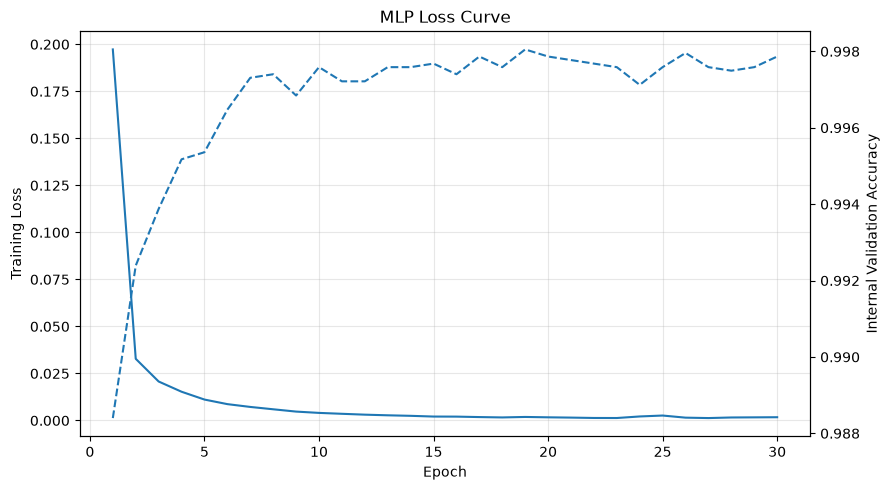


LEAVE ONE GROUP OUT
Available LOGO folds: 42
LOGO folds used: 5
LOGO 1/5, Participant = 2, Accuracy = 0.9036, Iterations = 25, Time = 0.21 min
LOGO 2/5, Participant = 3, Accuracy = 0.4638, Iterations = 23, Time = 0.19 min
LOGO 3/5, Participant = 5, Accuracy = 0.7080, Iterations = 23, Time = 0.19 min
LOGO 4/5, Participant = 8, Accuracy = 0.6106, Iterations = 28, Time = 0.23 min
LOGO 5/5, Participant = 10, Accuracy = 1.0000, Iterations = 30, Time = 0.25 min

LOGO Accuracy: 0.7372 plus or minus 0.1941
LOGO Time: 1.07 minutes

FINAL UNTOUCHED TEST EVALUATION

CLASSIFICATION REPORT

               precision    recall  f1-score   support

class_lecture     0.9876    0.8946    0.9388      7103
        music     0.7110    0.8891    0.7901      6257
       normal     0.7567    0.7043    0.7296      7569
      reading     0.9368    0.8809    0.9080      6264

     accuracy                         0.8372     27193
    macro avg     0.8480    0.8422    0.8416     27193
 weighted avg     0.8480   

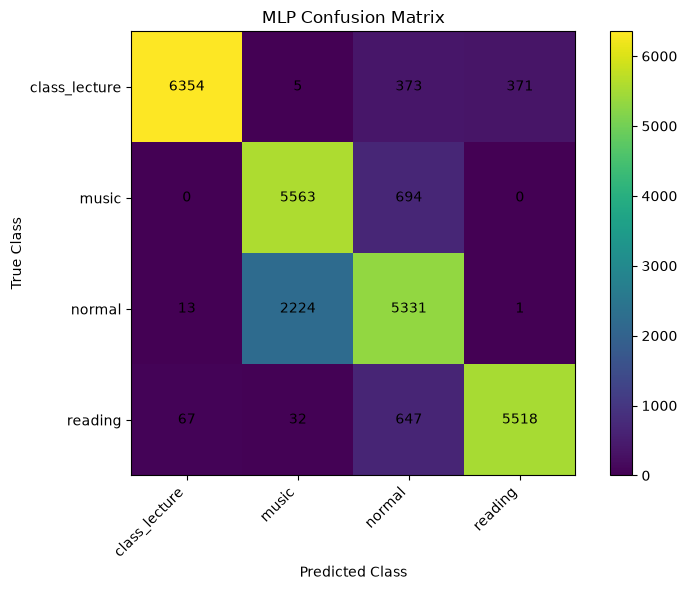

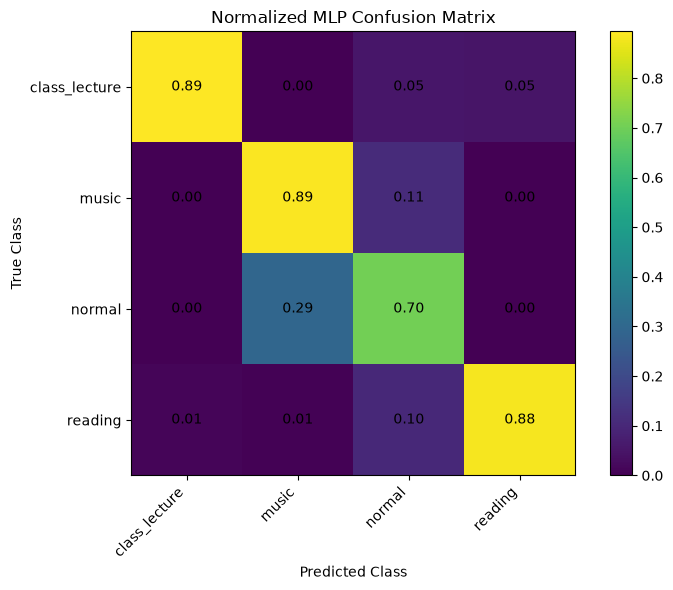


MLP LEARNING CURVE


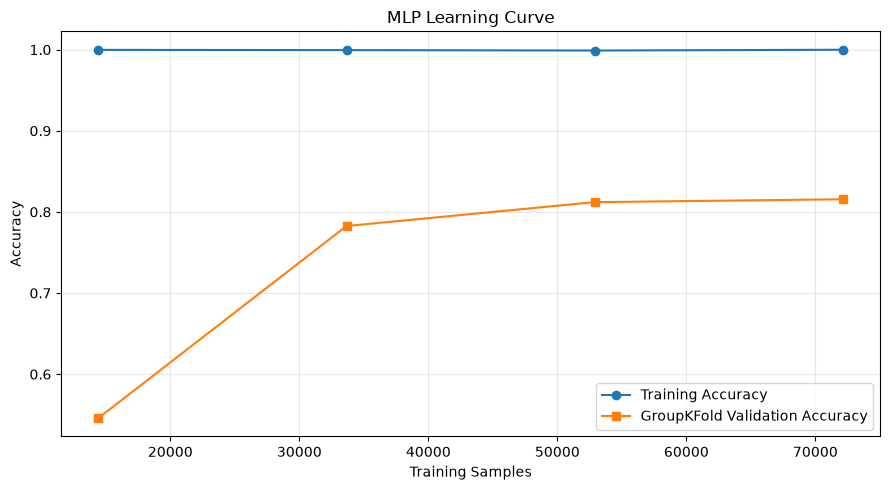

Learning Curve Time: 1.17 minutes

################################################################################
FINAL MLP RESULTS
MAX DATASET
################################################################################
Feature Count             : 232
Best Architecture         : (128,)
Best Activation           : relu
Best Alpha                : 1.13e-03
Best Learning Rate        : 7.59e-04

Selected Run              : 3
Random State              : 44
Iterations Trained        : 30

Training Accuracy         : 0.9997
Validation Accuracy       : 0.8732
Testing Accuracy          : 0.8372

GroupKFold                : 0.7998 plus or minus 0.0431
LOGO Accuracy             : 0.7372 plus or minus 0.1941
LOGO Folds Used           : 5 of 42

Precision Weighted        : 0.8480
Recall Weighted           : 0.8372
F1 Weighted               : 0.8393
F1 Macro                  : 0.8416
Cohen Kappa               : 0.7829
MCC                       : 0.7853
ROC AUC Weighted OVR      : 0.9609

Optu

In [2]:
# ================================================================
# MULTILAYER PERCEPTRON
# MAX DATASET
#
# PERSON WISE 70 / 20 / 10
# STANDARDIZATION
# GROUPKFOLD 5
# OPTUNA 12 TRIALS
# FIVE STOCHASTIC RUNS
# LOGO
# LEARNING CURVE
# LOSS CURVE
# CONFUSION MATRIX
# NORMALIZED CONFUSION MATRIX
# COMPLETE METRICS
#
# TEST SET IS USED ONLY FOR FINAL EVALUATION
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import json
import time
import random
import warnings

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut,
    learning_curve
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.pipeline import Pipeline

from sklearn.neural_network import (
    MLPClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ================================================================
# CONFIGURATION
# ================================================================

SEED = 42

N_TRIALS = 12

N_RUNS = 5

GROUP_K_FOLDS = 5


# ================================================================
# LOGO CONFIGURATION
#
# Same default behavior as the supplied Med code.
#
# Use None if all 42 training participants should be evaluated.
# ================================================================

LOGO_MAX_FOLDS = 5


# ================================================================
# MLP CONFIGURATION
# ================================================================

MLP_MAX_ITER = 200

MLP_EARLY_STOPPING = True

MLP_VALIDATION_FRAC = 0.10

MLP_N_ITER_NO_CHANGE = 10

MLP_BATCH_SIZE = 256

MLP_SOLVER = "adam"

MLP_SHUFFLE = True

MLP_VERBOSE = False


# ================================================================
# RANDOMNESS
# ================================================================

random.seed(
    SEED
)

np.random.seed(
    SEED
)


warnings.filterwarnings(
    "ignore"
)


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ================================================================
# MEMORY MONITOR
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# INPUT
# ================================================================

FILE_PATH = Path(

    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"

)


if not FILE_PATH.exists():

    raise FileNotFoundError(

        f"Input CSV was not found: "
        f"{FILE_PATH}"

    )


# ================================================================
# OUTPUT
# ================================================================

OUTPUT_DIR = (

    FILE_PATH.parent
    / "Max_Dataset_MLP_Results"

)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


# ================================================================
# OPTUNA DATABASE
#
# Allows the Optuna stage to continue after interruption.
# ================================================================

OPTUNA_DATABASE = (

    OUTPUT_DIR
    / "mlp_optuna.db"

)


OPTUNA_STORAGE = (

    f"sqlite:///"
    f"{OPTUNA_DATABASE}"

)


OPTUNA_STUDY_NAME = (

    "Max_Dataset_MLP_Optuna"

)


# ================================================================
# TOTAL TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# START INFORMATION
# ================================================================

print("=" * 80)

print(
    "MULTILAYER PERCEPTRON"
)

print(
    "MAX DATASET"
)

print("=" * 80)


print(
    "Input file:"
)

print(
    FILE_PATH
)


print()

print(
    "Output directory:"
)

print(
    OUTPUT_DIR
)


print()

print(
    "Device: CPU"
)


print(
    "Optuna trials:",
    N_TRIALS
)


print(
    "Final runs:",
    N_RUNS
)


print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)


if LOGO_MAX_FOLDS is None:

    print(
        "LOGO cap: NONE"
    )

else:

    print(
        "LOGO cap:",
        LOGO_MAX_FOLDS
    )


print(
    "MLP maximum iterations:",
    MLP_MAX_ITER
)


print(
    "Batch size:",
    MLP_BATCH_SIZE
)


print(
    "Internal early stopping:",
    MLP_EARLY_STOPPING
)


print("=" * 80)


# ================================================================
# LOAD DATA
# ================================================================

print()

print("=" * 80)

print(
    "LOADING MAX DATASET"
)

print("=" * 80)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMN DEFINITIONS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


if len(feature_cols) == 0:

    raise ValueError(

        "No feature columns were found."

    )


print(
    "Feature count:",
    len(
        feature_cols
    )
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(

        pd.to_numeric,

        errors="coerce"

    )

    .to_numpy(

        dtype=np.float32

    )

)


# ================================================================
# INVALID VALUE CHECK
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "Feature matrix contains "
        "NaN or infinite values."

    )


# ================================================================
# LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(

    np.int32

)


class_names = list(

    label_encoder.classes_

)


NUM_CLASSES = len(

    class_names

)


# ================================================================
# PARTICIPANTS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Classes:",
    class_names
)


print(
    "Number of classes:",
    NUM_CLASSES
)


print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

class_distribution_records = []


print()

print(
    "CLASS DISTRIBUTION"
)


for class_index, class_name in enumerate(

    class_names

):

    count = int(

        np.sum(

            y_all == class_index

        )

    )


    percentage = (

        count
        / len(
            y_all
        )
        * 100.0

    )


    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


    class_distribution_records.append(

        {

            "Class":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage

        }

    )


pd.DataFrame(

    class_distribution_records

).to_csv(

    OUTPUT_DIR
    / "class_distribution.csv",

    index=False

)


print()

print(
    "Loading time:",
    f"{time.time() - load_start:.2f}",
    "seconds"
)


# ================================================================
# RELEASE DATAFRAME
# ================================================================

del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10 SPLIT
# ================================================================

print()

print("=" * 80)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 80)


persons = np.unique(

    groups_all

)


rng = np.random.RandomState(

    SEED

)


rng.shuffle(

    persons

)


number_persons = len(

    persons

)


number_test = max(

    1,

    int(

        round(

            0.20
            * number_persons

        )

    )

)


number_validation = max(

    1,

    int(

        round(

            0.10
            * number_persons

        )

    )

)


test_persons = persons[

    :number_test

]


validation_persons = persons[

    number_test:
    number_test
    + number_validation

]


train_persons = persons[

    number_test
    + number_validation:

]


# ================================================================
# SPLIT MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY PARTICIPANT INDEPENDENCE
# ================================================================

assert (

    np.intersect1d(

        train_persons,

        validation_persons

    ).size == 0

)


assert (

    np.intersect1d(

        train_persons,

        test_persons

    ).size == 0

)


assert (

    np.intersect1d(

        validation_persons,

        test_persons

    ).size == 0

)


# ================================================================
# CREATE SPLITS
# ================================================================

X_train = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


g_validation = np.ascontiguousarray(

    groups_all[
        validation_mask
    ]

)


X_test = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


g_test = np.ascontiguousarray(

    groups_all[
        test_mask
    ]

)


print(
    "Training participants:",
    len(
        train_persons
    )
)


print(
    "Validation participants:",
    len(
        validation_persons
    )
)


print(
    "Testing participants:",
    len(
        test_persons
    )
)


print()

print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


# ================================================================
# SAVE SPLIT INFORMATION
# ================================================================

split_table = pd.DataFrame(

    [

        {

            "Split":
                "Training",

            "Participants":
                len(
                    train_persons
                ),

            "Rows":
                len(
                    X_train
                )

        },

        {

            "Split":
                "Validation",

            "Participants":
                len(
                    validation_persons
                ),

            "Rows":
                len(
                    X_validation
                )

        },

        {

            "Split":
                "Testing",

            "Participants":
                len(
                    test_persons
                ),

            "Rows":
                len(
                    X_test
                )

        }

    ]

)


split_table.to_csv(

    OUTPUT_DIR
    / "split_summary.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "participant_split.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "training":

                [
                    str(x)
                    for x
                    in train_persons
                ],

            "validation":

                [
                    str(x)
                    for x
                    in validation_persons
                ],

            "testing":

                [
                    str(x)
                    for x
                    in test_persons
                ]

        },

        file,

        indent=4

    )


# ================================================================
# RELEASE COMPLETE DATA
# ================================================================

del X_all

del y_all

del groups_all

del train_mask

del validation_mask

del test_mask

gc.collect()


print()

print(
    "RAM after split:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# GROUPKFOLD
# ================================================================

gkf_splits = list(

    GroupKFold(

        n_splits=
            GROUP_K_FOLDS

    ).split(

        X_train,

        y_train,

        g_train

    )

)


# ================================================================
# LOGO
# ================================================================

logo_splits_full = list(

    LeaveOneGroupOut().split(

        X_train,

        y_train,

        g_train

    )

)


if LOGO_MAX_FOLDS is None:

    logo_splits = (

        logo_splits_full

    )

else:

    logo_splits = (

        logo_splits_full[
            :LOGO_MAX_FOLDS
        ]

    )


print()

print(
    "GroupKFold folds:",
    len(
        gkf_splits
    )
)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


# ================================================================
# MLP MODEL
# ================================================================

def make_mlp_estimator(

    params,

    random_state=SEED

):

    return MLPClassifier(

        solver=
            MLP_SOLVER,

        batch_size=
            MLP_BATCH_SIZE,

        max_iter=
            MLP_MAX_ITER,

        early_stopping=
            MLP_EARLY_STOPPING,

        validation_fraction=
            MLP_VALIDATION_FRAC,

        n_iter_no_change=
            MLP_N_ITER_NO_CHANGE,

        shuffle=
            MLP_SHUFFLE,

        verbose=
            MLP_VERBOSE,

        random_state=
            random_state,

        hidden_layer_sizes=
            tuple(
                params[
                    "hidden_layer_sizes"
                ]
            ),

        activation=
            params[
                "activation"
            ],

        alpha=
            float(
                params[
                    "alpha"
                ]
            ),

        learning_rate_init=
            float(
                params[
                    "learning_rate_init"
                ]
            )

    )


# ================================================================
# PIPELINE
#
# StandardScaler is trained independently inside
# every CV fold.
# ================================================================

def make_mlp(

    params,

    random_state=SEED

):

    return Pipeline(

        [

            (

                "scaler",

                StandardScaler()

            ),

            (

                "mlp",

                make_mlp_estimator(

                    params,

                    random_state=
                        random_state

                )

            )

        ]

    )


# ================================================================
# FIT MLP
# ================================================================

def fit_mlp(

    params,

    X,

    y,

    random_state=SEED

):

    model = make_mlp(

        params,

        random_state

    )


    model.fit(

        X,

        y

    )


    return model


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def mlp_objective(

    trial

):

    number_layers = (

        trial.suggest_int(

            "n_layers",

            1,

            3

        )

    )


    hidden_layers = []


    for layer_index in range(

        number_layers

    ):

        units = trial.suggest_categorical(

            f"n_units_l{layer_index}",

            [

                32,

                64,

                128,

                256

            ]

        )


        hidden_layers.append(

            units

        )


    params = {

        "hidden_layer_sizes":

            tuple(
                hidden_layers
            ),

        "activation":

            trial.suggest_categorical(

                "activation",

                [

                    "relu",

                    "tanh"

                ]

            ),

        "alpha":

            trial.suggest_float(

                "alpha",

                1e-5,

                1e-2,

                log=True

            ),

        "learning_rate_init":

            trial.suggest_float(

                "learning_rate_init",

                1e-4,

                1e-2,

                log=True

            )

    }


    fold_scores = []


    print()

    print(

        f"Trial "
        f"{trial.number + 1}"

    )


    print(
        params
    )


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        model = fit_mlp(

            params,

            X_train[
                train_index
            ],

            y_train[
                train_index
            ],

            random_state=
                SEED

        )


        prediction = model.predict(

            X_train[
                validation_index
            ]

        )


        accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        fold_scores.append(

            accuracy

        )


        mlp_model = (

            model.named_steps[
                "mlp"
            ]

        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{accuracy:.4f}, "

            f"Iterations = "
            f"{mlp_model.n_iter_}, "

            f"Time = "
            f"{(time.time() - fold_start) / 60:.2f} min"

        )


        del mlp_model

        del model

        del prediction


        gc.collect()


    mean_accuracy = float(

        np.mean(
            fold_scores
        )

    )


    std_accuracy = float(

        np.std(
            fold_scores
        )

    )


    print(

        f"Mean GroupKFold Accuracy = "
        f"{mean_accuracy:.4f} "

        f"plus or minus "
        f"{std_accuracy:.4f}"

    )


    return mean_accuracy


# ================================================================
# OPTUNA
#
# SQLite storage allows interrupted optimization
# to continue from completed trials.
# ================================================================

print()

print("=" * 80)

print(
    "MLP OPTUNA"
)

print("=" * 80)


optuna_start = time.time()


study = optuna.create_study(

    study_name=
        OPTUNA_STUDY_NAME,

    storage=
        OPTUNA_STORAGE,

    direction=
        "maximize",

    sampler=
        optuna.samplers.TPESampler(

            seed=SEED

        ),

    load_if_exists=True

)


completed_trials = sum(

    1

    for trial in study.trials

    if trial.state
    == optuna.trial.TrialState.COMPLETE

)


remaining_trials = max(

    0,

    N_TRIALS
    - completed_trials

)


print(
    "Previously completed trials:",
    completed_trials
)


print(
    "Remaining trials:",
    remaining_trials
)


if remaining_trials > 0:

    study.optimize(

        mlp_objective,

        n_trials=
            remaining_trials,

        show_progress_bar=False,

        gc_after_trial=True

    )


optuna_time = (

    time.time()
    - optuna_start

)


# ================================================================
# REBUILD BEST PARAMETERS
# ================================================================

best_number_layers = int(

    study.best_params[
        "n_layers"
    ]

)


best_hidden = tuple(

    int(

        study.best_params[
            f"n_units_l{i}"
        ]

    )

    for i in range(

        best_number_layers

    )

)


best_params = {

    "hidden_layer_sizes":

        best_hidden,

    "activation":

        study.best_params[
            "activation"
        ],

    "alpha":

        float(

            study.best_params[
                "alpha"
            ]

        ),

    "learning_rate_init":

        float(

            study.best_params[
                "learning_rate_init"
            ]

        )

}


print()

print("=" * 80)

print(
    "OPTUNA COMPLETED"
)

print("=" * 80)


print(
    "Best GroupKFold Accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Best hidden layers:",
    best_hidden
)


print(
    "Best activation:",
    best_params[
        "activation"
    ]
)


print(
    "Best alpha:",
    best_params[
        "alpha"
    ]
)


print(
    "Best learning rate:",
    best_params[
        "learning_rate_init"
    ]
)


print(
    "Optuna time:",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


# ================================================================
# SAVE OPTUNA RESULTS
# ================================================================

study.trials_dataframe().to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


best_params_json = {

    "hidden_layer_sizes":

        list(
            best_hidden
        ),

    "activation":

        best_params[
            "activation"
        ],

    "alpha":

        best_params[
            "alpha"
        ],

    "learning_rate_init":

        best_params[
            "learning_rate_init"
        ]

}


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        best_params_json,

        file,

        indent=4

    )


# ================================================================
# FIVE MLP RUNS
#
# MLP is stochastic.
#
# Random states:
# 42
# 43
# 44
# 45
# 46
#
# Best run is selected from external validation accuracy.
#
# Test data are not used here.
# ================================================================

print()

print("=" * 80)

print(
    "MLP FIVE RUNS"
)

print("=" * 80)


run_records = []


best_model = None


best_record = None


best_validation_accuracy = (

    float("-inf")

)


five_run_start = time.time()


for run_number in range(

    1,

    N_RUNS + 1

):

    run_start = time.time()


    random_state = (

        SEED
        + run_number
        - 1

    )


    print()

    print(

        f"RUN "
        f"{run_number}/"
        f"{N_RUNS}"

    )


    # ============================================================
    # GROUPKFOLD
    # ============================================================

    cv_scores = []


    cv_iterations = []


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        fold_model = fit_mlp(

            best_params,

            X_train[
                train_index
            ],

            y_train[
                train_index
            ],

            random_state=
                random_state

        )


        fold_prediction = (

            fold_model.predict(

                X_train[
                    validation_index
                ]

            )

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            fold_prediction

        )


        fold_mlp = (

            fold_model.named_steps[
                "mlp"
            ]

        )


        cv_scores.append(

            fold_accuracy

        )


        cv_iterations.append(

            int(
                fold_mlp.n_iter_
            )

        )


        print(

            f"Run "
            f"{run_number}, "

            f"GKF "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Iterations = "
            f"{fold_mlp.n_iter_}, "

            f"Time = "
            f"{(time.time() - fold_start) / 60:.2f} min"

        )


        del fold_mlp

        del fold_model

        del fold_prediction


        gc.collect()


    # ============================================================
    # FULL TRAINING DATA
    # ============================================================

    model = fit_mlp(

        best_params,

        X_train,

        y_train,

        random_state=
            random_state

    )


    # ============================================================
    # TRAINING PREDICTION
    # ============================================================

    train_prediction = model.predict(

        X_train

    )


    train_accuracy = accuracy_score(

        y_train,

        train_prediction

    )


    # ============================================================
    # EXTERNAL VALIDATION
    # ============================================================

    validation_probability = (

        model.predict_proba(

            X_validation

        )

    )


    validation_prediction = np.argmax(

        validation_probability,

        axis=1

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    fitted_mlp = (

        model.named_steps[
            "mlp"
        ]

    )


    run_time = (

        time.time()
        - run_start

    )


    record = {

        "Run":

            run_number,

        "Random_State":

            random_state,

        "Training_Accuracy":

            float(
                train_accuracy
            ),

        "Validation_Accuracy":

            float(
                validation_accuracy
            ),

        "GroupKFold_Accuracy":

            float(
                np.mean(
                    cv_scores
                )
            ),

        "GroupKFold_STD":

            float(
                np.std(
                    cv_scores
                )
            ),

        "Mean_CV_Iterations":

            float(
                np.mean(
                    cv_iterations
                )
            ),

        "Final_Iterations":

            int(
                fitted_mlp.n_iter_
            ),

        "Execution_Time_Seconds":

            float(
                run_time
            )

    }


    run_records.append(

        record

    )


    print()

    print(

        f"[MLP {run_number}] "

        f"Train = "
        f"{train_accuracy:.4f}, "

        f"Validation = "
        f"{validation_accuracy:.4f}, "

        f"GKF = "
        f"{record['GroupKFold_Accuracy']:.4f} "

        f"plus or minus "
        f"{record['GroupKFold_STD']:.4f}, "

        f"Iterations = "
        f"{fitted_mlp.n_iter_}, "

        f"Time = "
        f"{run_time / 60:.2f} min"

    )


    # ============================================================
    # BEST MODEL FROM VALIDATION ONLY
    # ============================================================

    if (

        validation_accuracy
        > best_validation_accuracy

    ):

        if best_model is not None:

            del best_model


        best_model = model


        best_record = (

            record.copy()

        )


        best_validation_accuracy = (

            validation_accuracy

        )


    else:

        del model


    del fitted_mlp

    del train_prediction

    del validation_probability

    del validation_prediction


    gc.collect()


five_run_time = (

    time.time()
    - five_run_start

)


run_table = pd.DataFrame(

    run_records

)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()

print(
    run_table
    .round(4)
    .to_string(
        index=False
    )
)


print()

print(
    "Selected run:",
    best_record[
        "Run"
    ]
)


print(
    "Selected random state:",
    best_record[
        "Random_State"
    ]
)


print(
    "Selected validation accuracy:",
    f"{best_validation_accuracy:.4f}"
)


# ================================================================
# SAVE BEST MODEL PIPELINE
#
# Includes StandardScaler and MLP.
# ================================================================

joblib.dump(

    best_model,

    OUTPUT_DIR
    / "mlp_best_model.joblib"

)


# ================================================================
# LOSS CURVE FOR SELECTED MODEL
# ================================================================

best_mlp_estimator = (

    best_model.named_steps[
        "mlp"
    ]

)


loss_curve = np.asarray(

    best_mlp_estimator.loss_curve_,

    dtype=float

)


loss_table = pd.DataFrame(

    {

        "Epoch":

            np.arange(

                1,

                len(
                    loss_curve
                )
                + 1

            ),

        "Training_Loss":

            loss_curve

    }

)


if (

    hasattr(
        best_mlp_estimator,
        "validation_scores_"
    )

    and

    best_mlp_estimator.validation_scores_
    is not None

):

    validation_scores_internal = (

        np.asarray(

            best_mlp_estimator.validation_scores_,

            dtype=float

        )

    )


    validation_length = min(

        len(
            loss_table
        ),

        len(
            validation_scores_internal
        )

    )


    loss_table.loc[

        :validation_length - 1,

        "Internal_Validation_Accuracy"

    ] = (

        validation_scores_internal[
            :validation_length
        ]

    )


loss_table.to_csv(

    OUTPUT_DIR
    / "loss_curve.csv",

    index=False

)


# ================================================================
# LOSS CURVE VISUALIZATION
# ================================================================

fig, ax1 = plt.subplots(

    figsize=(9, 5)

)


ax1.plot(

    np.arange(

        1,

        len(
            loss_curve
        )
        + 1

    ),

    loss_curve,

    label=
        "Training Loss"

)


ax1.set_xlabel(

    "Epoch"

)


ax1.set_ylabel(

    "Training Loss"

)


ax1.set_title(

    "MLP Loss Curve"
)


ax1.grid(

    alpha=0.3

)


if (

    hasattr(
        best_mlp_estimator,
        "validation_scores_"
    )

    and

    best_mlp_estimator.validation_scores_
    is not None

):

    ax2 = ax1.twinx()


    validation_scores_internal = (

        np.asarray(

            best_mlp_estimator.validation_scores_,

            dtype=float

        )

    )


    ax2.plot(

        np.arange(

            1,

            len(
                validation_scores_internal
            )
            + 1

        ),

        validation_scores_internal,

        linestyle="--",

        label=
            "Internal Validation Accuracy"

    )


    ax2.set_ylabel(

        "Internal Validation Accuracy"

    )


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "loss_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# LOGO
# ================================================================

print()

print("=" * 80)

print(
    "LEAVE ONE GROUP OUT"
)

print("=" * 80)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


logo_start = time.time()


logo_records = []


logo_scores = []


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    logo_splits,

    start=1

):

    fold_start = time.time()


    model = fit_mlp(

        best_params,

        X_train[
            train_index
        ],

        y_train[
            train_index
        ],

        random_state=
            best_record[
                "Random_State"
            ]

    )


    prediction = model.predict(

        X_train[
            validation_index
        ]

    )


    accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    held_out_persons = np.unique(

        g_train[
            validation_index
        ]

    )


    if len(
        held_out_persons
    ) != 1:

        raise RuntimeError(

            "Unexpected LOGO grouping."

        )


    held_out_person = (

        held_out_persons[
            0
        ]

    )


    logo_mlp = (

        model.named_steps[
            "mlp"
        ]

    )


    fold_time = (

        time.time()
        - fold_start

    )


    logo_scores.append(

        accuracy

    )


    logo_records.append(

        {

            "Fold":

                fold_number,

            "Held_Out_Person":

                str(
                    held_out_person
                ),

            "Rows":

                int(
                    len(
                        validation_index
                    )
                ),

            "Accuracy":

                float(
                    accuracy
                ),

            "Iterations":

                int(
                    logo_mlp.n_iter_
                ),

            "Execution_Time_Seconds":

                float(
                    fold_time
                )

        }

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "

        f"Participant = "
        f"{held_out_person}, "

        f"Accuracy = "
        f"{accuracy:.4f}, "

        f"Iterations = "
        f"{logo_mlp.n_iter_}, "

        f"Time = "
        f"{fold_time / 60:.2f} min"

    )


    # Save progress after every LOGO fold

    pd.DataFrame(

        logo_records

    ).to_csv(

        OUTPUT_DIR
        / "logo_results.csv",

        index=False

    )


    del logo_mlp

    del model

    del prediction


    gc.collect()


logo_time = (

    time.time()
    - logo_start

)


logo_mean = float(

    np.mean(
        logo_scores
    )

)


logo_std = float(

    np.std(
        logo_scores
    )

)


print()

print(
    "LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "LOGO Time:",
    f"{logo_time / 60:.2f}",
    "minutes"
)


# ================================================================
# FINAL TEST EVALUATION
#
# Test set is touched here for the first time.
# ================================================================

print()

print("=" * 80)

print(
    "FINAL UNTOUCHED TEST EVALUATION"
)

print("=" * 80)


test_start = time.time()


test_probability = (

    best_model.predict_proba(

        X_test

    )

)


test_prediction = np.argmax(

    test_probability,

    axis=1

)


test_time = (

    time.time()
    - test_start

)


# ================================================================
# TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average="macro",

    zero_division=0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


try:

    test_roc_auc = roc_auc_score(

        y_test,

        test_probability,

        multi_class="ovr",

        average="weighted"

    )


except Exception:

    test_roc_auc = np.nan


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    ),

    target_names=
        class_names,

    digits=4,

    zero_division=0

)


print()

print(
    "CLASSIFICATION REPORT"
)


print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(
        report
    )


report_table = pd.DataFrame(

    classification_report(

        y_test,

        test_prediction,

        labels=np.arange(
            NUM_CLASSES
        ),

        target_names=
            class_names,

        output_dict=True,

        zero_division=0

    )

).transpose()


report_table.to_csv(

    OUTPUT_DIR
    / "classification_report.csv"

)


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    )

)


pd.DataFrame(

    cm,

    index=
        class_names,

    columns=
        class_names

).to_csv(

    OUTPUT_DIR
    / "confusion_matrix.csv"

)


# ================================================================
# CONFUSION MATRIX VISUALIZATION
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(

    cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "MLP Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            str(
                cm[
                    row,
                    column
                ]
            ),

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(

    axis=1,

    keepdims=True

)


normalized_cm = np.divide(

    cm,

    row_sums,

    out=np.zeros_like(

        cm,

        dtype=np.float64

    ),

    where=(

        row_sums != 0

    )

)


pd.DataFrame(

    normalized_cm,

    index=
        class_names,

    columns=
        class_names

).to_csv(

    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"

)


# ================================================================
# NORMALIZED MATRIX VISUALIZATION
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(

    normalized_cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "Normalized MLP Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            f"{normalized_cm[row, column]:.2f}",

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "normalized_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {

        "PersonSrial":

            g_test,

        "True_Class":

            label_encoder.inverse_transform(

                y_test

            ),

        "Predicted_Class":

            label_encoder.inverse_transform(

                test_prediction.astype(
                    np.int32
                )

            )

    }

)


for class_index, class_name in enumerate(

    class_names

):

    prediction_table[

        f"Probability_{class_name}"

    ] = test_probability[

        :,

        class_index

    ]


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# LEARNING CURVE
#
# Pipeline prevents scaler leakage.
#
# GroupKFold keeps validation participants independent.
# ================================================================

print()

print("=" * 80)

print(
    "MLP LEARNING CURVE"
)

print("=" * 80)


learning_start = time.time()


learning_model = make_mlp(

    best_params,

    random_state=
        best_record[
            "Random_State"
        ]

)


learning_cv = GroupKFold(

    n_splits=3

)


train_sizes, train_scores, validation_scores = (

    learning_curve(

        learning_model,

        X_train,

        y_train,

        groups=
            g_train,

        cv=
            learning_cv,

        scoring=
            "accuracy",

        train_sizes=
            np.linspace(

                0.20,

                1.00,

                4

            ),

        n_jobs=1

    )

)


learning_time = (

    time.time()
    - learning_start

)


learning_table = pd.DataFrame(

    {

        "Training_Samples":

            train_sizes,

        "Training_Accuracy_Mean":

            train_scores.mean(
                axis=1
            ),

        "Training_Accuracy_STD":

            train_scores.std(
                axis=1
            ),

        "Validation_Accuracy_Mean":

            validation_scores.mean(
                axis=1
            ),

        "Validation_Accuracy_STD":

            validation_scores.std(
                axis=1
            )

    }

)


learning_table.to_csv(

    OUTPUT_DIR
    / "learning_curve.csv",

    index=False

)


# ================================================================
# LEARNING CURVE FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(9, 5)

)


ax.plot(

    train_sizes,

    train_scores.mean(
        axis=1
    ),

    marker="o",

    label=
        "Training Accuracy"

)


ax.plot(

    train_sizes,

    validation_scores.mean(
        axis=1
    ),

    marker="s",

    label=
        "GroupKFold Validation Accuracy"

)


ax.set_xlabel(

    "Training Samples"

)


ax.set_ylabel(

    "Accuracy"

)


ax.set_title(

    "MLP Learning Curve"

)


ax.legend()


ax.grid(

    alpha=0.3

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "learning_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


print(
    "Learning Curve Time:",
    f"{learning_time / 60:.2f}",
    "minutes"
)


# ================================================================
# FIVE RUN STATISTICS
# ================================================================

run_train_mean = float(

    run_table[
        "Training_Accuracy"
    ].mean()

)


run_train_std = float(

    run_table[
        "Training_Accuracy"
    ].std(
        ddof=0
    )

)


run_validation_mean = float(

    run_table[
        "Validation_Accuracy"
    ].mean()

)


run_validation_std = float(

    run_table[
        "Validation_Accuracy"
    ].std(
        ddof=0
    )

)


run_cv_mean = float(

    run_table[
        "GroupKFold_Accuracy"
    ].mean()

)


run_cv_std = float(

    run_table[
        "GroupKFold_Accuracy"
    ].std(
        ddof=0
    )

)


# ================================================================
# TOTAL TIME
# ================================================================

total_execution_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {

    "Algorithm":

        "MLP",

    "Dataset":

        "Max Dataset",

    "Input_File":

        str(
            FILE_PATH
        ),

    "Output_Directory":

        str(
            OUTPUT_DIR
        ),

    "Device":

        "CPU",

    "Feature_Count":

        int(
            len(
                feature_cols
            )
        ),

    "Classes":

        class_names,

    "Training_Participants":

        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":

        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":

        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":

        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":

        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":

        int(
            len(
                X_test
            )
        ),

    "Optuna_Trials_Target":

        int(
            N_TRIALS
        ),

    "Optuna_Best_GroupKFold_Accuracy":

        float(
            study.best_value
        ),

    "Best_Parameters":

        best_params_json,

    "Selected_Run":

        int(
            best_record[
                "Run"
            ]
        ),

    "Selected_Random_State":

        int(
            best_record[
                "Random_State"
            ]
        ),

    "Training_Accuracy":

        float(
            best_record[
                "Training_Accuracy"
            ]
        ),

    "Validation_Accuracy":

        float(
            best_record[
                "Validation_Accuracy"
            ]
        ),

    "Testing_Accuracy":

        float(
            test_accuracy
        ),

    "Selected_Run_GroupKFold_Accuracy":

        float(
            best_record[
                "GroupKFold_Accuracy"
            ]
        ),

    "Selected_Run_GroupKFold_STD":

        float(
            best_record[
                "GroupKFold_STD"
            ]
        ),

    "Selected_Run_Iterations":

        int(
            best_record[
                "Final_Iterations"
            ]
        ),

    "Five_Run_Training_Mean":

        run_train_mean,

    "Five_Run_Training_STD":

        run_train_std,

    "Five_Run_Validation_Mean":

        run_validation_mean,

    "Five_Run_Validation_STD":

        run_validation_std,

    "Five_Run_GroupKFold_Mean":

        run_cv_mean,

    "Five_Run_GroupKFold_STD":

        run_cv_std,

    "LOGO_Folds_Available":

        int(
            len(
                logo_splits_full
            )
        ),

    "LOGO_Folds_Used":

        int(
            len(
                logo_splits
            )
        ),

    "LOGO_Accuracy":

        float(
            logo_mean
        ),

    "LOGO_STD":

        float(
            logo_std
        ),

    "Precision_Weighted":

        float(
            test_precision
        ),

    "Recall_Weighted":

        float(
            test_recall
        ),

    "F1_Weighted":

        float(
            test_f1_weighted
        ),

    "F1_Macro":

        float(
            test_f1_macro
        ),

    "Cohen_Kappa":

        float(
            test_kappa
        ),

    "MCC":

        float(
            test_mcc
        ),

    "ROC_AUC_Weighted_OVR":

        None

        if np.isnan(
            test_roc_auc
        )

        else float(
            test_roc_auc
        ),

    "Optuna_Time_Seconds":

        float(
            optuna_time
        ),

    "Five_Run_Time_Seconds":

        float(
            five_run_time
        ),

    "LOGO_Time_Seconds":

        float(
            logo_time
        ),

    "Test_Time_Seconds":

        float(
            test_time
        ),

    "Learning_Curve_Time_Seconds":

        float(
            learning_time
        ),

    "Total_Execution_Time_Seconds":

        float(
            total_execution_time
        ),

    "Current_RAM_MB":

        float(
            mem_mb()
        )

}


with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=4

    )


# ================================================================
# FINAL SUMMARY TEXT
# ================================================================

summary_lines = [

    "MULTILAYER PERCEPTRON",
    "MAX DATASET",

    "",

    f"Input File: "
    f"{FILE_PATH}",

    f"Output Directory: "
    f"{OUTPUT_DIR}",

    "",

    f"Feature Count: "
    f"{len(feature_cols)}",

    f"Classes: "
    f"{class_names}",

    "",

    f"Training Participants: "
    f"{len(train_persons)}",

    f"Validation Participants: "
    f"{len(validation_persons)}",

    f"Testing Participants: "
    f"{len(test_persons)}",

    "",

    f"Best Architecture: "
    f"{best_hidden}",

    f"Best Activation: "
    f"{best_params['activation']}",

    f"Best Alpha: "
    f"{best_params['alpha']}",

    f"Best Learning Rate: "
    f"{best_params['learning_rate_init']}",

    "",

    f"Selected Run: "
    f"{best_record['Run']}",

    f"Selected Random State: "
    f"{best_record['Random_State']}",

    f"Iterations Trained: "
    f"{best_record['Final_Iterations']}",

    "",

    f"Training Accuracy: "
    f"{best_record['Training_Accuracy']:.4f}",

    f"Validation Accuracy: "
    f"{best_record['Validation_Accuracy']:.4f}",

    f"Testing Accuracy: "
    f"{test_accuracy:.4f}",

    "",

    f"GroupKFold Accuracy: "
    f"{best_record['GroupKFold_Accuracy']:.4f} "
    f"plus or minus "
    f"{best_record['GroupKFold_STD']:.4f}",

    "",

    f"LOGO Folds Available: "
    f"{len(logo_splits_full)}",

    f"LOGO Folds Used: "
    f"{len(logo_splits)}",

    f"LOGO Accuracy: "
    f"{logo_mean:.4f} "
    f"plus or minus "
    f"{logo_std:.4f}",

    "",

    f"Precision Weighted: "
    f"{test_precision:.4f}",

    f"Recall Weighted: "
    f"{test_recall:.4f}",

    f"F1 Weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 Macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    (
        "ROC AUC Weighted OVR: N/A"

        if np.isnan(
            test_roc_auc
        )

        else

        f"ROC AUC Weighted OVR: "
        f"{test_roc_auc:.4f}"
    ),

    "",

    f"Optuna Time: "
    f"{optuna_time / 60:.2f} minutes",

    f"Five Run Time: "
    f"{five_run_time / 60:.2f} minutes",

    f"LOGO Time: "
    f"{logo_time / 60:.2f} minutes",

    f"Learning Curve Time: "
    f"{learning_time / 60:.2f} minutes",

    f"Total Execution Time: "
    f"{total_execution_time / 60:.2f} minutes"

]


with open(

    OUTPUT_DIR
    / "final_summary.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(

        "\n".join(
            summary_lines
        )

    )


# ================================================================
# FINAL SCREEN OUTPUT
# ================================================================

print()

print("#" * 80)

print(
    "FINAL MLP RESULTS"
)

print(
    "MAX DATASET"
)

print("#" * 80)


print(
    "Feature Count             :",
    len(
        feature_cols
    )
)


print(
    "Best Architecture         :",
    best_hidden
)


print(
    "Best Activation           :",
    best_params[
        "activation"
    ]
)


print(
    "Best Alpha                :",
    f"{best_params['alpha']:.2e}"
)


print(
    "Best Learning Rate        :",
    f"{best_params['learning_rate_init']:.2e}"
)


print()

print(
    "Selected Run              :",
    best_record[
        "Run"
    ]
)


print(
    "Random State              :",
    best_record[
        "Random_State"
    ]
)


print(
    "Iterations Trained        :",
    best_record[
        "Final_Iterations"
    ]
)


print()

print(
    "Training Accuracy         :",
    f"{best_record['Training_Accuracy']:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{best_record['Validation_Accuracy']:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "GroupKFold                :",
    f"{best_record['GroupKFold_Accuracy']:.4f}",
    "plus or minus",
    f"{best_record['GroupKFold_STD']:.4f}"
)


print(
    "LOGO Accuracy             :",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "LOGO Folds Used           :",
    len(
        logo_splits
    ),
    "of",
    len(
        logo_splits_full
    )
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


if np.isnan(
    test_roc_auc
):

    print(
        "ROC AUC Weighted OVR      : N/A"
    )

else:

    print(
        "ROC AUC Weighted OVR      :",
        f"{test_roc_auc:.4f}"
    )


print()

print(
    "Optuna Time               :",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


print(
    "Five Run Time             :",
    f"{five_run_time / 60:.2f}",
    "minutes"
)


print(
    "LOGO Time                 :",
    f"{logo_time / 60:.2f}",
    "minutes"
)


print(
    "Learning Curve Time       :",
    f"{learning_time / 60:.2f}",
    "minutes"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "Test participants were not "
    "used during tuning or model selection."
)


print(
    "Scaling was fitted independently "
    "inside every GroupKFold and LOGO fit."
)


print()

print(
    "ALL RESULTS SAVED IN:"
)


print(
    OUTPUT_DIR
)


print("#" * 80)

**Apply ANN on Max Dataset**

I0000 00:00:1792266522.272372   49184 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792266522.293778   49184 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792266523.370520   49184 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TENSORFLOW DEVICE CONFIGURATION
TensorFlow GPU available: False
ANN will use CPU.
TensorFlow CPU thread limit: 8

ARTIFICIAL NEURAL NETWORK
MAX DATASET
Input file:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Cleaned_oN_Selected_Max.csv

Output directory:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Max_Dataset_ANN_Results

Optuna trials: 12
Final runs: 5
GroupKFold folds: 5
Maximum epochs: 60
Batch size: 256
Early stopping patience: 8
LOGO cap: NONE
Row subsampling: NONE

LOADING COMPLETE MAX DATASET


E0000 00:00:1792266523.816026   49184 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Raw dataset shape: (149350, 238)
RAM after loading: 1581.02 MB
Feature count: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

Loading time: 8.14 seconds

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training rows: 107752
Validation rows: 14405
Testing rows: 27193

RAM after split: 1485.78 MB

GroupKFold folds: 5
Available LOGO folds: 42
LOGO folds used: 42

ANN OPTUNA
Previously completed Optuna trials: 0
Remaining Optuna trials: 12

Trial 1
{'hidden_layer_sizes': (64, 256), 'activation': 'tanh', 'dropout': 0.41622132040021087, 'l2': 4.335281794951567e-06, 'learning_rate': 0.00020366442026830908}
Trial 1, Fold 1/5, Accuracy = 0.7054, Epochs = 9, Time = 7.44 sec
Trial 1, Fold 2/5, Accuracy = 0.6964, 

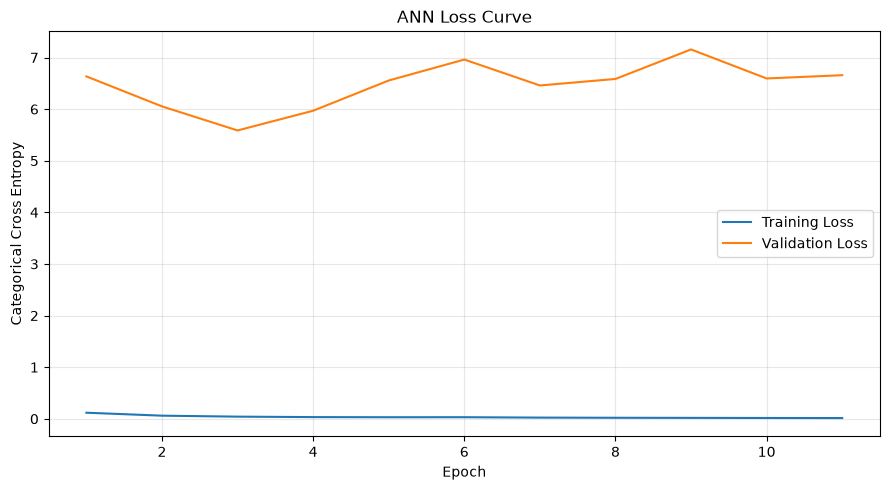

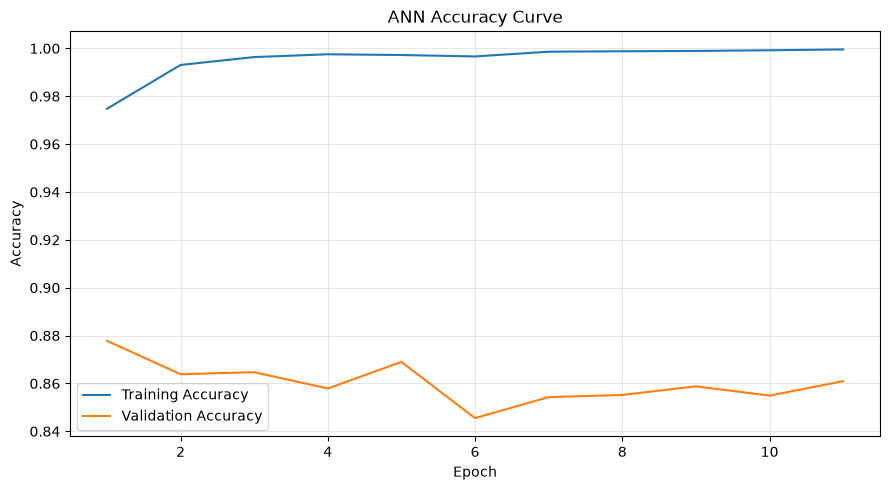


FULL LEAVE ONE GROUP OUT
Available LOGO folds: 42
LOGO folds used: 42
Fixed LOGO epochs: 11
LOGO 1/42, Participant = 2, Accuracy = 0.9800, Time = 14.21 sec
LOGO 2/42, Participant = 3, Accuracy = 0.4779, Time = 13.58 sec
LOGO 3/42, Participant = 5, Accuracy = 0.6037, Time = 14.41 sec
LOGO 4/42, Participant = 8, Accuracy = 0.8872, Time = 14.91 sec
LOGO 5/42, Participant = 10, Accuracy = 1.0000, Time = 14.49 sec
LOGO 6/42, Participant = 11, Accuracy = 0.9913, Time = 15.15 sec
LOGO 7/42, Participant = 12, Accuracy = 0.3794, Time = 14.77 sec
LOGO 8/42, Participant = 15, Accuracy = 0.4865, Time = 14.47 sec
LOGO 9/42, Participant = 16, Accuracy = 0.6997, Time = 14.92 sec
LOGO 10/42, Participant = 17, Accuracy = 0.6277, Time = 14.63 sec
LOGO 11/42, Participant = 19, Accuracy = 0.6789, Time = 14.92 sec
LOGO 12/42, Participant = 20, Accuracy = 0.8334, Time = 14.78 sec
LOGO 13/42, Participant = 21, Accuracy = 0.9273, Time = 16.10 sec
LOGO 14/42, Participant = 22, Accuracy = 0.9688, Time = 14.56 

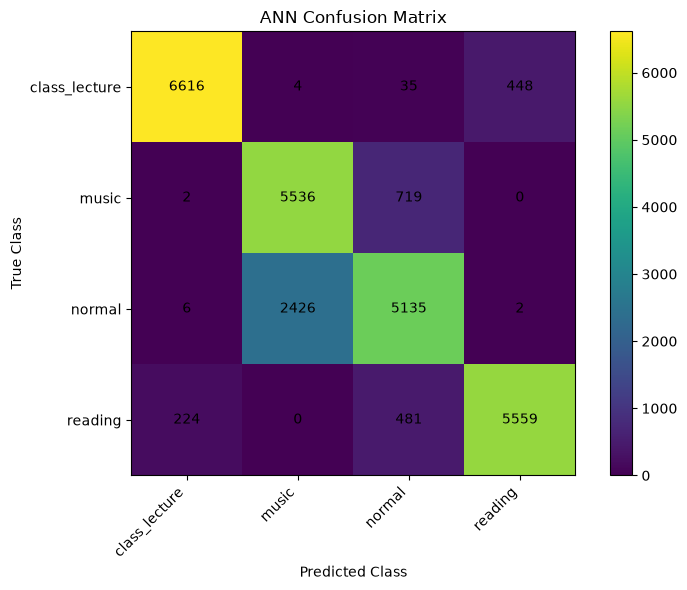

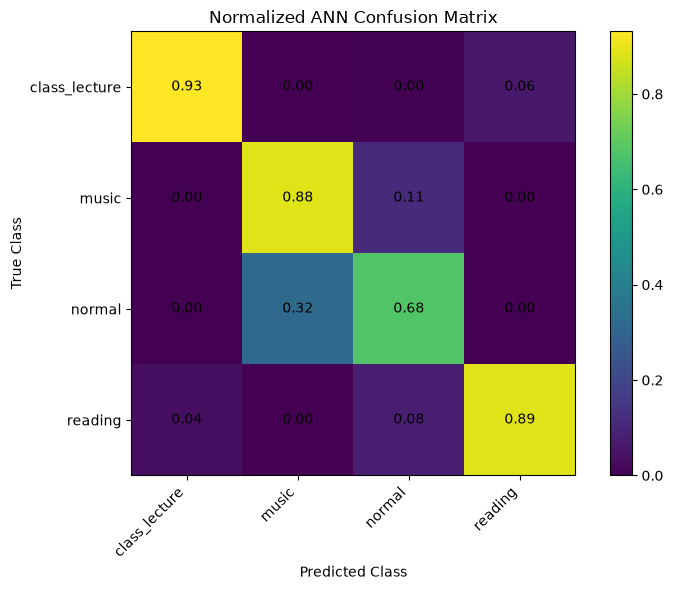


################################################################################
FINAL ANN RESULTS
MAX DATASET
################################################################################
Features                  : 232
Best Architecture         : (128, 512)
Best Activation           : gelu
Best Dropout              : 0.0598
Best L2                   : 1.38e-04
Best Learning Rate        : 1.96e-03

Selected Run              : 4
Selected Random Seed      : 45
Selected Epochs           : 11

Training Accuracy         : 0.9975
Validation Accuracy       : 0.8647
Testing Accuracy          : 0.8401

GroupKFold                : 0.8263 plus or minus 0.0224
Full LOGO                 : 0.8268 plus or minus 0.2134
Full LOGO Folds           : 42

Precision Weighted        : 0.8497
Recall Weighted           : 0.8401
F1 Weighted               : 0.8406
F1 Macro                  : 0.8424
Cohen Kappa               : 0.7871
MCC                       : 0.7903
ROC AUC Weighted OVR      : 0.9641

Optu

In [4]:
# ================================================================
# ARTIFICIAL NEURAL NETWORK
# TENSORFLOW KERAS
# MAX DATASET
#
# FULL DATASET
# PERSON WISE 70 / 20 / 10
# STANDARDIZATION
# OPTUNA 12 TRIALS
# GROUPKFOLD 5
# FIVE STOCHASTIC RUNS
# FULL LOGO
# NO LOGO CAP
# NO ROW SUBSAMPLING
#
# LOSS CURVE
# ACCURACY CURVE
# CONFUSION MATRIX
# NORMALIZED CONFUSION MATRIX
# COMPLETE TEST METRICS
#
# TEST SET REMAINS UNTOUCHED UNTIL FINAL EVALUATION
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import json
import time
import random
import warnings

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.utils.class_weight import (
    compute_class_weight
)


# ================================================================
# TENSORFLOW IMPORT
# ================================================================

try:

    import tensorflow as tf

    from tensorflow.keras import (
        layers,
        models,
        callbacks,
        regularizers,
        optimizers
    )

    from tensorflow.keras.utils import (
        to_categorical
    )


except ModuleNotFoundError as error:

    raise ModuleNotFoundError(

        "TensorFlow is not installed in the Python environment "
        "used by this VS Code Jupyter kernel. "
        "Install a TensorFlow version compatible with this "
        "Python environment, restart the kernel, and rerun."

    ) from error


# ================================================================
# GLOBAL CONFIGURATION
# ================================================================

SEED = 42

N_TRIALS = 12

N_RUNS = 5

GROUP_K_FOLDS = 5


# ================================================================
# ANN CONFIGURATION
# ================================================================

ANN_EPOCHS = 60

ANN_BATCH_SIZE = 256

ANN_PATIENCE = 8


# ================================================================
# FULL LOGO
#
# Same behavior as the supplied ANN code.
#
# None means every training participant is evaluated.
# ================================================================

LOGO_MAX_FOLDS = None


# ================================================================
# CPU THREAD LIMIT
# ================================================================

TF_THREADS = max(

    1,

    min(
        8,
        os.cpu_count() or 1
    )

)


# ================================================================
# RANDOMNESS
# ================================================================

random.seed(
    SEED
)

np.random.seed(
    SEED
)

tf.keras.utils.set_random_seed(
    SEED
)


# ================================================================
# WARNINGS
# ================================================================

warnings.filterwarnings(
    "ignore"
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

tf.get_logger().setLevel(
    "ERROR"
)


# ================================================================
# TENSORFLOW THREADING
# ================================================================

try:

    tf.config.threading.set_intra_op_parallelism_threads(
        TF_THREADS
    )

    tf.config.threading.set_inter_op_parallelism_threads(
        TF_THREADS
    )


except RuntimeError:

    pass


# ================================================================
# MEMORY MONITOR
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# INPUT FILE
# ================================================================

FILE_PATH = Path(

    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"

)


if not FILE_PATH.exists():

    raise FileNotFoundError(

        f"Input file was not found: "
        f"{FILE_PATH}"

    )


# ================================================================
# OUTPUT DIRECTORY
# ================================================================

OUTPUT_DIR = (

    FILE_PATH.parent
    / "Max_Dataset_ANN_Results"

)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


# ================================================================
# MODEL FILE
# ================================================================

BEST_MODEL_PATH = (

    OUTPUT_DIR
    / "ann_best_model.keras"

)


# ================================================================
# OPTUNA DATABASE
#
# Completed trials survive kernel restart or power interruption.
# ================================================================

OPTUNA_DATABASE = (

    OUTPUT_DIR
    / "ann_optuna.db"

)


OPTUNA_STORAGE = (

    f"sqlite:///"
    f"{OPTUNA_DATABASE}"

)


OPTUNA_STUDY_NAME = (

    "Max_Dataset_ANN_Optuna_v1"

)


# ================================================================
# TOTAL TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# TENSORFLOW DEVICE DETECTION
# ================================================================

print("=" * 80)

print(
    "TENSORFLOW DEVICE CONFIGURATION"
)

print("=" * 80)


physical_gpus = tf.config.list_physical_devices(
    "GPU"
)


if len(
    physical_gpus
) > 0:

    for gpu in physical_gpus:

        try:

            tf.config.experimental.set_memory_growth(

                gpu,

                True

            )

        except Exception:

            pass


    print(
        "TensorFlow GPU available: True"
    )


    print(
        "GPU devices:",
        physical_gpus
    )


else:

    print(
        "TensorFlow GPU available: False"
    )


    print(
        "ANN will use CPU."
    )


print(
    "TensorFlow CPU thread limit:",
    TF_THREADS
)


print("=" * 80)


# ================================================================
# EXPERIMENT INFORMATION
# ================================================================

print()

print("=" * 80)

print(
    "ARTIFICIAL NEURAL NETWORK"
)

print(
    "MAX DATASET"
)

print("=" * 80)


print(
    "Input file:"
)

print(
    FILE_PATH
)


print()

print(
    "Output directory:"
)

print(
    OUTPUT_DIR
)


print()

print(
    "Optuna trials:",
    N_TRIALS
)


print(
    "Final runs:",
    N_RUNS
)


print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)


print(
    "Maximum epochs:",
    ANN_EPOCHS
)


print(
    "Batch size:",
    ANN_BATCH_SIZE
)


print(
    "Early stopping patience:",
    ANN_PATIENCE
)


print(
    "LOGO cap: NONE"
)


print(
    "Row subsampling: NONE"
)


print("=" * 80)


# ================================================================
# LOAD COMPLETE DATASET
# ================================================================

print()

print("=" * 80)

print(
    "LOADING COMPLETE MAX DATASET"
)

print("=" * 80)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMNS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


if len(
    feature_cols
) == 0:

    raise ValueError(

        "No feature columns were found."

    )


print(
    "Feature count:",
    len(
        feature_cols
    )
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(

        pd.to_numeric,

        errors="coerce"

    )

    .to_numpy(

        dtype=np.float32

    )

)


# ================================================================
# INVALID VALUE CHECK
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "The feature matrix contains "
        "NaN or infinite values."

    )


# ================================================================
# LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(

    np.int32

)


class_names = list(

    label_encoder.classes_

)


NUM_CLASSES = len(

    class_names

)


# ================================================================
# PARTICIPANT GROUPS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Classes:",
    class_names
)


print(
    "Number of classes:",
    NUM_CLASSES
)


print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

print()

print(
    "CLASS DISTRIBUTION"
)


class_distribution_records = []


for class_index, class_name in enumerate(

    class_names

):

    count = int(

        np.sum(

            y_all
            == class_index

        )

    )


    percentage = (

        count
        / len(
            y_all
        )
        * 100.0

    )


    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


    class_distribution_records.append(

        {

            "Class":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage

        }

    )


pd.DataFrame(

    class_distribution_records

).to_csv(

    OUTPUT_DIR
    / "class_distribution.csv",

    index=False

)


print()

print(
    "Loading time:",
    f"{time.time() - load_start:.2f}",
    "seconds"
)


# ================================================================
# RELEASE DATAFRAME
# ================================================================

del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10 SPLIT
# ================================================================

print()

print("=" * 80)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 80)


persons = np.unique(

    groups_all

)


rng = np.random.RandomState(

    SEED

)


rng.shuffle(

    persons

)


number_persons = len(

    persons

)


number_test = max(

    1,

    int(

        round(

            0.20
            * number_persons

        )

    )

)


number_validation = max(

    1,

    int(

        round(

            0.10
            * number_persons

        )

    )

)


# ================================================================
# PARTICIPANT SPLITS
# ================================================================

test_persons = persons[

    :number_test

]


validation_persons = persons[

    number_test:
    number_test
    + number_validation

]


train_persons = persons[

    number_test
    + number_validation:

]


# ================================================================
# MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY NO PERSON OVERLAP
# ================================================================

assert (

    np.intersect1d(

        train_persons,

        validation_persons

    ).size == 0

)


assert (

    np.intersect1d(

        train_persons,

        test_persons

    ).size == 0

)


assert (

    np.intersect1d(

        validation_persons,

        test_persons

    ).size == 0

)


# ================================================================
# CREATE SPLITS
# ================================================================

X_train_raw = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation_raw = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


g_validation = np.ascontiguousarray(

    groups_all[
        validation_mask
    ]

)


X_test_raw = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


g_test = np.ascontiguousarray(

    groups_all[
        test_mask
    ]

)


print(
    "Training participants:",
    len(
        train_persons
    )
)


print(
    "Validation participants:",
    len(
        validation_persons
    )
)


print(
    "Testing participants:",
    len(
        test_persons
    )
)


print()

print(
    "Training rows:",
    len(
        X_train_raw
    )
)


print(
    "Validation rows:",
    len(
        X_validation_raw
    )
)


print(
    "Testing rows:",
    len(
        X_test_raw
    )
)


# ================================================================
# SAVE SPLIT INFORMATION
# ================================================================

split_table = pd.DataFrame(

    [

        {

            "Split":
                "Training",

            "Participants":
                len(
                    train_persons
                ),

            "Rows":
                len(
                    X_train_raw
                )

        },

        {

            "Split":
                "Validation",

            "Participants":
                len(
                    validation_persons
                ),

            "Rows":
                len(
                    X_validation_raw
                )

        },

        {

            "Split":
                "Testing",

            "Participants":
                len(
                    test_persons
                ),

            "Rows":
                len(
                    X_test_raw
                )

        }

    ]

)


split_table.to_csv(

    OUTPUT_DIR
    / "split_summary.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "participant_split.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "training":

                [
                    str(x)
                    for x in train_persons
                ],

            "validation":

                [
                    str(x)
                    for x in validation_persons
                ],

            "testing":

                [
                    str(x)
                    for x in test_persons
                ]

        },

        file,

        indent=4

    )


# ================================================================
# RELEASE COMPLETE DATA
# ================================================================

del X_all
del y_all
del groups_all

del train_mask
del validation_mask
del test_mask

gc.collect()


print()

print(
    "RAM after split:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# CROSS VALIDATION SCHEMES
# ================================================================

gkf_splits = list(

    GroupKFold(

        n_splits=
            GROUP_K_FOLDS

    ).split(

        X_train_raw,

        y_train,

        g_train

    )

)


logo_splits_full = list(

    LeaveOneGroupOut().split(

        X_train_raw,

        y_train,

        g_train

    )

)


if LOGO_MAX_FOLDS is None:

    logo_splits = (

        logo_splits_full

    )

else:

    logo_splits = (

        logo_splits_full[
            :LOGO_MAX_FOLDS
        ]

    )


print()

print(
    "GroupKFold folds:",
    len(
        gkf_splits
    )
)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


# ================================================================
# FOLD SPECIFIC STANDARDIZATION
#
# The source Med code standardizes all training data before GKF.
#
# This version fits StandardScaler only on each fold training data.
# ================================================================

def prepare_fold(

    train_index,

    validation_index

):

    scaler = StandardScaler()


    X_fold_train = scaler.fit_transform(

        X_train_raw[
            train_index
        ]

    ).astype(

        np.float32

    )


    X_fold_validation = scaler.transform(

        X_train_raw[
            validation_index
        ]

    ).astype(

        np.float32

    )


    return (

        np.ascontiguousarray(
            X_fold_train
        ),

        np.ascontiguousarray(
            X_fold_validation
        )

    )


# ================================================================
# CLASS WEIGHT
# ================================================================

def compute_class_weight_dict(

    y

):

    classes = np.unique(

        y

    )


    weights = compute_class_weight(

        class_weight=
            "balanced",

        classes=
            classes,

        y=
            y

    )


    return {

        int(
            class_value
        ):
        float(
            weight
        )

        for class_value, weight
        in zip(
            classes,
            weights
        )

    }


# ================================================================
# ANN MODEL BUILDER
# ================================================================

def build_ann(

    params,

    input_dim,

    num_classes,

    seed=SEED

):

    tf.keras.utils.set_random_seed(

        seed

    )


    initializer = (

        tf.keras.initializers.GlorotUniform(

            seed=seed

        )

    )


    model = models.Sequential()


    model.add(

        layers.Input(

            shape=(input_dim,)

        )

    )


    for layer_index, units in enumerate(

        params[
            "hidden_layer_sizes"
        ]

    ):

        model.add(

            layers.Dense(

                int(
                    units
                ),

                activation=
                    params[
                        "activation"
                    ],

                kernel_initializer=
                    initializer,

                kernel_regularizer=
                    regularizers.l2(

                        float(
                            params[
                                "l2"
                            ]
                        )

                    )

            )

        )


        if (

            params[
                "dropout"
            ]

            > 0

        ):

            model.add(

                layers.Dropout(

                    float(
                        params[
                            "dropout"
                        ]
                    ),

                    seed=(
                        seed
                        + layer_index
                        + 1
                    )

                )

            )


    # ============================================================
    # SOFTMAX OUTPUT
    # ============================================================

    model.add(

        layers.Dense(

            num_classes,

            activation=
                "softmax",

            kernel_initializer=
                tf.keras.initializers.GlorotUniform(

                    seed=(
                        seed
                        + 100
                    )

                )

        )

    )


    optimizer = optimizers.Adam(

        learning_rate=
            float(
                params[
                    "learning_rate"
                ]
            )

    )


    model.compile(

        optimizer=
            optimizer,

        loss=
            "categorical_crossentropy",

        metrics=[

            "accuracy"

        ]

    )


    return model


# ================================================================
# FIT ANN
# ================================================================

def fit_ann(

    params,

    X_train_input,

    y_train_input,

    X_validation_input=None,

    y_validation_input=None,

    seed=SEED,

    epochs=ANN_EPOCHS,

    use_early_stopping=True,

    verbose=0

):

    model = build_ann(

        params,

        X_train_input.shape[
            1
        ],

        NUM_CLASSES,

        seed=seed

    )


    class_weight_dict = (

        compute_class_weight_dict(

            y_train_input

        )

    )


    Y_train_onehot = (

        to_categorical(

            y_train_input,

            NUM_CLASSES

        )

    )


    callback_list = []


    validation_data = None


    # ============================================================
    # EARLY STOPPING
    # ============================================================

    if (

        use_early_stopping

        and

        X_validation_input
        is not None

    ):

        Y_validation_onehot = (

            to_categorical(

                y_validation_input,

                NUM_CLASSES

            )

        )


        validation_data = (

            X_validation_input,

            Y_validation_onehot

        )


        callback_list.append(

            callbacks.EarlyStopping(

                monitor=
                    "val_loss",

                patience=
                    ANN_PATIENCE,

                restore_best_weights=
                    True,

                verbose=
                    0

            )

        )


        callback_list.append(

            callbacks.ReduceLROnPlateau(

                monitor=
                    "val_loss",

                factor=
                    0.5,

                patience=
                    3,

                min_lr=
                    1e-6,

                verbose=
                    0

            )

        )


    elif use_early_stopping:

        callback_list.append(

            callbacks.EarlyStopping(

                monitor=
                    "loss",

                patience=
                    ANN_PATIENCE,

                restore_best_weights=
                    True,

                verbose=
                    0

            )

        )


    history = model.fit(

        X_train_input,

        Y_train_onehot,

        validation_data=
            validation_data,

        epochs=
            int(
                epochs
            ),

        batch_size=
            ANN_BATCH_SIZE,

        class_weight=
            class_weight_dict,

        callbacks=
            callback_list,

        verbose=
            verbose

    )


    return (

        model,

        history

    )


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def ann_objective(

    trial

):

    number_layers = (

        trial.suggest_int(

            "n_layers",

            1,

            3

        )

    )


    hidden_layers = tuple(

        trial.suggest_categorical(

            f"n_units_l{layer_index}",

            [

                64,

                128,

                256,

                512

            ]

        )

        for layer_index
        in range(
            number_layers
        )

    )


    params = {

        "hidden_layer_sizes":
            hidden_layers,

        "activation":

            trial.suggest_categorical(

                "activation",

                [

                    "relu",

                    "gelu",

                    "tanh"

                ]

            ),

        "dropout":

            trial.suggest_float(

                "dropout",

                0.0,

                0.5

            ),

        "l2":

            trial.suggest_float(

                "l2",

                1e-6,

                1e-3,

                log=True

            ),

        "learning_rate":

            trial.suggest_float(

                "learning_rate",

                1e-4,

                5e-3,

                log=True

            )

    }


    print()

    print(

        f"Trial "
        f"{trial.number + 1}"

    )


    print(
        params
    )


    fold_scores = []


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        # ========================================================
        # FOLD SPECIFIC STANDARDIZATION
        # ========================================================

        (

            X_fold_train,

            X_fold_validation

        ) = prepare_fold(

            train_index,

            validation_index

        )


        # ========================================================
        # FIT
        # ========================================================

        model, history = fit_ann(

            params,

            X_fold_train,

            y_train[
                train_index
            ],

            X_fold_validation,

            y_train[
                validation_index
            ],

            seed=
                SEED,

            epochs=
                ANN_EPOCHS,

            use_early_stopping=
                True,

            verbose=
                0

        )


        probability = model.predict(

            X_fold_validation,

            batch_size=
                ANN_BATCH_SIZE,

            verbose=
                0

        )


        prediction = np.argmax(

            probability,

            axis=1

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        fold_scores.append(

            fold_accuracy

        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Epochs = "
            f"{len(history.history['loss'])}, "

            f"Time = "
            f"{time.time() - fold_start:.2f} sec"

        )


        del model
        del history
        del probability
        del prediction
        del X_fold_train
        del X_fold_validation


        gc.collect()


        tf.keras.backend.clear_session()


    mean_accuracy = float(

        np.mean(
            fold_scores
        )

    )


    std_accuracy = float(

        np.std(
            fold_scores
        )

    )


    print(

        f"Mean GroupKFold Accuracy = "
        f"{mean_accuracy:.4f} "

        f"plus or minus "
        f"{std_accuracy:.4f}"

    )


    return mean_accuracy


# ================================================================
# OPTUNA
# ================================================================

print()

print("=" * 80)

print(
    "ANN OPTUNA"
)

print("=" * 80)


optuna_start = time.time()


study = optuna.create_study(

    study_name=
        OPTUNA_STUDY_NAME,

    storage=
        OPTUNA_STORAGE,

    direction=
        "maximize",

    sampler=
        optuna.samplers.TPESampler(

            seed=SEED

        ),

    load_if_exists=
        True

)


# ================================================================
# RESUME ONLY REMAINING TRIALS
# ================================================================

completed_trials = sum(

    1

    for trial
    in study.trials

    if trial.state
    == optuna.trial.TrialState.COMPLETE

)


remaining_trials = max(

    0,

    N_TRIALS
    - completed_trials

)


print(
    "Previously completed Optuna trials:",
    completed_trials
)


print(
    "Remaining Optuna trials:",
    remaining_trials
)


if remaining_trials > 0:

    study.optimize(

        ann_objective,

        n_trials=
            remaining_trials,

        show_progress_bar=
            False,

        gc_after_trial=
            True

    )


optuna_time = (

    time.time()
    - optuna_start

)


# ================================================================
# REBUILD BEST PARAMETERS
# ================================================================

best_number_layers = int(

    study.best_params[
        "n_layers"
    ]

)


best_hidden = tuple(

    int(

        study.best_params[
            f"n_units_l{layer_index}"
        ]

    )

    for layer_index
    in range(
        best_number_layers
    )

)


best_params = {

    "hidden_layer_sizes":

        best_hidden,

    "activation":

        study.best_params[
            "activation"
        ],

    "dropout":

        float(

            study.best_params[
                "dropout"
            ]

        ),

    "l2":

        float(

            study.best_params[
                "l2"
            ]

        ),

    "learning_rate":

        float(

            study.best_params[
                "learning_rate"
            ]

        )

}


print()

print("=" * 80)

print(
    "OPTUNA COMPLETED"
)

print("=" * 80)


print(
    "Best GroupKFold Accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Best architecture:",
    best_hidden
)


print(
    "Best activation:",
    best_params[
        "activation"
    ]
)


print(
    "Best dropout:",
    best_params[
        "dropout"
    ]
)


print(
    "Best L2:",
    best_params[
        "l2"
    ]
)


print(
    "Best learning rate:",
    best_params[
        "learning_rate"
    ]
)


print(
    "Optuna time:",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


# ================================================================
# SAVE OPTUNA
# ================================================================

study.trials_dataframe().to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


best_params_json = {

    "hidden_layer_sizes":

        list(
            best_hidden
        ),

    "activation":

        best_params[
            "activation"
        ],

    "dropout":

        best_params[
            "dropout"
        ],

    "l2":

        best_params[
            "l2"
        ],

    "learning_rate":

        best_params[
            "learning_rate"
        ]

}


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        best_params_json,

        file,

        indent=4

    )


# ================================================================
# FINAL STANDARDIZATION
#
# The final scaler sees only the 70 percent training participants.
# ================================================================

print()

print("=" * 80)

print(
    "FINAL STANDARDIZATION"
)

print("=" * 80)


final_scaler = StandardScaler()


X_train = final_scaler.fit_transform(

    X_train_raw

).astype(

    np.float32

)


X_validation = final_scaler.transform(

    X_validation_raw

).astype(

    np.float32

)


X_test = final_scaler.transform(

    X_test_raw

).astype(

    np.float32

)


X_train = np.ascontiguousarray(

    X_train

)


X_validation = np.ascontiguousarray(

    X_validation

)


X_test = np.ascontiguousarray(

    X_test

)


print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


print(
    "RAM:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# SAVE PREPROCESSING
# ================================================================

joblib.dump(

    final_scaler,

    OUTPUT_DIR
    / "standard_scaler.joblib"

)


joblib.dump(

    label_encoder,

    OUTPUT_DIR
    / "label_encoder.joblib"

)


with open(

    OUTPUT_DIR
    / "feature_columns.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        feature_cols,

        file,

        indent=4

    )


# ================================================================
# FIVE ANN RUNS
#
# Random seeds:
#
# 42
# 43
# 44
# 45
# 46
#
# External validation participants are used for
# early stopping and best run selection.
#
# Test set is not touched.
# ================================================================

print()

print("=" * 80)

print(
    "ANN FIVE RUNS"
)

print("=" * 80)


run_records = []


best_record = None


best_validation_accuracy = (

    float("-inf")

)


five_run_start = time.time()


for run_number in range(

    1,

    N_RUNS + 1

):

    run_start = time.time()


    run_seed = (

        SEED
        + run_number
        - 1

    )


    print()

    print(

        f"RUN "
        f"{run_number}/"
        f"{N_RUNS}"

    )


    # ============================================================
    # GROUPKFOLD FOR THIS RUN
    # ============================================================

    cv_scores = []


    cv_epochs = []


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        (

            X_fold_train,

            X_fold_validation

        ) = prepare_fold(

            train_index,

            validation_index

        )


        fold_model, fold_history = fit_ann(

            best_params,

            X_fold_train,

            y_train[
                train_index
            ],

            X_fold_validation,

            y_train[
                validation_index
            ],

            seed=
                run_seed,

            epochs=
                ANN_EPOCHS,

            use_early_stopping=
                True,

            verbose=
                0

        )


        probability = fold_model.predict(

            X_fold_validation,

            batch_size=
                ANN_BATCH_SIZE,

            verbose=
                0

        )


        prediction = np.argmax(

            probability,

            axis=1

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        epochs_run = len(

            fold_history.history[
                "loss"
            ]

        )


        cv_scores.append(

            fold_accuracy

        )


        cv_epochs.append(

            epochs_run

        )


        print(

            f"Run "
            f"{run_number}, "

            f"GKF "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Epochs = "
            f"{epochs_run}, "

            f"Time = "
            f"{time.time() - fold_start:.2f} sec"

        )


        del fold_model
        del fold_history
        del probability
        del prediction
        del X_fold_train
        del X_fold_validation


        gc.collect()


        tf.keras.backend.clear_session()


    # ============================================================
    # FULL TRAINING
    #
    # Validation participants are used for early stopping.
    # ============================================================

    model, history = fit_ann(

        best_params,

        X_train,

        y_train,

        X_validation,

        y_validation,

        seed=
            run_seed,

        epochs=
            ANN_EPOCHS,

        use_early_stopping=
            True,

        verbose=
            0

    )


    # ============================================================
    # TRAIN PREDICTION
    # ============================================================

    train_probability = model.predict(

        X_train,

        batch_size=
            ANN_BATCH_SIZE,

        verbose=
            0

    )


    train_prediction = np.argmax(

        train_probability,

        axis=1

    )


    train_accuracy = accuracy_score(

        y_train,

        train_prediction

    )


    # ============================================================
    # VALIDATION PREDICTION
    # ============================================================

    validation_probability = model.predict(

        X_validation,

        batch_size=
            ANN_BATCH_SIZE,

        verbose=
            0

    )


    validation_prediction = np.argmax(

        validation_probability,

        axis=1

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    epochs_run = len(

        history.history[
            "loss"
        ]

    )


    run_time = (

        time.time()
        - run_start

    )


    record = {

        "Run":

            run_number,

        "Random_Seed":

            run_seed,

        "Training_Accuracy":

            float(
                train_accuracy
            ),

        "Validation_Accuracy":

            float(
                validation_accuracy
            ),

        "GroupKFold_Accuracy":

            float(
                np.mean(
                    cv_scores
                )
            ),

        "GroupKFold_STD":

            float(
                np.std(
                    cv_scores
                )
            ),

        "Mean_CV_Epochs":

            float(
                np.mean(
                    cv_epochs
                )
            ),

        "Epochs_Run":

            int(
                epochs_run
            ),

        "Execution_Time_Seconds":

            float(
                run_time
            )

    }


    run_records.append(

        record

    )


    print()

    print(

        f"[ANN {run_number}] "

        f"Train = "
        f"{train_accuracy:.4f}, "

        f"Validation = "
        f"{validation_accuracy:.4f}, "

        f"GKF = "
        f"{record['GroupKFold_Accuracy']:.4f} "

        f"plus or minus "
        f"{record['GroupKFold_STD']:.4f}, "

        f"Epochs = "
        f"{epochs_run}, "

        f"Time = "
        f"{run_time:.2f} sec"

    )


    # ============================================================
    # SELECT BEST MODEL USING VALIDATION ACCURACY
    # ============================================================

    if (

        validation_accuracy
        > best_validation_accuracy

    ):

        best_validation_accuracy = (

            validation_accuracy

        )


        best_record = (

            record.copy()

        )


        # ========================================================
        # SAVE MODEL IMMEDIATELY
        # ========================================================

        model.save(

            BEST_MODEL_PATH,

            overwrite=True

        )


        # ========================================================
        # SAVE BEST HISTORY
        # ========================================================

        best_history_table = pd.DataFrame(

            history.history

        )


        best_history_table.insert(

            0,

            "Epoch",

            np.arange(

                1,

                len(
                    best_history_table
                )
                + 1

            )

        )


        best_history_table.to_csv(

            OUTPUT_DIR
            / "best_run_history.csv",

            index=False

        )


    # ============================================================
    # CLEAN RUN MODEL
    # ============================================================

    del model
    del history
    del train_probability
    del train_prediction
    del validation_probability
    del validation_prediction


    gc.collect()


    tf.keras.backend.clear_session()


five_run_time = (

    time.time()
    - five_run_start

)


run_table = pd.DataFrame(

    run_records

)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()

print(
    run_table
    .round(4)
    .to_string(
        index=False
    )
)


print()

print(
    "Selected run:",
    best_record[
        "Run"
    ]
)


print(
    "Selected random seed:",
    best_record[
        "Random_Seed"
    ]
)


print(
    "Selected validation accuracy:",
    f"{best_validation_accuracy:.4f}"
)


print(
    "Selected epochs:",
    best_record[
        "Epochs_Run"
    ]
)


# ================================================================
# LOAD SELECTED BEST MODEL
# ================================================================

tf.keras.backend.clear_session()


best_model = tf.keras.models.load_model(

    BEST_MODEL_PATH

)


# ================================================================
# BEST RUN LOSS AND ACCURACY CURVES
# ================================================================

best_history_table = pd.read_csv(

    OUTPUT_DIR
    / "best_run_history.csv"

)


# ================================================================
# LOSS CURVE
# ================================================================

fig, ax = plt.subplots(

    figsize=(9, 5)

)


ax.plot(

    best_history_table[
        "Epoch"
    ],

    best_history_table[
        "loss"
    ],

    label=
        "Training Loss"

)


if (

    "val_loss"
    in best_history_table.columns

):

    ax.plot(

        best_history_table[
            "Epoch"
        ],

        best_history_table[
            "val_loss"
        ],

        label=
            "Validation Loss"

    )


ax.set_xlabel(
    "Epoch"
)


ax.set_ylabel(
    "Categorical Cross Entropy"
)


ax.set_title(
    "ANN Loss Curve"
)


ax.legend()


ax.grid(
    alpha=0.3
)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "loss_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# ACCURACY CURVE
# ================================================================

fig, ax = plt.subplots(

    figsize=(9, 5)

)


ax.plot(

    best_history_table[
        "Epoch"
    ],

    best_history_table[
        "accuracy"
    ],

    label=
        "Training Accuracy"

)


if (

    "val_accuracy"
    in best_history_table.columns

):

    ax.plot(

        best_history_table[
            "Epoch"
        ],

        best_history_table[
            "val_accuracy"
        ],

        label=
            "Validation Accuracy"

    )


ax.set_xlabel(
    "Epoch"
)


ax.set_ylabel(
    "Accuracy"
)


ax.set_title(
    "ANN Accuracy Curve"
)


ax.legend()


ax.grid(
    alpha=0.3
)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "accuracy_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# FULL LOGO
#
# Fixed epoch count from selected validation run.
#
# This avoids using each held out LOGO participant
# for early stopping.
# ================================================================

print()

print("=" * 80)

print(
    "FULL LEAVE ONE GROUP OUT"
)

print("=" * 80)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


LOGO_EPOCHS = max(

    1,

    int(

        best_record[
            "Epochs_Run"
        ]

    )

)


print(
    "Fixed LOGO epochs:",
    LOGO_EPOCHS
)


logo_result_path = (

    OUTPUT_DIR
    / "full_logo_results.csv"

)


# ================================================================
# RESUME LOGO IF PARTIAL FILE EXISTS
# ================================================================

if logo_result_path.exists():

    previous_logo = pd.read_csv(

        logo_result_path

    )


    completed_logo_persons = set(

        previous_logo[
            "Held_Out_Person"
        ].astype(str)

    )


    logo_records = previous_logo.to_dict(

        orient="records"

    )


    print(
        "Previously completed LOGO folds:",
        len(
            completed_logo_persons
        )
    )


else:

    completed_logo_persons = set()

    logo_records = []


logo_start = time.time()


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    logo_splits,

    start=1

):

    held_out_person = str(

        np.unique(

            g_train[
                validation_index
            ]

        )[0]

    )


    if (

        held_out_person
        in completed_logo_persons

    ):

        print(

            f"LOGO "
            f"{fold_number}/"
            f"{len(logo_splits)} "

            f"participant "
            f"{held_out_person} "

            f"already completed."

        )


        continue


    fold_start = time.time()


    # ============================================================
    # FOLD SPECIFIC STANDARDIZATION
    # ============================================================

    (

        X_fold_train,

        X_fold_validation

    ) = prepare_fold(

        train_index,

        validation_index

    )


    # ============================================================
    # TRAIN FIXED EPOCHS
    #
    # No held out participant is used for early stopping.
    # ============================================================

    logo_model, logo_history = fit_ann(

        best_params,

        X_fold_train,

        y_train[
            train_index
        ],

        X_validation_input=
            None,

        y_validation_input=
            None,

        seed=
            best_record[
                "Random_Seed"
            ],

        epochs=
            LOGO_EPOCHS,

        use_early_stopping=
            False,

        verbose=
            0

    )


    probability = logo_model.predict(

        X_fold_validation,

        batch_size=
            ANN_BATCH_SIZE,

        verbose=
            0

    )


    prediction = np.argmax(

        probability,

        axis=1

    )


    fold_accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    fold_time = (

        time.time()
        - fold_start

    )


    record = {

        "Fold":

            fold_number,

        "Held_Out_Person":

            held_out_person,

        "Rows":

            int(
                len(
                    validation_index
                )
            ),

        "Accuracy":

            float(
                fold_accuracy
            ),

        "Epochs":

            int(
                LOGO_EPOCHS
            ),

        "Execution_Time_Seconds":

            float(
                fold_time
            )

    }


    logo_records.append(

        record

    )


    # ============================================================
    # CHECKPOINT AFTER EVERY LOGO FOLD
    # ============================================================

    pd.DataFrame(

        logo_records

    ).to_csv(

        logo_result_path,

        index=False

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "

        f"Participant = "
        f"{held_out_person}, "

        f"Accuracy = "
        f"{fold_accuracy:.4f}, "

        f"Time = "
        f"{fold_time:.2f} sec"

    )


    del logo_model
    del logo_history
    del probability
    del prediction
    del X_fold_train
    del X_fold_validation


    gc.collect()


    tf.keras.backend.clear_session()


logo_time = (

    time.time()
    - logo_start

)


# ================================================================
# RELOAD COMPLETE LOGO RESULT
# ================================================================

logo_table = pd.read_csv(

    logo_result_path

)


logo_scores = (

    logo_table[
        "Accuracy"
    ]

    .astype(float)

    .to_numpy()

)


logo_mean = float(

    np.mean(
        logo_scores
    )

)


logo_std = float(

    np.std(
        logo_scores
    )

)


print()

print(
    "Full LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "Completed LOGO folds:",
    len(
        logo_table
    )
)


print(
    "Full LOGO Time this session:",
    f"{logo_time / 60:.2f}",
    "minutes"
)


# ================================================================
# RELOAD BEST MODEL AFTER CLEARING LOGO SESSIONS
# ================================================================

tf.keras.backend.clear_session()


best_model = tf.keras.models.load_model(

    BEST_MODEL_PATH

)


# ================================================================
# FINAL UNTOUCHED TEST EVALUATION
# ================================================================

print()

print("=" * 80)

print(
    "FINAL UNTOUCHED TEST EVALUATION"
)

print("=" * 80)


test_start = time.time()


test_probability = best_model.predict(

    X_test,

    batch_size=
        ANN_BATCH_SIZE,

    verbose=
        0

)


test_prediction = np.argmax(

    test_probability,

    axis=1

)


test_prediction_time = (

    time.time()
    - test_start

)


# ================================================================
# TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average=
        "weighted",

    zero_division=
        0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average=
        "weighted",

    zero_division=
        0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average=
        "weighted",

    zero_division=
        0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average=
        "macro",

    zero_division=
        0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


# ================================================================
# ROC AUC
# ================================================================

try:

    test_roc_auc = roc_auc_score(

        y_test,

        test_probability,

        multi_class=
            "ovr",

        average=
            "weighted"

    )


except Exception:

    test_roc_auc = np.nan


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=
        np.arange(
            NUM_CLASSES
        ),

    target_names=
        class_names,

    digits=
        4,

    zero_division=
        0

)


print()

print(
    "CLASSIFICATION REPORT"
)


print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding=
        "utf8"

) as file:

    file.write(
        report
    )


report_table = pd.DataFrame(

    classification_report(

        y_test,

        test_prediction,

        labels=
            np.arange(
                NUM_CLASSES
            ),

        target_names=
            class_names,

        output_dict=
            True,

        zero_division=
            0

    )

).transpose()


report_table.to_csv(

    OUTPUT_DIR
    / "classification_report.csv"

)


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=
        np.arange(
            NUM_CLASSES
        )

)


pd.DataFrame(

    cm,

    index=
        class_names,

    columns=
        class_names

).to_csv(

    OUTPUT_DIR
    / "confusion_matrix.csv"

)


# ================================================================
# CONFUSION MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(
        8,
        6
    )

)


image = ax.imshow(

    cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=
        45,

    ha=
        "right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "ANN Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            str(

                cm[
                    row,
                    column
                ]

            ),

            ha=
                "center",

            va=
                "center"

        )


fig.colorbar(

    image,

    ax=
        ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=
        300,

    bbox_inches=
        "tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(

    axis=
        1,

    keepdims=
        True

)


normalized_cm = np.divide(

    cm,

    row_sums,

    out=
        np.zeros_like(

            cm,

            dtype=
                np.float64

        ),

    where=(

        row_sums
        != 0

    )

)


pd.DataFrame(

    normalized_cm,

    index=
        class_names,

    columns=
        class_names

).to_csv(

    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"

)


# ================================================================
# NORMALIZED MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(
        8,
        6
    )

)


image = ax.imshow(

    normalized_cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=
        45,

    ha=
        "right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "Normalized ANN Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            f"{normalized_cm[row, column]:.2f}",

            ha=
                "center",

            va=
                "center"

        )


fig.colorbar(

    image,

    ax=
        ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "normalized_confusion_matrix.png",

    dpi=
        300,

    bbox_inches=
        "tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {

        "PersonSrial":

            g_test,

        "True_Class":

            label_encoder.inverse_transform(

                y_test

            ),

        "Predicted_Class":

            label_encoder.inverse_transform(

                test_prediction.astype(
                    np.int32
                )

            )

    }

)


for class_index, class_name in enumerate(

    class_names

):

    prediction_table[

        f"Probability_{class_name}"

    ] = test_probability[

        :,

        class_index

    ]


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# FIVE RUN STATISTICS
# ================================================================

run_train_mean = float(

    run_table[
        "Training_Accuracy"
    ].mean()

)


run_train_std = float(

    run_table[
        "Training_Accuracy"
    ].std(
        ddof=0
    )

)


run_validation_mean = float(

    run_table[
        "Validation_Accuracy"
    ].mean()

)


run_validation_std = float(

    run_table[
        "Validation_Accuracy"
    ].std(
        ddof=0
    )

)


run_cv_mean = float(

    run_table[
        "GroupKFold_Accuracy"
    ].mean()

)


run_cv_std = float(

    run_table[
        "GroupKFold_Accuracy"
    ].std(
        ddof=0
    )

)


# ================================================================
# TOTAL TIME
# ================================================================

total_execution_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {

    "Algorithm":

        "Artificial Neural Network",

    "Framework":

        "TensorFlow Keras",

    "Dataset":

        "Max Dataset",

    "Input_File":

        str(
            FILE_PATH
        ),

    "Output_Directory":

        str(
            OUTPUT_DIR
        ),

    "Feature_Count":

        int(
            len(
                feature_cols
            )
        ),

    "Number_of_Classes":

        int(
            NUM_CLASSES
        ),

    "Classes":

        class_names,

    "Training_Participants":

        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":

        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":

        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":

        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":

        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":

        int(
            len(
                X_test
            )
        ),

    "Optuna_Trials_Target":

        int(
            N_TRIALS
        ),

    "Optuna_Best_GroupKFold_Accuracy":

        float(
            study.best_value
        ),

    "Best_Parameters":

        best_params_json,

    "Selected_Run":

        int(
            best_record[
                "Run"
            ]
        ),

    "Selected_Random_Seed":

        int(
            best_record[
                "Random_Seed"
            ]
        ),

    "Selected_Epochs":

        int(
            best_record[
                "Epochs_Run"
            ]
        ),

    "Training_Accuracy":

        float(
            best_record[
                "Training_Accuracy"
            ]
        ),

    "Validation_Accuracy":

        float(
            best_record[
                "Validation_Accuracy"
            ]
        ),

    "Testing_Accuracy":

        float(
            test_accuracy
        ),

    "Selected_Run_GroupKFold_Accuracy":

        float(
            best_record[
                "GroupKFold_Accuracy"
            ]
        ),

    "Selected_Run_GroupKFold_STD":

        float(
            best_record[
                "GroupKFold_STD"
            ]
        ),

    "Five_Run_Training_Mean":

        run_train_mean,

    "Five_Run_Training_STD":

        run_train_std,

    "Five_Run_Validation_Mean":

        run_validation_mean,

    "Five_Run_Validation_STD":

        run_validation_std,

    "Five_Run_GroupKFold_Mean":

        run_cv_mean,

    "Five_Run_GroupKFold_STD":

        run_cv_std,

    "Full_LOGO_Accuracy":

        float(
            logo_mean
        ),

    "Full_LOGO_STD":

        float(
            logo_std
        ),

    "Full_LOGO_Folds":

        int(
            len(
                logo_table
            )
        ),

    "Precision_Weighted":

        float(
            test_precision
        ),

    "Recall_Weighted":

        float(
            test_recall
        ),

    "F1_Weighted":

        float(
            test_f1_weighted
        ),

    "F1_Macro":

        float(
            test_f1_macro
        ),

    "Cohen_Kappa":

        float(
            test_kappa
        ),

    "MCC":

        float(
            test_mcc
        ),

    "ROC_AUC_Weighted_OVR":

        None

        if np.isnan(
            test_roc_auc
        )

        else float(
            test_roc_auc
        ),

    "Optuna_Time_Seconds":

        float(
            optuna_time
        ),

    "Five_Run_Time_Seconds":

        float(
            five_run_time
        ),

    "LOGO_Time_This_Session_Seconds":

        float(
            logo_time
        ),

    "Test_Prediction_Time_Seconds":

        float(
            test_prediction_time
        ),

    "Total_Execution_Time_Seconds":

        float(
            total_execution_time
        ),

    "Current_RAM_MB":

        float(
            mem_mb()
        )

}


with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding=
        "utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=
            4

    )


# ================================================================
# FINAL SUMMARY TEXT
# ================================================================

summary_lines = [

    "ARTIFICIAL NEURAL NETWORK",

    "MAX DATASET",

    "",

    f"Input File: {FILE_PATH}",

    f"Output Directory: {OUTPUT_DIR}",

    "",

    f"Features: {len(feature_cols)}",

    f"Classes: {class_names}",

    "",

    f"Training Participants: {len(train_persons)}",

    f"Validation Participants: {len(validation_persons)}",

    f"Testing Participants: {len(test_persons)}",

    "",

    f"Best Architecture: {best_hidden}",

    f"Best Activation: "
    f"{best_params['activation']}",

    f"Best Dropout: "
    f"{best_params['dropout']:.4f}",

    f"Best L2: "
    f"{best_params['l2']:.6e}",

    f"Best Learning Rate: "
    f"{best_params['learning_rate']:.6e}",

    "",

    f"Selected Run: "
    f"{best_record['Run']}",

    f"Selected Seed: "
    f"{best_record['Random_Seed']}",

    f"Selected Epochs: "
    f"{best_record['Epochs_Run']}",

    "",

    f"Training Accuracy: "
    f"{best_record['Training_Accuracy']:.4f}",

    f"Validation Accuracy: "
    f"{best_record['Validation_Accuracy']:.4f}",

    f"Testing Accuracy: "
    f"{test_accuracy:.4f}",

    "",

    f"GroupKFold Accuracy: "
    f"{best_record['GroupKFold_Accuracy']:.4f} "
    f"plus or minus "
    f"{best_record['GroupKFold_STD']:.4f}",

    f"Full LOGO Accuracy: "
    f"{logo_mean:.4f} "
    f"plus or minus "
    f"{logo_std:.4f}",

    f"Full LOGO Folds: "
    f"{len(logo_table)}",

    "",

    f"Precision Weighted: "
    f"{test_precision:.4f}",

    f"Recall Weighted: "
    f"{test_recall:.4f}",

    f"F1 Weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 Macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    (
        "ROC AUC Weighted OVR: N/A"

        if np.isnan(
            test_roc_auc
        )

        else

        f"ROC AUC Weighted OVR: "
        f"{test_roc_auc:.4f}"
    ),

    "",

    f"Optuna Time: "
    f"{optuna_time / 60:.2f} minutes",

    f"Five Run Time: "
    f"{five_run_time / 60:.2f} minutes",

    f"LOGO Time This Session: "
    f"{logo_time / 60:.2f} minutes",

    f"Total Execution Time: "
    f"{total_execution_time / 60:.2f} minutes"

]


with open(

    OUTPUT_DIR
    / "final_summary.txt",

    "w",

    encoding=
        "utf8"

) as file:

    file.write(

        "\n".join(
            summary_lines
        )

    )


# ================================================================
# FINAL SCREEN SUMMARY
# ================================================================

print()

print("#" * 80)

print(
    "FINAL ANN RESULTS"
)

print(
    "MAX DATASET"
)

print("#" * 80)


print(
    "Features                  :",
    len(
        feature_cols
    )
)


print(
    "Best Architecture         :",
    best_hidden
)


print(
    "Best Activation           :",
    best_params[
        "activation"
    ]
)


print(
    "Best Dropout              :",
    f"{best_params['dropout']:.4f}"
)


print(
    "Best L2                   :",
    f"{best_params['l2']:.2e}"
)


print(
    "Best Learning Rate        :",
    f"{best_params['learning_rate']:.2e}"
)


print()

print(
    "Selected Run              :",
    best_record[
        "Run"
    ]
)


print(
    "Selected Random Seed      :",
    best_record[
        "Random_Seed"
    ]
)


print(
    "Selected Epochs           :",
    best_record[
        "Epochs_Run"
    ]
)


print()

print(
    "Training Accuracy         :",
    f"{best_record['Training_Accuracy']:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{best_record['Validation_Accuracy']:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "GroupKFold                :",
    f"{best_record['GroupKFold_Accuracy']:.4f}",
    "plus or minus",
    f"{best_record['GroupKFold_STD']:.4f}"
)


print(
    "Full LOGO                 :",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "Full LOGO Folds           :",
    len(
        logo_table
    )
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


if np.isnan(
    test_roc_auc
):

    print(
        "ROC AUC Weighted OVR      : N/A"
    )

else:

    print(
        "ROC AUC Weighted OVR      :",
        f"{test_roc_auc:.4f}"
    )


print()

print(
    "Optuna Time               :",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


print(
    "Five Run Time             :",
    f"{five_run_time / 60:.2f}",
    "minutes"
)


print(
    "LOGO Time This Session    :",
    f"{logo_time / 60:.2f}",
    "minutes"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "No rows were subsampled."
)


print(
    "No LOGO folds were capped."
)


print(
    "All five GroupKFold folds were used."
)


print(
    "Test participants were not used "
    "during Optuna or best run selection."
)


print(
    "StandardScaler was fitted separately "
    "inside GroupKFold and LOGO folds."
)


print()

print(
    "ALL RESULTS SAVED IN:"
)


print(
    OUTPUT_DIR
)


print("#" * 80)

**Apply Decision Tree on Max Dataset**

DECISION TREE
MAX DATASET
Input file:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Cleaned_oN_Selected_Max.csv

Output directory:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Max_Dataset_Decision_Tree_Results

Optuna trials: 12
Final runs: 5
GroupKFold folds: 5
LOGO cap: NONE
Row subsampling: NONE
Class weight: balanced

LOADING COMPLETE MAX DATASET
Raw dataset shape: (149350, 238)
RAM after loading: 752.37 MB
Feature count: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

Loading time: 8.14 seconds

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training: (107752, 232)
Validation: (14405, 232)
Testing: (27193, 232)
RAM after split: 656.43 MB

GroupKFold folds: 5
Available LOGO folds: 42
LOGO folds used:

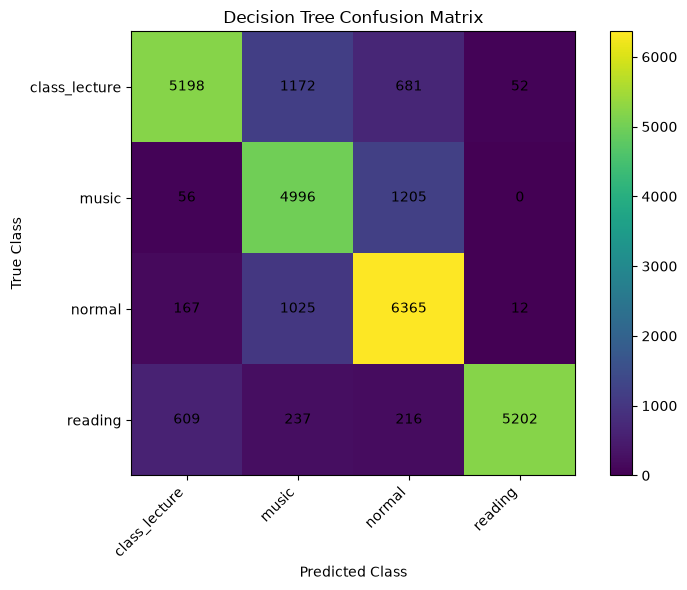

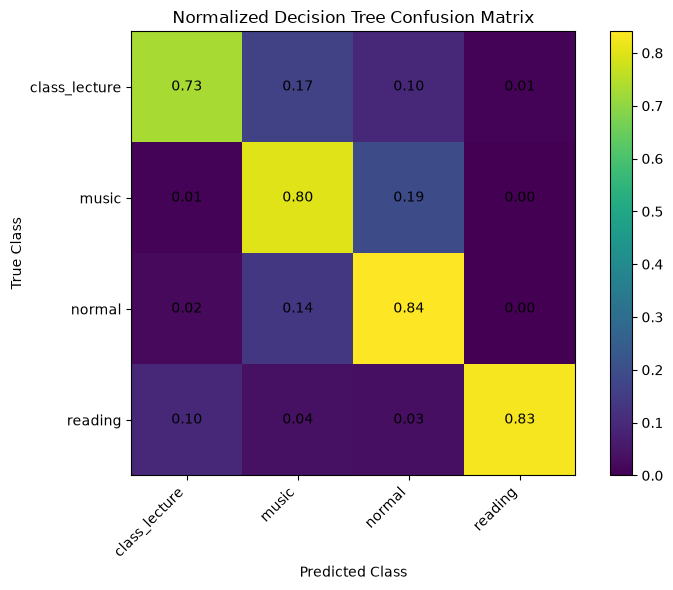


TOP FEATURE IMPORTANCE


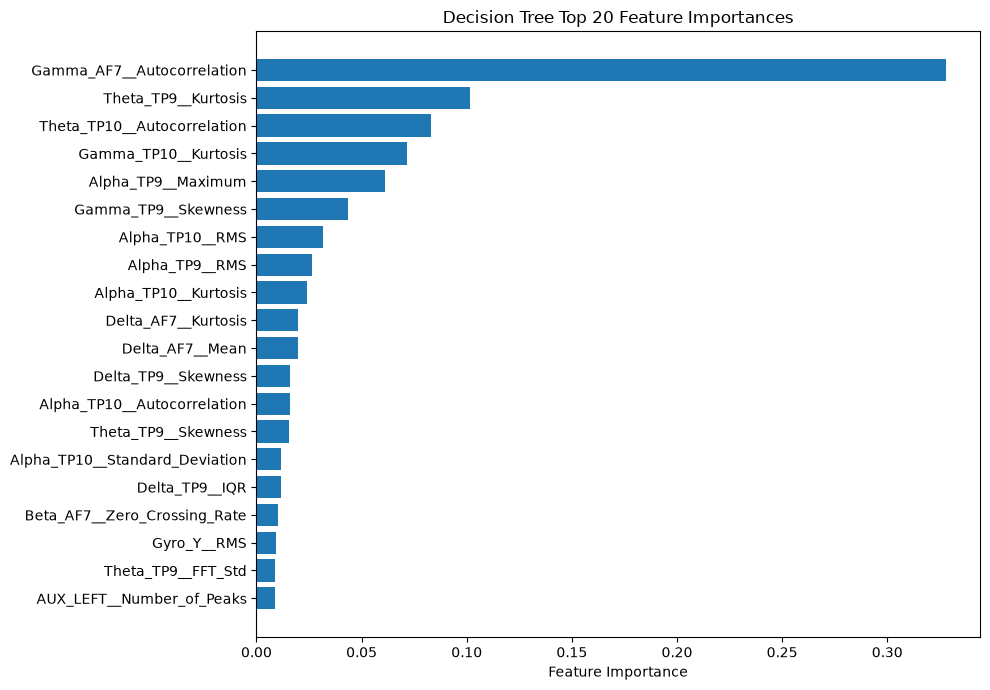

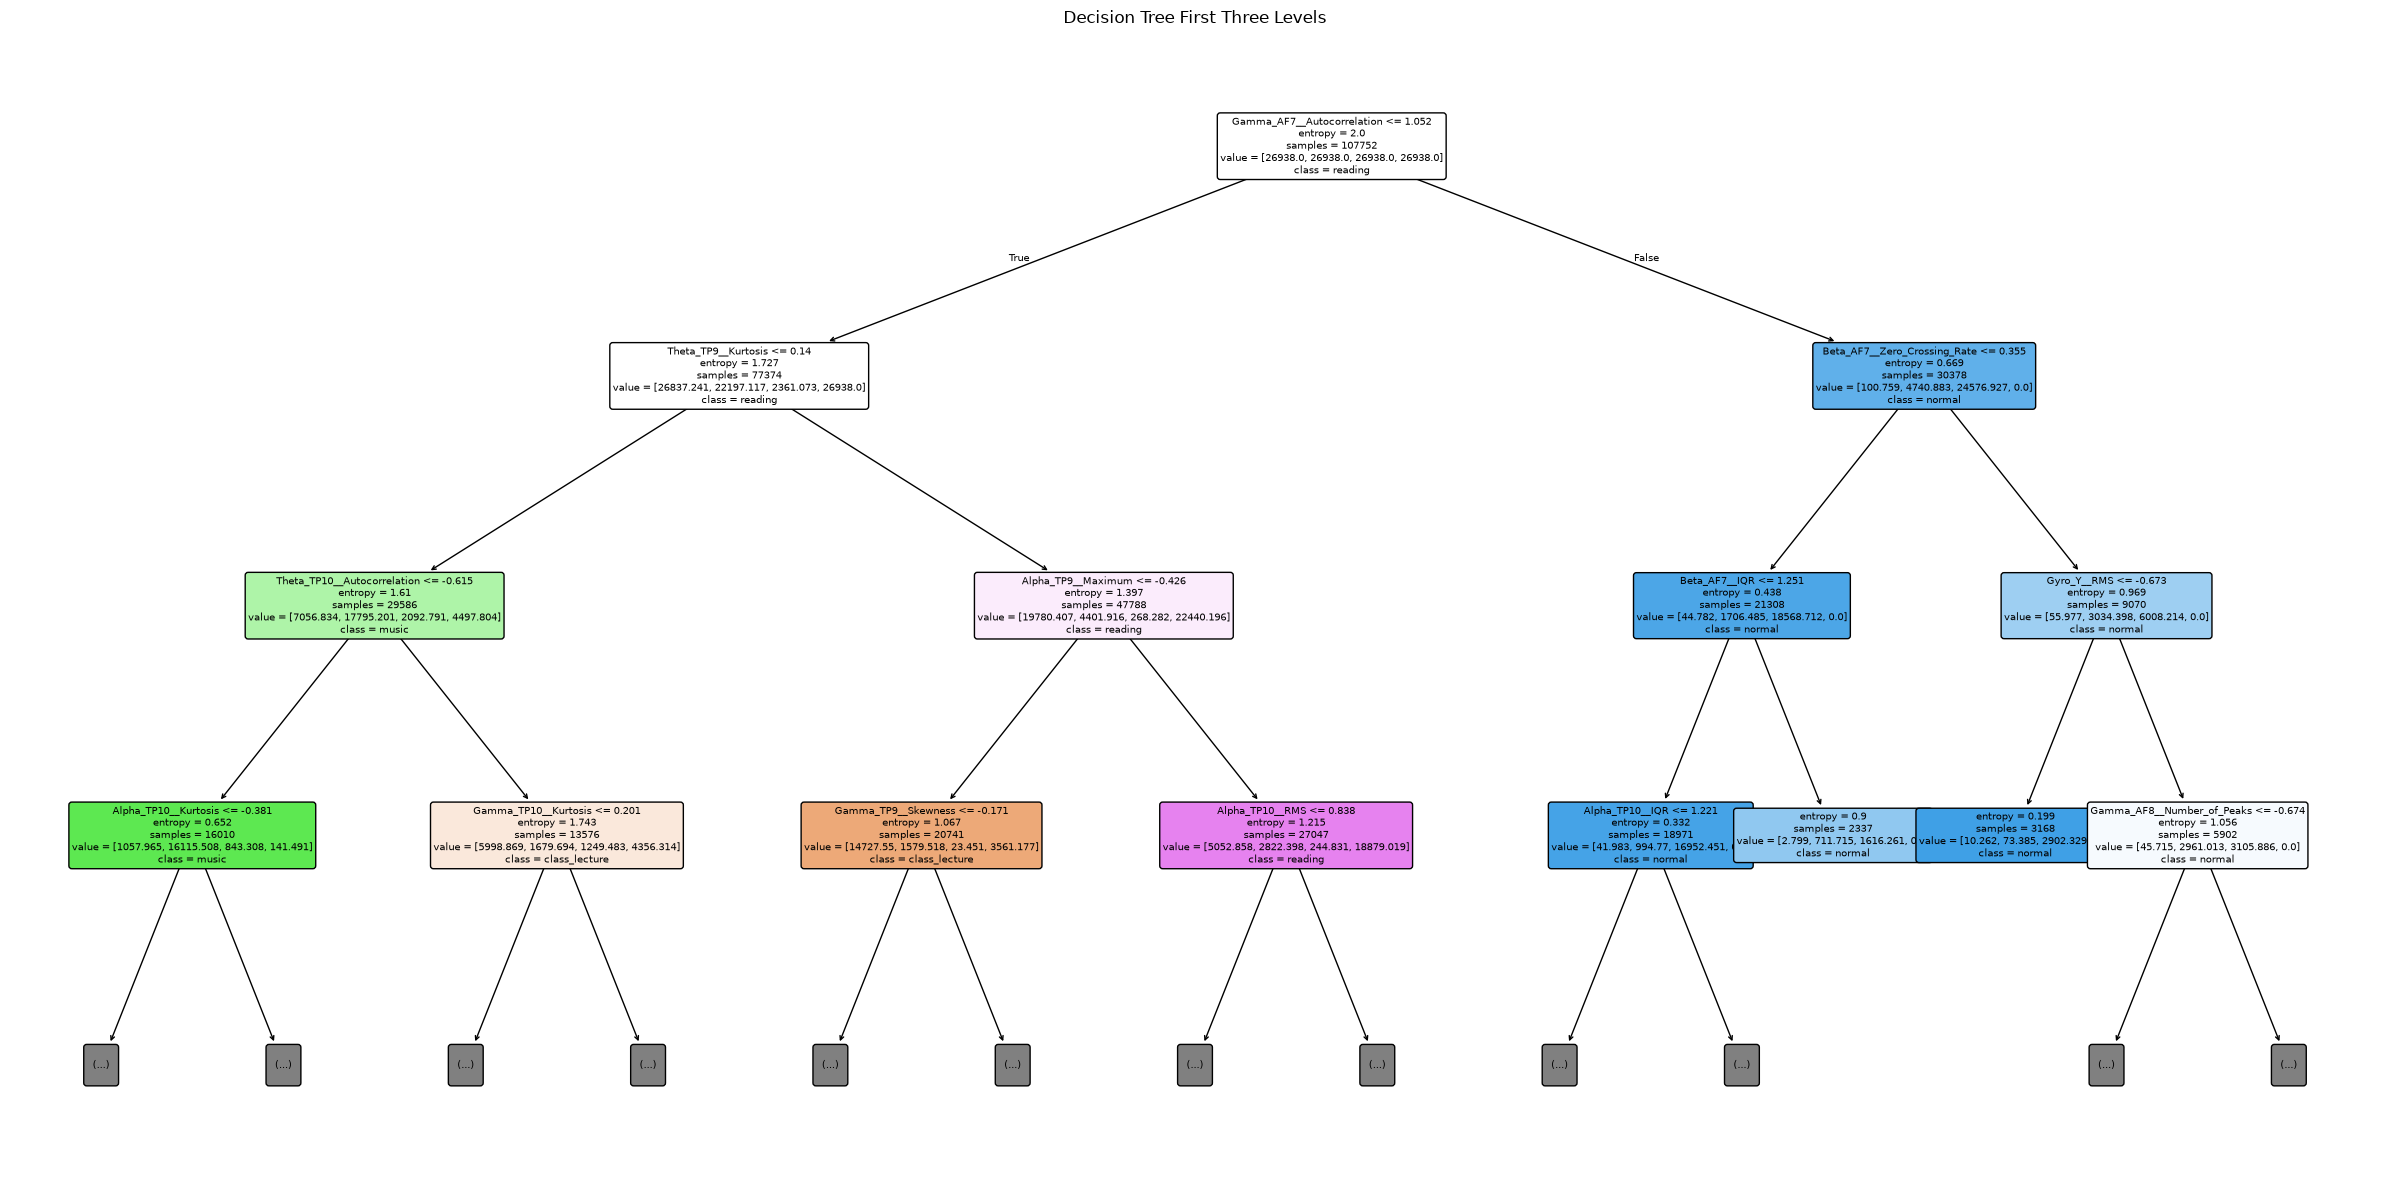


DECISION TREE LEARNING CURVE


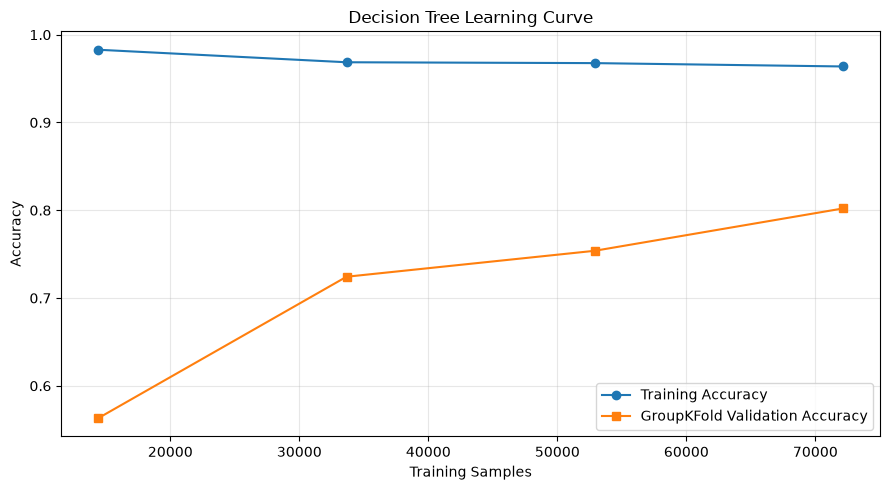

Learning Curve Time: 7.26 seconds

################################################################################
FINAL DECISION TREE RESULTS
MAX DATASET
################################################################################
Feature Count             : 232

Best Criterion            : entropy
Best Maximum Depth        : 23
Best Minimum Split        : 37
Best Minimum Leaf         : 24
Best Maximum Features     : sqrt
Best CCP Alpha            : 3.88e-03

Selected Run              : 5
Selected Random State     : 46
Actual Tree Depth         : 9
Number of Leaves          : 48

Training Accuracy         : 0.9411
Validation Accuracy       : 0.8607
Testing Accuracy          : 0.8002

GroupKFold                : 0.8093 plus or minus 0.0404
Full LOGO                 : 0.7765 plus or minus 0.2224
Full LOGO Folds           : 42

Precision Weighted        : 0.8167
Recall Weighted           : 0.8002
F1 Weighted               : 0.8036
F1 Macro                  : 0.8045
Cohen Kappa      

In [2]:
# ================================================================
# DECISION TREE
# CART
# MAX DATASET
#
# PERSON WISE 70 / 20 / 10
# STANDARDIZATION INSIDE PIPELINE
# OPTUNA 12 TRIALS
# GROUPKFOLD 5
# FIVE RUNS
# FULL LOGO
# NO LOGO CAP
# NO ROW SUBSAMPLING
#
# COMPLETE METRICS
# CONFUSION MATRIX
# NORMALIZED CONFUSION MATRIX
# TOP 20 FEATURE IMPORTANCE
# LEARNING CURVE
# TREE VISUALIZATION
#
# TEST SET USED ONLY FOR FINAL EVALUATION
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import json
import time
import random
import warnings

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut,
    learning_curve
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.pipeline import Pipeline

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ================================================================
# CONFIGURATION
# ================================================================

SEED = 42

N_TRIALS = 12

N_RUNS = 5

GROUP_K_FOLDS = 5


# ================================================================
# FULL LOGO
#
# None means every training participant is evaluated.
# ================================================================

LOGO_MAX_FOLDS = None


# ================================================================
# RANDOMNESS
# ================================================================

random.seed(
    SEED
)

np.random.seed(
    SEED
)


warnings.filterwarnings(
    "ignore"
)


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ================================================================
# MEMORY
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# INPUT
# ================================================================

FILE_PATH = Path(

    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"

)


if not FILE_PATH.exists():

    raise FileNotFoundError(

        f"Input CSV was not found: "
        f"{FILE_PATH}"

    )


# ================================================================
# OUTPUT
# ================================================================

OUTPUT_DIR = (

    FILE_PATH.parent
    / "Max_Dataset_Decision_Tree_Results"

)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


# ================================================================
# OPTUNA DATABASE
#
# Allows completed trials to survive interruptions.
# ================================================================

OPTUNA_DATABASE = (

    OUTPUT_DIR
    / "decision_tree_optuna.db"

)


OPTUNA_STORAGE = (

    f"sqlite:///"
    f"{OPTUNA_DATABASE}"

)


OPTUNA_STUDY_NAME = (

    "Max_Dataset_Decision_Tree_v1"

)


# ================================================================
# TOTAL TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# START INFORMATION
# ================================================================

print("=" * 80)

print(
    "DECISION TREE"
)

print(
    "MAX DATASET"
)

print("=" * 80)


print(
    "Input file:"
)

print(
    FILE_PATH
)


print()

print(
    "Output directory:"
)

print(
    OUTPUT_DIR
)


print()

print(
    "Optuna trials:",
    N_TRIALS
)


print(
    "Final runs:",
    N_RUNS
)


print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)


print(
    "LOGO cap: NONE"
)


print(
    "Row subsampling: NONE"
)


print(
    "Class weight: balanced"
)


print("=" * 80)


# ================================================================
# LOAD DATA
# ================================================================

print()

print("=" * 80)

print(
    "LOADING COMPLETE MAX DATASET"
)

print("=" * 80)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMN DEFINITIONS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


if len(
    feature_cols
) == 0:

    raise ValueError(

        "No feature columns were found."

    )


print(
    "Feature count:",
    len(
        feature_cols
    )
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(

        pd.to_numeric,

        errors="coerce"

    )

    .to_numpy(

        dtype=np.float32

    )

)


# ================================================================
# INVALID VALUE CHECK
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "Feature matrix contains "
        "NaN or infinite values."

    )


# ================================================================
# LABELS
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(

    np.int32

)


class_names = list(

    label_encoder.classes_

)


NUM_CLASSES = len(

    class_names

)


# ================================================================
# PARTICIPANTS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Classes:",
    class_names
)


print(
    "Number of classes:",
    NUM_CLASSES
)


print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

print()

print(
    "CLASS DISTRIBUTION"
)


class_distribution_records = []


for class_index, class_name in enumerate(

    class_names

):

    count = int(

        np.sum(

            y_all
            == class_index

        )

    )


    percentage = (

        count
        / len(
            y_all
        )
        * 100.0

    )


    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


    class_distribution_records.append(

        {

            "Class":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage

        }

    )


pd.DataFrame(

    class_distribution_records

).to_csv(

    OUTPUT_DIR
    / "class_distribution.csv",

    index=False

)


print()

print(
    "Loading time:",
    f"{time.time() - load_start:.2f}",
    "seconds"
)


del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10
# ================================================================

print()

print("=" * 80)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 80)


persons = np.unique(

    groups_all

)


rng = np.random.RandomState(

    SEED

)


rng.shuffle(

    persons

)


number_persons = len(

    persons

)


number_test = max(

    1,

    int(

        round(

            0.20
            * number_persons

        )

    )

)


number_validation = max(

    1,

    int(

        round(

            0.10
            * number_persons

        )

    )

)


# ================================================================
# PARTICIPANT SPLITS
# ================================================================

test_persons = persons[

    :number_test

]


validation_persons = persons[

    number_test:
    number_test
    + number_validation

]


train_persons = persons[

    number_test
    + number_validation:

]


# ================================================================
# MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY NO OVERLAP
# ================================================================

assert (

    np.intersect1d(

        train_persons,

        validation_persons

    ).size == 0

)


assert (

    np.intersect1d(

        train_persons,

        test_persons

    ).size == 0

)


assert (

    np.intersect1d(

        validation_persons,

        test_persons

    ).size == 0

)


# ================================================================
# SPLIT ARRAYS
# ================================================================

X_train = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


g_validation = np.ascontiguousarray(

    groups_all[
        validation_mask
    ]

)


X_test = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


g_test = np.ascontiguousarray(

    groups_all[
        test_mask
    ]

)


print(
    "Training participants:",
    len(
        train_persons
    )
)


print(
    "Validation participants:",
    len(
        validation_persons
    )
)


print(
    "Testing participants:",
    len(
        test_persons
    )
)


print()

print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


# ================================================================
# SAVE SPLIT INFORMATION
# ================================================================

split_table = pd.DataFrame(

    [

        {

            "Split":
                "Training",

            "Participants":
                len(
                    train_persons
                ),

            "Rows":
                len(
                    X_train
                )

        },

        {

            "Split":
                "Validation",

            "Participants":
                len(
                    validation_persons
                ),

            "Rows":
                len(
                    X_validation
                )

        },

        {

            "Split":
                "Testing",

            "Participants":
                len(
                    test_persons
                ),

            "Rows":
                len(
                    X_test
                )

        }

    ]

)


split_table.to_csv(

    OUTPUT_DIR
    / "split_summary.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "participant_split.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "training":

                [
                    str(x)
                    for x
                    in train_persons
                ],

            "validation":

                [
                    str(x)
                    for x
                    in validation_persons
                ],

            "testing":

                [
                    str(x)
                    for x
                    in test_persons
                ]

        },

        file,

        indent=4

    )


# ================================================================
# RELEASE COMPLETE DATA
# ================================================================

del X_all

del y_all

del groups_all

del train_mask

del validation_mask

del test_mask

gc.collect()


print(
    "RAM after split:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# CV SPLITS
# ================================================================

gkf_splits = list(

    GroupKFold(

        n_splits=
            GROUP_K_FOLDS

    ).split(

        X_train,

        y_train,

        g_train

    )

)


logo_splits_full = list(

    LeaveOneGroupOut().split(

        X_train,

        y_train,

        g_train

    )

)


if LOGO_MAX_FOLDS is None:

    logo_splits = (

        logo_splits_full

    )

else:

    logo_splits = (

        logo_splits_full[
            :LOGO_MAX_FOLDS
        ]

    )


print()

print(
    "GroupKFold folds:",
    len(
        gkf_splits
    )
)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


# ================================================================
# DECISION TREE ESTIMATOR
# ================================================================

def make_tree_estimator(

    params,

    random_state=SEED

):

    return DecisionTreeClassifier(

        criterion=
            params[
                "criterion"
            ],

        splitter=
            "best",

        max_depth=
            int(
                params[
                    "max_depth"
                ]
            ),

        min_samples_split=
            int(
                params[
                    "min_samples_split"
                ]
            ),

        min_samples_leaf=
            int(
                params[
                    "min_samples_leaf"
                ]
            ),

        max_features=
            params[
                "max_features"
            ],

        ccp_alpha=
            float(
                params[
                    "ccp_alpha"
                ]
            ),

        class_weight=
            "balanced",

        random_state=
            int(
                random_state
            )

    )


# ================================================================
# PIPELINE
#
# The source code standardizes for parity.
#
# Pipeline prevents scaling information from entering
# GroupKFold or LOGO validation participants.
# ================================================================

def make_dt(

    params,

    random_state=SEED

):

    return Pipeline(

        [

            (

                "scaler",

                StandardScaler()

            ),

            (

                "tree",

                make_tree_estimator(

                    params,

                    random_state=
                        random_state

                )

            )

        ]

    )


# ================================================================
# FIT MODEL
# ================================================================

def fit_dt(

    params,

    X,

    y,

    random_state=SEED

):

    model = make_dt(

        params,

        random_state

    )


    model.fit(

        X,

        y

    )


    return model


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def dt_objective(

    trial

):

    params = {

        "criterion":

            trial.suggest_categorical(

                "criterion",

                [

                    "gini",

                    "entropy"

                ]

            ),

        "max_depth":

            trial.suggest_int(

                "max_depth",

                4,

                30

            ),

        "min_samples_split":

            trial.suggest_int(

                "min_samples_split",

                2,

                50

            ),

        "min_samples_leaf":

            trial.suggest_int(

                "min_samples_leaf",

                1,

                30

            ),

        "max_features":

            trial.suggest_categorical(

                "max_features",

                [

                    None,

                    "sqrt",

                    "log2"

                ]

            ),

        "ccp_alpha":

            trial.suggest_float(

                "ccp_alpha",

                1e-5,

                1e-2,

                log=True

            )

    }


    scores = []


    print()

    print(

        f"Trial "
        f"{trial.number + 1}"

    )


    print(
        params
    )


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        model = fit_dt(

            params,

            X_train[
                train_index
            ],

            y_train[
                train_index
            ],

            random_state=
                SEED

        )


        prediction = model.predict(

            X_train[
                validation_index
            ]

        )


        accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        scores.append(

            accuracy

        )


        tree_model = (

            model.named_steps[
                "tree"
            ]

        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{accuracy:.4f}, "

            f"Depth = "
            f"{tree_model.get_depth()}, "

            f"Leaves = "
            f"{tree_model.get_n_leaves()}, "

            f"Time = "
            f"{time.time() - fold_start:.2f} sec"

        )


        del tree_model

        del model

        del prediction


        gc.collect()


    mean_accuracy = float(

        np.mean(
            scores
        )

    )


    std_accuracy = float(

        np.std(
            scores
        )

    )


    print(

        f"Mean GroupKFold Accuracy = "
        f"{mean_accuracy:.4f} "

        f"plus or minus "
        f"{std_accuracy:.4f}"

    )


    return mean_accuracy


# ================================================================
# OPTUNA
# ================================================================

print()

print("=" * 80)

print(
    "DECISION TREE OPTUNA"
)

print("=" * 80)


optuna_start = time.time()


study = optuna.create_study(

    study_name=
        OPTUNA_STUDY_NAME,

    storage=
        OPTUNA_STORAGE,

    direction=
        "maximize",

    sampler=
        optuna.samplers.TPESampler(

            seed=SEED

        ),

    load_if_exists=
        True

)


# ================================================================
# RESUME ONLY REMAINING TRIALS
# ================================================================

completed_trials = sum(

    1

    for trial in study.trials

    if trial.state
    == optuna.trial.TrialState.COMPLETE

)


remaining_trials = max(

    0,

    N_TRIALS
    - completed_trials

)


print(
    "Previously completed trials:",
    completed_trials
)


print(
    "Remaining trials:",
    remaining_trials
)


if remaining_trials > 0:

    study.optimize(

        dt_objective,

        n_trials=
            remaining_trials,

        show_progress_bar=
            False,

        gc_after_trial=
            True

    )


optuna_time = (

    time.time()
    - optuna_start

)


best_params = {

    "criterion":

        study.best_params[
            "criterion"
        ],

    "max_depth":

        int(

            study.best_params[
                "max_depth"
            ]

        ),

    "min_samples_split":

        int(

            study.best_params[
                "min_samples_split"
            ]

        ),

    "min_samples_leaf":

        int(

            study.best_params[
                "min_samples_leaf"
            ]

        ),

    "max_features":

        study.best_params[
            "max_features"
        ],

    "ccp_alpha":

        float(

            study.best_params[
                "ccp_alpha"
            ]

        )

}


print()

print("=" * 80)

print(
    "OPTUNA COMPLETED"
)

print("=" * 80)


print(
    "Best GroupKFold Accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Best Parameters:"
)


print(
    best_params
)


print(
    "Optuna Time:",
    f"{optuna_time:.2f}",
    "seconds"
)


# ================================================================
# SAVE OPTUNA
# ================================================================

study.trials_dataframe().to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        best_params,

        file,

        indent=4

    )


# ================================================================
# FIVE RUNS
#
# Seeds:
#
# 42
# 43
# 44
# 45
# 46
#
# Best model is selected using validation accuracy.
#
# Test set is not touched.
# ================================================================

print()

print("=" * 80)

print(
    "DECISION TREE FIVE RUNS"
)

print("=" * 80)


run_records = []


best_model = None


best_record = None


best_validation_accuracy = (

    float("-inf")

)


five_run_start = time.time()


for run_number in range(

    1,

    N_RUNS + 1

):

    run_start = time.time()


    random_state = (

        SEED
        + run_number
        - 1

    )


    print()

    print(

        f"RUN "
        f"{run_number}/"
        f"{N_RUNS}"

    )


    # ============================================================
    # GROUPKFOLD
    # ============================================================

    cv_scores = []


    cv_depths = []


    cv_leaves = []


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_model = fit_dt(

            best_params,

            X_train[
                train_index
            ],

            y_train[
                train_index
            ],

            random_state=
                random_state

        )


        fold_prediction = fold_model.predict(

            X_train[
                validation_index
            ]

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            fold_prediction

        )


        fold_tree = (

            fold_model.named_steps[
                "tree"
            ]

        )


        cv_scores.append(

            fold_accuracy

        )


        cv_depths.append(

            int(
                fold_tree.get_depth()
            )

        )


        cv_leaves.append(

            int(
                fold_tree.get_n_leaves()
            )

        )


        print(

            f"Run "
            f"{run_number}, "

            f"GKF "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Depth = "
            f"{fold_tree.get_depth()}, "

            f"Leaves = "
            f"{fold_tree.get_n_leaves()}"

        )


        del fold_tree

        del fold_model

        del fold_prediction


        gc.collect()


    # ============================================================
    # FULL TRAIN MODEL
    # ============================================================

    model = fit_dt(

        best_params,

        X_train,

        y_train,

        random_state=
            random_state

    )


    tree_model = (

        model.named_steps[
            "tree"
        ]

    )


    # ============================================================
    # TRAIN ACCURACY
    # ============================================================

    training_prediction = model.predict(

        X_train

    )


    training_accuracy = accuracy_score(

        y_train,

        training_prediction

    )


    # ============================================================
    # VALIDATION
    # ============================================================

    validation_probability = (

        model.predict_proba(

            X_validation

        )

    )


    validation_prediction = np.argmax(

        validation_probability,

        axis=1

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    run_time = (

        time.time()
        - run_start

    )


    record = {

        "Run":

            run_number,

        "Random_State":

            random_state,

        "Training_Accuracy":

            float(
                training_accuracy
            ),

        "Validation_Accuracy":

            float(
                validation_accuracy
            ),

        "GroupKFold_Accuracy":

            float(
                np.mean(
                    cv_scores
                )
            ),

        "GroupKFold_STD":

            float(
                np.std(
                    cv_scores
                )
            ),

        "Actual_Depth":

            int(
                tree_model.get_depth()
            ),

        "Number_of_Leaves":

            int(
                tree_model.get_n_leaves()
            ),

        "Mean_CV_Depth":

            float(
                np.mean(
                    cv_depths
                )
            ),

        "Mean_CV_Leaves":

            float(
                np.mean(
                    cv_leaves
                )
            ),

        "Execution_Time_Seconds":

            float(
                run_time
            )

    }


    run_records.append(

        record

    )


    print()

    print(

        f"[DT {run_number}] "

        f"Train = "
        f"{training_accuracy:.4f}, "

        f"Validation = "
        f"{validation_accuracy:.4f}, "

        f"GKF = "
        f"{record['GroupKFold_Accuracy']:.4f} "

        f"plus or minus "
        f"{record['GroupKFold_STD']:.4f}, "

        f"Depth = "
        f"{record['Actual_Depth']}, "

        f"Leaves = "
        f"{record['Number_of_Leaves']}, "

        f"Time = "
        f"{run_time:.2f} sec"

    )


    # ============================================================
    # SELECT USING VALIDATION ONLY
    # ============================================================

    if (

        validation_accuracy
        > best_validation_accuracy

    ):

        if best_model is not None:

            del best_model


        best_model = model


        best_record = (

            record.copy()

        )


        best_validation_accuracy = (

            validation_accuracy

        )


    else:

        del model


    del tree_model

    del training_prediction

    del validation_probability

    del validation_prediction


    gc.collect()


five_run_time = (

    time.time()
    - five_run_start

)


run_table = pd.DataFrame(

    run_records

)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()

print(
    run_table
    .round(4)
    .to_string(
        index=False
    )
)


print()

print(
    "Selected Run:",
    best_record[
        "Run"
    ]
)


print(
    "Selected Random State:",
    best_record[
        "Random_State"
    ]
)


print(
    "Selected Validation Accuracy:",
    f"{best_validation_accuracy:.4f}"
)


# ================================================================
# SAVE BEST MODEL
#
# The saved Pipeline contains both scaler and tree.
# ================================================================

joblib.dump(

    best_model,

    OUTPUT_DIR
    / "decision_tree_best_model.joblib"

)


# ================================================================
# FULL LOGO
# ================================================================

print()

print("=" * 80)

print(
    "FULL LEAVE ONE GROUP OUT"
)

print("=" * 80)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


logo_result_path = (

    OUTPUT_DIR
    / "full_logo_results.csv"

)


# ================================================================
# RESUME LOGO
# ================================================================

if logo_result_path.exists():

    previous_logo = pd.read_csv(

        logo_result_path

    )


    completed_persons = set(

        previous_logo[
            "Held_Out_Person"
        ].astype(str)

    )


    logo_records = (

        previous_logo
        .to_dict(
            orient="records"
        )

    )


    print(
        "Previously completed LOGO folds:",
        len(
            completed_persons
        )
    )


else:

    completed_persons = set()

    logo_records = []


logo_start = time.time()


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    logo_splits,

    start=1

):

    held_out_person = str(

        np.unique(

            g_train[
                validation_index
            ]

        )[0]

    )


    if (

        held_out_person
        in completed_persons

    ):

        print(

            f"LOGO "
            f"{fold_number}/"
            f"{len(logo_splits)}, "

            f"Participant "
            f"{held_out_person} "

            f"already completed"

        )


        continue


    fold_start = time.time()


    model = fit_dt(

        best_params,

        X_train[
            train_index
        ],

        y_train[
            train_index
        ],

        random_state=
            best_record[
                "Random_State"
            ]

    )


    prediction = model.predict(

        X_train[
            validation_index
        ]

    )


    accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    tree_model = (

        model.named_steps[
            "tree"
        ]

    )


    fold_time = (

        time.time()
        - fold_start

    )


    record = {

        "Fold":

            fold_number,

        "Held_Out_Person":

            held_out_person,

        "Rows":

            int(
                len(
                    validation_index
                )
            ),

        "Accuracy":

            float(
                accuracy
            ),

        "Depth":

            int(
                tree_model.get_depth()
            ),

        "Leaves":

            int(
                tree_model.get_n_leaves()
            ),

        "Execution_Time_Seconds":

            float(
                fold_time
            )

    }


    logo_records.append(

        record

    )


    # ============================================================
    # SAVE AFTER EVERY LOGO FOLD
    # ============================================================

    pd.DataFrame(

        logo_records

    ).to_csv(

        logo_result_path,

        index=False

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "

        f"Participant = "
        f"{held_out_person}, "

        f"Accuracy = "
        f"{accuracy:.4f}, "

        f"Depth = "
        f"{tree_model.get_depth()}, "

        f"Leaves = "
        f"{tree_model.get_n_leaves()}, "

        f"Time = "
        f"{fold_time:.2f} sec"

    )


    del tree_model

    del model

    del prediction


    gc.collect()


logo_time = (

    time.time()
    - logo_start

)


# ================================================================
# COMPLETE LOGO STATISTICS
# ================================================================

logo_table = pd.read_csv(

    logo_result_path

)


logo_scores = (

    logo_table[
        "Accuracy"
    ]

    .astype(float)

    .to_numpy()

)


logo_mean = float(

    np.mean(
        logo_scores
    )

)


logo_std = float(

    np.std(
        logo_scores
    )

)


print()

print(
    "Full LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "Completed LOGO folds:",
    len(
        logo_table
    )
)


print(
    "LOGO Time This Session:",
    f"{logo_time:.2f}",
    "seconds"
)


# ================================================================
# FINAL UNTOUCHED TEST EVALUATION
# ================================================================

print()

print("=" * 80)

print(
    "FINAL UNTOUCHED TEST EVALUATION"
)

print("=" * 80)


test_start = time.time()


test_probability = (

    best_model.predict_proba(

        X_test

    )

)


test_prediction = np.argmax(

    test_probability,

    axis=1

)


test_time = (

    time.time()
    - test_start

)


# ================================================================
# TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average="macro",

    zero_division=0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


# ================================================================
# ROC AUC
# ================================================================

try:

    test_roc_auc = roc_auc_score(

        y_test,

        test_probability,

        multi_class="ovr",

        average="weighted"

    )


except Exception:

    test_roc_auc = np.nan


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    ),

    target_names=
        class_names,

    digits=4,

    zero_division=0

)


print()

print(
    "CLASSIFICATION REPORT"
)


print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(
        report
    )


report_table = pd.DataFrame(

    classification_report(

        y_test,

        test_prediction,

        labels=np.arange(
            NUM_CLASSES
        ),

        target_names=
            class_names,

        output_dict=True,

        zero_division=0

    )

).transpose()


report_table.to_csv(

    OUTPUT_DIR
    / "classification_report.csv"

)


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    )

)


pd.DataFrame(

    cm,

    index=
        class_names,

    columns=
        class_names

).to_csv(

    OUTPUT_DIR
    / "confusion_matrix.csv"

)


# ================================================================
# CONFUSION MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(
        8,
        6
    )

)


image = ax.imshow(

    cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "Decision Tree Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            str(

                cm[
                    row,
                    column
                ]

            ),

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(

    axis=1,

    keepdims=True

)


normalized_cm = np.divide(

    cm,

    row_sums,

    out=np.zeros_like(

        cm,

        dtype=np.float64

    ),

    where=(

        row_sums != 0

    )

)


pd.DataFrame(

    normalized_cm,

    index=
        class_names,

    columns=
        class_names

).to_csv(

    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"

)


# ================================================================
# NORMALIZED MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(
        8,
        6
    )

)


image = ax.imshow(

    normalized_cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "Normalized Decision Tree Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            f"{normalized_cm[row, column]:.2f}",

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "normalized_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {

        "PersonSrial":

            g_test,

        "True_Class":

            label_encoder.inverse_transform(

                y_test

            ),

        "Predicted_Class":

            label_encoder.inverse_transform(

                test_prediction.astype(
                    np.int32
                )

            )

    }

)


for class_index, class_name in enumerate(

    class_names

):

    prediction_table[

        f"Probability_{class_name}"

    ] = test_probability[

        :,

        class_index

    ]


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# FEATURE IMPORTANCE
# ================================================================

print()

print("=" * 80)

print(
    "TOP FEATURE IMPORTANCE"
)

print("=" * 80)


best_tree = (

    best_model.named_steps[
        "tree"
    ]

)


feature_importance = (

    best_tree.feature_importances_

)


importance_table = pd.DataFrame(

    {

        "Feature":

            feature_cols,

        "Importance":

            feature_importance

    }

)


importance_table = (

    importance_table

    .sort_values(

        by=
            "Importance",

        ascending=
            False

    )

    .reset_index(

        drop=True

    )

)


importance_table.to_csv(

    OUTPUT_DIR
    / "feature_importance.csv",

    index=False

)


top_20 = (

    importance_table
    .head(
        20
    )
    .iloc[::-1]

)


fig, ax = plt.subplots(

    figsize=(
        10,
        7
    )

)


ax.barh(

    top_20[
        "Feature"
    ],

    top_20[
        "Importance"
    ]

)


ax.set_xlabel(

    "Feature Importance"

)


ax.set_title(

    "Decision Tree Top 20 Feature Importances"

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "top_20_feature_importance.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# TREE VISUALIZATION
#
# Only first 3 levels are drawn.
# Full trees can be too large to display.
# ================================================================

fig, ax = plt.subplots(

    figsize=(
        24,
        12
    )

)


plot_tree(

    best_tree,

    feature_names=
        feature_cols,

    class_names=
        class_names,

    filled=
        True,

    rounded=
        True,

    max_depth=
        3,

    fontsize=
        7,

    ax=
        ax

)


ax.set_title(

    "Decision Tree First Three Levels"

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "decision_tree_first_3_levels.png",

    dpi=200,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# LEARNING CURVE
#
# Pipeline means scaler is trained separately inside
# each training fold.
# ================================================================

print()

print("=" * 80)

print(
    "DECISION TREE LEARNING CURVE"
)

print("=" * 80)


learning_start = time.time()


learning_model = make_dt(

    best_params,

    random_state=
        best_record[
            "Random_State"
        ]

)


learning_cv = GroupKFold(

    n_splits=3

)


train_sizes, train_scores, validation_scores = (

    learning_curve(

        learning_model,

        X_train,

        y_train,

        groups=
            g_train,

        cv=
            learning_cv,

        scoring=
            "accuracy",

        train_sizes=
            np.linspace(

                0.20,

                1.00,

                4

            ),

        n_jobs=
            1

    )

)


learning_time = (

    time.time()
    - learning_start

)


learning_table = pd.DataFrame(

    {

        "Training_Samples":

            train_sizes,

        "Training_Accuracy_Mean":

            train_scores.mean(
                axis=1
            ),

        "Training_Accuracy_STD":

            train_scores.std(
                axis=1
            ),

        "Validation_Accuracy_Mean":

            validation_scores.mean(
                axis=1
            ),

        "Validation_Accuracy_STD":

            validation_scores.std(
                axis=1
            )

    }

)


learning_table.to_csv(

    OUTPUT_DIR
    / "learning_curve.csv",

    index=False

)


# ================================================================
# LEARNING CURVE FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(
        9,
        5
    )

)


ax.plot(

    train_sizes,

    train_scores.mean(
        axis=1
    ),

    marker="o",

    label=
        "Training Accuracy"

)


ax.plot(

    train_sizes,

    validation_scores.mean(
        axis=1
    ),

    marker="s",

    label=
        "GroupKFold Validation Accuracy"

)


ax.set_xlabel(

    "Training Samples"

)


ax.set_ylabel(

    "Accuracy"

)


ax.set_title(

    "Decision Tree Learning Curve"

)


ax.legend()


ax.grid(

    alpha=0.3

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "learning_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


print(
    "Learning Curve Time:",
    f"{learning_time:.2f}",
    "seconds"
)


# ================================================================
# FIVE RUN STATISTICS
# ================================================================

run_train_mean = float(

    run_table[
        "Training_Accuracy"
    ].mean()

)


run_train_std = float(

    run_table[
        "Training_Accuracy"
    ].std(
        ddof=0
    )

)


run_validation_mean = float(

    run_table[
        "Validation_Accuracy"
    ].mean()

)


run_validation_std = float(

    run_table[
        "Validation_Accuracy"
    ].std(
        ddof=0
    )

)


run_cv_mean = float(

    run_table[
        "GroupKFold_Accuracy"
    ].mean()

)


run_cv_std = float(

    run_table[
        "GroupKFold_Accuracy"
    ].std(
        ddof=0
    )

)


# ================================================================
# TOTAL TIME
# ================================================================

total_execution_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {

    "Algorithm":

        "Decision Tree",

    "Dataset":

        "Max Dataset",

    "Input_File":

        str(
            FILE_PATH
        ),

    "Output_Directory":

        str(
            OUTPUT_DIR
        ),

    "Feature_Count":

        int(
            len(
                feature_cols
            )
        ),

    "Classes":

        class_names,

    "Training_Participants":

        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":

        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":

        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":

        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":

        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":

        int(
            len(
                X_test
            )
        ),

    "Optuna_Trials_Target":

        int(
            N_TRIALS
        ),

    "Optuna_GroupKFold_Accuracy":

        float(
            study.best_value
        ),

    "Best_Parameters":

        best_params,

    "Selected_Run":

        int(
            best_record[
                "Run"
            ]
        ),

    "Selected_Random_State":

        int(
            best_record[
                "Random_State"
            ]
        ),

    "Training_Accuracy":

        float(
            best_record[
                "Training_Accuracy"
            ]
        ),

    "Validation_Accuracy":

        float(
            best_record[
                "Validation_Accuracy"
            ]
        ),

    "Testing_Accuracy":

        float(
            test_accuracy
        ),

    "GroupKFold_Accuracy":

        float(
            best_record[
                "GroupKFold_Accuracy"
            ]
        ),

    "GroupKFold_STD":

        float(
            best_record[
                "GroupKFold_STD"
            ]
        ),

    "Actual_Tree_Depth":

        int(
            best_record[
                "Actual_Depth"
            ]
        ),

    "Number_of_Leaves":

        int(
            best_record[
                "Number_of_Leaves"
            ]
        ),

    "Five_Run_Training_Mean":

        run_train_mean,

    "Five_Run_Training_STD":

        run_train_std,

    "Five_Run_Validation_Mean":

        run_validation_mean,

    "Five_Run_Validation_STD":

        run_validation_std,

    "Five_Run_GroupKFold_Mean":

        run_cv_mean,

    "Five_Run_GroupKFold_STD":

        run_cv_std,

    "Full_LOGO_Accuracy":

        float(
            logo_mean
        ),

    "Full_LOGO_STD":

        float(
            logo_std
        ),

    "Full_LOGO_Folds":

        int(
            len(
                logo_table
            )
        ),

    "Precision_Weighted":

        float(
            test_precision
        ),

    "Recall_Weighted":

        float(
            test_recall
        ),

    "F1_Weighted":

        float(
            test_f1_weighted
        ),

    "F1_Macro":

        float(
            test_f1_macro
        ),

    "Cohen_Kappa":

        float(
            test_kappa
        ),

    "MCC":

        float(
            test_mcc
        ),

    "ROC_AUC_Weighted_OVR":

        None

        if np.isnan(
            test_roc_auc
        )

        else float(
            test_roc_auc
        ),

    "Optuna_Time_Seconds":

        float(
            optuna_time
        ),

    "Five_Run_Time_Seconds":

        float(
            five_run_time
        ),

    "LOGO_Time_This_Session_Seconds":

        float(
            logo_time
        ),

    "Test_Time_Seconds":

        float(
            test_time
        ),

    "Learning_Curve_Time_Seconds":

        float(
            learning_time
        ),

    "Total_Execution_Time_Seconds":

        float(
            total_execution_time
        ),

    "Current_RAM_MB":

        float(
            mem_mb()
        )

}


with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=4

    )


# ================================================================
# FINAL TEXT SUMMARY
# ================================================================

summary_lines = [

    "DECISION TREE",

    "MAX DATASET",

    "",

    f"Input File: "
    f"{FILE_PATH}",

    f"Output Directory: "
    f"{OUTPUT_DIR}",

    "",

    f"Feature Count: "
    f"{len(feature_cols)}",

    f"Classes: "
    f"{class_names}",

    "",

    f"Training Participants: "
    f"{len(train_persons)}",

    f"Validation Participants: "
    f"{len(validation_persons)}",

    f"Testing Participants: "
    f"{len(test_persons)}",

    "",

    f"Best Parameters: "
    f"{best_params}",

    "",

    f"Selected Run: "
    f"{best_record['Run']}",

    f"Selected Random State: "
    f"{best_record['Random_State']}",

    "",

    f"Training Accuracy: "
    f"{best_record['Training_Accuracy']:.4f}",

    f"Validation Accuracy: "
    f"{best_record['Validation_Accuracy']:.4f}",

    f"Testing Accuracy: "
    f"{test_accuracy:.4f}",

    "",

    f"GroupKFold Accuracy: "
    f"{best_record['GroupKFold_Accuracy']:.4f} "
    f"plus or minus "
    f"{best_record['GroupKFold_STD']:.4f}",

    f"Full LOGO Accuracy: "
    f"{logo_mean:.4f} "
    f"plus or minus "
    f"{logo_std:.4f}",

    f"Full LOGO Folds: "
    f"{len(logo_table)}",

    "",

    f"Tree Depth: "
    f"{best_record['Actual_Depth']}",

    f"Tree Leaves: "
    f"{best_record['Number_of_Leaves']}",

    "",

    f"Precision Weighted: "
    f"{test_precision:.4f}",

    f"Recall Weighted: "
    f"{test_recall:.4f}",

    f"F1 Weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 Macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    (
        "ROC AUC Weighted OVR: N/A"

        if np.isnan(
            test_roc_auc
        )

        else

        f"ROC AUC Weighted OVR: "
        f"{test_roc_auc:.4f}"
    ),

    "",

    f"Optuna Time: "
    f"{optuna_time:.2f} seconds",

    f"Five Run Time: "
    f"{five_run_time:.2f} seconds",

    f"LOGO Time This Session: "
    f"{logo_time:.2f} seconds",

    f"Learning Curve Time: "
    f"{learning_time:.2f} seconds",

    f"Total Execution Time: "
    f"{total_execution_time:.2f} seconds"

]


with open(

    OUTPUT_DIR
    / "final_summary.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(

        "\n".join(
            summary_lines
        )

    )


# ================================================================
# FINAL SCREEN OUTPUT
# ================================================================

print()

print("#" * 80)

print(
    "FINAL DECISION TREE RESULTS"
)

print(
    "MAX DATASET"
)

print("#" * 80)


print(
    "Feature Count             :",
    len(
        feature_cols
    )
)


print()

print(
    "Best Criterion            :",
    best_params[
        "criterion"
    ]
)


print(
    "Best Maximum Depth        :",
    best_params[
        "max_depth"
    ]
)


print(
    "Best Minimum Split        :",
    best_params[
        "min_samples_split"
    ]
)


print(
    "Best Minimum Leaf         :",
    best_params[
        "min_samples_leaf"
    ]
)


print(
    "Best Maximum Features     :",
    best_params[
        "max_features"
    ]
)


print(
    "Best CCP Alpha            :",
    f"{best_params['ccp_alpha']:.2e}"
)


print()

print(
    "Selected Run              :",
    best_record[
        "Run"
    ]
)


print(
    "Selected Random State     :",
    best_record[
        "Random_State"
    ]
)


print(
    "Actual Tree Depth         :",
    best_record[
        "Actual_Depth"
    ]
)


print(
    "Number of Leaves          :",
    best_record[
        "Number_of_Leaves"
    ]
)


print()

print(
    "Training Accuracy         :",
    f"{best_record['Training_Accuracy']:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{best_record['Validation_Accuracy']:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "GroupKFold                :",
    f"{best_record['GroupKFold_Accuracy']:.4f}",
    "plus or minus",
    f"{best_record['GroupKFold_STD']:.4f}"
)


print(
    "Full LOGO                 :",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "Full LOGO Folds           :",
    len(
        logo_table
    )
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


if np.isnan(
    test_roc_auc
):

    print(
        "ROC AUC Weighted OVR      : N/A"
    )

else:

    print(
        "ROC AUC Weighted OVR      :",
        f"{test_roc_auc:.4f}"
    )


print()

print(
    "Optuna Time               :",
    f"{optuna_time:.2f}",
    "seconds"
)


print(
    "Five Run Time             :",
    f"{five_run_time:.2f}",
    "seconds"
)


print(
    "Full LOGO Time            :",
    f"{logo_time:.2f}",
    "seconds"
)


print(
    "Learning Curve Time       :",
    f"{learning_time:.2f}",
    "seconds"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time:.2f}",
    "seconds"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "No rows were subsampled."
)


print(
    "No LOGO folds were capped."
)


print(
    "All five GroupKFold folds were used."
)


print(
    "Test participants were not used "
    "during tuning or model selection."
)


print()

print(
    "ALL RESULTS SAVED IN:"
)


print(
    OUTPUT_DIR
)


print("#" * 80)

**Apply NAIVE BAYES (Gaussian) on Max Dataset**

GAUSSIAN NAIVE BAYES
MAX DATASET
Input file:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Cleaned_oN_Selected_Max.csv

Output directory:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Max_Dataset_Gaussian_Naive_Bayes_Results

Optuna trials: 12
Final runs: 5
GroupKFold folds: 5
LOGO cap: NONE
Uniform class priors: True
Data subsampling: NONE

LOADING COMPLETE MAX DATASET
Raw dataset shape: (149350, 238)
RAM after loading: 763.39 MB
Feature count: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

Loading time: 8.40 seconds

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training: (107752, 232)
Validation: (14405, 232)
Testing: (27193, 232)

RAM after split: 540.53 MB

GroupKFold folds: 5
Available LOGO folds:

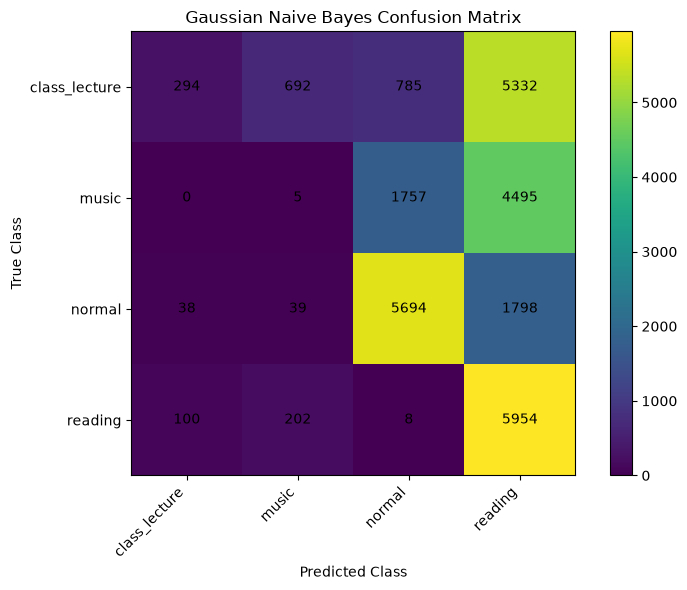

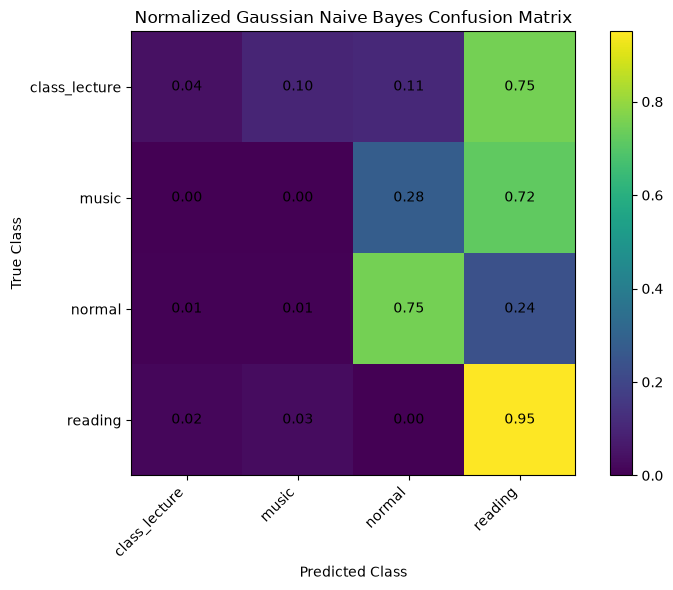


GAUSSIAN NB CLASS PROFILE


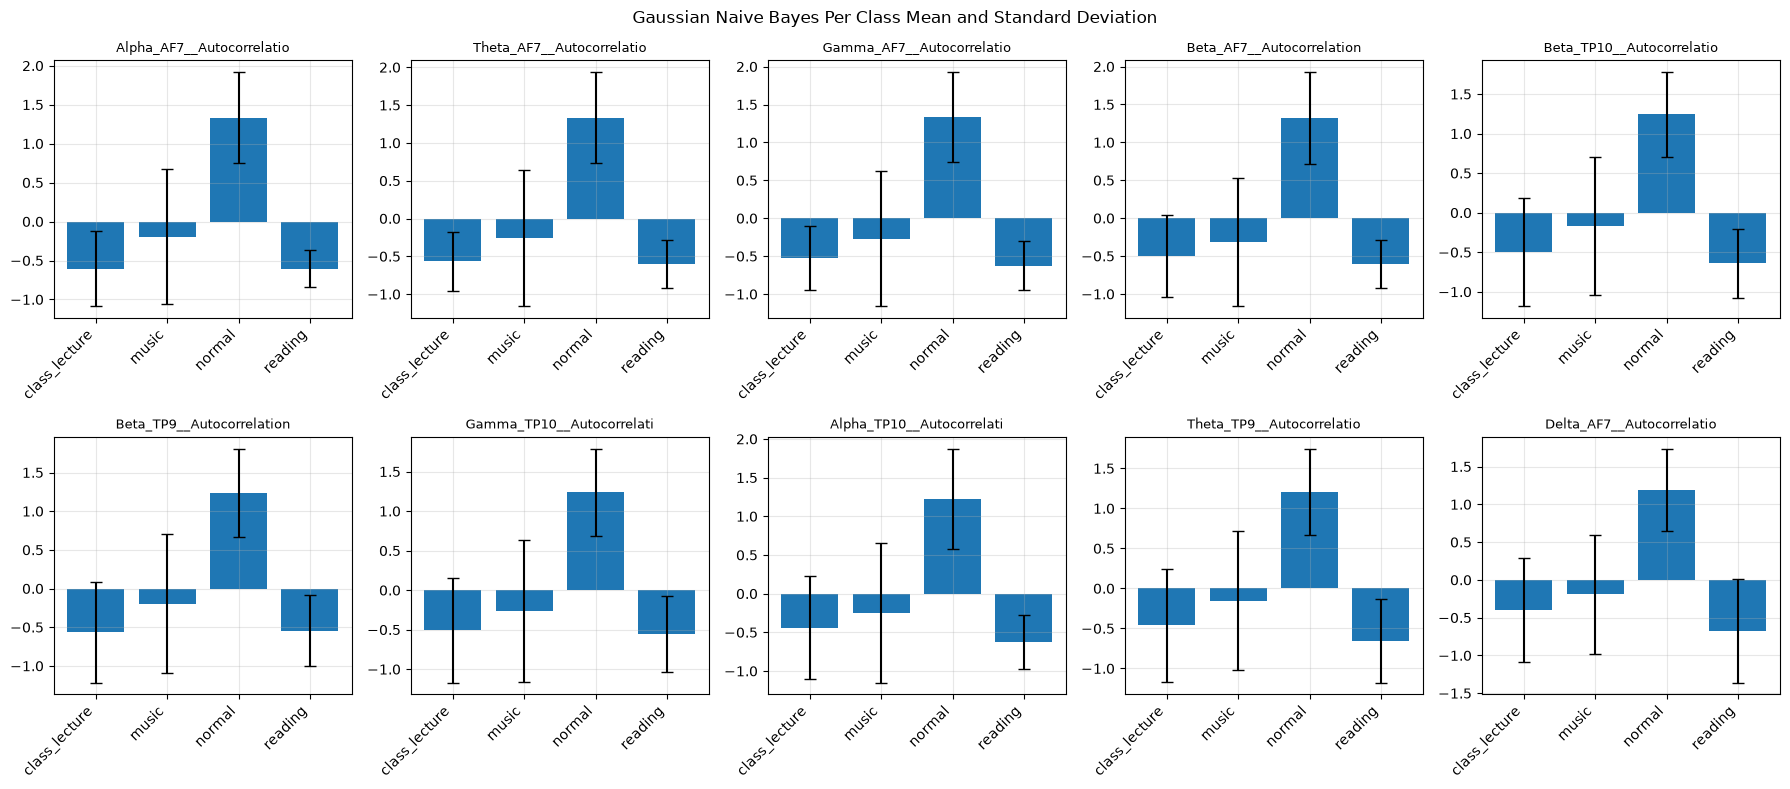


GAUSSIAN NAIVE BAYES LEARNING CURVE


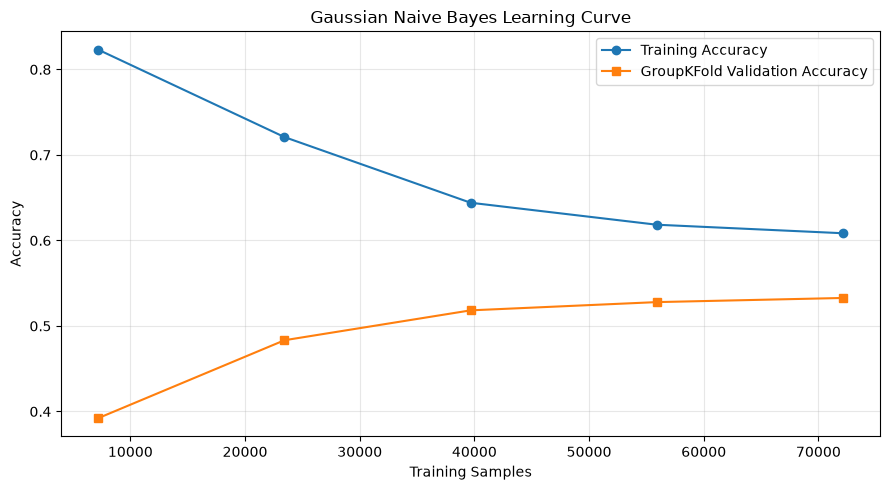

Learning Curve Time: 4.65 seconds

################################################################################
FINAL GAUSSIAN NAIVE BAYES RESULTS
MAX DATASET
################################################################################
Feature Count             : 232
Uniform Class Priors      : True

Optuna Best Smoothing     : 2.34888130e-09
Selected Run              : 1
Selected Smoothing        : 1.48204390e-09

Training Accuracy         : 0.5895
Validation Accuracy       : 0.6042
Testing Accuracy          : 0.4393

GroupKFold                : 0.5467 plus or minus 0.0693
Full LOGO                 : 0.5479 plus or minus 0.2354
Full LOGO Folds           : 42

Precision Weighted        : 0.4493
Recall Weighted           : 0.4393
F1 Weighted               : 0.3362
F1 Macro                  : 0.3248
Cohen Kappa               : 0.2570
MCC                       : 0.3207
ROC AUC Weighted OVR      : N/A

Optuna Time               : 25.69 seconds
Five Run Time             : 13.13 seco

In [3]:
# ================================================================
# GAUSSIAN NAIVE BAYES
# MAX DATASET
#
# PERSON WISE 70 / 20 / 10
# STANDARDIZATION INSIDE PIPELINE
# OPTUNA 12 TRIALS
# GROUPKFOLD 5
# FIVE RUNS
# FULL LOGO
# NO LOGO CAP
# NO DATA SUBSAMPLING
#
# COMPLETE METRICS
# CONFUSION MATRIX
# NORMALIZED CONFUSION MATRIX
# GAUSSIAN CLASS PROFILE
# LEARNING CURVE
#
# TEST DATA USED ONLY FOR FINAL EVALUATION
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import json
import time
import random
import warnings

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut,
    learning_curve
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import (
    GaussianNB
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ================================================================
# CONFIGURATION
# ================================================================

SEED = 42

N_TRIALS = 12

N_RUNS = 5

GROUP_K_FOLDS = 5


# ================================================================
# FULL LOGO
#
# None means use every training participant.
# ================================================================

LOGO_MAX_FOLDS = None


# ================================================================
# CLASS PRIOR CONFIGURATION
#
# Same behavior as the supplied Med code.
#
# True means each class receives prior probability 1 / K.
# ================================================================

USE_UNIFORM_PRIORS = True


# ================================================================
# RANDOMNESS
# ================================================================

random.seed(
    SEED
)

np.random.seed(
    SEED
)


warnings.filterwarnings(
    "ignore"
)


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ================================================================
# MEMORY MONITOR
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# INPUT
# ================================================================

FILE_PATH = Path(

    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"

)


if not FILE_PATH.exists():

    raise FileNotFoundError(

        f"Input file was not found: "
        f"{FILE_PATH}"

    )


# ================================================================
# OUTPUT
# ================================================================

OUTPUT_DIR = (

    FILE_PATH.parent
    / "Max_Dataset_Gaussian_Naive_Bayes_Results"

)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


# ================================================================
# OPTUNA DATABASE
#
# Completed trials can continue after interruption.
# ================================================================

OPTUNA_DATABASE = (

    OUTPUT_DIR
    / "gaussian_nb_optuna.db"

)


OPTUNA_STORAGE = (

    f"sqlite:///"
    f"{OPTUNA_DATABASE}"

)


OPTUNA_STUDY_NAME = (

    "Max_Dataset_Gaussian_NB_v1"

)


# ================================================================
# TOTAL TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# START INFORMATION
# ================================================================

print("=" * 80)

print(
    "GAUSSIAN NAIVE BAYES"
)

print(
    "MAX DATASET"
)

print("=" * 80)


print(
    "Input file:"
)

print(
    FILE_PATH
)


print()

print(
    "Output directory:"
)

print(
    OUTPUT_DIR
)


print()

print(
    "Optuna trials:",
    N_TRIALS
)


print(
    "Final runs:",
    N_RUNS
)


print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)


print(
    "LOGO cap: NONE"
)


print(
    "Uniform class priors:",
    USE_UNIFORM_PRIORS
)


print(
    "Data subsampling: NONE"
)


print("=" * 80)


# ================================================================
# LOAD DATA
# ================================================================

print()

print("=" * 80)

print(
    "LOADING COMPLETE MAX DATASET"
)

print("=" * 80)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMN DEFINITIONS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


if len(
    feature_cols
) == 0:

    raise ValueError(

        "No feature columns were found."

    )


print(
    "Feature count:",
    len(
        feature_cols
    )
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(

        pd.to_numeric,

        errors="coerce"

    )

    .to_numpy(

        dtype=np.float32

    )

)


# ================================================================
# INVALID VALUE CHECK
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "Feature matrix contains "
        "NaN or infinite values."

    )


# ================================================================
# LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(

    np.int32

)


class_names = list(

    label_encoder.classes_

)


NUM_CLASSES = len(

    class_names

)


# ================================================================
# PARTICIPANTS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Classes:",
    class_names
)


print(
    "Number of classes:",
    NUM_CLASSES
)


print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

print()

print(
    "CLASS DISTRIBUTION"
)


class_distribution_records = []


for class_index, class_name in enumerate(

    class_names

):

    count = int(

        np.sum(

            y_all
            == class_index

        )

    )


    percentage = (

        count
        / len(
            y_all
        )
        * 100.0

    )


    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


    class_distribution_records.append(

        {

            "Class":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage

        }

    )


pd.DataFrame(

    class_distribution_records

).to_csv(

    OUTPUT_DIR
    / "class_distribution.csv",

    index=False

)


print()

print(
    "Loading time:",
    f"{time.time() - load_start:.2f}",
    "seconds"
)


# ================================================================
# RELEASE DATAFRAME
# ================================================================

del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10 SPLIT
# ================================================================

print()

print("=" * 80)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 80)


persons = np.unique(

    groups_all

)


rng = np.random.RandomState(

    SEED

)


rng.shuffle(

    persons

)


number_persons = len(

    persons

)


number_test = max(

    1,

    int(

        round(

            0.20
            * number_persons

        )

    )

)


number_validation = max(

    1,

    int(

        round(

            0.10
            * number_persons

        )

    )

)


# ================================================================
# PARTICIPANT SPLITS
# ================================================================

test_persons = persons[

    :number_test

]


validation_persons = persons[

    number_test:
    number_test
    + number_validation

]


train_persons = persons[

    number_test
    + number_validation:

]


# ================================================================
# MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY ZERO PARTICIPANT OVERLAP
# ================================================================

assert (

    np.intersect1d(

        train_persons,

        validation_persons

    ).size == 0

)


assert (

    np.intersect1d(

        train_persons,

        test_persons

    ).size == 0

)


assert (

    np.intersect1d(

        validation_persons,

        test_persons

    ).size == 0

)


# ================================================================
# CREATE SPLITS
# ================================================================

X_train = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


g_validation = np.ascontiguousarray(

    groups_all[
        validation_mask
    ]

)


X_test = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


g_test = np.ascontiguousarray(

    groups_all[
        test_mask
    ]

)


print(
    "Training participants:",
    len(
        train_persons
    )
)


print(
    "Validation participants:",
    len(
        validation_persons
    )
)


print(
    "Testing participants:",
    len(
        test_persons
    )
)


print()

print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


# ================================================================
# SAVE SPLIT INFORMATION
# ================================================================

split_table = pd.DataFrame(

    [

        {

            "Split":
                "Training",

            "Participants":
                len(
                    train_persons
                ),

            "Rows":
                len(
                    X_train
                )

        },

        {

            "Split":
                "Validation",

            "Participants":
                len(
                    validation_persons
                ),

            "Rows":
                len(
                    X_validation
                )

        },

        {

            "Split":
                "Testing",

            "Participants":
                len(
                    test_persons
                ),

            "Rows":
                len(
                    X_test
                )

        }

    ]

)


split_table.to_csv(

    OUTPUT_DIR
    / "split_summary.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "participant_split.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "training":

                [
                    str(x)
                    for x
                    in train_persons
                ],

            "validation":

                [
                    str(x)
                    for x
                    in validation_persons
                ],

            "testing":

                [
                    str(x)
                    for x
                    in test_persons
                ]

        },

        file,

        indent=4

    )


# ================================================================
# RELEASE COMPLETE DATA
# ================================================================

del X_all
del y_all
del groups_all

del train_mask
del validation_mask
del test_mask

gc.collect()


print()

print(
    "RAM after split:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# GROUPKFOLD
# ================================================================

gkf_splits = list(

    GroupKFold(

        n_splits=
            GROUP_K_FOLDS

    ).split(

        X_train,

        y_train,

        g_train

    )

)


# ================================================================
# FULL LOGO
# ================================================================

logo_splits_full = list(

    LeaveOneGroupOut().split(

        X_train,

        y_train,

        g_train

    )

)


if LOGO_MAX_FOLDS is None:

    logo_splits = (

        logo_splits_full

    )

else:

    logo_splits = (

        logo_splits_full[
            :LOGO_MAX_FOLDS
        ]

    )


print()

print(
    "GroupKFold folds:",
    len(
        gkf_splits
    )
)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


# ================================================================
# GAUSSIAN NB ESTIMATOR
# ================================================================

def make_nb_estimator(

    params

):

    if USE_UNIFORM_PRIORS:

        priors = (

            np.ones(

                NUM_CLASSES,

                dtype=np.float64

            )

            / NUM_CLASSES

        )

    else:

        priors = None


    return GaussianNB(

        priors=
            priors,

        var_smoothing=
            float(
                params[
                    "var_smoothing"
                ]
            )

    )


# ================================================================
# PIPELINE
#
# StandardScaler is fitted only from the training portion
# of each GroupKFold or LOGO fold.
# ================================================================

def make_nb(

    params

):

    return Pipeline(

        [

            (

                "scaler",

                StandardScaler()

            ),

            (

                "gaussian_nb",

                make_nb_estimator(

                    params

                )

            )

        ]

    )


# ================================================================
# FIT GAUSSIAN NB
# ================================================================

def fit_nb(

    params,

    X,

    y

):

    model = make_nb(

        params

    )


    model.fit(

        X,

        y

    )


    return model


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def nb_objective(

    trial

):

    params = {

        "var_smoothing":

            trial.suggest_float(

                "var_smoothing",

                1e-12,

                1e-3,

                log=True

            )

    }


    scores = []


    print()

    print(

        f"Trial "
        f"{trial.number + 1}"

    )


    print(
        params
    )


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        model = fit_nb(

            params,

            X_train[
                train_index
            ],

            y_train[
                train_index
            ]

        )


        prediction = model.predict(

            X_train[
                validation_index
            ]

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        scores.append(

            fold_accuracy

        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Time = "
            f"{time.time() - fold_start:.2f} sec"

        )


        del model
        del prediction

        gc.collect()


    mean_accuracy = float(

        np.mean(
            scores
        )

    )


    std_accuracy = float(

        np.std(
            scores
        )

    )


    print(

        f"Trial "
        f"{trial.number + 1} "

        f"Mean Accuracy = "
        f"{mean_accuracy:.4f} "

        f"plus or minus "
        f"{std_accuracy:.4f}"

    )


    return mean_accuracy


# ================================================================
# OPTUNA
# ================================================================

print()

print("=" * 80)

print(
    "GAUSSIAN NAIVE BAYES OPTUNA"
)

print("=" * 80)


optuna_start = time.time()


study = optuna.create_study(

    study_name=
        OPTUNA_STUDY_NAME,

    storage=
        OPTUNA_STORAGE,

    direction=
        "maximize",

    sampler=
        optuna.samplers.TPESampler(

            seed=SEED

        ),

    load_if_exists=
        True

)


# ================================================================
# RESUME COMPLETED TRIALS
# ================================================================

completed_trials = sum(

    1

    for trial
    in study.trials

    if trial.state
    == optuna.trial.TrialState.COMPLETE

)


remaining_trials = max(

    0,

    N_TRIALS
    - completed_trials

)


print(
    "Previously completed trials:",
    completed_trials
)


print(
    "Remaining trials:",
    remaining_trials
)


if remaining_trials > 0:

    study.optimize(

        nb_objective,

        n_trials=
            remaining_trials,

        show_progress_bar=
            False,

        gc_after_trial=
            True

    )


optuna_time = (

    time.time()
    - optuna_start

)


# ================================================================
# BEST PARAMETERS
# ================================================================

best_params = {

    "var_smoothing":

        float(

            study.best_params[
                "var_smoothing"
            ]

        )

}


print()

print("=" * 80)

print(
    "OPTUNA COMPLETED"
)

print("=" * 80)


print(
    "Best GroupKFold Accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Best var_smoothing:",
    f"{best_params['var_smoothing']:.8e}"
)


print(
    "Optuna Time:",
    f"{optuna_time:.2f}",
    "seconds"
)


# ================================================================
# SAVE OPTUNA RESULTS
# ================================================================

study.trials_dataframe().to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        best_params,

        file,

        indent=4

    )


# ================================================================
# FIVE RUNS
#
# GaussianNB has no random state.
#
# Same idea as the supplied code:
#
# Run 1 factor = 10 ** minus 0.2
# Run 2 factor = 10 ** minus 0.1
# Run 3 factor = 1
# Run 4 factor = 10 ** 0.1
# Run 5 factor = 10 ** 0.2
#
# Selection is based on VALIDATION accuracy.
# ================================================================

print()

print("=" * 80)

print(
    "GAUSSIAN NAIVE BAYES FIVE RUNS"
)

print("=" * 80)


run_records = []


best_model = None


best_record = None


best_run_params = None


best_validation_accuracy = (

    float("-inf")

)


five_run_start = time.time()


for run_number in range(

    1,

    N_RUNS + 1

):

    run_start = time.time()


    exponent = (

        0.1
        * (
            run_number
            - 3
        )

    )


    run_var_smoothing = (

        best_params[
            "var_smoothing"
        ]

        * (
            10
            ** exponent
        )

    )


    run_params = {

        "var_smoothing":

            float(
                run_var_smoothing
            )

    }


    print()

    print(

        f"RUN "
        f"{run_number}/"
        f"{N_RUNS}"

    )


    print(

        "var_smoothing =",

        f"{run_var_smoothing:.8e}"

    )


    # ============================================================
    # GROUPKFOLD
    # ============================================================

    cv_scores = []


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        fold_model = fit_nb(

            run_params,

            X_train[
                train_index
            ],

            y_train[
                train_index
            ]

        )


        fold_prediction = (

            fold_model.predict(

                X_train[
                    validation_index
                ]

            )

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            fold_prediction

        )


        cv_scores.append(

            fold_accuracy

        )


        print(

            f"Run "
            f"{run_number}, "

            f"GKF "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Time = "
            f"{time.time() - fold_start:.2f} sec"

        )


        del fold_model
        del fold_prediction

        gc.collect()


    # ============================================================
    # FULL TRAINING
    # ============================================================

    model = fit_nb(

        run_params,

        X_train,

        y_train

    )


    # ============================================================
    # TRAIN PREDICTION
    # ============================================================

    train_prediction = (

        model.predict(

            X_train

        )

    )


    train_accuracy = accuracy_score(

        y_train,

        train_prediction

    )


    # ============================================================
    # VALIDATION PREDICTION
    # ============================================================

    validation_probability = (

        model.predict_proba(

            X_validation

        )

    )


    validation_prediction = np.argmax(

        validation_probability,

        axis=1

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    run_time = (

        time.time()
        - run_start

    )


    record = {

        "Run":

            run_number,

        "Var_Smoothing":

            float(
                run_var_smoothing
            ),

        "Training_Accuracy":

            float(
                train_accuracy
            ),

        "Validation_Accuracy":

            float(
                validation_accuracy
            ),

        "GroupKFold_Accuracy":

            float(
                np.mean(
                    cv_scores
                )
            ),

        "GroupKFold_STD":

            float(
                np.std(
                    cv_scores
                )
            ),

        "Execution_Time_Seconds":

            float(
                run_time
            )

    }


    run_records.append(

        record

    )


    print()

    print(

        f"[NB {run_number}] "

        f"Var Smoothing = "
        f"{run_var_smoothing:.2e}, "

        f"Train = "
        f"{train_accuracy:.4f}, "

        f"Validation = "
        f"{validation_accuracy:.4f}, "

        f"GKF = "
        f"{record['GroupKFold_Accuracy']:.4f} "

        f"plus or minus "
        f"{record['GroupKFold_STD']:.4f}, "

        f"Time = "
        f"{run_time:.2f} sec"

    )


    # ============================================================
    # SELECT BEST USING VALIDATION ONLY
    # ============================================================

    if (

        validation_accuracy
        > best_validation_accuracy

    ):

        if best_model is not None:

            del best_model


        best_model = model


        best_record = (

            record.copy()

        )


        best_run_params = (

            run_params.copy()

        )


        best_validation_accuracy = (

            validation_accuracy

        )


    else:

        del model


    del train_prediction

    del validation_probability

    del validation_prediction


    gc.collect()


five_run_time = (

    time.time()
    - five_run_start

)


run_table = pd.DataFrame(

    run_records

)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()

print(
    run_table
    .round(6)
    .to_string(
        index=False
    )
)


print()

print(
    "Selected Run:",
    best_record[
        "Run"
    ]
)


print(
    "Selected var_smoothing:",
    f"{best_run_params['var_smoothing']:.8e}"
)


print(
    "Selected Validation Accuracy:",
    f"{best_validation_accuracy:.4f}"
)


# ================================================================
# SAVE BEST MODEL
#
# Pipeline contains both StandardScaler and GaussianNB.
# ================================================================

joblib.dump(

    best_model,

    OUTPUT_DIR
    / "gaussian_nb_best_model.joblib"

)


joblib.dump(

    label_encoder,

    OUTPUT_DIR
    / "label_encoder.joblib"

)


with open(

    OUTPUT_DIR
    / "feature_columns.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        feature_cols,

        file,

        indent=4

    )


# ================================================================
# FULL LOGO
# ================================================================

print()

print("=" * 80)

print(
    "FULL LEAVE ONE GROUP OUT"
)

print("=" * 80)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


logo_result_path = (

    OUTPUT_DIR
    / "full_logo_results.csv"

)


# ================================================================
# RESUME LOGO IF PARTIAL RESULTS EXIST
# ================================================================

if logo_result_path.exists():

    previous_logo = pd.read_csv(

        logo_result_path

    )


    completed_persons = set(

        previous_logo[
            "Held_Out_Person"
        ].astype(str)

    )


    logo_records = (

        previous_logo
        .to_dict(
            orient="records"
        )

    )


    print(
        "Previously completed LOGO folds:",
        len(
            completed_persons
        )
    )


else:

    completed_persons = set()

    logo_records = []


logo_start = time.time()


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    logo_splits,

    start=1

):

    held_out_person = str(

        np.unique(

            g_train[
                validation_index
            ]

        )[0]

    )


    if (

        held_out_person
        in completed_persons

    ):

        print(

            f"LOGO "
            f"{fold_number}/"
            f"{len(logo_splits)}, "

            f"Participant "
            f"{held_out_person} "

            f"already completed"

        )


        continue


    fold_start = time.time()


    model = fit_nb(

        best_run_params,

        X_train[
            train_index
        ],

        y_train[
            train_index
        ]

    )


    prediction = model.predict(

        X_train[
            validation_index
        ]

    )


    fold_accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    fold_time = (

        time.time()
        - fold_start

    )


    record = {

        "Fold":

            fold_number,

        "Held_Out_Person":

            held_out_person,

        "Rows":

            int(
                len(
                    validation_index
                )
            ),

        "Accuracy":

            float(
                fold_accuracy
            ),

        "Var_Smoothing":

            float(
                best_run_params[
                    "var_smoothing"
                ]
            ),

        "Execution_Time_Seconds":

            float(
                fold_time
            )

    }


    logo_records.append(

        record

    )


    # ============================================================
    # CHECKPOINT AFTER EACH FOLD
    # ============================================================

    pd.DataFrame(

        logo_records

    ).to_csv(

        logo_result_path,

        index=False

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "

        f"Participant = "
        f"{held_out_person}, "

        f"Accuracy = "
        f"{fold_accuracy:.4f}, "

        f"Time = "
        f"{fold_time:.2f} sec"

    )


    del model
    del prediction

    gc.collect()


logo_time = (

    time.time()
    - logo_start

)


# ================================================================
# COMPLETE LOGO STATISTICS
# ================================================================

logo_table = pd.read_csv(

    logo_result_path

)


logo_scores = (

    logo_table[
        "Accuracy"
    ]

    .astype(float)

    .to_numpy()

)


logo_mean = float(

    np.mean(
        logo_scores
    )

)


logo_std = float(

    np.std(
        logo_scores
    )

)


print()

print(
    "Full LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "Completed LOGO Folds:",
    len(
        logo_table
    )
)


print(
    "LOGO Time This Session:",
    f"{logo_time:.2f}",
    "seconds"
)


# ================================================================
# FINAL UNTOUCHED TEST EVALUATION
# ================================================================

print()

print("=" * 80)

print(
    "FINAL UNTOUCHED TEST EVALUATION"
)

print("=" * 80)


test_start = time.time()


test_probability = (

    best_model.predict_proba(

        X_test

    )

)


test_prediction = np.argmax(

    test_probability,

    axis=1

)


test_time = (

    time.time()
    - test_start

)


# ================================================================
# TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average="macro",

    zero_division=0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


# ================================================================
# ROC AUC
# ================================================================

try:

    test_roc_auc = roc_auc_score(

        y_test,

        test_probability,

        multi_class="ovr",

        average="weighted"

    )


except Exception:

    test_roc_auc = np.nan


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    ),

    target_names=
        class_names,

    digits=4,

    zero_division=0

)


print()

print(
    "CLASSIFICATION REPORT"
)


print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(
        report
    )


report_table = pd.DataFrame(

    classification_report(

        y_test,

        test_prediction,

        labels=np.arange(
            NUM_CLASSES
        ),

        target_names=
            class_names,

        output_dict=True,

        zero_division=0

    )

).transpose()


report_table.to_csv(

    OUTPUT_DIR
    / "classification_report.csv"

)


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=np.arange(
        NUM_CLASSES
    )

)


pd.DataFrame(

    cm,

    index=
        class_names,

    columns=
        class_names

).to_csv(

    OUTPUT_DIR
    / "confusion_matrix.csv"

)


# ================================================================
# RAW CONFUSION MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(
        8,
        6
    )

)


image = ax.imshow(

    cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "Gaussian Naive Bayes Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            str(

                cm[
                    row,
                    column
                ]

            ),

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(

    axis=1,

    keepdims=True

)


normalized_cm = np.divide(

    cm,

    row_sums,

    out=np.zeros_like(

        cm,

        dtype=np.float64

    ),

    where=(

        row_sums != 0

    )

)


pd.DataFrame(

    normalized_cm,

    index=
        class_names,

    columns=
        class_names

).to_csv(

    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"

)


# ================================================================
# NORMALIZED CONFUSION MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(
        8,
        6
    )

)


image = ax.imshow(

    normalized_cm

)


ax.set_xticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUM_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "Normalized Gaussian Naive Bayes Confusion Matrix"

)


for row in range(

    NUM_CLASSES

):

    for column in range(

        NUM_CLASSES

    ):

        ax.text(

            column,

            row,

            f"{normalized_cm[row, column]:.2f}",

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "normalized_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {

        "PersonSrial":

            g_test,

        "True_Class":

            label_encoder.inverse_transform(

                y_test

            ),

        "Predicted_Class":

            label_encoder.inverse_transform(

                test_prediction.astype(
                    np.int32
                )

            )

    }

)


for class_index, class_name in enumerate(

    class_names

):

    prediction_table[

        f"Probability_{class_name}"

    ] = test_probability[

        :,

        class_index

    ]


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# GAUSSIAN NB DIAGNOSTIC
#
# Per class mean and standard deviation for the
# ten features with the largest difference between
# class means.
#
# Values are in standardized feature space.
# ================================================================

print()

print("=" * 80)

print(
    "GAUSSIAN NB CLASS PROFILE"
)

print("=" * 80)


best_nb = (

    best_model.named_steps[
        "gaussian_nb"
    ]

)


class_means = (

    best_nb.theta_

)


class_variances = (

    best_nb.var_

)


# ================================================================
# DISCRIMINATIVE FEATURES
#
# Variance of class conditional means.
# ================================================================

mean_separation = np.var(

    class_means,

    axis=0

)


top_feature_indices = np.argsort(

    mean_separation

)[::-1][

    :10

]


# ================================================================
# SAVE DIAGNOSTIC TABLE
# ================================================================

diagnostic_records = []


for feature_index in top_feature_indices:

    for class_index, class_name in enumerate(

        class_names

    ):

        diagnostic_records.append(

            {

                "Feature":

                    feature_cols[
                        feature_index
                    ],

                "Class":

                    class_name,

                "Mean_Standardized":

                    float(

                        class_means[
                            class_index,
                            feature_index
                        ]

                    ),

                "Variance_Standardized":

                    float(

                        class_variances[
                            class_index,
                            feature_index
                        ]

                    ),

                "STD_Standardized":

                    float(

                        np.sqrt(

                            class_variances[
                                class_index,
                                feature_index
                            ]

                        )

                    ),

                "Between_Class_Mean_Variance":

                    float(

                        mean_separation[
                            feature_index
                        ]

                    )

            }

        )


diagnostic_table = pd.DataFrame(

    diagnostic_records

)


diagnostic_table.to_csv(

    OUTPUT_DIR
    / "gaussian_class_profile_top_10.csv",

    index=False

)


# ================================================================
# DIAGNOSTIC VISUALIZATION
# ================================================================

fig, axes = plt.subplots(

    2,

    5,

    figsize=(
        18,
        8
    )

)


for axis, feature_index in zip(

    axes.ravel(),

    top_feature_indices

):

    feature_means = (

        class_means[
            :,
            feature_index
        ]

    )


    feature_std = np.sqrt(

        class_variances[
            :,
            feature_index
        ]

    )


    axis.bar(

        np.arange(
            NUM_CLASSES
        ),

        feature_means,

        yerr=
            feature_std,

        capsize=
            4

    )


    axis.set_xticks(

        np.arange(
            NUM_CLASSES
        )

    )


    axis.set_xticklabels(

        class_names,

        rotation=45,

        ha="right"

    )


    axis.set_title(

        feature_cols[
            feature_index
        ][:25],

        fontsize=9

    )


    axis.grid(

        alpha=0.3

    )


fig.suptitle(

    "Gaussian Naive Bayes Per Class Mean and Standard Deviation"
)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "gaussian_class_profile_top_10.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# LEARNING CURVE
#
# StandardScaler remains inside the Pipeline.
#
# GroupKFold provides participant independent folds.
# ================================================================

print()

print("=" * 80)

print(
    "GAUSSIAN NAIVE BAYES LEARNING CURVE"
)

print("=" * 80)


learning_start = time.time()


learning_model = make_nb(

    best_run_params

)


learning_cv = GroupKFold(

    n_splits=3

)


train_sizes, train_scores, validation_scores = (

    learning_curve(

        learning_model,

        X_train,

        y_train,

        groups=
            g_train,

        cv=
            learning_cv,

        scoring=
            "accuracy",

        train_sizes=
            np.linspace(

                0.10,

                1.00,

                5

            ),

        n_jobs=
            1

    )

)


learning_time = (

    time.time()
    - learning_start

)


# ================================================================
# LEARNING CURVE TABLE
# ================================================================

learning_table = pd.DataFrame(

    {

        "Training_Samples":

            train_sizes,

        "Training_Accuracy_Mean":

            train_scores.mean(
                axis=1
            ),

        "Training_Accuracy_STD":

            train_scores.std(
                axis=1
            ),

        "Validation_Accuracy_Mean":

            validation_scores.mean(
                axis=1
            ),

        "Validation_Accuracy_STD":

            validation_scores.std(
                axis=1
            )

    }

)


learning_table.to_csv(

    OUTPUT_DIR
    / "learning_curve.csv",

    index=False

)


# ================================================================
# LEARNING CURVE FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(
        9,
        5
    )

)


ax.plot(

    train_sizes,

    train_scores.mean(
        axis=1
    ),

    marker="o",

    label=
        "Training Accuracy"

)


ax.plot(

    train_sizes,

    validation_scores.mean(
        axis=1
    ),

    marker="s",

    label=
        "GroupKFold Validation Accuracy"

)


ax.set_xlabel(

    "Training Samples"

)


ax.set_ylabel(

    "Accuracy"

)


ax.set_title(

    "Gaussian Naive Bayes Learning Curve"

)


ax.legend()


ax.grid(

    alpha=0.3

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "learning_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


print(
    "Learning Curve Time:",
    f"{learning_time:.2f}",
    "seconds"
)


# ================================================================
# FIVE RUN STATISTICS
# ================================================================

run_train_mean = float(

    run_table[
        "Training_Accuracy"
    ].mean()

)


run_train_std = float(

    run_table[
        "Training_Accuracy"
    ].std(
        ddof=0
    )

)


run_validation_mean = float(

    run_table[
        "Validation_Accuracy"
    ].mean()

)


run_validation_std = float(

    run_table[
        "Validation_Accuracy"
    ].std(
        ddof=0
    )

)


run_cv_mean = float(

    run_table[
        "GroupKFold_Accuracy"
    ].mean()

)


run_cv_std = float(

    run_table[
        "GroupKFold_Accuracy"
    ].std(
        ddof=0
    )

)


# ================================================================
# TOTAL EXECUTION TIME
# ================================================================

total_execution_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {

    "Algorithm":

        "Gaussian Naive Bayes",

    "Dataset":

        "Max Dataset",

    "Input_File":

        str(
            FILE_PATH
        ),

    "Output_Directory":

        str(
            OUTPUT_DIR
        ),

    "Feature_Count":

        int(
            len(
                feature_cols
            )
        ),

    "Number_of_Classes":

        int(
            NUM_CLASSES
        ),

    "Classes":

        class_names,

    "Uniform_Class_Priors":

        bool(
            USE_UNIFORM_PRIORS
        ),

    "Training_Participants":

        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":

        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":

        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":

        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":

        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":

        int(
            len(
                X_test
            )
        ),

    "Optuna_Trials_Target":

        int(
            N_TRIALS
        ),

    "Optuna_Best_GroupKFold_Accuracy":

        float(
            study.best_value
        ),

    "Optuna_Best_Var_Smoothing":

        float(
            best_params[
                "var_smoothing"
            ]
        ),

    "Selected_Run":

        int(
            best_record[
                "Run"
            ]
        ),

    "Selected_Var_Smoothing":

        float(
            best_run_params[
                "var_smoothing"
            ]
        ),

    "Training_Accuracy":

        float(
            best_record[
                "Training_Accuracy"
            ]
        ),

    "Validation_Accuracy":

        float(
            best_record[
                "Validation_Accuracy"
            ]
        ),

    "Testing_Accuracy":

        float(
            test_accuracy
        ),

    "GroupKFold_Accuracy":

        float(
            best_record[
                "GroupKFold_Accuracy"
            ]
        ),

    "GroupKFold_STD":

        float(
            best_record[
                "GroupKFold_STD"
            ]
        ),

    "Five_Run_Training_Mean":

        run_train_mean,

    "Five_Run_Training_STD":

        run_train_std,

    "Five_Run_Validation_Mean":

        run_validation_mean,

    "Five_Run_Validation_STD":

        run_validation_std,

    "Five_Run_GroupKFold_Mean":

        run_cv_mean,

    "Five_Run_GroupKFold_STD":

        run_cv_std,

    "Full_LOGO_Accuracy":

        float(
            logo_mean
        ),

    "Full_LOGO_STD":

        float(
            logo_std
        ),

    "Full_LOGO_Folds":

        int(
            len(
                logo_table
            )
        ),

    "Precision_Weighted":

        float(
            test_precision
        ),

    "Recall_Weighted":

        float(
            test_recall
        ),

    "F1_Weighted":

        float(
            test_f1_weighted
        ),

    "F1_Macro":

        float(
            test_f1_macro
        ),

    "Cohen_Kappa":

        float(
            test_kappa
        ),

    "MCC":

        float(
            test_mcc
        ),

    "ROC_AUC_Weighted_OVR":

        None

        if np.isnan(
            test_roc_auc
        )

        else float(
            test_roc_auc
        ),

    "Optuna_Time_Seconds":

        float(
            optuna_time
        ),

    "Five_Run_Time_Seconds":

        float(
            five_run_time
        ),

    "LOGO_Time_This_Session_Seconds":

        float(
            logo_time
        ),

    "Test_Time_Seconds":

        float(
            test_time
        ),

    "Learning_Curve_Time_Seconds":

        float(
            learning_time
        ),

    "Total_Execution_Time_Seconds":

        float(
            total_execution_time
        ),

    "Current_RAM_MB":

        float(
            mem_mb()
        )

}


with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=4

    )


# ================================================================
# FINAL SUMMARY TXT
# ================================================================

summary_lines = [

    "GAUSSIAN NAIVE BAYES",

    "MAX DATASET",

    "",

    f"Input File: "
    f"{FILE_PATH}",

    f"Output Directory: "
    f"{OUTPUT_DIR}",

    "",

    f"Feature Count: "
    f"{len(feature_cols)}",

    f"Classes: "
    f"{class_names}",

    f"Uniform Class Priors: "
    f"{USE_UNIFORM_PRIORS}",

    "",

    f"Training Participants: "
    f"{len(train_persons)}",

    f"Validation Participants: "
    f"{len(validation_persons)}",

    f"Testing Participants: "
    f"{len(test_persons)}",

    "",

    f"Optuna Best var_smoothing: "
    f"{best_params['var_smoothing']:.8e}",

    f"Selected Run: "
    f"{best_record['Run']}",

    f"Selected var_smoothing: "
    f"{best_run_params['var_smoothing']:.8e}",

    "",

    f"Training Accuracy: "
    f"{best_record['Training_Accuracy']:.4f}",

    f"Validation Accuracy: "
    f"{best_record['Validation_Accuracy']:.4f}",

    f"Testing Accuracy: "
    f"{test_accuracy:.4f}",

    "",

    f"GroupKFold Accuracy: "
    f"{best_record['GroupKFold_Accuracy']:.4f} "
    f"plus or minus "
    f"{best_record['GroupKFold_STD']:.4f}",

    f"Full LOGO Accuracy: "
    f"{logo_mean:.4f} "
    f"plus or minus "
    f"{logo_std:.4f}",

    f"Full LOGO Folds: "
    f"{len(logo_table)}",

    "",

    f"Precision Weighted: "
    f"{test_precision:.4f}",

    f"Recall Weighted: "
    f"{test_recall:.4f}",

    f"F1 Weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 Macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    (
        "ROC AUC Weighted OVR: N/A"

        if np.isnan(
            test_roc_auc
        )

        else

        f"ROC AUC Weighted OVR: "
        f"{test_roc_auc:.4f}"
    ),

    "",

    f"Optuna Time: "
    f"{optuna_time:.2f} seconds",

    f"Five Run Time: "
    f"{five_run_time:.2f} seconds",

    f"LOGO Time This Session: "
    f"{logo_time:.2f} seconds",

    f"Learning Curve Time: "
    f"{learning_time:.2f} seconds",

    f"Total Execution Time: "
    f"{total_execution_time:.2f} seconds"

]


with open(

    OUTPUT_DIR
    / "final_summary.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(

        "\n".join(
            summary_lines
        )

    )


# ================================================================
# FINAL SCREEN OUTPUT
# ================================================================

print()

print("#" * 80)

print(
    "FINAL GAUSSIAN NAIVE BAYES RESULTS"
)

print(
    "MAX DATASET"
)

print("#" * 80)


print(
    "Feature Count             :",
    len(
        feature_cols
    )
)


print(
    "Uniform Class Priors      :",
    USE_UNIFORM_PRIORS
)


print()

print(
    "Optuna Best Smoothing     :",
    f"{best_params['var_smoothing']:.8e}"
)


print(
    "Selected Run              :",
    best_record[
        "Run"
    ]
)


print(
    "Selected Smoothing        :",
    f"{best_run_params['var_smoothing']:.8e}"
)


print()

print(
    "Training Accuracy         :",
    f"{best_record['Training_Accuracy']:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{best_record['Validation_Accuracy']:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "GroupKFold                :",
    f"{best_record['GroupKFold_Accuracy']:.4f}",
    "plus or minus",
    f"{best_record['GroupKFold_STD']:.4f}"
)


print(
    "Full LOGO                 :",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "Full LOGO Folds           :",
    len(
        logo_table
    )
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


if np.isnan(
    test_roc_auc
):

    print(
        "ROC AUC Weighted OVR      : N/A"
    )

else:

    print(
        "ROC AUC Weighted OVR      :",
        f"{test_roc_auc:.4f}"
    )


print()

print(
    "Optuna Time               :",
    f"{optuna_time:.2f}",
    "seconds"
)


print(
    "Five Run Time             :",
    f"{five_run_time:.2f}",
    "seconds"
)


print(
    "Full LOGO Time            :",
    f"{logo_time:.2f}",
    "seconds"
)


print(
    "Learning Curve Time       :",
    f"{learning_time:.2f}",
    "seconds"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time:.2f}",
    "seconds"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "No rows were subsampled."
)


print(
    "No LOGO folds were capped."
)


print(
    "All five GroupKFold folds were used."
)


print(
    "Test participants were not used "
    "during tuning or best run selection."
)


print(
    "StandardScaler was fitted independently "
    "inside each validation fold."
)


print()

print(
    "ALL RESULTS SAVED IN:"
)


print(
    OUTPUT_DIR
)


print("#" * 80)

**Apply Bi-LSTM on Max Dataset in VS Code**

INTEL ARC GPU CONFIGURATION
PyTorch version: 2.14.1+xpu
XPU available: True
XPU device count: 1
GPU: Intel(R) Arc(TM) A750 Graphics
Selected device: xpu:0

LOADING MAX DATASET
Raw dataset shape: (149350, 238)
RAM after loading: 1245.06 MB
Feature count: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Number of classes: 4
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of participants: 60
Loading time: 8.28 sec
RAM: 1124.64 MB

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training rows: 107752
Validation rows: 14405
Testing rows: 27193

BUILDING BiLSTM SEQUENCES
Train sequences: (107374, 10, 232)
Validation sequences: (14351, 10, 232)
Test sequences: (27085, 10, 232)
Timesteps: 10
Input features: 232
Sequence building time: 1.47 sec
RAM: 2900.75 MB

GroupKFold folds: 5
Available

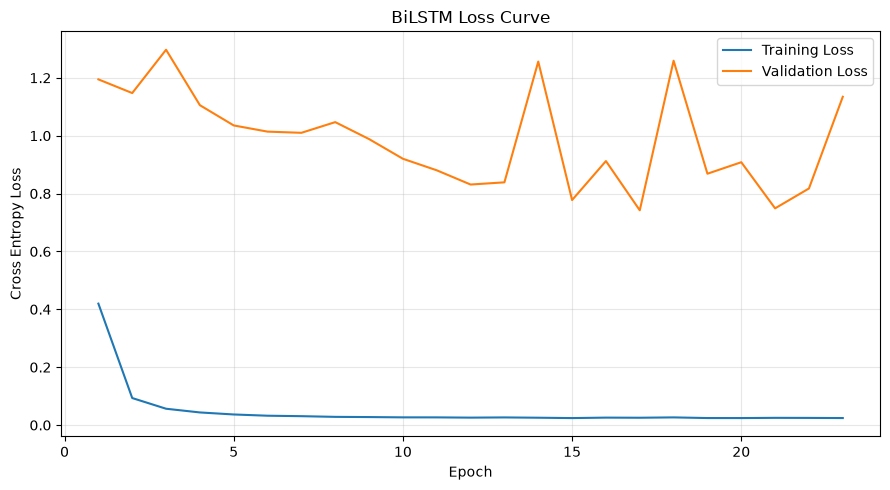

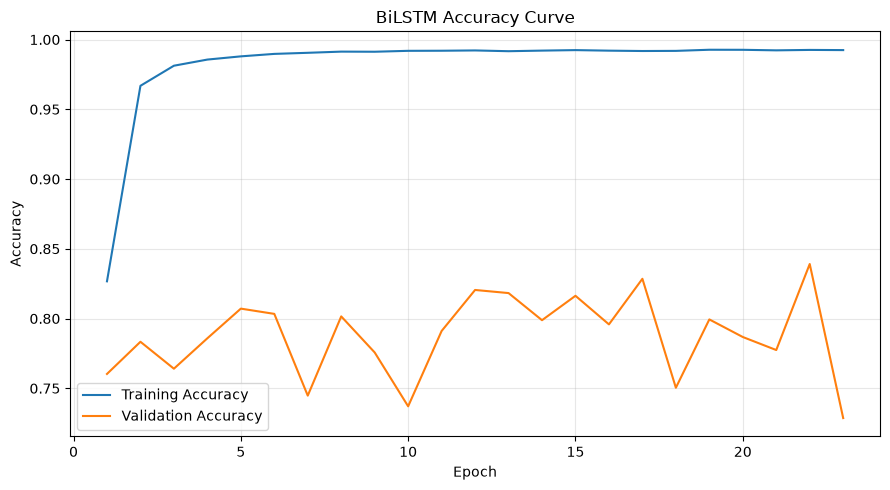


RUNNING CAPPED LOGO
Available LOGO folds: 42
LOGO folds used: 3
Fixed LOGO epochs: 17
LOGO 1/3, Participant = 2, Accuracy = 0.3378, Time = 0.89 min
LOGO 2/3, Participant = 3, Accuracy = 0.2178, Time = 0.87 min
LOGO 3/3, Participant = 5, Accuracy = 0.8232, Time = 0.89 min

LOGO Accuracy: 0.4596 plus or minus 0.2617
LOGO folds completed: 3
LOGO time this session: 2.67 minutes

FINAL UNTOUCHED TEST EVALUATION

CLASSIFICATION REPORT

               precision    recall  f1-score   support

class_lecture     0.6645    0.7665    0.7119     11353
        music     0.5095    0.4058    0.4518      7444
       normal     0.6198    0.5873    0.6031      5593
      reading     0.6038    0.6186    0.6111      2695

     accuracy                         0.6157     27085
    macro avg     0.5994    0.5946    0.5945     27085
 weighted avg     0.6066    0.6157    0.6079     27085



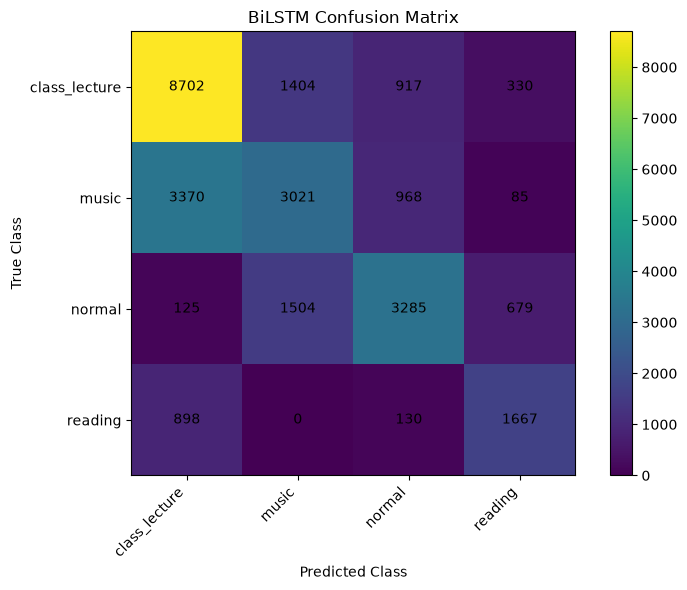

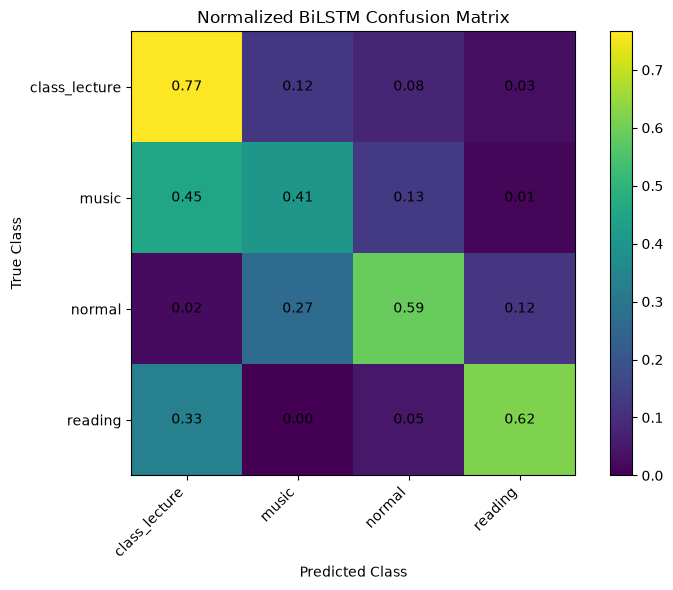


################################################################################
FINAL BiLSTM RESULTS
MAX DATASET
################################################################################
GPU                       : Intel(R) Arc(TM) A750 Graphics
Sequence Strategy         : window_seq
Sequence Length           : 10
Input Features            : 232

Selected Run              : 5
Selected Seed             : 46
Best Epoch                : 17

Training Accuracy         : 0.9972
Validation Accuracy       : 0.8285
Testing Accuracy          : 0.6157

GroupKFold 5 CV           : 0.6410 plus or minus 0.0763
Capped LOGO CV            : 0.4596 plus or minus 0.2617
LOGO Folds Used           : 3 of 42

Precision Weighted        : 0.6066
Recall Weighted           : 0.6157
F1 Weighted               : 0.6079
F1 Macro                  : 0.5945
Cohen Kappa               : 0.4402
MCC                       : 0.4427
ROC AUC Weighted OVR      : 0.8317

Optuna Time               : 21.94 minutes
Five R

In [4]:
# ================================================================
# BiLSTM WITH INTEL ARC A750
# PYTORCH XPU
# MAX DATASET
#
# FULL DATASET
# PERSON WISE 70 / 20 / 10
# WINDOW SEQUENCES
# SEQUENCE LENGTH 10
# OPTUNA 10 TRIALS
# GROUPKFOLD 5
# FIVE RUNS
# LOGO 3 FOLDS
#
# COMPLETE METRICS
# CONFUSION MATRIX
# TRAINING CURVES
# AUTOMATIC RESULT SAVING
#
# TEST SET IS USED ONLY FOR FINAL EVALUATION
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import time
import json
import copy
import random
import warnings

from pathlib import Path

import joblib
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

import torch
import torch.nn as nn

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.utils.class_weight import (
    compute_class_weight
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ================================================================
# WARNINGS
# ================================================================

warnings.filterwarnings("ignore")

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ================================================================
# CONFIGURATION
# ================================================================

FILE_PATH = Path(
    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"
)


OUTPUT_DIR = (
    FILE_PATH.parent
    / "Max_Dataset_BiLSTM_Results"
)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


SEED = 42


# Same as supplied Med BiLSTM

N_TRIALS = 10

N_RUNS = 5

GROUP_K_FOLDS = 5


# Original Med code used three LOGO folds

LOGO_MAX_FOLDS = 3


# Training configuration

BILSTM_EPOCHS = 50

BILSTM_BATCH = 1024

BILSTM_PATIENCE = 6


# Sequence configuration

SEQ_STRATEGY = "window_seq"

SEQ_LEN = 10

SEQ_STRIDE = 1


# ================================================================
# OPTUNA CHECKPOINT DATABASE
#
# Allows Optuna to continue after kernel restart or power failure.
# ================================================================

OPTUNA_DATABASE = (
    OUTPUT_DIR
    / "bilstm_optuna.db"
)


OPTUNA_STORAGE = (
    f"sqlite:///{OPTUNA_DATABASE}"
)


OPTUNA_STUDY_NAME = (
    "Max_Dataset_BiLSTM_XPU_v1"
)


# ================================================================
# MEMORY
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# RANDOM SEED
# ================================================================

def set_seed(seed):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if hasattr(torch, "xpu"):

        try:

            torch.xpu.manual_seed_all(seed)

        except Exception:

            pass


set_seed(SEED)


# ================================================================
# INTEL ARC XPU DETECTION
# ================================================================

print("=" * 80)

print("INTEL ARC GPU CONFIGURATION")

print("=" * 80)

print(
    "PyTorch version:",
    torch.__version__
)


if (
    not hasattr(torch, "xpu")
    or
    not torch.xpu.is_available()
):

    raise RuntimeError(
        "Intel XPU GPU is not available. "
        "This BiLSTM code requires your PyTorch XPU environment."
    )


DEVICE = torch.device(
    "xpu:0"
)


print(
    "XPU available:",
    torch.xpu.is_available()
)


print(
    "XPU device count:",
    torch.xpu.device_count()
)


print(
    "GPU:",
    torch.xpu.get_device_name(0)
)


print(
    "Selected device:",
    DEVICE
)


print("=" * 80)


# ================================================================
# XPU HELPERS
# ================================================================

def synchronize():

    torch.xpu.synchronize()


def clear_xpu():

    gc.collect()

    torch.xpu.empty_cache()


# ================================================================
# CHECK INPUT
# ================================================================

if not FILE_PATH.exists():

    raise FileNotFoundError(
        f"Input CSV does not exist: {FILE_PATH}"
    )


# ================================================================
# TOTAL TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# LOAD COMPLETE MAX DATASET
# ================================================================

print()

print("=" * 80)

print("LOADING MAX DATASET")

print("=" * 80)


load_start = time.time()


df = pd.read_csv(
    FILE_PATH,
    low_memory=False
)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMNS
# ================================================================

metadata_cols = [
    "PersonSrial",
    "Window",
    "Window_Start",
    "Window_End",
    "Window_Samples"
]


target_col = "Class"


required_cols = [
    "PersonSrial",
    "Window",
    target_col
]


for column in required_cols:

    if column not in df.columns:

        raise ValueError(
            f"Missing required column: {column}"
        )


feature_cols = [
    column
    for column in df.columns
    if column not in metadata_cols
    and column != target_col
]


if len(feature_cols) == 0:

    raise ValueError(
        "No feature columns were detected."
    )


print(
    "Feature count:",
    len(feature_cols)
)


# ================================================================
# METADATA
# ================================================================

meta_df = df[
    [
        "PersonSrial",
        "Window",
        target_col
    ]
].copy()


if meta_df.isna().any().any():

    raise ValueError(
        "Participant, Window or Class metadata "
        "contains missing values."
    )


meta_df["Window"] = pd.to_numeric(
    meta_df["Window"],
    errors="raise"
)


# ================================================================
# LABELS
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(
    df[target_col].astype(str)
).astype(
    np.int64
)


class_names = list(
    label_encoder.classes_
)


NUM_CLASSES = len(
    class_names
)


# ================================================================
# PARTICIPANTS
# ================================================================

groups_all = (
    df[
        "PersonSrial"
    ]
    .to_numpy()
)


# ================================================================
# FEATURES
# ================================================================

X_all = (
    df[
        feature_cols
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
    .to_numpy(
        dtype=np.float32
    )
)


invalid_count = int(
    (
        ~np.isfinite(
            X_all
        )
    ).sum()
)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(
        "Feature matrix contains NaN or infinite values."
    )


del df

gc.collect()


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Number of classes:",
    NUM_CLASSES
)


print(
    "Classes:",
    class_names
)


print(
    "Number of participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


print(
    "Loading time:",
    f"{time.time() - load_start:.2f} sec"
)


print(
    "RAM:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

class_distribution = []


print()

print("CLASS DISTRIBUTION")


for class_index, class_name in enumerate(
    class_names
):

    count = int(
        np.sum(
            y_all == class_index
        )
    )


    percentage = (
        count
        / len(y_all)
        * 100.0
    )


    print(
        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"
    )


    class_distribution.append(
        {
            "Class": class_name,
            "Count": count,
            "Percentage": percentage
        }
    )


pd.DataFrame(
    class_distribution
).to_csv(
    OUTPUT_DIR
    / "class_distribution.csv",
    index=False
)


# ================================================================
# PERSON WISE 70 / 20 / 10 SPLIT
# ================================================================

print()

print("=" * 80)

print("PERSON WISE 70 / 20 / 10 SPLIT")

print("=" * 80)


persons = np.unique(
    groups_all
)


rng = np.random.RandomState(
    SEED
)


rng.shuffle(
    persons
)


number_persons = len(
    persons
)


number_test = max(
    1,
    int(
        round(
            0.20
            * number_persons
        )
    )
)


number_validation = max(
    1,
    int(
        round(
            0.10
            * number_persons
        )
    )
)


test_persons = persons[
    :number_test
]


validation_persons = persons[
    number_test:
    number_test + number_validation
]


train_persons = persons[
    number_test + number_validation:
]


if len(train_persons) < GROUP_K_FOLDS:

    raise ValueError(
        "Not enough training participants "
        "for GroupKFold."
    )


train_mask = np.isin(
    groups_all,
    train_persons
)


test_mask = np.isin(
    groups_all,
    test_persons
)


validation_mask = np.isin(
    groups_all,
    validation_persons
)


# ================================================================
# VERIFY ZERO PARTICIPANT OVERLAP
# ================================================================

assert (
    np.intersect1d(
        train_persons,
        test_persons
    ).size == 0
)


assert (
    np.intersect1d(
        train_persons,
        validation_persons
    ).size == 0
)


assert (
    np.intersect1d(
        validation_persons,
        test_persons
    ).size == 0
)


print(
    "Training participants:",
    len(train_persons)
)


print(
    "Validation participants:",
    len(validation_persons)
)


print(
    "Testing participants:",
    len(test_persons)
)


print()

print(
    "Training rows:",
    int(
        train_mask.sum()
    )
)


print(
    "Validation rows:",
    int(
        validation_mask.sum()
    )
)


print(
    "Testing rows:",
    int(
        test_mask.sum()
    )
)


# ================================================================
# SAVE PARTICIPANT SPLIT
# ================================================================

split_table = pd.DataFrame(
    [
        {
            "Split": "Training",
            "Participants": len(train_persons),
            "Rows": int(train_mask.sum())
        },
        {
            "Split": "Validation",
            "Participants": len(validation_persons),
            "Rows": int(validation_mask.sum())
        },
        {
            "Split": "Testing",
            "Participants": len(test_persons),
            "Rows": int(test_mask.sum())
        }
    ]
)


split_table.to_csv(
    OUTPUT_DIR
    / "split_summary.csv",
    index=False
)


with open(
    OUTPUT_DIR
    / "participant_split.json",
    "w",
    encoding="utf8"
) as file:

    json.dump(
        {
            "training": [
                str(x)
                for x in train_persons
            ],
            "validation": [
                str(x)
                for x in validation_persons
            ],
            "testing": [
                str(x)
                for x in test_persons
            ]
        },
        file,
        indent=4
    )


# ================================================================
# BUILD RAW SEQUENCES
#
# Scaling is intentionally performed after sequence construction.
#
# This allows each GroupKFold and LOGO fold to fit its own scaler.
# ================================================================

def build_sequences(
    X,
    y,
    meta,
    strategy="window_seq",
    seq_len=SEQ_LEN,
    stride=SEQ_STRIDE
):

    if strategy == "feature_steps":

        Xseq = X.reshape(
            X.shape[0],
            X.shape[1],
            1
        )


        return (
            Xseq.astype(
                np.float32
            ),
            y.astype(
                np.int64
            ),
            meta[
                "PersonSrial"
            ].to_numpy()
        )


    meta = meta.reset_index(
        drop=True
    )


    Xseq_list = []

    yseq_list = []

    gseq_list = []


    participant_values = meta[
        "PersonSrial"
    ].to_numpy()


    window_values = meta[
        "Window"
    ].to_numpy()


    for participant in np.unique(
        participant_values
    ):

        participant_indices = np.where(
            participant_values
            == participant
        )[0]


        order = np.argsort(
            window_values[
                participant_indices
            ],
            kind="stable"
        )


        ordered_indices = (
            participant_indices[
                order
            ]
        )


        if (
            len(ordered_indices)
            < seq_len
        ):

            continue


        for start in range(
            0,
            len(ordered_indices)
            - seq_len
            + 1,
            stride
        ):

            selected = ordered_indices[
                start:
                start + seq_len
            ]


            Xseq_list.append(
                X[
                    selected
                ]
            )


            sequence_label = np.bincount(
                y[
                    selected
                ],
                minlength=NUM_CLASSES
            ).argmax()


            yseq_list.append(
                sequence_label
            )


            gseq_list.append(
                participant
            )


    if not Xseq_list:

        raise RuntimeError(
            "No sequences were generated. "
            "Check Window values and SEQ_LEN."
        )


    return (
        np.stack(
            Xseq_list
        ).astype(
            np.float32
        ),
        np.asarray(
            yseq_list,
            dtype=np.int64
        ),
        np.asarray(
            gseq_list
        )
    )


# ================================================================
# BUILD TRAIN, VALIDATION AND TEST SEQUENCES
# ================================================================

print()

print("=" * 80)

print("BUILDING BiLSTM SEQUENCES")

print("=" * 80)


sequence_start = time.time()


meta_train = (
    meta_df.loc[
        train_mask
    ]
    .reset_index(
        drop=True
    )
)


meta_validation = (
    meta_df.loc[
        validation_mask
    ]
    .reset_index(
        drop=True
    )
)


meta_test = (
    meta_df.loc[
        test_mask
    ]
    .reset_index(
        drop=True
    )
)


X_train_raw, y_train_seq, g_train_seq = (
    build_sequences(
        X_all[
            train_mask
        ],
        y_all[
            train_mask
        ],
        meta_train,
        SEQ_STRATEGY
    )
)


X_validation_raw, y_validation_seq, g_validation_seq = (
    build_sequences(
        X_all[
            validation_mask
        ],
        y_all[
            validation_mask
        ],
        meta_validation,
        SEQ_STRATEGY
    )
)


X_test_raw, y_test_seq, g_test_seq = (
    build_sequences(
        X_all[
            test_mask
        ],
        y_all[
            test_mask
        ],
        meta_test,
        SEQ_STRATEGY
    )
)


del X_all
del y_all
del groups_all

del meta_df
del meta_train
del meta_validation
del meta_test

del train_mask
del validation_mask
del test_mask

gc.collect()


print(
    "Train sequences:",
    X_train_raw.shape
)


print(
    "Validation sequences:",
    X_validation_raw.shape
)


print(
    "Test sequences:",
    X_test_raw.shape
)


T = X_train_raw.shape[
    1
]


D = X_train_raw.shape[
    2
]


print(
    "Timesteps:",
    T
)


print(
    "Input features:",
    D
)


print(
    "Sequence building time:",
    f"{time.time() - sequence_start:.2f} sec"
)


print(
    "RAM:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# CROSS VALIDATION SPLITS
# ================================================================

gkf_splits = list(
    GroupKFold(
        n_splits=GROUP_K_FOLDS
    ).split(
        X_train_raw,
        y_train_seq,
        g_train_seq
    )
)


logo_splits_full = list(
    LeaveOneGroupOut().split(
        X_train_raw,
        y_train_seq,
        g_train_seq
    )
)


if LOGO_MAX_FOLDS is None:

    logo_splits = (
        logo_splits_full
    )

else:

    logo_splits = (
        logo_splits_full[
            :LOGO_MAX_FOLDS
        ]
    )


print()

print(
    "GroupKFold folds:",
    len(gkf_splits)
)


print(
    "Available LOGO folds:",
    len(logo_splits_full)
)


print(
    "LOGO folds used:",
    len(logo_splits)
)


# ================================================================
# SEQUENCE STANDARDIZATION
#
# StandardScaler sees all timesteps from training sequences.
#
# For CV this scaler is fitted separately in every fold.
# ================================================================

def scale_sequence_pair(
    X_training,
    X_validation=None
):

    X_training_scaled = np.array(
        X_training,
        dtype=np.float32,
        copy=True,
        order="C"
    )


    scaler = StandardScaler()


    training_flat = (
        X_training_scaled.reshape(
            -1,
            D
        )
    )


    scaler.fit(
        training_flat
    )


    training_flat_scaled = scaler.transform(
        training_flat
    ).astype(
        np.float32,
        copy=False
    )


    X_training_scaled = (
        training_flat_scaled.reshape(
            X_training_scaled.shape
        )
    )


    if X_validation is None:

        return (
            X_training_scaled,
            scaler
        )


    X_validation_scaled = np.array(
        X_validation,
        dtype=np.float32,
        copy=True,
        order="C"
    )


    validation_flat = (
        X_validation_scaled.reshape(
            -1,
            D
        )
    )


    validation_flat_scaled = scaler.transform(
        validation_flat
    ).astype(
        np.float32,
        copy=False
    )


    X_validation_scaled = (
        validation_flat_scaled.reshape(
            X_validation_scaled.shape
        )
    )


    return (
        X_training_scaled,
        X_validation_scaled,
        scaler
    )


# ================================================================
# FINAL SCALER
#
# Fit only on 70 percent training sequences.
# ================================================================

print()

print("=" * 80)

print("FINAL TRAINING SCALER")

print("=" * 80)


final_scaler = StandardScaler()


final_scaler.fit(
    X_train_raw.reshape(
        -1,
        D
    )
)


X_train_seq = (
    final_scaler.transform(
        X_train_raw.reshape(
            -1,
            D
        )
    )
    .astype(
        np.float32,
        copy=False
    )
    .reshape(
        X_train_raw.shape
    )
)


X_validation_seq = (
    final_scaler.transform(
        X_validation_raw.reshape(
            -1,
            D
        )
    )
    .astype(
        np.float32,
        copy=False
    )
    .reshape(
        X_validation_raw.shape
    )
)


X_test_seq = (
    final_scaler.transform(
        X_test_raw.reshape(
            -1,
            D
        )
    )
    .astype(
        np.float32,
        copy=False
    )
    .reshape(
        X_test_raw.shape
    )
)


X_train_seq = np.ascontiguousarray(
    X_train_seq
)


X_validation_seq = np.ascontiguousarray(
    X_validation_seq
)


X_test_seq = np.ascontiguousarray(
    X_test_seq
)


joblib.dump(
    final_scaler,
    OUTPUT_DIR
    / "standard_scaler.joblib"
)


joblib.dump(
    label_encoder,
    OUTPUT_DIR
    / "label_encoder.joblib"
)


with open(
    OUTPUT_DIR
    / "feature_columns.json",
    "w",
    encoding="utf8"
) as file:

    json.dump(
        feature_cols,
        file,
        indent=4
    )


print(
    "Scaled training:",
    X_train_seq.shape
)


print(
    "Scaled validation:",
    X_validation_seq.shape
)


print(
    "Scaled testing:",
    X_test_seq.shape
)


print(
    "RAM:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# GPU DATA MANAGEMENT
# ================================================================

def gpu_tensor(
    X,
    dtype=torch.float32
):

    return (
        torch.as_tensor(
            X,
            dtype=dtype
        )
        .to(
            DEVICE
        )
    )


def batch_indices(
    number_samples,
    shuffle=True
):

    if shuffle:

        indices = torch.randperm(
            number_samples,
            device=DEVICE
        )

    else:

        indices = torch.arange(
            number_samples,
            device=DEVICE
        )


    for start in range(
        0,
        number_samples,
        BILSTM_BATCH
    ):

        yield indices[
            start:
            start + BILSTM_BATCH
        ]


class GPUData:

    def __init__(
        self,
        X,
        y
    ):

        self.X = gpu_tensor(
            X
        )

        self.y = gpu_tensor(
            y,
            torch.long
        )


    def __len__(
        self
    ):

        return self.y.shape[
            0
        ]


# ================================================================
# BiLSTM MODEL
# ================================================================

class BiLSTM(
    nn.Module
):

    def __init__(
        self,
        params,
        input_size,
        num_classes
    ):

        super().__init__()


        self.input_dropout = nn.Dropout(
            params[
                "input_dropout"
            ]
        )


        self.lstm_layers = nn.ModuleList()

        self.layer_dropouts = nn.ModuleList()


        current_size = input_size


        for _ in range(
            params[
                "n_lstm_layers"
            ]
        ):

            self.lstm_layers.append(
                nn.LSTM(
                    input_size=current_size,
                    hidden_size=params[
                        "lstm_units"
                    ],
                    num_layers=1,
                    batch_first=True,
                    bidirectional=True
                )
            )


            self.layer_dropouts.append(
                nn.Dropout(
                    params[
                        "recurrent_dropout"
                    ]
                )
            )


            current_size = (
                params[
                    "lstm_units"
                ]
                * 2
            )


        self.dropout = nn.Dropout(
            params[
                "dropout"
            ]
        )


        if (
            params[
                "dense_units"
            ]
            > 0
        ):

            self.dense = nn.Linear(
                current_size,
                params[
                    "dense_units"
                ]
            )


            if (
                params[
                    "activation"
                ]
                == "relu"
            ):

                self.activation = nn.ReLU()

            else:

                self.activation = nn.Tanh()


            output_size = (
                params[
                    "dense_units"
                ]
            )

        else:

            self.dense = None

            self.activation = None

            output_size = (
                current_size
            )


        self.classifier = nn.Linear(
            output_size,
            num_classes
        )


    def forward(
        self,
        x
    ):

        x = self.input_dropout(
            x
        )


        hidden = None


        for lstm, layer_dropout in zip(
            self.lstm_layers,
            self.layer_dropouts
        ):

            x = layer_dropout(
                x
            )


            x, (
                hidden,
                cell
            ) = lstm(
                x
            )


            x = self.dropout(
                x
            )


        forward_hidden = hidden[
            -2
        ]


        backward_hidden = hidden[
            -1
        ]


        x = torch.cat(
            [
                forward_hidden,
                backward_hidden
            ],
            dim=1
        )


        if self.dense is not None:

            x = self.dense(
                x
            )


            x = self.activation(
                x
            )


            x = self.dropout(
                x
            )


        return self.classifier(
            x
        )


# ================================================================
# BUILD MODEL
# ================================================================

def build_bilstm(
    params,
    seed=SEED
):

    set_seed(
        seed
    )


    model = BiLSTM(
        params,
        input_size=D,
        num_classes=NUM_CLASSES
    )


    return model.to(
        DEVICE
    )


# ================================================================
# CLASS WEIGHTS
# ================================================================

def class_weight_tensor(
    y
):

    classes = np.unique(
        y
    )


    values = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y
    )


    weights = np.zeros(
        NUM_CLASSES,
        dtype=np.float32
    )


    weights[
        classes
    ] = values


    return gpu_tensor(
        weights,
        torch.float32
    )


# ================================================================
# ONE TRAINING EPOCH
# ================================================================

def train_one_epoch(
    model,
    data,
    optimizer,
    criterion
):

    model.train()


    total_loss = torch.zeros(
        (),
        device=DEVICE
    )


    total_correct = torch.zeros(
        (),
        device=DEVICE
    )


    for indices in batch_indices(
        len(data),
        shuffle=True
    ):

        X_batch = data.X[
            indices
        ]


        y_batch = data.y[
            indices
        ]


        optimizer.zero_grad(
            set_to_none=True
        )


        outputs = model(
            X_batch
        )


        loss = criterion(
            outputs,
            y_batch
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )


        optimizer.step()


        total_loss += (
            loss.detach()
            * len(indices)
        )


        total_correct += (
            outputs.argmax(
                dim=1
            )
            == y_batch
        ).sum()


    synchronize()


    number_samples = len(
        data
    )


    return (
        total_loss.item()
        / number_samples,
        total_correct.item()
        / number_samples
    )


# ================================================================
# EVALUATION
# ================================================================

@torch.no_grad()
def evaluate_model(
    model,
    data,
    criterion=None,
    return_probabilities=False
):

    model.eval()


    total_loss = torch.zeros(
        (),
        device=DEVICE
    )


    total_correct = torch.zeros(
        (),
        device=DEVICE
    )


    probability_list = []


    for indices in batch_indices(
        len(data),
        shuffle=False
    ):

        X_batch = data.X[
            indices
        ]


        y_batch = data.y[
            indices
        ]


        outputs = model(
            X_batch
        )


        if criterion is not None:

            loss = criterion(
                outputs,
                y_batch
            )


            total_loss += (
                loss
                * len(indices)
            )


        total_correct += (
            outputs.argmax(
                dim=1
            )
            == y_batch
        ).sum()


        if return_probabilities:

            probability_list.append(
                torch.softmax(
                    outputs,
                    dim=1
                )
                .cpu()
            )


    synchronize()


    accuracy = (
        total_correct.item()
        / len(data)
    )


    if criterion is not None:

        loss_value = (
            total_loss.item()
            / len(data)
        )

    else:

        loss_value = float(
            "nan"
        )


    if return_probabilities:

        probabilities = (
            torch.cat(
                probability_list,
                dim=0
            )
            .numpy()
        )


        return (
            loss_value,
            accuracy,
            probabilities
        )


    return (
        loss_value,
        accuracy
    )


# ================================================================
# FIT BiLSTM
# ================================================================

def fit_bilstm(
    params,
    X_training,
    y_training,
    X_validation=None,
    y_validation=None,
    seed=SEED,
    epochs=BILSTM_EPOCHS,
    use_early_stopping=True,
    verbose=0
):

    model = build_bilstm(
        params,
        seed=seed
    )


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=params[
            "learning_rate"
        ],
        weight_decay=params[
            "l2"
        ]
    )


    class_weights = class_weight_tensor(
        y_training
    )


    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )


    training_data = GPUData(
        X_training,
        y_training
    )


    if X_validation is not None:

        validation_data = GPUData(
            X_validation,
            y_validation
        )

    else:

        validation_data = None


    history = {
        "loss": [],
        "accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }


    best_loss = float(
        "inf"
    )


    best_state = None

    patience_counter = 0


    for epoch in range(
        epochs
    ):

        train_loss, train_accuracy = (
            train_one_epoch(
                model,
                training_data,
                optimizer,
                criterion
            )
        )


        if validation_data is not None:

            val_loss, val_accuracy = (
                evaluate_model(
                    model,
                    validation_data,
                    criterion
                )
            )

        else:

            val_loss = float(
                "nan"
            )

            val_accuracy = float(
                "nan"
            )


        history[
            "loss"
        ].append(
            train_loss
        )


        history[
            "accuracy"
        ].append(
            train_accuracy
        )


        history[
            "val_loss"
        ].append(
            val_loss
        )


        history[
            "val_accuracy"
        ].append(
            val_accuracy
        )


        if use_early_stopping:

            if validation_data is not None:

                monitored_loss = (
                    val_loss
                )

            else:

                monitored_loss = (
                    train_loss
                )


            if (
                monitored_loss
                < best_loss
                - 1e-5
            ):

                best_loss = (
                    monitored_loss
                )


                best_state = {
                    key:
                    value.detach().clone()
                    for key, value
                    in model.state_dict().items()
                }


                patience_counter = 0


            else:

                patience_counter += 1


            if (
                patience_counter
                >= BILSTM_PATIENCE
            ):

                if verbose:

                    print(
                        "Early stopping at epoch",
                        epoch + 1
                    )


                break


        if verbose:

            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"Train loss: {train_loss:.4f} | "
                f"Train acc: {train_accuracy:.4f} | "
                f"Val loss: {val_loss:.4f} | "
                f"Val acc: {val_accuracy:.4f}"
            )


    # ============================================================
    # RESTORE BEST EARLY STOPPING MODEL
    # ============================================================

    if (
        use_early_stopping
        and
        best_state is not None
    ):

        model.load_state_dict(
            best_state
        )


    if best_state is not None:

        del best_state


    del training_data


    if validation_data is not None:

        del validation_data


    del optimizer
    del criterion
    del class_weights


    clear_xpu()


    return (
        model,
        history
    )


# ================================================================
# PREDICT PROBABILITIES
# ================================================================

def predict_probabilities(
    model,
    X,
    y
):

    data = GPUData(
        X,
        y
    )


    _, _, probabilities = (
        evaluate_model(
            model,
            data,
            return_probabilities=True
        )
    )


    del data

    clear_xpu()


    return probabilities


# ================================================================
# BEST EPOCH
# ================================================================

def get_best_epoch(
    history
):

    val_loss = np.asarray(
        history[
            "val_loss"
        ],
        dtype=float
    )


    valid = np.isfinite(
        val_loss
    )


    if valid.any():

        return int(
            np.nanargmin(
                val_loss
            )
            + 1
        )


    return len(
        history[
            "loss"
        ]
    )


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def bilstm_objective(
    trial
):

    params = {

        "n_lstm_layers":

            trial.suggest_int(
                "n_lstm_layers",
                1,
                2
            ),

        "lstm_units":

            trial.suggest_categorical(
                "lstm_units",
                [
                    32,
                    64,
                    128
                ]
            ),

        "dense_units":

            trial.suggest_categorical(
                "dense_units",
                [
                    0,
                    64,
                    128
                ]
            ),

        "dropout":

            trial.suggest_float(
                "dropout",
                0.0,
                0.5
            ),

        "recurrent_dropout":

            trial.suggest_float(
                "recurrent_dropout",
                0.0,
                0.4
            ),

        "input_dropout":

            trial.suggest_float(
                "input_dropout",
                0.0,
                0.3
            ),

        "l2":

            trial.suggest_float(
                "l2",
                1e-6,
                1e-3,
                log=True
            ),

        "learning_rate":

            trial.suggest_float(
                "learning_rate",
                1e-4,
                5e-3,
                log=True
            ),

        "activation":

            trial.suggest_categorical(
                "activation",
                [
                    "relu",
                    "tanh"
                ]
            )
    }


    scores = []


    print()

    print(
        f"OPTUNA TRIAL "
        f"{trial.number + 1}"
    )


    print(
        params
    )


    for fold_number, (
        training_index,
        validation_index
    ) in enumerate(
        gkf_splits,
        start=1
    ):

        fold_start = time.time()


        # ========================================================
        # FOLD SPECIFIC SCALING
        # ========================================================

        (
            X_fold_training,
            X_fold_validation,
            fold_scaler
        ) = scale_sequence_pair(
            X_train_raw[
                training_index
            ],
            X_train_raw[
                validation_index
            ]
        )


        model, history = fit_bilstm(
            params,
            X_fold_training,
            y_train_seq[
                training_index
            ],
            X_fold_validation,
            y_train_seq[
                validation_index
            ],
            seed=SEED,
            epochs=BILSTM_EPOCHS,
            use_early_stopping=True,
            verbose=0
        )


        probabilities = (
            predict_probabilities(
                model,
                X_fold_validation,
                y_train_seq[
                    validation_index
                ]
            )
        )


        predictions = probabilities.argmax(
            axis=1
        )


        score = accuracy_score(
            y_train_seq[
                validation_index
            ],
            predictions
        )


        scores.append(
            score
        )


        print(
            f"Trial {trial.number + 1}, "
            f"Fold {fold_number}/"
            f"{GROUP_K_FOLDS}, "
            f"Accuracy = {score:.4f}, "
            f"Epochs = "
            f"{len(history['loss'])}, "
            f"Time = "
            f"{time.time() - fold_start:.2f} sec"
        )


        del model
        del history
        del probabilities
        del predictions
        del X_fold_training
        del X_fold_validation
        del fold_scaler


        clear_xpu()


        trial.report(
            float(
                np.mean(
                    scores
                )
            ),
            fold_number
        )


        if trial.should_prune():

            raise optuna.TrialPruned()


    return float(
        np.mean(
            scores
        )
    )


# ================================================================
# RUN OPTUNA
# ================================================================

print()

print("=" * 80)

print(
    f"RUNNING BiLSTM OPTUNA: "
    f"{N_TRIALS} TRIALS"
)

print("=" * 80)


optuna_start = time.time()


study = optuna.create_study(
    study_name=OPTUNA_STUDY_NAME,
    storage=OPTUNA_STORAGE,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=SEED
    ),
    load_if_exists=True
)


completed_trials = sum(
    1
    for trial in study.trials
    if trial.state
    == optuna.trial.TrialState.COMPLETE
)


remaining_trials = max(
    0,
    N_TRIALS
    - completed_trials
)


print(
    "Previously completed trials:",
    completed_trials
)


print(
    "Remaining trials:",
    remaining_trials
)


if remaining_trials > 0:

    study.optimize(
        bilstm_objective,
        n_trials=remaining_trials,
        show_progress_bar=False,
        gc_after_trial=True
    )


optuna_time = (
    time.time()
    - optuna_start
)


best_params = dict(
    study.best_params
)


print()

print("=" * 80)

print("OPTUNA COMPLETED")

print("=" * 80)


print(
    "Best GroupKFold accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Best parameters:"
)


print(
    best_params
)


print(
    "Optuna time:",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


# ================================================================
# SAVE OPTUNA RESULTS
# ================================================================

study.trials_dataframe().to_csv(
    OUTPUT_DIR
    / "optuna_trials.csv",
    index=False
)


with open(
    OUTPUT_DIR
    / "bilstm_best_params.json",
    "w",
    encoding="utf8"
) as file:

    json.dump(
        best_params,
        file,
        indent=4
    )


# ================================================================
# FIVE RUNS
#
# Best run selected only by separate validation participants.
# ================================================================

print()

print("=" * 80)

print("BiLSTM FIVE RUNS")

print("=" * 80)


run_records = []

best_bundle = None

best_validation_accuracy = float(
    "-inf"
)


five_run_start = time.time()

memory_before = mem_mb()


for run_number in range(
    1,
    N_RUNS + 1
):

    run_start = time.time()


    run_seed = (
        SEED
        + run_number
        - 1
    )


    print()

    print(
        f"BiLSTM RUN "
        f"{run_number}/"
        f"{N_RUNS}"
    )


    # ============================================================
    # GROUPKFOLD
    # ============================================================

    cv_accuracies = []

    cv_epochs = []


    for fold_number, (
        training_index,
        validation_index
    ) in enumerate(
        gkf_splits,
        start=1
    ):

        fold_start = time.time()


        (
            X_fold_training,
            X_fold_validation,
            fold_scaler
        ) = scale_sequence_pair(
            X_train_raw[
                training_index
            ],
            X_train_raw[
                validation_index
            ]
        )


        model, history = fit_bilstm(
            best_params,
            X_fold_training,
            y_train_seq[
                training_index
            ],
            X_fold_validation,
            y_train_seq[
                validation_index
            ],
            seed=run_seed,
            epochs=BILSTM_EPOCHS,
            use_early_stopping=True,
            verbose=0
        )


        probabilities = (
            predict_probabilities(
                model,
                X_fold_validation,
                y_train_seq[
                    validation_index
                ]
            )
        )


        prediction = probabilities.argmax(
            axis=1
        )


        fold_accuracy = accuracy_score(
            y_train_seq[
                validation_index
            ],
            prediction
        )


        cv_accuracies.append(
            fold_accuracy
        )


        cv_epochs.append(
            get_best_epoch(
                history
            )
        )


        print(
            f"Run {run_number}, "
            f"Fold {fold_number}/"
            f"{GROUP_K_FOLDS}, "
            f"Accuracy = "
            f"{fold_accuracy:.4f}, "
            f"Best epoch = "
            f"{get_best_epoch(history)}, "
            f"Time = "
            f"{time.time() - fold_start:.2f} sec"
        )


        del model
        del history
        del probabilities
        del prediction
        del X_fold_training
        del X_fold_validation
        del fold_scaler


        clear_xpu()


    # ============================================================
    # FINAL TRAINING FOR THIS RUN
    #
    # 70 percent training participants are used for fitting.
    #
    # Separate 10 percent validation participants control
    # early stopping and best run selection.
    # ============================================================

    model, history = fit_bilstm(
        best_params,
        X_train_seq,
        y_train_seq,
        X_validation_seq,
        y_validation_seq,
        seed=run_seed,
        epochs=BILSTM_EPOCHS,
        use_early_stopping=True,
        verbose=1
    )


    train_probability = (
        predict_probabilities(
            model,
            X_train_seq,
            y_train_seq
        )
    )


    validation_probability = (
        predict_probabilities(
            model,
            X_validation_seq,
            y_validation_seq
        )
    )


    train_prediction = (
        train_probability.argmax(
            axis=1
        )
    )


    validation_prediction = (
        validation_probability.argmax(
            axis=1
        )
    )


    train_accuracy = accuracy_score(
        y_train_seq,
        train_prediction
    )


    validation_accuracy = accuracy_score(
        y_validation_seq,
        validation_prediction
    )


    best_epoch = get_best_epoch(
        history
    )


    run_time = (
        time.time()
        - run_start
    )


    record = {
        "Run":
            run_number,

        "Seed":
            run_seed,

        "Training_Accuracy":
            float(
                train_accuracy
            ),

        "Validation_Accuracy":
            float(
                validation_accuracy
            ),

        "GroupKFold_Accuracy":
            float(
                np.mean(
                    cv_accuracies
                )
            ),

        "GroupKFold_STD":
            float(
                np.std(
                    cv_accuracies
                )
            ),

        "Mean_CV_Best_Epoch":
            float(
                np.mean(
                    cv_epochs
                )
            ),

        "Epochs_Run":
            int(
                len(
                    history[
                        "loss"
                    ]
                )
            ),

        "Best_Epoch":
            int(
                best_epoch
            ),

        "Execution_Time_Seconds":
            float(
                run_time
            )
    }


    run_records.append(
        record
    )


    print()

    print(
        f"[BiLSTM {run_number}] "
        f"Train = "
        f"{train_accuracy:.4f}, "
        f"Validation = "
        f"{validation_accuracy:.4f}, "
        f"GKF = "
        f"{record['GroupKFold_Accuracy']:.4f} "
        f"plus or minus "
        f"{record['GroupKFold_STD']:.4f}, "
        f"Best epoch = "
        f"{best_epoch}, "
        f"Time = "
        f"{run_time / 60:.2f} min"
    )


    # ============================================================
    # SELECT USING VALIDATION ACCURACY ONLY
    # ============================================================

    if (
        validation_accuracy
        > best_validation_accuracy
    ):

        best_validation_accuracy = (
            validation_accuracy
        )


        model_state = {
            key:
            value.detach()
            .cpu()
            .clone()

            for key, value
            in model.state_dict().items()
        }


        best_bundle = {
            "record":
                record.copy(),

            "model_state":
                model_state,

            "history":
                copy.deepcopy(
                    history
                )
        }


    del model
    del history
    del train_probability
    del validation_probability
    del train_prediction
    del validation_prediction


    clear_xpu()


five_run_time = (
    time.time()
    - five_run_start
)


memory_difference = (
    mem_mb()
    - memory_before
)


run_table = pd.DataFrame(
    run_records
)


run_table.to_csv(
    OUTPUT_DIR
    / "five_runs.csv",
    index=False
)


print()

print(
    run_table
    .round(4)
    .to_string(
        index=False
    )
)


best_record = (
    best_bundle[
        "record"
    ]
)


best_history = (
    best_bundle[
        "history"
    ]
)


print()

print(
    "SELECTED RUN:",
    best_record[
        "Run"
    ]
)


print(
    "Selection Validation Accuracy:",
    f"{best_record['Validation_Accuracy']:.4f}"
)


print(
    "Selected Best Epoch:",
    best_record[
        "Best_Epoch"
    ]
)


# ================================================================
# BUILD SELECTED MODEL
# ================================================================

best_model = build_bilstm(
    best_params,
    seed=best_record[
        "Seed"
    ]
)


best_model.load_state_dict(
    best_bundle[
        "model_state"
    ]
)


best_model.eval()


# ================================================================
# SAVE TRAINING CURVE DATA
# ================================================================

history_table = pd.DataFrame(
    {
        "Epoch":
            np.arange(
                1,
                len(
                    best_history[
                        "loss"
                    ]
                )
                + 1
            ),

        "Training_Loss":
            best_history[
                "loss"
            ],

        "Training_Accuracy":
            best_history[
                "accuracy"
            ],

        "Validation_Loss":
            best_history[
                "val_loss"
            ],

        "Validation_Accuracy":
            best_history[
                "val_accuracy"
            ]
    }
)


history_table.to_csv(
    OUTPUT_DIR
    / "training_history.csv",
    index=False
)


# ================================================================
# TRAINING CURVES
# ================================================================

fig, ax = plt.subplots(
    figsize=(
        9,
        5
    )
)


ax.plot(
    history_table[
        "Epoch"
    ],
    history_table[
        "Training_Loss"
    ],
    label="Training Loss"
)


ax.plot(
    history_table[
        "Epoch"
    ],
    history_table[
        "Validation_Loss"
    ],
    label="Validation Loss"
)


ax.set_xlabel(
    "Epoch"
)


ax.set_ylabel(
    "Cross Entropy Loss"
)


ax.set_title(
    "BiLSTM Loss Curve"
)


ax.legend()

ax.grid(
    alpha=0.3
)


fig.tight_layout()


fig.savefig(
    OUTPUT_DIR
    / "bilstm_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close(
    fig
)


fig, ax = plt.subplots(
    figsize=(
        9,
        5
    )
)


ax.plot(
    history_table[
        "Epoch"
    ],
    history_table[
        "Training_Accuracy"
    ],
    label="Training Accuracy"
)


ax.plot(
    history_table[
        "Epoch"
    ],
    history_table[
        "Validation_Accuracy"
    ],
    label="Validation Accuracy"
)


ax.set_xlabel(
    "Epoch"
)


ax.set_ylabel(
    "Accuracy"
)


ax.set_title(
    "BiLSTM Accuracy Curve"
)


ax.legend()

ax.grid(
    alpha=0.3
)


fig.tight_layout()


fig.savefig(
    OUTPUT_DIR
    / "bilstm_accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close(
    fig
)


# ================================================================
# CAPPED LOGO
#
# Original Med code used 3 LOGO folds.
#
# Scientific correction:
# held out LOGO participant is NOT used for early stopping.
#
# The best epoch learnt from the independent 10 percent
# validation participants is used as a fixed epoch count.
# ================================================================

print()

print("=" * 80)

print("RUNNING CAPPED LOGO")

print("=" * 80)


print(
    "Available LOGO folds:",
    len(
        logo_splits_full
    )
)


print(
    "LOGO folds used:",
    len(
        logo_splits
    )
)


FIXED_LOGO_EPOCHS = max(
    1,
    int(
        best_record[
            "Best_Epoch"
        ]
    )
)


print(
    "Fixed LOGO epochs:",
    FIXED_LOGO_EPOCHS
)


logo_result_path = (
    OUTPUT_DIR
    / "logo_results.csv"
)


# ================================================================
# RESUME LOGO
# ================================================================

if logo_result_path.exists():

    previous_logo = pd.read_csv(
        logo_result_path
    )


    completed_persons = set(
        previous_logo[
            "Held_Out_Person"
        ].astype(str)
    )


    logo_records = (
        previous_logo
        .to_dict(
            orient="records"
        )
    )


    print(
        "Previously completed LOGO folds:",
        len(
            completed_persons
        )
    )


else:

    completed_persons = set()

    logo_records = []


logo_start = time.time()


for fold_number, (
    training_index,
    validation_index
) in enumerate(
    logo_splits,
    start=1
):

    held_out_person = str(
        np.unique(
            g_train_seq[
                validation_index
            ]
        )[0]
    )


    if (
        held_out_person
        in completed_persons
    ):

        print(
            f"LOGO "
            f"{fold_number}/"
            f"{len(logo_splits)} "
            f"participant "
            f"{held_out_person} "
            f"already completed."
        )


        continue


    fold_start = time.time()


    (
        X_logo_training,
        X_logo_validation,
        logo_scaler
    ) = scale_sequence_pair(
        X_train_raw[
            training_index
        ],
        X_train_raw[
            validation_index
        ]
    )


    logo_model, logo_history = fit_bilstm(
        best_params,
        X_logo_training,
        y_train_seq[
            training_index
        ],
        X_validation=None,
        y_validation=None,
        seed=best_record[
            "Seed"
        ],
        epochs=FIXED_LOGO_EPOCHS,
        use_early_stopping=False,
        verbose=0
    )


    probabilities = (
        predict_probabilities(
            logo_model,
            X_logo_validation,
            y_train_seq[
                validation_index
            ]
        )
    )


    predictions = probabilities.argmax(
        axis=1
    )


    fold_accuracy = accuracy_score(
        y_train_seq[
            validation_index
        ],
        predictions
    )


    fold_time = (
        time.time()
        - fold_start
    )


    record = {
        "Fold":
            fold_number,

        "Held_Out_Person":
            held_out_person,

        "Sequences":
            int(
                len(
                    validation_index
                )
            ),

        "Accuracy":
            float(
                fold_accuracy
            ),

        "Fixed_Epochs":
            int(
                FIXED_LOGO_EPOCHS
            ),

        "Execution_Time_Seconds":
            float(
                fold_time
            )
    }


    logo_records.append(
        record
    )


    pd.DataFrame(
        logo_records
    ).to_csv(
        logo_result_path,
        index=False
    )


    print(
        f"LOGO "
        f"{fold_number}/"
        f"{len(logo_splits)}, "
        f"Participant = "
        f"{held_out_person}, "
        f"Accuracy = "
        f"{fold_accuracy:.4f}, "
        f"Time = "
        f"{fold_time / 60:.2f} min"
    )


    del logo_model
    del logo_history
    del probabilities
    del predictions
    del X_logo_training
    del X_logo_validation
    del logo_scaler


    clear_xpu()


logo_time = (
    time.time()
    - logo_start
)


logo_table = pd.read_csv(
    logo_result_path
)


logo_scores = (
    logo_table[
        "Accuracy"
    ]
    .astype(float)
    .to_numpy()
)


logo_mean = float(
    np.mean(
        logo_scores
    )
)


logo_std = float(
    np.std(
        logo_scores
    )
)


print()

print(
    "LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "LOGO folds completed:",
    len(
        logo_table
    )
)


print(
    "LOGO time this session:",
    f"{logo_time / 60:.2f}",
    "minutes"
)


# ================================================================
# FINAL UNTOUCHED TEST EVALUATION
# ================================================================

print()

print("=" * 80)

print("FINAL UNTOUCHED TEST EVALUATION")

print("=" * 80)


test_start = time.time()


test_probabilities = (
    predict_probabilities(
        best_model,
        X_test_seq,
        y_test_seq
    )
)


test_predictions = (
    test_probabilities.argmax(
        axis=1
    )
)


synchronize()


test_prediction_time = (
    time.time()
    - test_start
)


# ================================================================
# TEST METRICS
# ================================================================

test_accuracy = accuracy_score(
    y_test_seq,
    test_predictions
)


test_precision = precision_score(
    y_test_seq,
    test_predictions,
    average="weighted",
    zero_division=0
)


test_recall = recall_score(
    y_test_seq,
    test_predictions,
    average="weighted",
    zero_division=0
)


test_f1_weighted = f1_score(
    y_test_seq,
    test_predictions,
    average="weighted",
    zero_division=0
)


test_f1_macro = f1_score(
    y_test_seq,
    test_predictions,
    average="macro",
    zero_division=0
)


test_kappa = cohen_kappa_score(
    y_test_seq,
    test_predictions
)


test_mcc = matthews_corrcoef(
    y_test_seq,
    test_predictions
)


try:

    test_roc_auc = roc_auc_score(
        y_test_seq,
        test_probabilities,
        multi_class="ovr",
        average="weighted"
    )


except ValueError:

    test_roc_auc = np.nan


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(
    y_test_seq,
    test_predictions,
    labels=np.arange(
        NUM_CLASSES
    ),
    target_names=class_names,
    digits=4,
    zero_division=0
)


print()

print("CLASSIFICATION REPORT")

print()

print(
    report
)


with open(
    OUTPUT_DIR
    / "classification_report.txt",
    "w",
    encoding="utf8"
) as file:

    file.write(
        report
    )


report_table = pd.DataFrame(
    classification_report(
        y_test_seq,
        test_predictions,
        labels=np.arange(
            NUM_CLASSES
        ),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
).transpose()


report_table.to_csv(
    OUTPUT_DIR
    / "classification_report.csv"
)


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(
    y_test_seq,
    test_predictions,
    labels=np.arange(
        NUM_CLASSES
    )
)


pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(
    OUTPUT_DIR
    / "confusion_matrix.csv"
)


fig, ax = plt.subplots(
    figsize=(
        8,
        6
    )
)


image = ax.imshow(
    cm
)


ax.set_xticks(
    np.arange(
        NUM_CLASSES
    )
)


ax.set_yticks(
    np.arange(
        NUM_CLASSES
    )
)


ax.set_xticklabels(
    class_names,
    rotation=45,
    ha="right"
)


ax.set_yticklabels(
    class_names
)


ax.set_xlabel(
    "Predicted Class"
)


ax.set_ylabel(
    "True Class"
)


ax.set_title(
    "BiLSTM Confusion Matrix"
)


for row in range(
    NUM_CLASSES
):

    for column in range(
        NUM_CLASSES
    ):

        ax.text(
            column,
            row,
            str(
                cm[
                    row,
                    column
                ]
            ),
            ha="center",
            va="center"
        )


fig.colorbar(
    image,
    ax=ax
)


fig.tight_layout()


fig.savefig(
    OUTPUT_DIR
    / "bilstm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close(
    fig
)


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(
    axis=1,
    keepdims=True
)


normalized_cm = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(
        cm,
        dtype=np.float64
    ),
    where=(
        row_sums != 0
    )
)


pd.DataFrame(
    normalized_cm,
    index=class_names,
    columns=class_names
).to_csv(
    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"
)


fig, ax = plt.subplots(
    figsize=(
        8,
        6
    )
)


image = ax.imshow(
    normalized_cm
)


ax.set_xticks(
    np.arange(
        NUM_CLASSES
    )
)


ax.set_yticks(
    np.arange(
        NUM_CLASSES
    )
)


ax.set_xticklabels(
    class_names,
    rotation=45,
    ha="right"
)


ax.set_yticklabels(
    class_names
)


ax.set_xlabel(
    "Predicted Class"
)


ax.set_ylabel(
    "True Class"
)


ax.set_title(
    "Normalized BiLSTM Confusion Matrix"
)


for row in range(
    NUM_CLASSES
):

    for column in range(
        NUM_CLASSES
    ):

        ax.text(
            column,
            row,
            f"{normalized_cm[row, column]:.2f}",
            ha="center",
            va="center"
        )


fig.colorbar(
    image,
    ax=ax
)


fig.tight_layout()


fig.savefig(
    OUTPUT_DIR
    / "normalized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close(
    fig
)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(
    {
        "PersonSrial":
            g_test_seq,

        "True_Class":
            label_encoder.inverse_transform(
                y_test_seq
            ),

        "Predicted_Class":
            label_encoder.inverse_transform(
                test_predictions.astype(
                    np.int32
                )
            )
    }
)


for class_index, class_name in enumerate(
    class_names
):

    prediction_table[
        f"Probability_{class_name}"
    ] = test_probabilities[
        :,
        class_index
    ]


prediction_table.to_csv(
    OUTPUT_DIR
    / "test_predictions.csv",
    index=False
)


# ================================================================
# SAVE BEST MODEL
# ================================================================

MODEL_PATH = (
    OUTPUT_DIR
    / "bilstm_best_model.pt"
)


torch.save(
    {
        "model_state_dict":
            best_bundle[
                "model_state"
            ],

        "best_params":
            best_params,

        "selected_run":
            best_record[
                "Run"
            ],

        "selected_seed":
            best_record[
                "Seed"
            ],

        "best_epoch":
            best_record[
                "Best_Epoch"
            ],

        "class_names":
            class_names,

        "feature_names":
            feature_cols,

        "sequence_length":
            T,

        "sequence_stride":
            SEQ_STRIDE,

        "input_features":
            D,

        "sequence_strategy":
            SEQ_STRATEGY,

        "scaler_mean":
            final_scaler.mean_,

        "scaler_scale":
            final_scaler.scale_
    },

    MODEL_PATH
)


# ================================================================
# TOTAL EXECUTION TIME
# ================================================================

total_execution_time = (
    time.time()
    - TOTAL_START
)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {
    "Algorithm":
        "BiLSTM",

    "Framework":
        "PyTorch XPU",

    "Dataset":
        "Max Dataset",

    "GPU":
        torch.xpu.get_device_name(
            0
        ),

    "Input_File":
        str(
            FILE_PATH
        ),

    "Output_Directory":
        str(
            OUTPUT_DIR
        ),

    "Feature_Count":
        int(
            D
        ),

    "Sequence_Length":
        int(
            T
        ),

    "Sequence_Stride":
        int(
            SEQ_STRIDE
        ),

    "Sequence_Strategy":
        SEQ_STRATEGY,

    "Classes":
        class_names,

    "Training_Participants":
        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":
        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":
        int(
            len(
                test_persons
            )
        ),

    "Training_Sequences":
        int(
            len(
                X_train_seq
            )
        ),

    "Validation_Sequences":
        int(
            len(
                X_validation_seq
            )
        ),

    "Testing_Sequences":
        int(
            len(
                X_test_seq
            )
        ),

    "Optuna_Trials_Target":
        int(
            N_TRIALS
        ),

    "Optuna_Best_GroupKFold_Accuracy":
        float(
            study.best_value
        ),

    "Best_Parameters":
        best_params,

    "Selected_Run":
        int(
            best_record[
                "Run"
            ]
        ),

    "Selected_Seed":
        int(
            best_record[
                "Seed"
            ]
        ),

    "Best_Epoch":
        int(
            best_record[
                "Best_Epoch"
            ]
        ),

    "Training_Accuracy":
        float(
            best_record[
                "Training_Accuracy"
            ]
        ),

    "Validation_Accuracy":
        float(
            best_record[
                "Validation_Accuracy"
            ]
        ),

    "Testing_Accuracy":
        float(
            test_accuracy
        ),

    "GroupKFold_Accuracy":
        float(
            best_record[
                "GroupKFold_Accuracy"
            ]
        ),

    "GroupKFold_STD":
        float(
            best_record[
                "GroupKFold_STD"
            ]
        ),

    "LOGO_Accuracy":
        float(
            logo_mean
        ),

    "LOGO_STD":
        float(
            logo_std
        ),

    "LOGO_Folds_Available":
        int(
            len(
                logo_splits_full
            )
        ),

    "LOGO_Folds_Used":
        int(
            len(
                logo_table
            )
        ),

    "Precision_Weighted":
        float(
            test_precision
        ),

    "Recall_Weighted":
        float(
            test_recall
        ),

    "F1_Weighted":
        float(
            test_f1_weighted
        ),

    "F1_Macro":
        float(
            test_f1_macro
        ),

    "Cohen_Kappa":
        float(
            test_kappa
        ),

    "MCC":
        float(
            test_mcc
        ),

    "ROC_AUC_Weighted_OVR":
        (
            None
            if np.isnan(
                test_roc_auc
            )
            else float(
                test_roc_auc
            )
        ),

    "Optuna_Time_Seconds":
        float(
            optuna_time
        ),

    "Five_Run_Time_Seconds":
        float(
            five_run_time
        ),

    "LOGO_Time_This_Session_Seconds":
        float(
            logo_time
        ),

    "Test_Prediction_Time_Seconds":
        float(
            test_prediction_time
        ),

    "Total_Execution_Time_Seconds":
        float(
            total_execution_time
        ),

    "Additional_RAM_MB":
        float(
            memory_difference
        ),

    "Current_RAM_MB":
        float(
            mem_mb()
        )
}


with open(
    OUTPUT_DIR
    / "final_metrics.json",
    "w",
    encoding="utf8"
) as file:

    json.dump(
        final_metrics,
        file,
        indent=4
    )


# ================================================================
# FINAL SUMMARY TXT
# ================================================================

summary_lines = [
    "BiLSTM WITH INTEL ARC A750",
    "MAX DATASET",

    "",

    f"GPU: "
    f"{torch.xpu.get_device_name(0)}",

    f"Input File: "
    f"{FILE_PATH}",

    f"Output Directory: "
    f"{OUTPUT_DIR}",

    "",

    f"Input Features: "
    f"{D}",

    f"Sequence Length: "
    f"{T}",

    f"Sequence Stride: "
    f"{SEQ_STRIDE}",

    f"Sequence Strategy: "
    f"{SEQ_STRATEGY}",

    "",

    f"Training Sequences: "
    f"{len(X_train_seq)}",

    f"Validation Sequences: "
    f"{len(X_validation_seq)}",

    f"Testing Sequences: "
    f"{len(X_test_seq)}",

    "",

    f"Best Parameters: "
    f"{best_params}",

    "",

    f"Selected Run: "
    f"{best_record['Run']}",

    f"Selected Seed: "
    f"{best_record['Seed']}",

    f"Best Epoch: "
    f"{best_record['Best_Epoch']}",

    "",

    f"Training Accuracy: "
    f"{best_record['Training_Accuracy']:.4f}",

    f"Validation Accuracy: "
    f"{best_record['Validation_Accuracy']:.4f}",

    f"Testing Accuracy: "
    f"{test_accuracy:.4f}",

    "",

    f"GroupKFold Accuracy: "
    f"{best_record['GroupKFold_Accuracy']:.4f} "
    f"plus or minus "
    f"{best_record['GroupKFold_STD']:.4f}",

    f"LOGO Accuracy: "
    f"{logo_mean:.4f} "
    f"plus or minus "
    f"{logo_std:.4f}",

    f"LOGO Folds Used: "
    f"{len(logo_table)}",

    "",

    f"Precision Weighted: "
    f"{test_precision:.4f}",

    f"Recall Weighted: "
    f"{test_recall:.4f}",

    f"F1 Weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 Macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    (
        "ROC AUC Weighted OVR: N/A"
        if np.isnan(
            test_roc_auc
        )
        else
        f"ROC AUC Weighted OVR: "
        f"{test_roc_auc:.4f}"
    ),

    "",

    f"Optuna Time: "
    f"{optuna_time / 60:.2f} minutes",

    f"Five Run Time: "
    f"{five_run_time / 60:.2f} minutes",

    f"LOGO Time This Session: "
    f"{logo_time / 60:.2f} minutes",

    f"Test Prediction Time: "
    f"{test_prediction_time:.2f} seconds",

    f"Total Execution Time: "
    f"{total_execution_time / 60:.2f} minutes"
]


with open(
    OUTPUT_DIR
    / "final_summary.txt",
    "w",
    encoding="utf8"
) as file:

    file.write(
        "\n".join(
            summary_lines
        )
    )


# ================================================================
# FINAL SCREEN OUTPUT
# ================================================================

print()

print("#" * 80)

print(
    "FINAL BiLSTM RESULTS"
)

print(
    "MAX DATASET"
)

print("#" * 80)


print(
    "GPU                       :",
    torch.xpu.get_device_name(
        0
    )
)


print(
    "Sequence Strategy         :",
    SEQ_STRATEGY
)


print(
    "Sequence Length           :",
    T
)


print(
    "Input Features            :",
    D
)


print()

print(
    "Selected Run              :",
    best_record[
        "Run"
    ]
)


print(
    "Selected Seed             :",
    best_record[
        "Seed"
    ]
)


print(
    "Best Epoch                :",
    best_record[
        "Best_Epoch"
    ]
)


print()

print(
    "Training Accuracy         :",
    f"{best_record['Training_Accuracy']:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{best_record['Validation_Accuracy']:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "GroupKFold 5 CV           :",
    f"{best_record['GroupKFold_Accuracy']:.4f}",
    "plus or minus",
    f"{best_record['GroupKFold_STD']:.4f}"
)


print(
    "Capped LOGO CV            :",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "LOGO Folds Used           :",
    len(
        logo_table
    ),
    "of",
    len(
        logo_splits_full
    )
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


if np.isnan(
    test_roc_auc
):

    print(
        "ROC AUC Weighted OVR      : N/A"
    )

else:

    print(
        "ROC AUC Weighted OVR      :",
        f"{test_roc_auc:.4f}"
    )


print()

print(
    "Optuna Time               :",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


print(
    "Five Run Training Time    :",
    f"{five_run_time / 60:.2f}",
    "minutes"
)


print(
    "LOGO Time This Session    :",
    f"{logo_time / 60:.2f}",
    "minutes"
)


print(
    "Test Prediction Time      :",
    f"{test_prediction_time:.2f}",
    "seconds"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "Test participants were not used "
    "for tuning, early stopping or run selection."
)


print(
    "GroupKFold and LOGO scaling were "
    "fitted independently inside each fold."
)


print(
    "LOGO held out participants were not "
    "used for early stopping."
)


print()

print(
    "ALL RESULTS SAVED IN:"
)


print(
    OUTPUT_DIR
)


print("#" * 80)

**Apply SVM (RBF) on Max Dataset**

SVM RBF CLASSIFICATION
MAX DATASET
SVM backend: Intel Extension for Scikit Learn
Kernel: RBF
Optuna trials: 10
GroupKFold folds: 5
Final runs: 5
SVM cache: 512 MB
LOGO fold cap: NONE
Data subsampling: NONE

Input:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Cleaned_oN_Selected_Max.csv

Output:
/home/rakib/Desktop/ml_apply/ml_max_dataset/Max_Dataset_SVM_RBF_Results

LOADING COMPLETE MAX DATASET
Raw dataset shape: (149350, 238)
RAM after loading: 6351.40 MB
Feature count: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60
Loading time: 9.00 seconds
Current RAM: 6486.78 MB

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training rows: 107752
Validation rows: 14405
Testing rows: 27193

Raw training matrix: (1

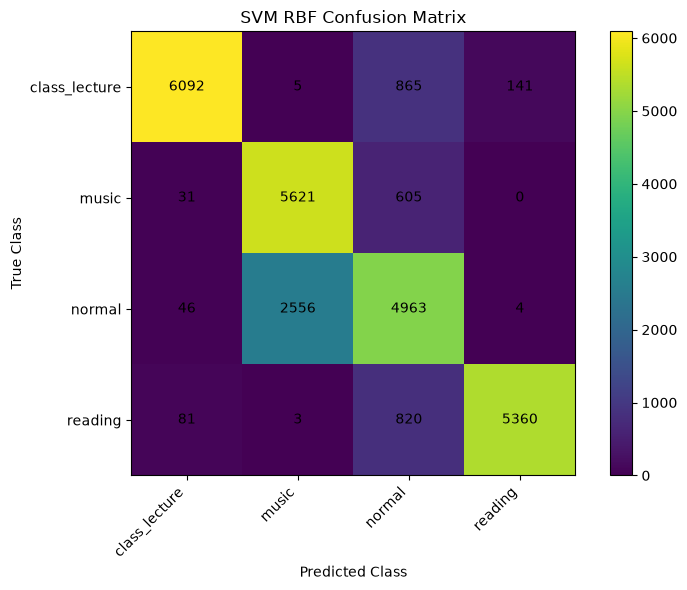

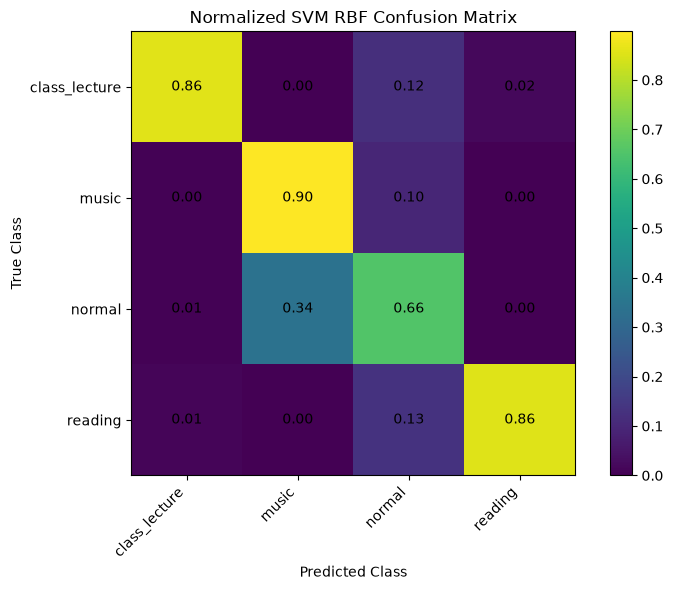


################################################################################
FINAL SVM RBF RESULTS
MAX DATASET
################################################################################
Backend                   : Intel Extension for Scikit Learn
Kernel                    : RBF
Features                  : 232
Best C                    : 145.28246637516014
Best Gamma                : 0.00011526449540315612

Optuna GroupKFold         : 0.8160
Training Accuracy         : 0.9953
Validation Accuracy       : 0.8739
Testing Accuracy          : 0.8104

Full LOGO Accuracy        : 0.8192 plus or minus 0.2053
Full LOGO Folds           : 42 of 42

Precision Weighted        : 0.8274
Recall Weighted           : 0.8104
F1 Weighted               : 0.8137
F1 Macro                  : 0.8179
Cohen Kappa               : 0.7471
MCC                       : 0.7506

Optuna Time               : 12.44 minutes
Five Run Time             : 0.75 minutes
Full LOGO Time            : 5.61 minutes
Test Pred

In [5]:
# ================================================================
# SVM RBF KERNEL
# MAX DATASET
#
# FULL DATASET
# PERSON WISE 70 / 20 / 10
# OPTUNA 10 TRIALS
# GROUPKFOLD 5
# FIVE FINAL RUNS
# FULL LEAVE ONE GROUP OUT
# NO LOGO CAP
# NO DATA SUBSAMPLING
#
# FOLD SPECIFIC STANDARDIZATION
# VALIDATION BASED MODEL SELECTION
# FINAL UNTOUCHED TEST EVALUATION
#
# RESUMABLE OPTUNA
# RESUMABLE LOGO
# COMPLETE METRICS
# CONFUSION MATRICES
# AUTOMATIC RESULT SAVING
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import json
import time
import random
import warnings

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)


# ================================================================
# SVM BACKEND
#
# Prefer Intel Extension for Scikit Learn.
# Fall back to standard Scikit Learn.
#
# No Intel Arc GPU offload is attempted here.
# ================================================================

try:

    from sklearnex.svm import SVC

    SVM_BACKEND = (
        "Intel Extension for Scikit Learn"
    )

except ImportError:

    from sklearn.svm import SVC

    SVM_BACKEND = (
        "Standard Scikit Learn"
    )


# ================================================================
# GLOBAL SETTINGS
# ================================================================

warnings.filterwarnings(
    "ignore"
)


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


SEED = 42

N_TRIALS = 10

N_RUNS = 5

GROUP_K_FOLDS = 5


# ================================================================
# SVM CACHE
#
# Med source used 1024 MB.
#
# 512 MB is intentionally used here to reduce memory pressure
# with the larger Max feature matrix.
# ================================================================

SVM_CACHE_MB = 512


random.seed(
    SEED
)

np.random.seed(
    SEED
)


# ================================================================
# MEMORY MONITOR
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# INPUT FILE
# ================================================================

FILE_PATH = Path(

    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"

)


if not FILE_PATH.exists():

    raise FileNotFoundError(

        f"Input file does not exist: "
        f"{FILE_PATH}"

    )


# ================================================================
# OUTPUT DIRECTORY
# ================================================================

OUTPUT_DIR = (

    FILE_PATH.parent
    / "Max_Dataset_SVM_RBF_Results"

)


OUTPUT_DIR.mkdir(

    parents=True,
    exist_ok=True

)


# ================================================================
# MODEL PATH
# ================================================================

BEST_MODEL_PATH = (

    OUTPUT_DIR
    / "svm_rbf_best_model.joblib"

)


# ================================================================
# OPTUNA DATABASE
#
# Completed Optuna trials survive kernel restart and power loss.
# ================================================================

OPTUNA_DATABASE = (

    OUTPUT_DIR
    / "svm_rbf_optuna.db"

)


OPTUNA_STORAGE = (

    f"sqlite:///{OPTUNA_DATABASE}"

)


OPTUNA_STUDY_NAME = (

    "Max_Dataset_SVM_RBF_v1"

)


# ================================================================
# TOTAL TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# INITIAL INFORMATION
# ================================================================

print("=" * 80)

print(
    "SVM RBF CLASSIFICATION"
)

print(
    "MAX DATASET"
)

print("=" * 80)


print(
    "SVM backend:",
    SVM_BACKEND
)


print(
    "Kernel: RBF"
)


print(
    "Optuna trials:",
    N_TRIALS
)


print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)


print(
    "Final runs:",
    N_RUNS
)


print(
    "SVM cache:",
    SVM_CACHE_MB,
    "MB"
)


print(
    "LOGO fold cap: NONE"
)


print(
    "Data subsampling: NONE"
)


print()

print(
    "Input:"
)

print(
    FILE_PATH
)


print()

print(
    "Output:"
)

print(
    OUTPUT_DIR
)


print("=" * 80)


# ================================================================
# LOAD COMPLETE DATASET
# ================================================================

print()

print("=" * 80)

print(
    "LOADING COMPLETE MAX DATASET"
)

print("=" * 80)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMN DEFINITIONS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


if len(feature_cols) == 0:

    raise ValueError(

        "No feature columns were detected."

    )


print(
    "Feature count:",
    len(feature_cols)
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(

        pd.to_numeric,

        errors="coerce"

    )

    .to_numpy(

        dtype=np.float32

    )

)


# ================================================================
# INVALID VALUE CHECK
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "Dataset contains NaN or infinite "
        "feature values."

    )


# ================================================================
# LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(

    np.int32

)


class_names = list(

    label_encoder.classes_

)


NUMBER_CLASSES = len(

    class_names

)


# ================================================================
# PARTICIPANT GROUPS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Classes:",
    class_names
)


print(
    "Number of classes:",
    NUMBER_CLASSES
)


print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


print(
    "Loading time:",
    f"{time.time() - load_start:.2f}",
    "seconds"
)


print(
    "Current RAM:",
    f"{mem_mb():.2f}",
    "MB"
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

class_distribution_records = []


print()

print(
    "CLASS DISTRIBUTION"
)


for class_index, class_name in enumerate(

    class_names

):

    count = int(

        np.sum(

            y_all
            == class_index

        )

    )


    percentage = (

        count
        / len(y_all)
        * 100.0

    )


    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


    class_distribution_records.append(

        {

            "Class":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage

        }

    )


pd.DataFrame(

    class_distribution_records

).to_csv(

    OUTPUT_DIR
    / "class_distribution.csv",

    index=False

)


# ================================================================
# RELEASE DATAFRAME
# ================================================================

del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10 SPLIT
# ================================================================

print()

print("=" * 80)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 80)


persons = np.unique(

    groups_all

)


rng = np.random.RandomState(

    SEED

)


rng.shuffle(

    persons

)


n_persons = len(

    persons

)


n_test = max(

    1,

    int(

        round(

            0.20
            * n_persons

        )

    )

)


n_validation = max(

    1,

    int(

        round(

            0.10
            * n_persons

        )

    )

)


# ================================================================
# PARTICIPANT SPLITS
# ================================================================

test_persons = persons[

    :n_test

]


validation_persons = persons[

    n_test:
    n_test + n_validation

]


train_persons = persons[

    n_test + n_validation:

]


# ================================================================
# SPLIT MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY ZERO PARTICIPANT OVERLAP
# ================================================================

assert (

    np.intersect1d(

        train_persons,

        validation_persons

    ).size == 0

)


assert (

    np.intersect1d(

        train_persons,

        test_persons

    ).size == 0

)


assert (

    np.intersect1d(

        validation_persons,

        test_persons

    ).size == 0

)


print(
    "Training participants:",
    len(train_persons)
)


print(
    "Validation participants:",
    len(validation_persons)
)


print(
    "Testing participants:",
    len(test_persons)
)


print()

print(
    "Training rows:",
    int(
        train_mask.sum()
    )
)


print(
    "Validation rows:",
    int(
        validation_mask.sum()
    )
)


print(
    "Testing rows:",
    int(
        test_mask.sum()
    )
)


# ================================================================
# CREATE SPLIT ARRAYS
# ================================================================

X_train_raw = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation_raw = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


g_validation = np.ascontiguousarray(

    groups_all[
        validation_mask
    ]

)


X_test_raw = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


g_test = np.ascontiguousarray(

    groups_all[
        test_mask
    ]

)


# ================================================================
# SAVE PARTICIPANT SPLIT
# ================================================================

split_table = pd.DataFrame(

    [

        {

            "Split":
                "Training",

            "Participants":
                len(train_persons),

            "Rows":
                len(X_train_raw)

        },

        {

            "Split":
                "Validation",

            "Participants":
                len(validation_persons),

            "Rows":
                len(X_validation_raw)

        },

        {

            "Split":
                "Testing",

            "Participants":
                len(test_persons),

            "Rows":
                len(X_test_raw)

        }

    ]

)


split_table.to_csv(

    OUTPUT_DIR
    / "split_summary.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "participant_split.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "training":

                [
                    str(x)
                    for x
                    in train_persons
                ],

            "validation":

                [
                    str(x)
                    for x
                    in validation_persons
                ],

            "testing":

                [
                    str(x)
                    for x
                    in test_persons
                ]

        },

        file,

        indent=4

    )


# ================================================================
# RELEASE COMPLETE ARRAYS
# ================================================================

del X_all
del y_all
del groups_all

del train_mask
del validation_mask
del test_mask

gc.collect()


print()

print(
    "Raw training matrix:",
    X_train_raw.shape
)


print(
    "Raw validation matrix:",
    X_validation_raw.shape
)


print(
    "Raw testing matrix:",
    X_test_raw.shape
)


print(
    "Current RAM:",
    f"{mem_mb():.2f}",
    "MB"
)


# ================================================================
# GROUPKFOLD
#
# Five split index sets are retained because Optuna reuses them.
# ================================================================

gkf_splits = list(

    GroupKFold(

        n_splits=
            GROUP_K_FOLDS

    ).split(

        X_train_raw,

        y_train,

        g_train

    )

)


print()

print(
    "GroupKFold folds:",
    len(gkf_splits)
)


# ================================================================
# FULL LOGO INFORMATION
#
# Do not materialize all LOGO index arrays.
#
# A new generator is created when LOGO is executed.
# ================================================================

FULL_LOGO_FOLDS = len(

    np.unique(
        g_train
    )

)


print(
    "Full LOGO folds:",
    FULL_LOGO_FOLDS
)


# ================================================================
# FOLD SPECIFIC STANDARDIZATION
# ================================================================

def prepare_fold(

    train_index,

    validation_index

):

    scaler = StandardScaler()


    X_fold_train = scaler.fit_transform(

        X_train_raw[
            train_index
        ]

    ).astype(

        np.float32

    )


    X_fold_validation = scaler.transform(

        X_train_raw[
            validation_index
        ]

    ).astype(

        np.float32

    )


    X_fold_train = np.ascontiguousarray(

        X_fold_train,

        dtype=np.float32

    )


    X_fold_validation = np.ascontiguousarray(

        X_fold_validation,

        dtype=np.float32

    )


    return (

        X_fold_train,

        X_fold_validation

    )


# ================================================================
# BUILD SVM
# ================================================================

def build_svm(

    C_value,

    gamma_value,

    seed=SEED

):

    return SVC(

        kernel=
            "rbf",

        C=
            float(
                C_value
            ),

        gamma=
            float(
                gamma_value
            ),

        class_weight=
            "balanced",

        shrinking=
            True,

        probability=
            False,

        tol=
            1e-3,

        cache_size=
            SVM_CACHE_MB,

        decision_function_shape=
            "ovr",

        random_state=
            int(seed)

    )


# ================================================================
# FIT SVM
# ================================================================

def fit_svm(

    X,

    y,

    C_value,

    gamma_value,

    seed=SEED

):

    model = build_svm(

        C_value,

        gamma_value,

        seed

    )


    X = np.ascontiguousarray(

        X,

        dtype=np.float32

    )


    y = np.ascontiguousarray(

        y,

        dtype=np.int32

    )


    model.fit(

        X,

        y

    )


    return model


# ================================================================
# PREDICT
# ================================================================

def predict_svm(

    model,

    X

):

    X = np.ascontiguousarray(

        X,

        dtype=np.float32

    )


    return model.predict(

        X

    )


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def objective(

    trial

):

    C_value = trial.suggest_float(

        "C",

        1e-2,

        1e3,

        log=True

    )


    gamma_value = trial.suggest_float(

        "gamma",

        1e-5,

        1.0,

        log=True

    )


    fold_scores = []


    print()

    print(

        f"Trial "
        f"{trial.number + 1}"

    )


    print(

        f"C = "
        f"{C_value:.8g}"

    )


    print(

        f"Gamma = "
        f"{gamma_value:.8g}"

    )


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        # ========================================================
        # FOLD SPECIFIC STANDARDIZATION
        # ========================================================

        (

            X_fold_train,

            X_fold_validation

        ) = prepare_fold(

            train_index,

            validation_index

        )


        # ========================================================
        # TRAIN
        # ========================================================

        model = fit_svm(

            X_fold_train,

            y_train[
                train_index
            ],

            C_value,

            gamma_value,

            SEED

        )


        # ========================================================
        # VALIDATE
        # ========================================================

        prediction = predict_svm(

            model,

            X_fold_validation

        )


        score = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        fold_scores.append(

            score

        )


        fold_time = (

            time.time()
            - fold_start

        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{score:.4f}, "

            f"Time = "
            f"{fold_time / 60:.2f} min, "

            f"RAM = "
            f"{mem_mb():.2f} MB"

        )


        del model
        del prediction
        del X_fold_train
        del X_fold_validation


        gc.collect()


    mean_score = float(

        np.mean(
            fold_scores
        )

    )


    std_score = float(

        np.std(
            fold_scores
        )

    )


    print(

        f"Trial "
        f"{trial.number + 1} "

        f"Mean Accuracy = "
        f"{mean_score:.4f} "

        f"plus or minus "
        f"{std_score:.4f}"

    )


    return mean_score


# ================================================================
# OPTUNA
# ================================================================

print()

print("=" * 80)

print(
    "RUNNING SVM RBF OPTUNA"
)

print("=" * 80)


optuna_start = time.time()


study = optuna.create_study(

    study_name=
        OPTUNA_STUDY_NAME,

    storage=
        OPTUNA_STORAGE,

    direction=
        "maximize",

    sampler=
        optuna.samplers.TPESampler(

            seed=SEED

        ),

    load_if_exists=
        True

)


# ================================================================
# RESUME COMPLETED OPTUNA TRIALS
# ================================================================

completed_trials = sum(

    1

    for trial
    in study.trials

    if trial.state
    == optuna.trial.TrialState.COMPLETE

)


remaining_trials = max(

    0,

    N_TRIALS
    - completed_trials

)


print(
    "Previously completed trials:",
    completed_trials
)


print(
    "Remaining trials:",
    remaining_trials
)


if remaining_trials > 0:

    study.optimize(

        objective,

        n_trials=
            remaining_trials,

        show_progress_bar=
            False,

        gc_after_trial=
            True

    )


# ================================================================
# VERIFY COMPLETED TRIAL
# ================================================================

complete_trials = [

    trial

    for trial in study.trials

    if trial.state
    == optuna.trial.TrialState.COMPLETE

]


if len(complete_trials) == 0:

    raise RuntimeError(

        "No Optuna trial completed successfully."

    )


optuna_time = (

    time.time()
    - optuna_start

)


best_C = float(

    study.best_params[
        "C"
    ]

)


best_gamma = float(

    study.best_params[
        "gamma"
    ]

)


print()

print("=" * 80)

print(
    "OPTUNA COMPLETED"
)

print("=" * 80)


print(
    "Best GroupKFold accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Best C:",
    best_C
)


print(
    "Best gamma:",
    best_gamma
)


print(
    "Optuna execution time:",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


# ================================================================
# SAVE OPTUNA RESULTS
# ================================================================

study.trials_dataframe().to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {

            "C":
                best_C,

            "gamma":
                best_gamma,

            "best_groupkfold_accuracy":
                float(
                    study.best_value
                )

        },

        file,

        indent=4

    )


# ================================================================
# FINAL STANDARDIZATION
#
# Fit only on the 70 percent training participants.
# ================================================================

print()

print("=" * 80)

print(
    "FINAL STANDARDIZATION"
)

print("=" * 80)


final_scaler = StandardScaler()


X_train = final_scaler.fit_transform(

    X_train_raw

).astype(

    np.float32

)


X_validation = final_scaler.transform(

    X_validation_raw

).astype(

    np.float32

)


X_test = final_scaler.transform(

    X_test_raw

).astype(

    np.float32

)


X_train = np.ascontiguousarray(

    X_train,

    dtype=np.float32

)


X_validation = np.ascontiguousarray(

    X_validation,

    dtype=np.float32

)


X_test = np.ascontiguousarray(

    X_test,

    dtype=np.float32

)


print(
    "Training matrix:",
    X_train.shape
)


print(
    "Validation matrix:",
    X_validation.shape
)


print(
    "Testing matrix:",
    X_test.shape
)


print(
    "RAM:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# SAVE PREPROCESSING
# ================================================================

joblib.dump(

    final_scaler,

    OUTPUT_DIR
    / "standard_scaler.joblib",

    compress=0

)


joblib.dump(

    label_encoder,

    OUTPUT_DIR
    / "label_encoder.joblib",

    compress=0

)


with open(

    OUTPUT_DIR
    / "feature_columns.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        feature_cols,

        file,

        indent=4

    )


# ================================================================
# RAW VALIDATION AND TEST MATRICES ARE NO LONGER REQUIRED
#
# X_train_raw must remain because LOGO needs fold specific scaling.
# ================================================================

del X_validation_raw
del X_test_raw

gc.collect()


# ================================================================
# FIVE FINAL RUNS
#
# RBF SVC with probability=False is effectively deterministic.
#
# Five runs are retained to match the Med experiment.
#
# Selection is based only on the validation participants.
# ================================================================

print()

print("=" * 80)

print(
    f"FINAL SVM TRAINING: "
    f"{N_RUNS} RUNS"
)

print("=" * 80)


run_records = []


best_record = None


best_validation_accuracy = float(

    "-inf"

)


five_run_start = time.time()


for run_number in range(

    1,

    N_RUNS + 1

):

    print()

    print(

        f"RUN "
        f"{run_number}/"
        f"{N_RUNS}"

    )


    run_start = time.time()


    model = fit_svm(

        X_train,

        y_train,

        best_C,

        best_gamma,

        seed=(
            SEED
            + run_number
            - 1
        )

    )


    # ============================================================
    # TRAIN PREDICTION
    # ============================================================

    train_prediction = predict_svm(

        model,

        X_train

    )


    train_accuracy = accuracy_score(

        y_train,

        train_prediction

    )


    # ============================================================
    # VALIDATION PREDICTION
    # ============================================================

    validation_prediction = predict_svm(

        model,

        X_validation

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    run_time = (

        time.time()
        - run_start

    )


    record = {

        "Run":
            run_number,

        "Seed":
            SEED
            + run_number
            - 1,

        "Training_Accuracy":
            float(
                train_accuracy
            ),

        "Validation_Accuracy":
            float(
                validation_accuracy
            ),

        "Execution_Time_Seconds":
            float(
                run_time
            )

    }


    run_records.append(

        record

    )


    print(
        "Training accuracy   :",
        f"{train_accuracy:.4f}"
    )


    print(
        "Validation accuracy :",
        f"{validation_accuracy:.4f}"
    )


    print(
        "Execution time      :",
        f"{run_time / 60:.2f}",
        "minutes"
    )


    print(
        "RAM                 :",
        f"{mem_mb():.2f}",
        "MB"
    )


    # ============================================================
    # SELECT USING VALIDATION SET ONLY
    # ============================================================

    if (

        validation_accuracy
        > best_validation_accuracy

    ):

        best_validation_accuracy = (

            validation_accuracy

        )


        best_record = (

            record.copy()

        )


        # Save immediately so another full model
        # does not need to remain in RAM.

        joblib.dump(

            model,

            BEST_MODEL_PATH,

            compress=0

        )


    del model
    del train_prediction
    del validation_prediction


    gc.collect()


five_run_time = (

    time.time()
    - five_run_start

)


run_table = pd.DataFrame(

    run_records

)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()

print("=" * 80)

print(
    "FIVE RUN RESULTS"
)

print("=" * 80)


print(

    run_table

    .round(4)

    .to_string(
        index=False
    )

)


print()

print(
    "Selected run:",
    best_record[
        "Run"
    ]
)


print(
    "Selected validation accuracy:",
    f"{best_validation_accuracy:.4f}"
)


# ================================================================
# LOAD SELECTED BEST MODEL
# ================================================================

best_model = joblib.load(

    BEST_MODEL_PATH

)


# ================================================================
# FULL LEAVE ONE GROUP OUT
#
# NO CAP
#
# Checkpoint is written after every participant.
# ================================================================

print()

print("=" * 80)

print(
    "FULL LEAVE ONE GROUP OUT CROSS VALIDATION"
)

print(
    "Total LOGO folds:",
    FULL_LOGO_FOLDS
)

print(
    "Fold cap: NONE"
)

print("=" * 80)


logo_result_path = (

    OUTPUT_DIR
    / "full_logo_results.csv"

)


# ================================================================
# RESUME EXISTING LOGO
# ================================================================

logo_records = []

completed_persons = set()


if logo_result_path.exists():

    previous_logo = pd.read_csv(

        logo_result_path

    )


    valid_checkpoint = True


    required_logo_columns = {

        "Held_Out_Person",

        "Accuracy",

        "Best_C",

        "Best_Gamma"

    }


    if not required_logo_columns.issubset(

        previous_logo.columns

    ):

        valid_checkpoint = False


    if valid_checkpoint and len(previous_logo) > 0:

        same_C = np.isclose(

            previous_logo[
                "Best_C"
            ].astype(float),

            best_C,

            rtol=1e-10,

            atol=1e-12

        ).all()


        same_gamma = np.isclose(

            previous_logo[
                "Best_Gamma"
            ].astype(float),

            best_gamma,

            rtol=1e-10,

            atol=1e-12

        ).all()


        valid_checkpoint = (

            same_C
            and
            same_gamma

        )


    if valid_checkpoint:

        logo_records = (

            previous_logo

            .to_dict(
                orient="records"
            )

        )


        completed_persons = set(

            previous_logo[
                "Held_Out_Person"
            ].astype(str)

        )


        print(
            "Previously completed LOGO folds:",
            len(
                completed_persons
            )
        )


    else:

        print(
            "Existing LOGO checkpoint does not "
            "match the current model parameters."
        )

        print(
            "LOGO will restart."
        )


logo_start = time.time()


logo_splitter = LeaveOneGroupOut()


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    logo_splitter.split(

        X_train_raw,

        y_train,

        g_train

    ),

    start=1

):

    held_out_persons = np.unique(

        g_train[
            validation_index
        ]

    )


    if len(held_out_persons) != 1:

        raise RuntimeError(

            "LOGO fold contains an unexpected "
            "number of held out participants."

        )


    held_out_person = str(

        held_out_persons[
            0
        ]

    )


    # ============================================================
    # SKIP COMPLETED PARTICIPANT
    # ============================================================

    if (

        held_out_person
        in completed_persons

    ):

        print(

            f"LOGO "
            f"{fold_number}/"
            f"{FULL_LOGO_FOLDS}, "

            f"Participant "
            f"{held_out_person} "

            f"already completed"

        )


        continue


    fold_start = time.time()


    # ============================================================
    # FOLD SPECIFIC SCALING
    # ============================================================

    (

        X_fold_train,

        X_fold_validation

    ) = prepare_fold(

        train_index,

        validation_index

    )


    # ============================================================
    # TRAIN
    # ============================================================

    model = fit_svm(

        X_fold_train,

        y_train[
            train_index
        ],

        best_C,

        best_gamma,

        SEED

    )


    # ============================================================
    # PREDICT HELD OUT PARTICIPANT
    # ============================================================

    prediction = predict_svm(

        model,

        X_fold_validation

    )


    fold_accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    fold_time = (

        time.time()
        - fold_start

    )


    record = {

        "Fold":
            fold_number,

        "Held_Out_Person":
            held_out_person,

        "Test_Rows":
            int(
                len(
                    validation_index
                )
            ),

        "Accuracy":
            float(
                fold_accuracy
            ),

        "Best_C":
            float(
                best_C
            ),

        "Best_Gamma":
            float(
                best_gamma
            ),

        "Execution_Time_Seconds":
            float(
                fold_time
            )

    }


    logo_records.append(

        record

    )


    # ============================================================
    # CHECKPOINT IMMEDIATELY
    # ============================================================

    pd.DataFrame(

        logo_records

    ).to_csv(

        logo_result_path,

        index=False

    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{FULL_LOGO_FOLDS}, "

        f"Participant = "
        f"{held_out_person}, "

        f"Accuracy = "
        f"{fold_accuracy:.4f}, "

        f"Time = "
        f"{fold_time / 60:.2f} min, "

        f"RAM = "
        f"{mem_mb():.2f} MB"

    )


    del model
    del prediction
    del X_fold_train
    del X_fold_validation


    gc.collect()


logo_time = (

    time.time()
    - logo_start

)


# ================================================================
# LOGO SUMMARY
# ================================================================

logo_table = pd.read_csv(

    logo_result_path

)


logo_accuracies = (

    logo_table[
        "Accuracy"
    ]

    .astype(float)

    .to_numpy()

)


logo_mean = float(

    np.mean(
        logo_accuracies
    )

)


logo_std = float(

    np.std(
        logo_accuracies
    )

)


print()

print("=" * 80)

print(
    "FULL LOGO COMPLETED"
)

print("=" * 80)


print(
    "LOGO folds completed:",
    len(
        logo_table
    )
)


print(
    "Mean LOGO accuracy:",
    f"{logo_mean:.4f}"
)


print(
    "LOGO standard deviation:",
    f"{logo_std:.4f}"
)


print(
    "LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "LOGO time this session:",
    f"{logo_time / 60:.2f}",
    "minutes"
)


# ================================================================
# FINAL UNTOUCHED TEST EVALUATION
#
# Test participants have not been used for:
#
# Optuna
# scaling fit
# GroupKFold
# model selection
# LOGO
# ================================================================

print()

print("=" * 80)

print(
    "FINAL UNTOUCHED TEST EVALUATION"
)

print("=" * 80)


test_start = time.time()


test_prediction = predict_svm(

    best_model,

    X_test

)


test_prediction_time = (

    time.time()
    - test_start

)


# ================================================================
# FINAL TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average="macro",

    zero_division=0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=np.arange(
        NUMBER_CLASSES
    ),

    target_names=
        class_names,

    digits=4,

    zero_division=0

)


print()

print(
    "CLASSIFICATION REPORT"
)

print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(

        report

    )


report_table = pd.DataFrame(

    classification_report(

        y_test,

        test_prediction,

        labels=np.arange(
            NUMBER_CLASSES
        ),

        target_names=
            class_names,

        output_dict=True,

        zero_division=0

    )

).transpose()


report_table.to_csv(

    OUTPUT_DIR
    / "classification_report.csv"

)


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=np.arange(
        NUMBER_CLASSES
    )

)


pd.DataFrame(

    cm,

    index=class_names,

    columns=class_names

).to_csv(

    OUTPUT_DIR
    / "confusion_matrix.csv"

)


# ================================================================
# CONFUSION MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(

    cm

)


ax.set_xticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "SVM RBF Confusion Matrix"

)


for row in range(

    NUMBER_CLASSES

):

    for column in range(

        NUMBER_CLASSES

    ):

        ax.text(

            column,

            row,

            str(
                cm[
                    row,
                    column
                ]
            ),

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(

    axis=1,

    keepdims=True

)


normalized_cm = np.divide(

    cm,

    row_sums,

    out=np.zeros_like(

        cm,

        dtype=np.float64

    ),

    where=(

        row_sums != 0

    )

)


pd.DataFrame(

    normalized_cm,

    index=class_names,

    columns=class_names

).to_csv(

    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"

)


# ================================================================
# NORMALIZED CONFUSION MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(

    normalized_cm

)


ax.set_xticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(

    class_names

)


ax.set_xlabel(

    "Predicted Class"

)


ax.set_ylabel(

    "True Class"

)


ax.set_title(

    "Normalized SVM RBF Confusion Matrix"

)


for row in range(

    NUMBER_CLASSES

):

    for column in range(

        NUMBER_CLASSES

    ):

        ax.text(

            column,

            row,

            f"{normalized_cm[row, column]:.2f}",

            ha="center",

            va="center"

        )


fig.colorbar(

    image,

    ax=ax

)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "normalized_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {

        "PersonSrial":

            g_test,

        "True_Class":

            label_encoder.inverse_transform(

                y_test

            ),

        "Predicted_Class":

            label_encoder.inverse_transform(

                test_prediction.astype(
                    np.int32
                )

            )

    }

)


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# FIVE RUN STATISTICS
# ================================================================

five_run_train_mean = float(

    run_table[
        "Training_Accuracy"
    ].mean()

)


five_run_train_std = float(

    run_table[
        "Training_Accuracy"
    ].std(
        ddof=0
    )

)


five_run_validation_mean = float(

    run_table[
        "Validation_Accuracy"
    ].mean()

)


five_run_validation_std = float(

    run_table[
        "Validation_Accuracy"
    ].std(
        ddof=0
    )

)


# ================================================================
# TOTAL EXECUTION TIME
# ================================================================

total_execution_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {

    "Algorithm":

        "SVM RBF",

    "Dataset":

        "Max Dataset",

    "SVM_Backend":

        SVM_BACKEND,

    "Kernel":

        "RBF",

    "Feature_Count":

        int(
            X_train.shape[
                1
            ]
        ),

    "Number_of_Classes":

        int(
            NUMBER_CLASSES
        ),

    "Classes":

        class_names,

    "Training_Participants":

        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":

        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":

        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":

        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":

        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":

        int(
            len(
                X_test
            )
        ),

    "Optuna_Trials_Target":

        int(
            N_TRIALS
        ),

    "Best_C":

        float(
            best_C
        ),

    "Best_Gamma":

        float(
            best_gamma
        ),

    "Best_Optuna_GroupKFold_Accuracy":

        float(
            study.best_value
        ),

    "Best_Run":

        int(
            best_record[
                "Run"
            ]
        ),

    "Training_Accuracy":

        float(
            best_record[
                "Training_Accuracy"
            ]
        ),

    "Validation_Accuracy":

        float(
            best_record[
                "Validation_Accuracy"
            ]
        ),

    "Testing_Accuracy":

        float(
            test_accuracy
        ),

    "Five_Run_Training_Mean":

        five_run_train_mean,

    "Five_Run_Training_STD":

        five_run_train_std,

    "Five_Run_Validation_Mean":

        five_run_validation_mean,

    "Five_Run_Validation_STD":

        five_run_validation_std,

    "Full_LOGO_Accuracy":

        float(
            logo_mean
        ),

    "Full_LOGO_STD":

        float(
            logo_std
        ),

    "Full_LOGO_Folds_Available":

        int(
            FULL_LOGO_FOLDS
        ),

    "Full_LOGO_Folds_Completed":

        int(
            len(
                logo_table
            )
        ),

    "Precision_Weighted":

        float(
            test_precision
        ),

    "Recall_Weighted":

        float(
            test_recall
        ),

    "F1_Weighted":

        float(
            test_f1_weighted
        ),

    "F1_Macro":

        float(
            test_f1_macro
        ),

    "Cohen_Kappa":

        float(
            test_kappa
        ),

    "MCC":

        float(
            test_mcc
        ),

    "SVM_Cache_MB":

        int(
            SVM_CACHE_MB
        ),

    "Optuna_Time_Seconds":

        float(
            optuna_time
        ),

    "Five_Run_Time_Seconds":

        float(
            five_run_time
        ),

    "Full_LOGO_Time_This_Session_Seconds":

        float(
            logo_time
        ),

    "Test_Prediction_Time_Seconds":

        float(
            test_prediction_time
        ),

    "Total_Execution_Time_Seconds":

        float(
            total_execution_time
        ),

    "Current_RAM_MB":

        float(
            mem_mb()
        )

}


# ================================================================
# SAVE FINAL METRICS
# ================================================================

with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=4

    )


# ================================================================
# FINAL SUMMARY TXT
# ================================================================

summary_lines = [

    "SVM RBF FINAL RESULTS",

    "MAX DATASET",

    "",

    f"Backend: "
    f"{SVM_BACKEND}",

    f"Kernel: RBF",

    f"Features: "
    f"{X_train.shape[1]}",

    "",

    f"Best C: "
    f"{best_C}",

    f"Best Gamma: "
    f"{best_gamma}",

    "",

    f"Optuna GroupKFold Accuracy: "
    f"{study.best_value:.4f}",

    f"Training Accuracy: "
    f"{best_record['Training_Accuracy']:.4f}",

    f"Validation Accuracy: "
    f"{best_record['Validation_Accuracy']:.4f}",

    f"Testing Accuracy: "
    f"{test_accuracy:.4f}",

    "",

    f"Full LOGO Accuracy: "
    f"{logo_mean:.4f} "
    f"plus or minus "
    f"{logo_std:.4f}",

    f"Full LOGO Folds Completed: "
    f"{len(logo_table)}",

    "",

    f"Precision Weighted: "
    f"{test_precision:.4f}",

    f"Recall Weighted: "
    f"{test_recall:.4f}",

    f"F1 Weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 Macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    "",

    f"Optuna Time: "
    f"{optuna_time / 60:.2f} minutes",

    f"Five Run Time: "
    f"{five_run_time / 60:.2f} minutes",

    f"Full LOGO Time This Session: "
    f"{logo_time / 60:.2f} minutes",

    f"Test Prediction Time: "
    f"{test_prediction_time:.2f} seconds",

    f"Total Execution Time: "
    f"{total_execution_time / 60:.2f} minutes"

]


with open(

    OUTPUT_DIR
    / "final_summary.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(

        "\n".join(
            summary_lines
        )

    )


# ================================================================
# FINAL SCREEN OUTPUT
# ================================================================

print()

print("#" * 80)

print(
    "FINAL SVM RBF RESULTS"
)

print(
    "MAX DATASET"
)

print("#" * 80)


print(
    "Backend                   :",
    SVM_BACKEND
)


print(
    "Kernel                    : RBF"
)


print(
    "Features                  :",
    X_train.shape[
        1
    ]
)


print(
    "Best C                    :",
    best_C
)


print(
    "Best Gamma                :",
    best_gamma
)


print()

print(
    "Optuna GroupKFold         :",
    f"{study.best_value:.4f}"
)


print(
    "Training Accuracy         :",
    f"{best_record['Training_Accuracy']:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{best_record['Validation_Accuracy']:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "Full LOGO Accuracy        :",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "Full LOGO Folds           :",
    len(
        logo_table
    ),
    "of",
    FULL_LOGO_FOLDS
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


print()

print(
    "Optuna Time               :",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


print(
    "Five Run Time             :",
    f"{five_run_time / 60:.2f}",
    "minutes"
)


print(
    "Full LOGO Time            :",
    f"{logo_time / 60:.2f}",
    "minutes"
)


print(
    "Test Prediction Time      :",
    f"{test_prediction_time:.2f}",
    "seconds"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "No LOGO folds were capped."
)


print(
    "No dataset rows were subsampled."
)


print(
    "All five GroupKFold folds were used "
    "for every Optuna trial."
)


print(
    "Each GroupKFold and LOGO fold "
    "used its own StandardScaler."
)


print(
    "Test participants were not used "
    "for Optuna or model selection."
)


print()

print(
    "ALL RESULTS SAVED IN:"
)


print(
    OUTPUT_DIR
)


print("#" * 80)

**Apply Logistic Regression on Max Dataset**

LOGISTIC REGRESSION CLASSIFICATION
MAX DATASET
Dataset: /home/rakib/Desktop/ml_apply/ml_max_dataset/Cleaned_oN_Selected_Max.csv
Output: /home/rakib/Desktop/ml_apply/ml_max_dataset/Max_Dataset_Logistic_Regression_Results
Optuna trials: 10
GroupKFold folds: 5
Final runs: 5
LOGO fold cap: NONE
Data subsampling: NONE
Solver: LBFGS
Penalty: L2
Maximum iterations: 2000
Tolerance: 0.0001

LOADING COMPLETE MAX DATASET
Raw dataset shape: (149350, 238)
RAM after loading: 5733.24 MB
Feature columns: 232
Invalid feature cells: 0

Feature matrix: (149350, 232)
Classes: ['class_lecture', 'music', 'normal', 'reading']
Number of classes: 4
Participants: 60

CLASS DISTRIBUTION
class_lecture: 39857 (26.69%)
music: 32276 (21.61%)
normal: 39327 (26.33%)
reading: 37890 (25.37%)

Loading time: 8.34 seconds
Current RAM: 5686.66 MB

PERSON WISE 70 / 20 / 10 SPLIT
Training participants: 42
Validation participants: 6
Testing participants: 12

Training rows: 107752
Validation rows: 14405
Testing rows: 27193

Tra

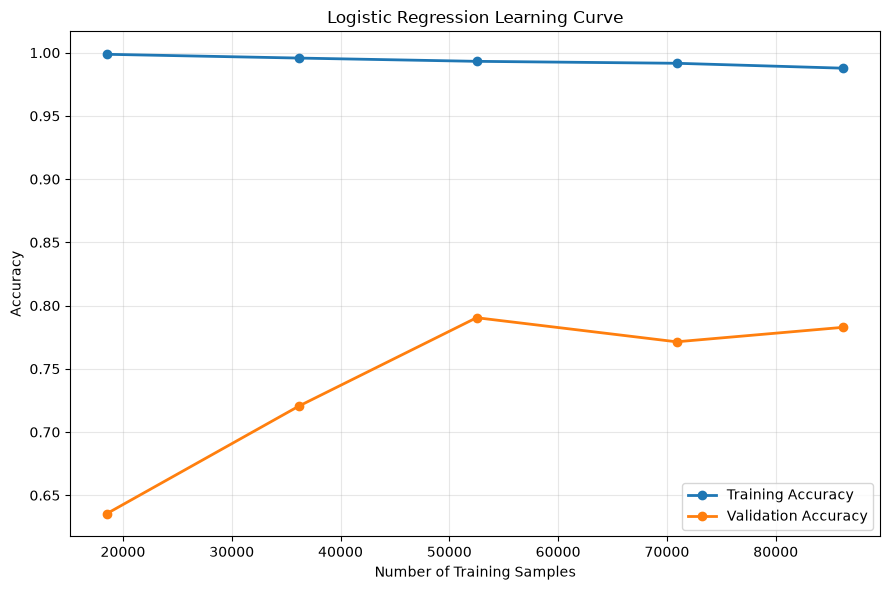


FINAL STANDARDIZATION
Training: (107752, 232)
Validation: (14405, 232)
Testing: (27193, 232)
Current RAM: 5805.59 MB

FINAL LOGISTIC REGRESSION: 5 RUNS

RUN 1/5
Training accuracy: 0.9829
Validation accuracy: 0.8749
Iterations: 155
Converged: True
Execution time: 17.05 seconds

RUN 2/5
Training accuracy: 0.9829
Validation accuracy: 0.8749
Iterations: 155
Converged: True
Execution time: 17.16 seconds

RUN 3/5
Training accuracy: 0.9829
Validation accuracy: 0.8749
Iterations: 155
Converged: True
Execution time: 17.56 seconds

RUN 4/5
Training accuracy: 0.9829
Validation accuracy: 0.8749
Iterations: 155
Converged: True
Execution time: 17.24 seconds

RUN 5/5
Training accuracy: 0.9829
Validation accuracy: 0.8749
Iterations: 155
Converged: True
Execution time: 17.34 seconds

 Run  Seed  Training_Accuracy  Validation_Accuracy  Iterations  Converged  Execution_Time_Seconds
   1    42             0.9829               0.8749         155       True                 17.0506
   2    43             0.

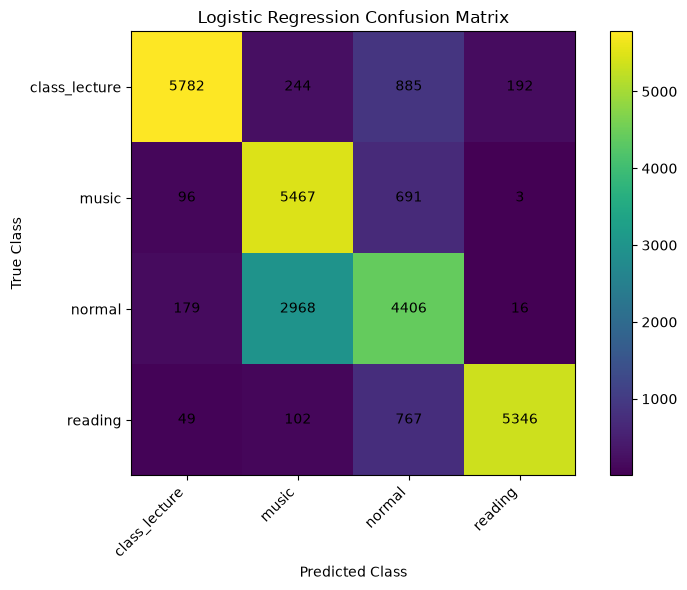

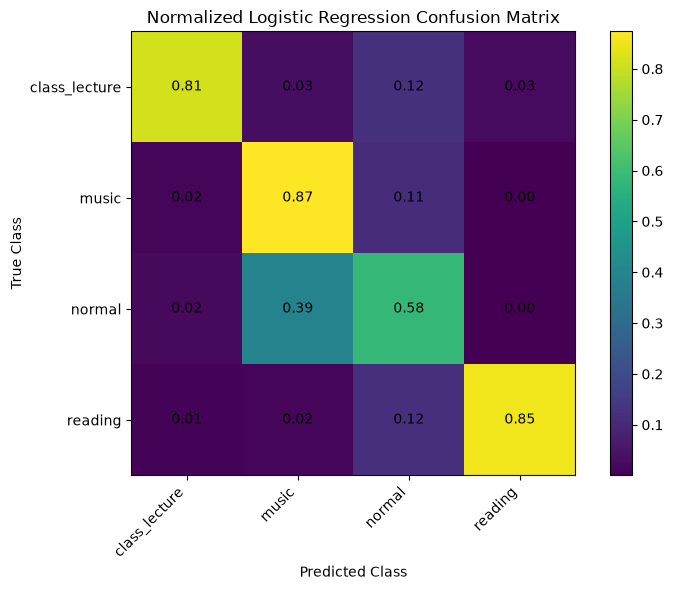


################################################################################
FINAL LOGISTIC REGRESSION RESULTS
MAX DATASET
################################################################################
Best C                    : 0.041858227295469716
Penalty                   : L2
Solver                    : LBFGS
Selected Run              : 1
Selected Iterations       : 155
Selected Run Converged    : True

Optuna GroupKFold         : 0.7828
Training Accuracy         : 0.9829
Validation Accuracy       : 0.8749
Testing Accuracy          : 0.7723

Five Run Train            : 0.9829 plus or minus 0.0000
Five Run Validation       : 0.8749 plus or minus 0.0000

FULL LOGO Accuracy        : 0.7912 plus or minus 0.2198
FULL LOGO Folds           : 42 of 42

Precision Weighted        : 0.7939
Recall Weighted           : 0.7723
F1 Weighted               : 0.7756
F1 Macro                  : 0.7806
Cohen Kappa               : 0.6968
MCC                       : 0.7022
ROC AUC Weighted OVR   

In [6]:
# ================================================================
# LOGISTIC REGRESSION CLASSIFICATION
# MAX DATASET
#
# FULL DATASET
# PERSON WISE 70 / 20 / 10
# OPTUNA HYPERPARAMETER OPTIMIZATION
# GROUPKFOLD 5
# FIVE FINAL RUNS
# FULL LEAVE ONE GROUP OUT
# NO LOGO CAP
# NO DATA SUBSAMPLING
#
# FOLD SPECIFIC STANDARDIZATION
# PARTICIPANT AWARE LEARNING CURVE
# CONFUSION MATRIX
# NORMALIZED CONFUSION MATRIX
# ROC AUC
#
# RESUMABLE OPTUNA
# RESUMABLE LEARNING CURVE
# RESUMABLE LOGO
#
# TEST PARTICIPANTS ARE NOT USED FOR MODEL SELECTION
# ================================================================


# ================================================================
# IMPORTS
# ================================================================

import os
import gc
import json
import time
import random
import pickle
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import optuna
import joblib

from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import (
    GroupKFold,
    LeaveOneGroupOut
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ================================================================
# GLOBAL SETTINGS
# ================================================================

warnings.filterwarnings(
    "ignore"
)


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


SEED = 42

N_TRIALS = 10

N_RUNS = 5

GROUP_K_FOLDS = 5

MAX_ITER = 2000

TOLERANCE = 1e-4


random.seed(
    SEED
)

np.random.seed(
    SEED
)


# ================================================================
# MEMORY MONITOR
# ================================================================

PROC = psutil.Process(
    os.getpid()
)


def mem_mb():

    return (
        PROC.memory_info().rss
        / 1024
        / 1024
    )


# ================================================================
# SAFE CSV CHECKPOINT
# ================================================================

def atomic_csv(
    dataframe,
    path
):

    path = Path(
        path
    )

    temporary_path = path.with_name(
        path.name
        + ".tmp"
    )

    dataframe.to_csv(
        temporary_path,
        index=False
    )

    os.replace(
        temporary_path,
        path
    )


# ================================================================
# INPUT
# ================================================================

FILE_PATH = Path(

    "/home/rakib/Desktop/ml_apply/"
    "ml_max_dataset/"
    "Cleaned_oN_Selected_Max.csv"

)


if not FILE_PATH.exists():

    raise FileNotFoundError(

        f"Input file was not found: "
        f"{FILE_PATH}"

    )


# ================================================================
# OUTPUT
# ================================================================

OUTPUT_DIR = (

    FILE_PATH.parent
    / "Max_Dataset_Logistic_Regression_Results"

)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ================================================================
# IMPORTANT OUTPUT PATHS
# ================================================================

BEST_MODEL_PATH = (
    OUTPUT_DIR
    / "logistic_regression_best_model.joblib"
)


OPTUNA_DATABASE = (
    OUTPUT_DIR
    / "logistic_regression_optuna.db"
)


OPTUNA_STORAGE = (
    f"sqlite:///{OPTUNA_DATABASE}"
)


OPTUNA_STUDY_NAME = (
    "Max_Dataset_Logistic_Regression_v1"
)


LEARNING_CHECKPOINT = (
    OUTPUT_DIR
    / "learning_curve_fold_results.csv"
)


LOGO_CHECKPOINT = (
    OUTPUT_DIR
    / "full_logo_results.csv"
)


# ================================================================
# TOTAL TIMER
# ================================================================

TOTAL_START = time.time()


# ================================================================
# EXPERIMENT INFORMATION
# ================================================================

print("=" * 80)

print(
    "LOGISTIC REGRESSION CLASSIFICATION"
)

print(
    "MAX DATASET"
)

print("=" * 80)


print(
    "Dataset:",
    FILE_PATH
)


print(
    "Output:",
    OUTPUT_DIR
)


print(
    "Optuna trials:",
    N_TRIALS
)


print(
    "GroupKFold folds:",
    GROUP_K_FOLDS
)


print(
    "Final runs:",
    N_RUNS
)


print(
    "LOGO fold cap: NONE"
)


print(
    "Data subsampling: NONE"
)


print(
    "Solver: LBFGS"
)


print(
    "Penalty: L2"
)


print(
    "Maximum iterations:",
    MAX_ITER
)


print(
    "Tolerance:",
    TOLERANCE
)


print("=" * 80)


# ================================================================
# LOAD COMPLETE DATASET
# ================================================================

print()

print("=" * 80)

print(
    "LOADING COMPLETE MAX DATASET"
)

print("=" * 80)


load_start = time.time()


df = pd.read_csv(

    FILE_PATH,

    low_memory=False

)


print(
    "Raw dataset shape:",
    df.shape
)


print(
    "RAM after loading:",
    f"{mem_mb():.2f} MB"
)


# ================================================================
# COLUMN DEFINITIONS
# ================================================================

metadata_cols = [

    "PersonSrial",

    "Window",

    "Window_Start",

    "Window_End",

    "Window_Samples"

]


target_col = "Class"


required_columns = [

    "PersonSrial",

    target_col

]


for column in required_columns:

    if column not in df.columns:

        raise ValueError(

            f"Required column missing: "
            f"{column}"

        )


# ================================================================
# FEATURE COLUMNS
# ================================================================

feature_cols = [

    column

    for column in df.columns

    if column not in metadata_cols

    and column != target_col

]


if len(feature_cols) == 0:

    raise ValueError(
        "No feature columns were found."
    )


print(
    "Feature columns:",
    len(feature_cols)
)


# ================================================================
# FEATURE MATRIX
# ================================================================

X_all = (

    df[
        feature_cols
    ]

    .apply(
        pd.to_numeric,
        errors="coerce"
    )

    .to_numpy(
        dtype=np.float32
    )

)


# ================================================================
# INVALID VALUE CHECK
# ================================================================

invalid_count = int(

    (
        ~np.isfinite(
            X_all
        )
    ).sum()

)


print(
    "Invalid feature cells:",
    invalid_count
)


if invalid_count > 0:

    raise ValueError(

        "Dataset contains NaN or infinite "
        "feature values."

    )


# ================================================================
# LABEL ENCODING
# ================================================================

label_encoder = LabelEncoder()


y_all = label_encoder.fit_transform(

    df[
        target_col
    ].astype(str)

).astype(
    np.int32
)


class_names = list(
    label_encoder.classes_
)


NUMBER_CLASSES = len(
    class_names
)


# ================================================================
# PARTICIPANT GROUPS
# ================================================================

groups_all = (

    df[
        "PersonSrial"
    ]

    .to_numpy()

)


print()

print(
    "Feature matrix:",
    X_all.shape
)


print(
    "Classes:",
    class_names
)


print(
    "Number of classes:",
    NUMBER_CLASSES
)


print(
    "Participants:",
    len(
        np.unique(
            groups_all
        )
    )
)


# ================================================================
# CLASS DISTRIBUTION
# ================================================================

print()

print(
    "CLASS DISTRIBUTION"
)


class_distribution_records = []


for class_index, class_name in enumerate(
    class_names
):

    count = int(

        np.sum(
            y_all
            == class_index
        )

    )


    percentage = (

        count
        / len(y_all)
        * 100.0

    )


    print(

        f"{class_name}: "
        f"{count} "
        f"({percentage:.2f}%)"

    )


    class_distribution_records.append(

        {
            "Class":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage
        }

    )


pd.DataFrame(
    class_distribution_records
).to_csv(

    OUTPUT_DIR
    / "class_distribution.csv",

    index=False

)


print()

print(
    "Loading time:",
    f"{time.time() - load_start:.2f}",
    "seconds"
)


print(
    "Current RAM:",
    f"{mem_mb():.2f}",
    "MB"
)


# ================================================================
# RELEASE DATAFRAME
# ================================================================

del df

gc.collect()


# ================================================================
# PERSON WISE 70 / 20 / 10
# ================================================================

print()

print("=" * 80)

print(
    "PERSON WISE 70 / 20 / 10 SPLIT"
)

print("=" * 80)


persons = np.unique(
    groups_all
)


rng = np.random.RandomState(
    SEED
)


rng.shuffle(
    persons
)


n_persons = len(
    persons
)


n_test = max(

    1,

    int(
        round(
            0.20
            * n_persons
        )
    )

)


n_validation = max(

    1,

    int(
        round(
            0.10
            * n_persons
        )
    )

)


test_persons = persons[
    :n_test
]


validation_persons = persons[

    n_test:
    n_test
    + n_validation

]


train_persons = persons[
    n_test
    + n_validation:
]


# ================================================================
# MASKS
# ================================================================

train_mask = np.isin(

    groups_all,

    train_persons

)


validation_mask = np.isin(

    groups_all,

    validation_persons

)


test_mask = np.isin(

    groups_all,

    test_persons

)


# ================================================================
# VERIFY PARTICIPANT INDEPENDENCE
# ================================================================

assert (
    np.intersect1d(
        train_persons,
        validation_persons
    ).size == 0
)


assert (
    np.intersect1d(
        train_persons,
        test_persons
    ).size == 0
)


assert (
    np.intersect1d(
        validation_persons,
        test_persons
    ).size == 0
)


print(
    "Training participants:",
    len(train_persons)
)


print(
    "Validation participants:",
    len(validation_persons)
)


print(
    "Testing participants:",
    len(test_persons)
)


print()

print(
    "Training rows:",
    int(
        train_mask.sum()
    )
)


print(
    "Validation rows:",
    int(
        validation_mask.sum()
    )
)


print(
    "Testing rows:",
    int(
        test_mask.sum()
    )
)


# ================================================================
# CREATE SPLITS
# ================================================================

X_train_raw = np.ascontiguousarray(

    X_all[
        train_mask
    ],

    dtype=np.float32

)


y_train = np.ascontiguousarray(

    y_all[
        train_mask
    ],

    dtype=np.int32

)


g_train = np.ascontiguousarray(

    groups_all[
        train_mask
    ]

)


X_validation_raw = np.ascontiguousarray(

    X_all[
        validation_mask
    ],

    dtype=np.float32

)


y_validation = np.ascontiguousarray(

    y_all[
        validation_mask
    ],

    dtype=np.int32

)


g_validation = np.ascontiguousarray(

    groups_all[
        validation_mask
    ]

)


X_test_raw = np.ascontiguousarray(

    X_all[
        test_mask
    ],

    dtype=np.float32

)


y_test = np.ascontiguousarray(

    y_all[
        test_mask
    ],

    dtype=np.int32

)


g_test = np.ascontiguousarray(

    groups_all[
        test_mask
    ]

)


# ================================================================
# SAVE SPLIT INFORMATION
# ================================================================

pd.DataFrame(

    [

        {
            "Split":
                "Training",

            "Participants":
                len(train_persons),

            "Rows":
                len(X_train_raw)
        },

        {
            "Split":
                "Validation",

            "Participants":
                len(validation_persons),

            "Rows":
                len(X_validation_raw)
        },

        {
            "Split":
                "Testing",

            "Participants":
                len(test_persons),

            "Rows":
                len(X_test_raw)
        }

    ]

).to_csv(

    OUTPUT_DIR
    / "split_summary.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "participant_split.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {
            "training":
                [
                    str(x)
                    for x
                    in train_persons
                ],

            "validation":
                [
                    str(x)
                    for x
                    in validation_persons
                ],

            "testing":
                [
                    str(x)
                    for x
                    in test_persons
                ]
        },

        file,

        indent=4

    )


# ================================================================
# RELEASE COMPLETE MATRICES
# ================================================================

del X_all
del y_all
del groups_all

del train_mask
del validation_mask
del test_mask

gc.collect()


print()

print(
    "Training matrix:",
    X_train_raw.shape
)


print(
    "Validation matrix:",
    X_validation_raw.shape
)


print(
    "Testing matrix:",
    X_test_raw.shape
)


print(
    "Current RAM:",
    f"{mem_mb():.2f}",
    "MB"
)


# ================================================================
# GROUPKFOLD
# ================================================================

gkf_splits = list(

    GroupKFold(
        n_splits=GROUP_K_FOLDS
    ).split(

        X_train_raw,

        y_train,

        g_train

    )

)


print()

print(
    "GroupKFold folds:",
    len(gkf_splits)
)


# ================================================================
# FULL LOGO COUNT
#
# Do not store all 42 index arrays in memory.
# ================================================================

FULL_LOGO_FOLDS = len(

    np.unique(
        g_train
    )

)


print(
    "Full LOGO folds:",
    FULL_LOGO_FOLDS
)


# ================================================================
# FOLD SPECIFIC STANDARDIZATION
# ================================================================

def prepare_fold(

    train_index,

    validation_index

):

    scaler = StandardScaler()


    X_fold_train = scaler.fit_transform(

        X_train_raw[
            train_index
        ]

    ).astype(
        np.float32
    )


    X_fold_validation = scaler.transform(

        X_train_raw[
            validation_index
        ]

    ).astype(
        np.float32
    )


    X_fold_train = np.ascontiguousarray(

        X_fold_train,

        dtype=np.float32

    )


    X_fold_validation = np.ascontiguousarray(

        X_fold_validation,

        dtype=np.float32

    )


    return (

        X_fold_train,

        X_fold_validation

    )


# ================================================================
# LOGISTIC REGRESSION MODEL
# ================================================================

def build_logistic_regression(

    C_value,

    seed=SEED

):

    return LogisticRegression(

        penalty="l2",

        C=float(
            C_value
        ),

        solver="lbfgs",

        max_iter=MAX_ITER,

        tol=TOLERANCE,

        class_weight="balanced",

        random_state=int(
            seed
        )

    )


# ================================================================
# FIT MODEL
# ================================================================

def fit_model(

    X,

    y,

    C_value,

    seed=SEED

):

    model = build_logistic_regression(

        C_value,

        seed

    )


    model.fit(

        np.ascontiguousarray(
            X,
            dtype=np.float32
        ),

        np.ascontiguousarray(
            y,
            dtype=np.int32
        )

    )


    return model


# ================================================================
# OPTUNA OBJECTIVE
# ================================================================

def objective(
    trial
):

    C_value = trial.suggest_float(

        "C",

        1e-4,

        1e3,

        log=True

    )


    fold_accuracies = []


    print()

    print(

        f"Trial "
        f"{trial.number + 1}"

    )


    print(

        f"C = "
        f"{C_value:.8g}"

    )


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        fold_start = time.time()


        (
            X_fold_train,
            X_fold_validation
        ) = prepare_fold(

            train_index,

            validation_index

        )


        model = fit_model(

            X_fold_train,

            y_train[
                train_index
            ],

            C_value,

            SEED

        )


        prediction = model.predict(

            X_fold_validation

        )


        fold_accuracy = accuracy_score(

            y_train[
                validation_index
            ],

            prediction

        )


        fold_accuracies.append(
            fold_accuracy
        )


        print(

            f"Trial "
            f"{trial.number + 1}, "

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"Accuracy = "
            f"{fold_accuracy:.4f}, "

            f"Iterations = "
            f"{int(np.max(model.n_iter_))}, "

            f"Time = "
            f"{time.time() - fold_start:.2f} sec, "

            f"RAM = "
            f"{mem_mb():.2f} MB"

        )


        del model
        del prediction
        del X_fold_train
        del X_fold_validation

        gc.collect()


    mean_accuracy = float(

        np.mean(
            fold_accuracies
        )

    )


    std_accuracy = float(

        np.std(
            fold_accuracies
        )

    )


    print(

        f"Trial "
        f"{trial.number + 1} "

        f"mean accuracy = "
        f"{mean_accuracy:.4f} "

        f"plus or minus "
        f"{std_accuracy:.4f}"

    )


    return mean_accuracy


# ================================================================
# OPTUNA
#
# SQLite storage allows continuation after interruption.
# ================================================================

print()

print("=" * 80)

print(
    f"OPTUNA SEARCH: "
    f"{N_TRIALS} TRIALS"
)

print(
    "ALL 5 GROUPKFOLD FOLDS"
)

print("=" * 80)


optuna_start = time.time()


study = optuna.create_study(

    study_name=
        OPTUNA_STUDY_NAME,

    storage=
        OPTUNA_STORAGE,

    direction=
        "maximize",

    sampler=
        optuna.samplers.TPESampler(
            seed=SEED
        ),

    load_if_exists=
        True

)


completed_trials = sum(

    1

    for trial in study.trials

    if trial.state
    == optuna.trial.TrialState.COMPLETE

)


remaining_trials = max(

    0,

    N_TRIALS
    - completed_trials

)


print(
    "Previously completed trials:",
    completed_trials
)


print(
    "Remaining trials:",
    remaining_trials
)


if remaining_trials > 0:

    study.optimize(

        objective,

        n_trials=
            remaining_trials,

        show_progress_bar=
            False,

        gc_after_trial=
            True

    )


complete_trials = [

    trial

    for trial in study.trials

    if trial.state
    == optuna.trial.TrialState.COMPLETE

]


if len(complete_trials) == 0:

    raise RuntimeError(

        "No Optuna trial completed successfully."

    )


optuna_time = (

    time.time()
    - optuna_start

)


best_C = float(

    study.best_params[
        "C"
    ]

)


print()

print("=" * 80)

print(
    "OPTUNA COMPLETED"
)

print("=" * 80)


print(
    "Best C:",
    best_C
)


print(
    "Best GroupKFold accuracy:",
    f"{study.best_value:.4f}"
)


print(
    "Optuna time:",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


# ================================================================
# SAVE OPTUNA RESULTS
# ================================================================

study.trials_dataframe().to_csv(

    OUTPUT_DIR
    / "optuna_trials.csv",

    index=False

)


with open(

    OUTPUT_DIR
    / "best_parameters.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        {
            "C":
                best_C,

            "Penalty":
                "L2",

            "Solver":
                "LBFGS",

            "Maximum_Iterations":
                MAX_ITER,

            "Tolerance":
                TOLERANCE,

            "Best_GroupKFold_Accuracy":
                float(
                    study.best_value
                )
        },

        file,

        indent=4

    )


# ================================================================
# PARTICIPANT AWARE LEARNING CURVE
#
# Training size is increased using complete participants.
#
# GroupKFold validation participants remain completely held out.
#
# Results are checkpointed after every fold.
# ================================================================

print()

print("=" * 80)

print(
    "PARTICIPANT AWARE LEARNING CURVE"
)

print("=" * 80)


learning_fractions = np.array(

    [
        0.20,
        0.40,
        0.60,
        0.80,
        1.00
    ],

    dtype=np.float32

)


# ================================================================
# LOAD VALID LEARNING CURVE CHECKPOINT
# ================================================================

learning_records = []


if LEARNING_CHECKPOINT.exists():

    previous_learning = pd.read_csv(

        LEARNING_CHECKPOINT

    )


    required_columns = {
        "Fraction_Key",
        "Fold",
        "Best_C"
    }


    if required_columns.issubset(
        previous_learning.columns
    ):

        if len(previous_learning) == 0:

            valid_learning_checkpoint = True

        else:

            valid_learning_checkpoint = np.isclose(

                previous_learning[
                    "Best_C"
                ].astype(float),

                best_C,

                rtol=1e-10,

                atol=1e-12

            ).all()

    else:

        valid_learning_checkpoint = False


    if valid_learning_checkpoint:

        learning_records = previous_learning.to_dict(
            orient="records"
        )


        print(
            "Existing learning curve checkpoint loaded."
        )


    else:

        print(
            "Existing learning curve checkpoint does not "
            "match the current best C."
        )

        print(
            "Learning curve will restart."
        )


completed_learning_keys = {

    (
        int(record["Fraction_Key"]),
        int(record["Fold"])
    )

    for record in learning_records

}


learning_start = time.time()


for fraction in learning_fractions:

    fraction_key = int(
        round(
            float(fraction)
            * 100
        )
    )


    print()

    print(

        f"Learning curve training fraction: "
        f"{fraction_key}%"

    )


    for fold_number, (

        train_index,

        validation_index

    ) in enumerate(

        gkf_splits,

        start=1

    ):

        key = (
            fraction_key,
            fold_number
        )


        if key in completed_learning_keys:

            print(

                f"Fraction "
                f"{fraction_key}%, "

                f"Fold "
                f"{fold_number}/"
                f"{GROUP_K_FOLDS} "

                f"already completed"

            )

            continue


        fold_groups = np.unique(

            g_train[
                train_index
            ]

        )


        fold_rng = np.random.RandomState(

            SEED
            + fold_number

        )


        fold_groups = fold_groups.copy()


        fold_rng.shuffle(
            fold_groups
        )


        number_selected_groups = max(

            1,

            int(
                np.ceil(

                    len(fold_groups)
                    * float(fraction)

                )
            )

        )


        selected_groups = fold_groups[
            :number_selected_groups
        ]


        selected_mask = np.isin(

            g_train[
                train_index
            ],

            selected_groups

        )


        selected_train_index = train_index[
            selected_mask
        ]


        # ========================================================
        # ENSURE EVERY CLASS IS PRESENT
        # ========================================================

        while (

            len(
                np.unique(

                    y_train[
                        selected_train_index
                    ]

                )
            )
            < NUMBER_CLASSES

            and

            number_selected_groups
            < len(
                fold_groups
            )

        ):

            number_selected_groups += 1


            selected_groups = fold_groups[
                :number_selected_groups
            ]


            selected_mask = np.isin(

                g_train[
                    train_index
                ],

                selected_groups

            )


            selected_train_index = train_index[
                selected_mask
            ]


        # ========================================================
        # SCALE USING SELECTED TRAINING PARTICIPANTS ONLY
        # ========================================================

        curve_scaler = StandardScaler()


        X_curve_train = curve_scaler.fit_transform(

            X_train_raw[
                selected_train_index
            ]

        ).astype(
            np.float32
        )


        X_curve_validation = curve_scaler.transform(

            X_train_raw[
                validation_index
            ]

        ).astype(
            np.float32
        )


        X_curve_train = np.ascontiguousarray(

            X_curve_train,

            dtype=np.float32

        )


        X_curve_validation = np.ascontiguousarray(

            X_curve_validation,

            dtype=np.float32

        )


        # ========================================================
        # FIT
        # ========================================================

        curve_model = fit_model(

            X_curve_train,

            y_train[
                selected_train_index
            ],

            best_C,

            SEED

        )


        train_prediction = curve_model.predict(

            X_curve_train

        )


        validation_prediction = curve_model.predict(

            X_curve_validation

        )


        train_score = accuracy_score(

            y_train[
                selected_train_index
            ],

            train_prediction

        )


        validation_score = accuracy_score(

            y_train[
                validation_index
            ],

            validation_prediction

        )


        record = {

            "Fraction_Key":
                fraction_key,

            "Training_Fraction":
                float(fraction),

            "Fold":
                fold_number,

            "Training_Participants":
                int(
                    len(
                        selected_groups
                    )
                ),

            "Training_Samples":
                int(
                    len(
                        selected_train_index
                    )
                ),

            "Training_Accuracy":
                float(
                    train_score
                ),

            "Validation_Accuracy":
                float(
                    validation_score
                ),

            "Iterations":
                int(
                    np.max(
                        curve_model.n_iter_
                    )
                ),

            "Best_C":
                float(
                    best_C
                )

        }


        learning_records.append(
            record
        )


        atomic_csv(

            pd.DataFrame(
                learning_records
            ),

            LEARNING_CHECKPOINT

        )


        completed_learning_keys.add(
            key
        )


        print(

            f"Fold "
            f"{fold_number}/"
            f"{GROUP_K_FOLDS}, "

            f"participants = "
            f"{len(selected_groups)}, "

            f"samples = "
            f"{len(selected_train_index)}, "

            f"train = "
            f"{train_score:.4f}, "

            f"validation = "
            f"{validation_score:.4f}, "

            f"iterations = "
            f"{int(np.max(curve_model.n_iter_))}"

        )


        del curve_model
        del curve_scaler
        del X_curve_train
        del X_curve_validation
        del train_prediction
        del validation_prediction

        gc.collect()


learning_time = (

    time.time()
    - learning_start

)


# ================================================================
# SUMMARIZE LEARNING CURVE
# ================================================================

learning_fold_table = pd.read_csv(

    LEARNING_CHECKPOINT

)


learning_curve_table = (

    learning_fold_table

    .groupby(
        [
            "Fraction_Key",
            "Training_Fraction"
        ],
        as_index=False
    )

    .agg(

        Mean_Training_Participants=(
            "Training_Participants",
            "mean"
        ),

        Mean_Training_Samples=(
            "Training_Samples",
            "mean"
        ),

        Mean_Training_Accuracy=(
            "Training_Accuracy",
            "mean"
        ),

        Mean_Validation_Accuracy=(
            "Validation_Accuracy",
            "mean"
        )

    )

    .sort_values(
        "Fraction_Key"
    )

)


learning_curve_table[
    "Mean_Training_Participants"
] = (

    learning_curve_table[
        "Mean_Training_Participants"
    ]

    .round()

    .astype(int)

)


learning_curve_table[
    "Mean_Training_Samples"
] = (

    learning_curve_table[
        "Mean_Training_Samples"
    ]

    .round()

    .astype(int)

)


learning_curve_table.to_csv(

    OUTPUT_DIR
    / "learning_curve_data.csv",

    index=False

)


print()

print(

    learning_curve_table

    .round(4)

    .to_string(
        index=False
    )

)


# ================================================================
# LEARNING CURVE VISUALIZATION
# ================================================================

fig, ax = plt.subplots(

    figsize=(9, 6)

)


ax.plot(

    learning_curve_table[
        "Mean_Training_Samples"
    ],

    learning_curve_table[
        "Mean_Training_Accuracy"
    ],

    marker="o",

    linewidth=2,

    label="Training Accuracy"

)


ax.plot(

    learning_curve_table[
        "Mean_Training_Samples"
    ],

    learning_curve_table[
        "Mean_Validation_Accuracy"
    ],

    marker="o",

    linewidth=2,

    label="Validation Accuracy"

)


ax.set_xlabel(
    "Number of Training Samples"
)


ax.set_ylabel(
    "Accuracy"
)


ax.set_title(
    "Logistic Regression Learning Curve"
)


ax.legend()


ax.grid(
    alpha=0.3
)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "learning_curve.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# FINAL STANDARDIZATION
#
# Fitted only on 70 percent training participants.
# ================================================================

print()

print("=" * 80)

print(
    "FINAL STANDARDIZATION"
)

print("=" * 80)


final_scaler = StandardScaler()


X_train = final_scaler.fit_transform(

    X_train_raw

).astype(
    np.float32
)


X_validation = final_scaler.transform(

    X_validation_raw

).astype(
    np.float32
)


X_test = final_scaler.transform(

    X_test_raw

).astype(
    np.float32
)


X_train = np.ascontiguousarray(

    X_train,

    dtype=np.float32

)


X_validation = np.ascontiguousarray(

    X_validation,

    dtype=np.float32

)


X_test = np.ascontiguousarray(

    X_test,

    dtype=np.float32

)


print(
    "Training:",
    X_train.shape
)


print(
    "Validation:",
    X_validation.shape
)


print(
    "Testing:",
    X_test.shape
)


print(
    "Current RAM:",
    f"{mem_mb():.2f}",
    "MB"
)


# ================================================================
# SAVE PREPROCESSING
# ================================================================

joblib.dump(

    final_scaler,

    OUTPUT_DIR
    / "standard_scaler.joblib"

)


joblib.dump(

    label_encoder,

    OUTPUT_DIR
    / "label_encoder.joblib"

)


with open(

    OUTPUT_DIR
    / "feature_columns.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        feature_cols,

        file,

        indent=4

    )


# ================================================================
# VALIDATION AND TEST RAW MATRICES NO LONGER REQUIRED
# ================================================================

del X_validation_raw
del X_test_raw

gc.collect()


# ================================================================
# FIVE FINAL RUNS
#
# LBFGS is effectively deterministic here.
#
# Five runs are kept to match the supplied Med experiment.
#
# Validation participants are used for selection.
# Test participants remain untouched.
# ================================================================

print()

print("=" * 80)

print(

    f"FINAL LOGISTIC REGRESSION: "
    f"{N_RUNS} RUNS"

)

print("=" * 80)


run_records = []

best_model = None

best_record = None

best_validation_accuracy = float(
    "-inf"
)


five_run_start = time.time()


for run_number in range(
    1,
    N_RUNS + 1
):

    print()

    print(

        f"RUN "
        f"{run_number}/"
        f"{N_RUNS}"

    )


    run_start = time.time()


    model = fit_model(

        X_train,

        y_train,

        best_C,

        seed=(
            SEED
            + run_number
            - 1
        )

    )


    train_prediction = model.predict(

        X_train

    )


    validation_prediction = model.predict(

        X_validation

    )


    train_accuracy = accuracy_score(

        y_train,

        train_prediction

    )


    validation_accuracy = accuracy_score(

        y_validation,

        validation_prediction

    )


    iterations = int(

        np.max(
            model.n_iter_
        )

    )


    converged = bool(

        iterations
        < MAX_ITER

    )


    run_time = (

        time.time()
        - run_start

    )


    record = {

        "Run":
            run_number,

        "Seed":
            SEED
            + run_number
            - 1,

        "Training_Accuracy":
            float(
                train_accuracy
            ),

        "Validation_Accuracy":
            float(
                validation_accuracy
            ),

        "Iterations":
            iterations,

        "Converged":
            converged,

        "Execution_Time_Seconds":
            float(
                run_time
            )

    }


    run_records.append(
        record
    )


    print(
        "Training accuracy:",
        f"{train_accuracy:.4f}"
    )


    print(
        "Validation accuracy:",
        f"{validation_accuracy:.4f}"
    )


    print(
        "Iterations:",
        iterations
    )


    print(
        "Converged:",
        converged
    )


    print(
        "Execution time:",
        f"{run_time:.2f}",
        "seconds"
    )


    # ============================================================
    # SELECT USING VALIDATION ONLY
    # ============================================================

    if (

        validation_accuracy
        > best_validation_accuracy

    ):

        if best_model is not None:

            del best_model


        best_model = model


        best_record = (
            record.copy()
        )


        best_validation_accuracy = (
            validation_accuracy
        )


    else:

        del model


    del train_prediction
    del validation_prediction

    gc.collect()


five_run_time = (

    time.time()
    - five_run_start

)


run_table = pd.DataFrame(
    run_records
)


run_table.to_csv(

    OUTPUT_DIR
    / "five_runs.csv",

    index=False

)


print()

print(

    run_table

    .round(4)

    .to_string(
        index=False
    )

)


# ================================================================
# FIVE RUN SUMMARY
# ================================================================

run_train_mean = float(

    run_table[
        "Training_Accuracy"
    ].mean()

)


run_train_std = float(

    run_table[
        "Training_Accuracy"
    ].std(
        ddof=0
    )

)


run_validation_mean = float(

    run_table[
        "Validation_Accuracy"
    ].mean()

)


run_validation_std = float(

    run_table[
        "Validation_Accuracy"
    ].std(
        ddof=0
    )

)


print()

print(
    "Selected run:",
    best_record[
        "Run"
    ]
)


print(
    "Selected validation accuracy:",
    f"{best_record['Validation_Accuracy']:.4f}"
)


# ================================================================
# SAVE SELECTED MODEL
# ================================================================

joblib.dump(

    best_model,

    BEST_MODEL_PATH

)


# ================================================================
# FULL LEAVE ONE GROUP OUT
#
# All training participants are evaluated.
#
# Fold specific scaling is preserved.
#
# Checkpoint saved after every participant.
# ================================================================

print()

print("=" * 80)

print(
    "FULL LEAVE ONE GROUP OUT"
)


print(
    "Total folds:",
    FULL_LOGO_FOLDS
)


print(
    "Fold cap: NONE"
)


print("=" * 80)


# ================================================================
# LOAD VALID LOGO CHECKPOINT
# ================================================================

logo_records = []

completed_logo_persons = set()


if LOGO_CHECKPOINT.exists():

    previous_logo = pd.read_csv(

        LOGO_CHECKPOINT

    )


    required_logo_columns = {

        "Held_Out_Person",

        "Accuracy",

        "Best_C"

    }


    valid_logo_checkpoint = (

        required_logo_columns.issubset(
            previous_logo.columns
        )

    )


    if (
        valid_logo_checkpoint
        and
        len(previous_logo) > 0
    ):

        valid_logo_checkpoint = np.isclose(

            previous_logo[
                "Best_C"
            ].astype(float),

            best_C,

            rtol=1e-10,

            atol=1e-12

        ).all()


    if valid_logo_checkpoint:

        logo_records = previous_logo.to_dict(
            orient="records"
        )


        completed_logo_persons = set(

            previous_logo[
                "Held_Out_Person"
            ].astype(str)

        )


        print(
            "Previously completed LOGO folds:",
            len(
                completed_logo_persons
            )
        )


    else:

        print(
            "Existing LOGO checkpoint does not match "
            "the current best C."
        )

        print(
            "LOGO will restart."
        )


# ================================================================
# RUN FULL LOGO
# ================================================================

logo_start = time.time()


logo_splitter = LeaveOneGroupOut()


for fold_number, (

    train_index,

    validation_index

) in enumerate(

    logo_splitter.split(

        X_train_raw,

        y_train,

        g_train

    ),

    start=1

):

    held_out_persons = np.unique(

        g_train[
            validation_index
        ]

    )


    if len(
        held_out_persons
    ) != 1:

        raise RuntimeError(

            "LOGO fold contains an unexpected "
            "number of held out participants."

        )


    held_out_person = str(

        held_out_persons[
            0
        ]

    )


    if (

        held_out_person
        in completed_logo_persons

    ):

        print(

            f"LOGO "
            f"{fold_number}/"
            f"{FULL_LOGO_FOLDS}, "

            f"Participant "
            f"{held_out_person} "

            f"already completed"

        )

        continue


    fold_start = time.time()


    (
        X_fold_train,
        X_fold_validation
    ) = prepare_fold(

        train_index,

        validation_index

    )


    model = fit_model(

        X_fold_train,

        y_train[
            train_index
        ],

        best_C,

        SEED

    )


    prediction = model.predict(

        X_fold_validation

    )


    fold_accuracy = accuracy_score(

        y_train[
            validation_index
        ],

        prediction

    )


    fold_time = (

        time.time()
        - fold_start

    )


    record = {

        "Fold":
            fold_number,

        "Held_Out_Person":
            held_out_person,

        "Test_Rows":
            int(
                len(
                    validation_index
                )
            ),

        "Accuracy":
            float(
                fold_accuracy
            ),

        "Iterations":
            int(
                np.max(
                    model.n_iter_
                )
            ),

        "Best_C":
            float(
                best_C
            ),

        "Execution_Time_Seconds":
            float(
                fold_time
            )

    }


    logo_records.append(
        record
    )


    atomic_csv(

        pd.DataFrame(
            logo_records
        ),

        LOGO_CHECKPOINT

    )


    completed_logo_persons.add(
        held_out_person
    )


    print(

        f"LOGO "
        f"{fold_number}/"
        f"{FULL_LOGO_FOLDS}, "

        f"Participant = "
        f"{held_out_person}, "

        f"Accuracy = "
        f"{fold_accuracy:.4f}, "

        f"Iterations = "
        f"{int(np.max(model.n_iter_))}, "

        f"Time = "
        f"{fold_time:.2f} sec, "

        f"RAM = "
        f"{mem_mb():.2f} MB"

    )


    del model
    del prediction
    del X_fold_train
    del X_fold_validation

    gc.collect()


logo_time = (

    time.time()
    - logo_start

)


# ================================================================
# LOGO SUMMARY
# ================================================================

logo_table = pd.read_csv(

    LOGO_CHECKPOINT

)


logo_accuracies = (

    logo_table[
        "Accuracy"
    ]

    .astype(float)

    .to_numpy()

)


logo_mean = float(

    np.mean(
        logo_accuracies
    )

)


logo_std = float(

    np.std(
        logo_accuracies
    )

)


print()

print(
    "FULL LOGO Accuracy:",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "FULL LOGO folds completed:",
    len(
        logo_table
    )
)


print(
    "FULL LOGO time this session:",
    f"{logo_time / 60:.2f}",
    "minutes"
)


# ================================================================
# FINAL UNTOUCHED TEST EVALUATION
#
# Test participants were not used for:
#
# Optuna
# GroupKFold
# learning curve selection
# scaling fit
# final run selection
# LOGO
# ================================================================

print()

print("=" * 80)

print(
    "FINAL UNTOUCHED TEST EVALUATION"
)

print("=" * 80)


test_start = time.time()


test_prediction = best_model.predict(

    X_test

)


test_probability = best_model.predict_proba(

    X_test

)


test_prediction_time = (

    time.time()
    - test_start

)


# ================================================================
# VERIFY PROBABILITY CLASS ORDER
# ================================================================

expected_classes = np.arange(
    NUMBER_CLASSES
)


if not np.array_equal(

    best_model.classes_,

    expected_classes

):

    raise RuntimeError(

        "Unexpected probability class ordering."

    )


# ================================================================
# TEST METRICS
# ================================================================

test_accuracy = accuracy_score(

    y_test,

    test_prediction

)


test_precision = precision_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_recall = recall_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_weighted = f1_score(

    y_test,

    test_prediction,

    average="weighted",

    zero_division=0

)


test_f1_macro = f1_score(

    y_test,

    test_prediction,

    average="macro",

    zero_division=0

)


test_kappa = cohen_kappa_score(

    y_test,

    test_prediction

)


test_mcc = matthews_corrcoef(

    y_test,

    test_prediction

)


# ================================================================
# ROC AUC
# ================================================================

try:

    test_roc_auc = roc_auc_score(

        y_test,

        test_probability,

        multi_class="ovr",

        average="weighted"

    )

except Exception:

    test_roc_auc = np.nan


# ================================================================
# CLASSIFICATION REPORT
# ================================================================

report = classification_report(

    y_test,

    test_prediction,

    labels=np.arange(
        NUMBER_CLASSES
    ),

    target_names=
        class_names,

    digits=4,

    zero_division=0

)


print()

print(
    "CLASSIFICATION REPORT"
)

print()

print(
    report
)


with open(

    OUTPUT_DIR
    / "classification_report.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(
        report
    )


report_table = pd.DataFrame(

    classification_report(

        y_test,

        test_prediction,

        labels=np.arange(
            NUMBER_CLASSES
        ),

        target_names=
            class_names,

        output_dict=True,

        zero_division=0

    )

).transpose()


report_table.to_csv(

    OUTPUT_DIR
    / "classification_report.csv"

)


# ================================================================
# CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(

    y_test,

    test_prediction,

    labels=np.arange(
        NUMBER_CLASSES
    )

)


cm_table = pd.DataFrame(

    cm,

    index=
        class_names,

    columns=
        class_names

)


cm_table.to_csv(

    OUTPUT_DIR
    / "confusion_matrix.csv"

)


# ================================================================
# RAW CONFUSION MATRIX
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(
    cm
)


ax.set_xticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(
    class_names
)


ax.set_xlabel(
    "Predicted Class"
)


ax.set_ylabel(
    "True Class"
)


ax.set_title(
    "Logistic Regression Confusion Matrix"
)


for row in range(
    NUMBER_CLASSES
):

    for column in range(
        NUMBER_CLASSES
    ):

        ax.text(

            column,

            row,

            str(
                cm[
                    row,
                    column
                ]
            ),

            ha="center",

            va="center"

        )


fig.colorbar(
    image,
    ax=ax
)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# NORMALIZED CONFUSION MATRIX
# ================================================================

row_sums = cm.sum(

    axis=1,

    keepdims=True

)


normalized_cm = np.divide(

    cm,

    row_sums,

    out=np.zeros_like(

        cm,

        dtype=np.float64

    ),

    where=(
        row_sums != 0
    )

)


normalized_cm_table = pd.DataFrame(

    normalized_cm,

    index=
        class_names,

    columns=
        class_names

)


normalized_cm_table.to_csv(

    OUTPUT_DIR
    / "normalized_confusion_matrix.csv"

)


# ================================================================
# NORMALIZED CONFUSION MATRIX FIGURE
# ================================================================

fig, ax = plt.subplots(

    figsize=(8, 6)

)


image = ax.imshow(

    normalized_cm

)


ax.set_xticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_yticks(

    np.arange(
        NUMBER_CLASSES
    )

)


ax.set_xticklabels(

    class_names,

    rotation=45,

    ha="right"

)


ax.set_yticklabels(
    class_names
)


ax.set_xlabel(
    "Predicted Class"
)


ax.set_ylabel(
    "True Class"
)


ax.set_title(

    "Normalized Logistic Regression Confusion Matrix"

)


for row in range(
    NUMBER_CLASSES
):

    for column in range(
        NUMBER_CLASSES
    ):

        ax.text(

            column,

            row,

            f"{normalized_cm[row, column]:.2f}",

            ha="center",

            va="center"

        )


fig.colorbar(
    image,
    ax=ax
)


fig.tight_layout()


fig.savefig(

    OUTPUT_DIR
    / "normalized_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.close(
    fig
)


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

prediction_table = pd.DataFrame(

    {
        "PersonSrial":
            g_test,

        "True_Class":
            label_encoder.inverse_transform(
                y_test
            ),

        "Predicted_Class":
            label_encoder.inverse_transform(
                test_prediction.astype(
                    np.int32
                )
            )
    }

)


for class_index, class_name in enumerate(
    class_names
):

    prediction_table[
        f"Probability_{class_name}"
    ] = test_probability[
        :,
        class_index
    ]


prediction_table.to_csv(

    OUTPUT_DIR
    / "test_predictions.csv",

    index=False

)


# ================================================================
# SAVE FINAL MODEL PACKAGE
# ================================================================

with open(

    OUTPUT_DIR
    / "logistic_regression_model.pkl",

    "wb"

) as file:

    pickle.dump(

        {
            "model":
                best_model,

            "scaler":
                final_scaler,

            "label_encoder":
                label_encoder,

            "feature_columns":
                feature_cols,

            "best_C":
                best_C,

            "classes":
                class_names
        },

        file

    )


# ================================================================
# TOTAL EXECUTION TIME
# ================================================================

total_execution_time = (

    time.time()
    - TOTAL_START

)


# ================================================================
# FINAL METRICS
# ================================================================

final_metrics = {

    "Algorithm":
        "Logistic Regression",

    "Dataset":
        "Max Dataset",

    "Penalty":
        "L2",

    "Solver":
        "LBFGS",

    "Best_C":
        float(
            best_C
        ),

    "Maximum_Iterations":
        int(
            MAX_ITER
        ),

    "Tolerance":
        float(
            TOLERANCE
        ),

    "Number_of_Features":
        int(
            len(
                feature_cols
            )
        ),

    "Number_of_Classes":
        int(
            NUMBER_CLASSES
        ),

    "Classes":
        class_names,

    "Training_Participants":
        int(
            len(
                train_persons
            )
        ),

    "Validation_Participants":
        int(
            len(
                validation_persons
            )
        ),

    "Testing_Participants":
        int(
            len(
                test_persons
            )
        ),

    "Training_Samples":
        int(
            len(
                X_train
            )
        ),

    "Validation_Samples":
        int(
            len(
                X_validation
            )
        ),

    "Testing_Samples":
        int(
            len(
                X_test
            )
        ),

    "Optuna_Trials_Target":
        int(
            N_TRIALS
        ),

    "Optuna_GroupKFold_Accuracy":
        float(
            study.best_value
        ),

    "Five_Run_Training_Mean":
        run_train_mean,

    "Five_Run_Training_STD":
        run_train_std,

    "Five_Run_Validation_Mean":
        run_validation_mean,

    "Five_Run_Validation_STD":
        run_validation_std,

    "Selected_Run":
        int(
            best_record[
                "Run"
            ]
        ),

    "Selected_Run_Iterations":
        int(
            best_record[
                "Iterations"
            ]
        ),

    "Selected_Run_Converged":
        bool(
            best_record[
                "Converged"
            ]
        ),

    "Training_Accuracy":
        float(
            best_record[
                "Training_Accuracy"
            ]
        ),

    "Validation_Accuracy":
        float(
            best_record[
                "Validation_Accuracy"
            ]
        ),

    "Testing_Accuracy":
        float(
            test_accuracy
        ),

    "Full_LOGO_Accuracy":
        float(
            logo_mean
        ),

    "Full_LOGO_STD":
        float(
            logo_std
        ),

    "Full_LOGO_Folds_Available":
        int(
            FULL_LOGO_FOLDS
        ),

    "Full_LOGO_Folds_Completed":
        int(
            len(
                logo_table
            )
        ),

    "Precision_Weighted":
        float(
            test_precision
        ),

    "Recall_Weighted":
        float(
            test_recall
        ),

    "F1_Weighted":
        float(
            test_f1_weighted
        ),

    "F1_Macro":
        float(
            test_f1_macro
        ),

    "Cohen_Kappa":
        float(
            test_kappa
        ),

    "MCC":
        float(
            test_mcc
        ),

    "ROC_AUC_Weighted_OVR":
        (
            None

            if np.isnan(
                test_roc_auc
            )

            else float(
                test_roc_auc
            )
        ),

    "Optuna_Time_Seconds":
        float(
            optuna_time
        ),

    "Learning_Curve_Time_Seconds":
        float(
            learning_time
        ),

    "Five_Run_Time_Seconds":
        float(
            five_run_time
        ),

    "Full_LOGO_Time_This_Session_Seconds":
        float(
            logo_time
        ),

    "Test_Prediction_Time_Seconds":
        float(
            test_prediction_time
        ),

    "Total_Execution_Time_Seconds":
        float(
            total_execution_time
        ),

    "Current_RAM_MB":
        float(
            mem_mb()
        )

}


with open(

    OUTPUT_DIR
    / "final_metrics.json",

    "w",

    encoding="utf8"

) as file:

    json.dump(

        final_metrics,

        file,

        indent=4

    )


# ================================================================
# FINAL SUMMARY TEXT
# ================================================================

summary_lines = [

    "LOGISTIC REGRESSION FINAL RESULTS",

    "MAX DATASET",

    "",

    f"Input: "
    f"{FILE_PATH}",

    f"Output: "
    f"{OUTPUT_DIR}",

    "",

    f"Best C: "
    f"{best_C}",

    "Penalty: L2",

    "Solver: LBFGS",

    f"Maximum Iterations: "
    f"{MAX_ITER}",

    f"Tolerance: "
    f"{TOLERANCE}",

    "",

    f"Optuna GroupKFold Accuracy: "
    f"{study.best_value:.4f}",

    f"Training Accuracy: "
    f"{best_record['Training_Accuracy']:.4f}",

    f"Validation Accuracy: "
    f"{best_record['Validation_Accuracy']:.4f}",

    f"Testing Accuracy: "
    f"{test_accuracy:.4f}",

    "",

    f"Five Run Training: "
    f"{run_train_mean:.4f} "
    f"plus or minus "
    f"{run_train_std:.4f}",

    f"Five Run Validation: "
    f"{run_validation_mean:.4f} "
    f"plus or minus "
    f"{run_validation_std:.4f}",

    "",

    f"Full LOGO Accuracy: "
    f"{logo_mean:.4f} "
    f"plus or minus "
    f"{logo_std:.4f}",

    f"Full LOGO Folds: "
    f"{len(logo_table)}",

    "",

    f"Precision Weighted: "
    f"{test_precision:.4f}",

    f"Recall Weighted: "
    f"{test_recall:.4f}",

    f"F1 Weighted: "
    f"{test_f1_weighted:.4f}",

    f"F1 Macro: "
    f"{test_f1_macro:.4f}",

    f"Cohen Kappa: "
    f"{test_kappa:.4f}",

    f"MCC: "
    f"{test_mcc:.4f}",

    (
        "ROC AUC Weighted OVR: N/A"

        if np.isnan(
            test_roc_auc
        )

        else

        f"ROC AUC Weighted OVR: "
        f"{test_roc_auc:.4f}"
    ),

    "",

    f"Optuna Time: "
    f"{optuna_time / 60:.2f} minutes",

    f"Learning Curve Time: "
    f"{learning_time / 60:.2f} minutes",

    f"Five Run Time: "
    f"{five_run_time / 60:.2f} minutes",

    f"Full LOGO Time This Session: "
    f"{logo_time / 60:.2f} minutes",

    f"Total Execution Time: "
    f"{total_execution_time / 60:.2f} minutes"

]


with open(

    OUTPUT_DIR
    / "final_summary.txt",

    "w",

    encoding="utf8"

) as file:

    file.write(

        "\n".join(
            summary_lines
        )

    )


# ================================================================
# FINAL SCREEN SUMMARY
# ================================================================

print()

print("#" * 80)

print(
    "FINAL LOGISTIC REGRESSION RESULTS"
)

print(
    "MAX DATASET"
)

print("#" * 80)


print(
    "Best C                    :",
    best_C
)


print(
    "Penalty                   : L2"
)


print(
    "Solver                    : LBFGS"
)


print(
    "Selected Run              :",
    best_record[
        "Run"
    ]
)


print(
    "Selected Iterations       :",
    best_record[
        "Iterations"
    ]
)


print(
    "Selected Run Converged    :",
    best_record[
        "Converged"
    ]
)


print()

print(
    "Optuna GroupKFold         :",
    f"{study.best_value:.4f}"
)


print(
    "Training Accuracy         :",
    f"{best_record['Training_Accuracy']:.4f}"
)


print(
    "Validation Accuracy       :",
    f"{best_record['Validation_Accuracy']:.4f}"
)


print(
    "Testing Accuracy          :",
    f"{test_accuracy:.4f}"
)


print()

print(
    "Five Run Train            :",
    f"{run_train_mean:.4f}",
    "plus or minus",
    f"{run_train_std:.4f}"
)


print(
    "Five Run Validation       :",
    f"{run_validation_mean:.4f}",
    "plus or minus",
    f"{run_validation_std:.4f}"
)


print()

print(
    "FULL LOGO Accuracy        :",
    f"{logo_mean:.4f}",
    "plus or minus",
    f"{logo_std:.4f}"
)


print(
    "FULL LOGO Folds           :",
    len(
        logo_table
    ),
    "of",
    FULL_LOGO_FOLDS
)


print()

print(
    "Precision Weighted        :",
    f"{test_precision:.4f}"
)


print(
    "Recall Weighted           :",
    f"{test_recall:.4f}"
)


print(
    "F1 Weighted               :",
    f"{test_f1_weighted:.4f}"
)


print(
    "F1 Macro                  :",
    f"{test_f1_macro:.4f}"
)


print(
    "Cohen Kappa               :",
    f"{test_kappa:.4f}"
)


print(
    "MCC                       :",
    f"{test_mcc:.4f}"
)


if np.isnan(
    test_roc_auc
):

    print(
        "ROC AUC Weighted OVR      : N/A"
    )

else:

    print(
        "ROC AUC Weighted OVR      :",
        f"{test_roc_auc:.4f}"
    )


print()

print(
    "Optuna Time               :",
    f"{optuna_time / 60:.2f}",
    "minutes"
)


print(
    "Learning Curve Time       :",
    f"{learning_time / 60:.2f}",
    "minutes"
)


print(
    "Five Run Time             :",
    f"{five_run_time / 60:.2f}",
    "minutes"
)


print(
    "Full LOGO Time            :",
    f"{logo_time / 60:.2f}",
    "minutes"
)


print(
    "Total Execution Time      :",
    f"{total_execution_time / 60:.2f}",
    "minutes"
)


print(
    "Current RAM               :",
    f"{mem_mb():.2f}",
    "MB"
)


print()

print(
    "No LOGO folds were capped."
)


print(
    "No rows were removed for computational reduction."
)


print(
    "All 5 GroupKFold folds were used."
)


print(
    "Each validation fold used a scaler fitted "
    "only from its training participants."
)


print(
    "Learning curve used complete participant groups."
)


print(
    "Test participants were not used "
    "for model selection."
)


print()

print(
    "ALL RESULTS SAVED TO:"
)


print(
    OUTPUT_DIR
)


print("#" * 80)

**END of ML Apply**